In [ ]:
# =============================================================================
# CELL 0: Setup, install, upload, extract
# =============================================================================

import os, sys, subprocess, importlib.util, warnings, zipfile, glob
import numpy as np, pandas as pd

warnings.filterwarnings("ignore", message="X does not have valid feature names")

if os.getcwd() != '/content':
    os.chdir('/content')

for d in ['./results', './results/llm', './results/llm/experiments',
          './results/llm/plans', './results/llm/v2', './results/llm/v2_1',
          './results/llm/oracle', './results/llm/nlg',
          './figures', './figures/llm', './cache']:
    os.makedirs(d, exist_ok=True)

# Install required packages
_needed = ['sentence_transformers', 'faiss', 'transformers',
           'bitsandbytes', 'accelerate', 'statsmodels']
_missing = [p for p in _needed if importlib.util.find_spec(p) is None]
if _missing:
    print(f"Installing: {_missing}")
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'sentence-transformers', 'faiss-cpu',
                    'transformers>=4.44', 'accelerate', 'bitsandbytes',
                    'statsmodels'],
                   check=False)

# Prompt for the four zips
expected_zips = [
    'metric_critique_20261015_195818.zip',
    'llm_rag_results_20261015_223527.zip',
    'ALL_RESULTS_20261015_235252.zip',
    'causalrag_v2_1_results_20261016_001040.zip',
]
present = [z for z in expected_zips if os.path.exists(z)]
missing = [z for z in expected_zips if z not in present]

if missing:
    print("Upload the following zips (file picker will open):")
    for z in missing:
        print(f"  {z}")
    try:
        from google.colab import files
        uploaded = files.upload()
        for uname, content in uploaded.items():
            with open(uname, 'wb') as f:
                f.write(content)
            if uname.endswith('.zip'):
                with zipfile.ZipFile(uname, 'r') as zf:
                    zf.extractall('/content')
                print(f"  extracted {uname}")
    except Exception as e:
        print(f"Upload failed: {e}")
else:
    print("All expected zips present, extracting...")
    for z in present:
        with zipfile.ZipFile(z, 'r') as zf:
            zf.extractall('/content')
        print(f"  extracted {z}")

# Verify required files
print("\nRequired files:")
for p in ['./results/core_data.npz',
          './results/detector_g.pkl',
          './results/isolation_forest.pkl',
          './results/causal_graph.pkl',
          './results/causalrag_raw.pkl',
          './results/all_counterfactuals.npz']:
    ok = os.path.exists(p)
    print(f"  {'OK ' if ok else 'MISS'} {p}")

print("\nCell 0 done")

Installing: ['faiss', 'bitsandbytes']
Upload the following zips (file picker will open):
  metric_critique_20261015_195818.zip
  llm_rag_results_20261015_223527.zip
  ALL_RESULTS_20261015_235252.zip
  causalrag_v2_1_results_20261016_001040.zip


Saving metric_critique_20261015_195818.zip to metric_critique_20261015_195818.zip
Saving llm_rag_results_20261015_223527.zip to llm_rag_results_20261015_223527.zip
Saving causalrag_v5_full_final.zip to causalrag_v5_full_final.zip
Saving causalrag_v2_1_results_20261016_001040.zip to causalrag_v2_1_results_20261016_001040.zip
Saving causalrag_all_20261015_174438.zip to causalrag_all_20261015_174438.zip
Saving ALL_RESULTS_20261015_235252.zip to ALL_RESULTS_20261015_235252.zip
  extracted metric_critique_20261015_195818.zip
  extracted llm_rag_results_20261015_223527.zip
  extracted causalrag_v5_full_final.zip
  extracted causalrag_v2_1_results_20261016_001040.zip
  extracted causalrag_all_20261015_174438.zip
  extracted ALL_RESULTS_20261015_235252.zip

Required files:
  OK  ./results/core_data.npz
  OK  ./results/detector_g.pkl
  OK  ./results/isolation_forest.pkl
  OK  ./results/causal_graph.pkl
  OK  ./results/causalrag_raw.pkl
  OK  ./results/all_counterfactuals.npz

Cell 0 done


In [ ]:
# =============================================================================
# CELL 1: Rebuild full state
# =============================================================================

import os, pickle, time
import numpy as np, pandas as pd
import networkx as nx
import torch

FEATS = ['dur','spkts','dpkts','sbytes','dbytes','rate',
         'sload','dload','sinpkt','dinpkt','ct_src_ltm','ct_srv_dst']
IDX = {f: i for i, f in enumerate(FEATS)}

_core = np.load('./results/core_data.npz', allow_pickle=True)
Xs = pd.DataFrame(_core['Xs'], columns=FEATS)
yc = _core['yc']
X_att = pd.DataFrame(_core['X_att'][:60], columns=FEATS)
med = _core['med']; iqr = _core['iqr']

with open('./results/detector_g.pkl', 'rb') as f:
    g = pickle.load(f)['model']
with open('./results/isolation_forest.pkl', 'rb') as f:
    _iso = pickle.load(f)
iso = _iso['model']; thr_plaus = float(_iso['thr_plaus'])

def plaus_batch(X_np):
    X_np = np.asarray(X_np, dtype=np.float32)
    if X_np.ndim == 1: X_np = X_np.reshape(1, -1)
    if X_np.shape[0] == 0: return np.empty(0, dtype=np.float64)
    return iso.score_samples(X_np)

def plaus(x):
    return float(plaus_batch(np.asarray(x, dtype=np.float32).reshape(1, -1))[0])

with open('./results/causal_graph.pkl', 'rb') as f:
    _gp = pickle.load(f)

G = nx.DiGraph()
for n in _gp['nodes']: G.add_node(int(n))
for e in _gp['edges']: G.add_edge(int(e[0]), int(e[1]))

parents = {int(v): sorted(int(p) for p in G.predecessors(v)) for v in G.nodes()}
topo_order = [int(v) for v in nx.topological_sort(G)]

from sklearn.ensemble import HistGradientBoostingRegressor
SEM = {}
_Xs_arr = Xs.to_numpy(dtype=np.float32)
for v in topo_order:
    ps = parents[v]
    if ps:
        m = HistGradientBoostingRegressor(
            max_iter=200, learning_rate=0.08, max_leaf_nodes=31,
            random_state=42)
        m.fit(_Xs_arr[:, ps], _Xs_arr[:, v])
        SEM[v] = ('reg', m, ps)
    else:
        SEM[v] = ('marg', None, None)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

@torch.no_grad()
def abduction_propagation_gpu(X_batch, intervened):
    if isinstance(X_batch, np.ndarray):
        X = torch.tensor(X_batch, dtype=torch.float32, device=device)
    else:
        X = X_batch.to(device).clone()
    if X.dim() == 1: X = X.unsqueeze(0)
    N = X.shape[0]
    interv_t = {}
    for k, v in intervened.items():
        if not torch.is_tensor(v):
            v = torch.tensor([v], dtype=torch.float32, device=device)
        v = v.to(device).float().reshape(-1)
        if v.numel() == 1: v = v.expand(N)
        interv_t[int(k)] = v
    for v in topo_order:
        if v in interv_t:
            X[:, v] = interv_t[v]; continue
        kind, model, ps = SEM[v]
        if kind == 'reg' and ps:
            X_np = X[:, ps].detach().cpu().numpy()
            preds = model.predict(X_np).astype(np.float32)
            X[:, v] = torch.tensor(preds, device=device, dtype=torch.float32)
    return X

@torch.no_grad()
def propagate_many(x0, targets_list):
    x0 = np.asarray(x0, dtype=np.float32).reshape(-1)
    K = len(targets_list)
    if K == 0: return np.empty((0, x0.shape[0]), dtype=np.float32)
    X = torch.tensor(np.tile(x0, (K, 1)), dtype=torch.float32, device=device)
    interv_vals = torch.zeros(K, X.shape[1], dtype=torch.float32, device=device)
    interv_mask = torch.zeros(K, X.shape[1], dtype=torch.bool, device=device)
    for k, targets in enumerate(targets_list):
        for j, v in targets.items():
            interv_vals[k, j] = float(v)
            interv_mask[k, j] = True
    for v in topo_order:
        mask_v = interv_mask[:, v]
        if mask_v.any():
            X[mask_v, v] = interv_vals[mask_v, v]
        kind, model, ps = SEM[v]
        if kind == 'reg' and ps:
            predict_mask = ~mask_v
            if predict_mask.any():
                X_np = X[predict_mask][:, ps].detach().cpu().numpy()
                preds = model.predict(X_np).astype(np.float32)
                X[predict_mask, v] = torch.tensor(
                    preds, device=device, dtype=torch.float32)
    return X.detach().cpu().numpy().astype(np.float32)

with open('./results/causalrag_raw.pkl', 'rb') as f:
    CF_RESULTS = pickle.load(f)

_loaded = np.load('./results/all_counterfactuals.npz', allow_pickle=True)
NAME_MAP = {
    'CausalRAG_CF': 'CausalRAG-CF', 'Growing_Spheres': 'Growing-Spheres',
    'Causal_Recourse': 'Causal-Recourse', 'DiCE': 'DiCE',
    'Wachter_surrogate': 'Wachter-surrogate',
    'CEM_surrogate': 'CEM-surrogate',
    'SHAP_guided_heuristic': 'SHAP-guided-heuristic',
    'LIME_guided_heuristic': 'LIME-guided-heuristic',
    'Anchors_guided_heuristic': 'Anchors-guided-heuristic',
    'FACE_inspired_graph': 'FACE-inspired-graph',
    'VCNet': 'VCNet', 'TABCF': 'TABCF',
}
ALL_CF_LISTS = {}
for k in _loaded.files:
    raw = k[3:] if k.startswith('cf_') else k
    method = NAME_MAP.get(raw, raw.replace('_', '-'))
    ALL_CF_LISTS[method] = [
        None if np.all(np.isnan(row)) else row.astype(np.float32)
        for row in _loaded[k]
    ]

PREF_W = {"sbytes":1.0,"dbytes":1.0,"spkts":0.8,"dpkts":0.8,
          "dur":0.7,"rate":0.6,"sload":0.6,"dload":0.6,
          "sinpkt":0.4,"dinpkt":0.4,"ct_src_ltm":0.2,"ct_srv_dst":0.2}
imp = pd.Series([PREF_W.get(f, 0.1) for f in FEATS],
                index=FEATS).sort_values(ascending=False)

IMMUTABLE_FEATURES = {'sbytes','dbytes','ct_src_ltm','ct_srv_dst',
                      'rate','sload','dload'}
MUTABLE_FEATURES = [f for f in FEATS if f not in IMMUTABLE_FEATURES]

_normal_mean = Xs.loc[yc == 0].mean(axis=0).to_numpy()

def unstandardize(x):
    x = np.asarray(x, dtype=np.float32).copy()
    out = x * iqr + med
    heavy_idx = [IDX[f] for f in ['dur','spkts','dpkts','sbytes','dbytes',
                                   'rate','sload','dload','sinpkt','dinpkt']
                 if f in IDX]
    out[heavy_idx] = np.expm1(out[heavy_idx])
    return out

def physical_violation_original(x_std):
    x = unstandardize(x_std)
    if x[IDX['sbytes']] < x[IDX['spkts']] - 4: return True
    if x[IDX['dbytes']] < x[IDX['dpkts']] - 4: return True
    return False

def causal_direction_violation(x0, xf):
    x0 = np.asarray(x0, dtype=np.float32); xf = np.asarray(xf, dtype=np.float32)
    if (xf[IDX['sbytes']] - x0[IDX['sbytes']] > 0.1 and
        xf[IDX['spkts']] - x0[IDX['spkts']] < -0.1): return True
    if (xf[IDX['dbytes']] - x0[IDX['dbytes']] > 0.1 and
        xf[IDX['dpkts']] - x0[IDX['dpkts']] < -0.1): return True
    return False

def direction_consistency(x0, xf):
    x0 = np.asarray(x0, dtype=np.float32); xf = np.asarray(xf, dtype=np.float32)
    delta = xf - x0; toward = _normal_mean - x0
    mask = np.abs(delta) > 1e-6
    if mask.sum() == 0: return 0.0
    return float((np.sign(delta[mask]) == np.sign(toward[mask])).mean())

def verify_candidate(x0, cf, target_threshold=0.5):
    x0 = np.asarray(x0, dtype=np.float32)
    cf = np.asarray(cf, dtype=np.float32)
    checks = {'finite':   bool(np.isfinite(cf).all()),
              'bounds':   bool(np.all(cf >= -10.0) and np.all(cf <= 10.0)),
              'target':   False, 'physical': True, 'plausible': True}
    if not checks['finite']:
        return {'accepted': False, 'checks': checks,
                'reason': 'non_finite', 'p_attack': None,
                'plausibility_score': None}
    p_attack = float(g.predict_proba(cf.reshape(1, -1))[0, 1])
    checks['target'] = p_attack < target_threshold
    checks['physical'] = not physical_violation_original(cf)
    score = float(plaus_batch(cf.reshape(1, -1))[0])
    checks['plausible'] = score >= thr_plaus
    accepted = all(checks.values())
    reason = None
    if not accepted:
        failing = [k for k, v in checks.items() if not v]
        reason = 'failed:' + ','.join(failing)
    return {'accepted': accepted, 'checks': checks, 'reason': reason,
            'p_attack': p_attack, 'plausibility_score': score}

print("Cell 1 done")
print(f"  X_att: {X_att.shape}")
print(f"  CF_RESULTS: {len(CF_RESULTS)}")
print(f"  ALL_CF_LISTS: {list(ALL_CF_LISTS.keys())}")
print(f"  device: {device}")

Cell 1 done
  X_att: (60, 12)
  CF_RESULTS: 120
  ALL_CF_LISTS: ['CausalRAG-CF', 'Wachter-surrogate', 'CEM-surrogate', 'Growing-Spheres', 'FACE-inspired-graph', 'SHAP-guided-heuristic', 'LIME-guided-heuristic', 'Anchors-guided-heuristic', 'DiCE', 'Causal-Recourse', 'VCNet', 'TABCF']
  device: cuda


In [ ]:
# =============================================================================
# CELL 2: Executor diagnostic
#
# Does propagate_many reproduce the causal-only CF when given its exact deltas?
# =============================================================================

import numpy as np

X_eval = X_att.head(60).to_numpy(dtype=np.float32)

print("=" * 100)
print("EXECUTOR DIAGNOSTIC")
print("=" * 100)

results = []
for i in [0, 1, 2, 3, 4]:
    x0 = X_eval[i]
    cf_causal = CF_RESULTS[i].get('cf')
    if cf_causal is None:
        print(f"\nSample {i}: no causal CF")
        continue
    cf_causal = np.asarray(cf_causal, dtype=np.float32)

    delta = cf_causal - x0
    exact_targets = {}
    for j in range(len(FEATS)):
        if abs(delta[j]) > 1e-6:
            exact_targets[j] = float(cf_causal[j])

    reproduced_batched = propagate_many(x0, [exact_targets])[0]

    with torch.no_grad():
        x_t = torch.tensor(x0.reshape(1, -1), dtype=torch.float32, device=device)
        interv_t = {int(k): torch.tensor([v], dtype=torch.float32, device=device)
                    for k, v in exact_targets.items()}
        reproduced_single = abduction_propagation_gpu(x_t, interv_t)[0].cpu().numpy()

    match_b = np.allclose(reproduced_batched, cf_causal, atol=1e-4)
    match_s = np.allclose(reproduced_single, cf_causal, atol=1e-4)

    print(f"\n--- Sample {i} ---")
    print(f"  n_features_intervened: {len(exact_targets)}")
    print(f"  batched matches causal CF: {match_b}")
    print(f"  single  matches causal CF: {match_s}")

    if not (match_b and match_s):
        diff_b = np.abs(reproduced_batched - cf_causal)
        diff_s = np.abs(reproduced_single - cf_causal)
        order = np.argsort(np.maximum(diff_b, diff_s))[::-1]
        print(f"  Top-5 mismatches (feature | causal | batched | single):")
        for j in order[:5]:
            print(f"    {FEATS[j]:<12} "
                  f"{cf_causal[j]:+.4f} | "
                  f"{reproduced_batched[j]:+.4f} | "
                  f"{reproduced_single[j]:+.4f}")

    p_causal  = float(g.predict_proba(cf_causal.reshape(1, -1))[0, 1])
    p_batched = float(g.predict_proba(reproduced_batched.reshape(1, -1))[0, 1])
    p_single  = float(g.predict_proba(reproduced_single.reshape(1, -1))[0, 1])
    print(f"  P(attack) causal:      {p_causal:.4f}")
    print(f"  P(attack) batched:     {p_batched:.4f}")
    print(f"  P(attack) single:      {p_single:.4f}")

    results.append({
        'sample': i, 'match_batched': match_b, 'match_single': match_s,
        'p_causal': p_causal, 'p_batched': p_batched, 'p_single': p_single,
    })

print("\n" + "=" * 100)
print("SUMMARY")
print("=" * 100)
if results:
    n_match_b = sum(r['match_batched'] for r in results)
    n_match_s = sum(r['match_single'] for r in results)
    print(f"  batched matches causal: {n_match_b}/{len(results)}")
    print(f"  single matches causal:  {n_match_s}/{len(results)}")
    if n_match_b == len(results) and n_match_s == len(results):
        print("  => SEM propagation is CORRECT. The bottleneck is the "
              "magnitude buckets.")
    else:
        print("  => SEM propagation is BROKEN. Fix propagate_many and/or "
              "abduction_propagation_gpu before anything else.")

EXECUTOR DIAGNOSTIC

--- Sample 0 ---
  n_features_intervened: 9
  batched matches causal CF: True
  single  matches causal CF: True
  P(attack) causal:      0.0427
  P(attack) batched:     0.0427
  P(attack) single:      0.0427

--- Sample 1 ---
  n_features_intervened: 8
  batched matches causal CF: True
  single  matches causal CF: True
  P(attack) causal:      0.0968
  P(attack) batched:     0.0968
  P(attack) single:      0.0968

--- Sample 2 ---
  n_features_intervened: 9
  batched matches causal CF: True
  single  matches causal CF: True
  P(attack) causal:      0.0205
  P(attack) batched:     0.0205
  P(attack) single:      0.0205

--- Sample 3 ---
  n_features_intervened: 9
  batched matches causal CF: True
  single  matches causal CF: True
  P(attack) causal:      0.0083
  P(attack) batched:     0.0083
  P(attack) single:      0.0083

--- Sample 4 ---
  n_features_intervened: 9
  batched matches causal CF: True
  single  matches causal CF: True
  P(attack) causal:      0.0007

In [ ]:
# =============================================================================
# CELL 3: Magnitude summary
# =============================================================================

import numpy as np

X_eval = X_att.head(60).to_numpy(dtype=np.float32)

all_deltas = []
n_features_per_cf = []
for i in range(60):
    cf = CF_RESULTS[i].get('cf')
    if cf is None: continue
    cf = np.asarray(cf, dtype=np.float32)
    delta = np.abs(cf - X_eval[i])
    nonzero = delta[delta > 1e-6]
    all_deltas.extend(nonzero.tolist())
    n_features_per_cf.append(int((delta > 1e-6).sum()))

all_deltas = np.array(all_deltas)
print(f"Causal CF magnitude distribution (per-feature |delta|):")
print(f"  n_deltas:  {len(all_deltas)}")
print(f"  mean:      {all_deltas.mean():.4f}")
print(f"  median:    {np.median(all_deltas):.4f}")
print(f"  p10:       {np.percentile(all_deltas, 10):.4f}")
print(f"  p90:       {np.percentile(all_deltas, 90):.4f}")
print(f"  max:       {all_deltas.max():.4f}")
print(f"  frac > 1.0 sigma:  {(all_deltas > 1.0).mean():.3f}")
print(f"  frac > 1.75 sigma: {(all_deltas > 1.75).mean():.3f}")
print(f"  frac > 2.5 sigma:  {(all_deltas > 2.5).mean():.3f}")
print(f"\nFeatures changed per CF: "
      f"mean={np.mean(n_features_per_cf):.2f}  "
      f"median={np.median(n_features_per_cf):.2f}")

Causal CF magnitude distribution (per-feature |delta|):
  n_deltas:  517
  mean:      0.8188
  median:    0.6090
  p10:       0.0749
  p90:       1.7869
  max:       3.1618
  frac > 1.0 sigma:  0.338
  frac > 1.75 sigma: 0.120
  frac > 2.5 sigma:  0.004

Features changed per CF: mean=8.62  median=9.00


In [ ]:
# =============================================================================
# CELL 4: Apply the fix — raise buckets, scales, feature cap, candidate cap
#
# Values chosen based on Cell 3 magnitude distribution:
#   - 33.8% of deltas exceed 1.0 sigma
#   - 12% exceed 1.75 sigma
#   - causal CFs change 8.6 features on average
# =============================================================================

MAGNITUDE_BUCKETS = {'small': 0.50, 'medium': 1.00, 'large': 2.00}
COARSE_SCALES = (1.0, 1.75, 2.5, 3.5)

# Feature and candidate caps for LLM + oracle search
MAX_FEATURES = 6
MAX_CANDIDATES = 20

print("Fix applied:")
print(f"  MAGNITUDE_BUCKETS: {MAGNITUDE_BUCKETS}")
print(f"  COARSE_SCALES:     {COARSE_SCALES}")
print(f"  MAX_FEATURES:      {MAX_FEATURES}")
print(f"  MAX_CANDIDATES:    {MAX_CANDIDATES}")
print("\nCell 4 done")

Fix applied:
  MAGNITUDE_BUCKETS: {'small': 0.5, 'medium': 1.0, 'large': 2.0}
  COARSE_SCALES:     (1.0, 1.75, 2.5, 3.5)
  MAX_FEATURES:      6
  MAX_CANDIDATES:    20

Cell 4 done


In [ ]:
# =============================================================================
# CELL 5: Two-stage vectorized adaptive search (uses fix from Cell 4)
# =============================================================================

import time
from itertools import combinations
import numpy as np

def plan_to_targets_batch(x0, actions_list, scales):
    x0 = np.asarray(x0, dtype=np.float32)
    out = []
    for actions, scale in zip(actions_list, scales):
        d = {}
        for action in actions:
            feat = action['feature']
            if feat not in IDX: continue
            if feat in IMMUTABLE_FEATURES: continue
            j = IDX[feat]
            base = MAGNITUDE_BUCKETS.get(action.get('magnitude','medium'), 0.5)
            sign = 1.0 if action['direction'] == 'up' else -1.0
            target = x0[j] + sign * base * scale
            d[j] = float(np.clip(target, -10.0, 10.0))
        out.append(d)
    return out

def score_candidates_batch(x0, CFs):
    x0 = np.asarray(x0, dtype=np.float32)
    CFs = np.asarray(CFs, dtype=np.float32)
    K = CFs.shape[0]
    if K == 0:
        return {k: np.empty(0) for k in
                ['accepted','p_attack','plausibility','l1','n_changed',
                 'n_meaningful','finite','bounds','target_ok',
                 'physical_ok','plausible_ok']}
    finite = np.isfinite(CFs).all(axis=1)
    bounds = (CFs >= -10.0).all(axis=1) & (CFs <= 10.0).all(axis=1)
    p_attack = g.predict_proba(CFs)[:, 1].astype(np.float32)
    plaus_vals = iso.score_samples(CFs).astype(np.float32)
    plausible_ok = plaus_vals >= thr_plaus
    CF_orig = np.stack([unstandardize(CFs[i]) for i in range(K)])
    physical_ok = ~(
        (CF_orig[:, IDX['sbytes']] < CF_orig[:, IDX['spkts']] - 4) |
        (CF_orig[:, IDX['dbytes']] < CF_orig[:, IDX['dpkts']] - 4)
    )
    target_ok = p_attack < 0.5
    delta = np.abs(CFs - x0)
    l1 = delta.mean(axis=1)
    n_changed = (delta > 1e-6).sum(axis=1)
    n_meaningful = (delta > 0.3).sum(axis=1)
    accepted = finite & bounds & target_ok & physical_ok & plausible_ok
    return {'accepted': accepted, 'p_attack': p_attack,
            'plausibility': plaus_vals, 'l1': l1,
            'n_changed': n_changed, 'n_meaningful': n_meaningful,
            'finite': finite, 'bounds': bounds, 'target_ok': target_ok,
            'physical_ok': physical_ok, 'plausible_ok': plausible_ok}

def _classify_reason(checks):
    if all(checks.values()): return 'accepted'
    if not checks['finite']: return 'non_finite'
    if not checks['bounds']: return 'out_of_bounds'
    if not checks['target']: return 'no_target_flip'
    if not checks['physical']: return 'physical_violation'
    if not checks['plausible']: return 'implausible'
    return 'unknown'

def build_search_candidates(plan, scales=COARSE_SCALES,
                            max_features=MAX_FEATURES,
                            max_candidates=MAX_CANDIDATES):
    if not plan: return []
    ordered = sorted(plan, key=lambda a: a['priority'])[:max_features]
    cands = []
    for size in range(1, len(ordered) + 1):
        for subset in combinations(ordered, size):
            for scale in scales:
                cands.append({'actions': list(subset),
                              'scale': float(scale),
                              'search_size': size})
                if len(cands) >= max_candidates:
                    return cands
    return cands

def execute_adaptive_search(x0, plan,
                            max_features=MAX_FEATURES,
                            coarse_scales=COARSE_SCALES,
                            max_candidates=MAX_CANDIDATES,
                            early_stop_l1=0.6,
                            refinement_budget=0):
    start = time.perf_counter()
    if not plan:
        return {'success': False, 'best': None, 'history': [],
                'n_candidates': 0, 'runtime_s': 0.0,
                'final_failure_reason': 'empty_plan'}
    candidates = build_search_candidates(plan, scales=coarse_scales,
                                         max_features=max_features,
                                         max_candidates=max_candidates)
    if not candidates:
        return {'success': False, 'best': None, 'history': [],
                'n_candidates': 0,
                'runtime_s': time.perf_counter() - start,
                'final_failure_reason': 'no_candidates'}
    actions_list = [c['actions'] for c in candidates]
    scales_list  = [c['scale'] for c in candidates]
    targets_list = plan_to_targets_batch(x0, actions_list, scales_list)
    CFs = propagate_many(x0, targets_list)
    scores = score_candidates_batch(x0, CFs)

    history, best = [], None
    for i, cand in enumerate(candidates):
        checks = {'finite': bool(scores['finite'][i]),
                  'bounds': bool(scores['bounds'][i]),
                  'target': bool(scores['target_ok'][i]),
                  'physical': bool(scores['physical_ok'][i]),
                  'plausible': bool(scores['plausible_ok'][i])}
        reason = _classify_reason(checks)
        acc = (reason == 'accepted')
        l1 = float(scores['l1'][i])
        history.append({'trial': i, 'scale': cand['scale'],
                        'n_interventions': len(targets_list[i]),
                        'l1': l1, 'n_changed': int(scores['n_changed'][i]),
                        'p_attack': float(scores['p_attack'][i]),
                        'accepted': acc, 'reason': reason, 'checks': checks})
        if acc:
            score = l1 + 0.02 * len(targets_list[i])
            if best is None or score < best['score']:
                best = {'cf': CFs[i].copy(), 'targets': targets_list[i],
                        'plan': cand['actions'], 'scale': cand['scale'],
                        'diagnostics': checks, 'score': score, 'trial': i}
            if l1 < early_stop_l1:
                break
    final_reason = None
    if best is None:
        final_reason = history[-1]['reason'] if history else 'no_candidates'
    return {'success': best is not None, 'best': best, 'history': history,
            'n_candidates': len(history),
            'runtime_s': time.perf_counter() - start,
            'final_failure_reason': final_reason}

print("Cell 5 done")

Cell 5 done


In [ ]:
# =============================================================================
# CELL 6: Oracle test — 3f, 6f, 9f feature caps
# =============================================================================

import os, time
import numpy as np, pandas as pd
from tqdm.auto import tqdm

os.makedirs('./results/llm/oracle_v2', exist_ok=True)
N_EVAL = 60
X_eval = X_att.head(N_EVAL).to_numpy(dtype=np.float32)

def causal_cf_to_plan(x0, cf, top_k=3):
    x0 = np.asarray(x0, dtype=np.float32)
    cf = np.asarray(cf, dtype=np.float32)
    delta = cf - x0
    absd = np.abs(delta)
    order = np.argsort(absd)[::-1]
    plan = []
    for j in order:
        if absd[j] < 1e-6: continue
        feat = FEATS[j]
        if feat in IMMUTABLE_FEATURES: continue
        direction = 'up' if delta[j] > 0 else 'down'
        mag = abs(float(delta[j]))
        bucket = 'small' if mag < 0.75 else ('medium' if mag < 1.5 else 'large')
        plan.append({'feature': feat, 'direction': direction,
                     'magnitude': bucket, 'priority': len(plan) + 1,
                     'rationale': 'oracle', 'citation_ids': []})
        if len(plan) >= top_k: break
    return plan

CONFIGS = [
    ('oracle_3f', dict(top_k=3, max_features=3, max_candidates=10)),
    ('oracle_6f', dict(top_k=6, max_features=6, max_candidates=20)),
    ('oracle_9f', dict(top_k=9, max_features=9, max_candidates=30)),
]

for cfg_name, cfg in CONFIGS:
    rows = []
    t0 = time.time()
    for i in tqdm(range(N_EVAL), desc=cfg_name):
        x0 = X_eval[i]
        cf_c = CF_RESULTS[i].get('cf') if i < len(CF_RESULTS) else None
        if cf_c is None:
            rows.append({'sample_id': i, 'success': 0, 'n_candidates': 0,
                         'p_attack': np.nan, 'l1': np.nan,
                         'reason': 'no_causal_cf'})
            continue
        cf_c = np.asarray(cf_c, dtype=np.float32)
        plan = causal_cf_to_plan(x0, cf_c, top_k=cfg['top_k'])
        search = execute_adaptive_search(
            x0, plan,
            max_features=cfg['max_features'],
            coarse_scales=COARSE_SCALES,
            max_candidates=cfg['max_candidates'],
            refinement_budget=4)
        if search['success']:
            cf = search['best']['cf']
            rows.append({'sample_id': i, 'success': 1,
                         'n_candidates': search['n_candidates'],
                         'p_attack': float(g.predict_proba(cf.reshape(1, -1))[0, 1]),
                         'l1': float(np.mean(np.abs(cf - x0))),
                         'reason': None})
        else:
            rows.append({'sample_id': i, 'success': 0,
                         'n_candidates': search['n_candidates'],
                         'p_attack': np.nan, 'l1': np.nan,
                         'reason': search.get('final_failure_reason')})
    df = pd.DataFrame(rows)
    df.to_csv(f'./results/llm/oracle_v2/{cfg_name}.csv', index=False)
    vsr = 100 * df['success'].mean()
    print(f"\n{cfg_name}: VSR = {vsr:.1f}%  "
          f"({df['success'].sum()}/{len(df)})  ({time.time()-t0:.1f}s)")
    if df['success'].sum():
        s = df[df['success'] == 1]
        print(f"  mean_candidates={s['n_candidates'].mean():.2f}  "
              f"l1={s['l1'].mean():.4f}  p_attack={s['p_attack'].mean():.4f}")
    f = df[df['success'] == 0]
    if len(f):
        print(f"  failures: {f['reason'].value_counts().head(3).to_dict()}")

oracle_3f:   0%|          | 0/60 [00:00<?, ?it/s]


oracle_3f: VSR = 13.3%  (8/60)  (4.9s)
  mean_candidates=4.50  l1=0.1669  p_attack=0.3301
  failures: {'no_target_flip': 52}


oracle_6f:   0%|          | 0/60 [00:00<?, ?it/s]


oracle_6f: VSR = 21.7%  (13/60)  (6.3s)
  mean_candidates=8.31  l1=0.2099  p_attack=0.3597
  failures: {'no_target_flip': 47}


oracle_9f:   0%|          | 0/60 [00:00<?, ?it/s]


oracle_9f: VSR = 21.7%  (13/60)  (5.2s)
  mean_candidates=8.31  l1=0.2099  p_attack=0.3597
  failures: {'no_target_flip': 47}


In [ ]:
# =============================================================================
# CELL 7: LLM planner — 6-intervention prompt, strict parser, batched inference
# =============================================================================

import os, json, re, time, pickle
import numpy as np

os.makedirs('./results/llm', exist_ok=True)

BACKEND = os.environ.get('LLM_BACKEND', 'hf')
HF_MODEL_FAST = os.environ.get('LLM_MODEL', 'Qwen/Qwen2.5-1.5B-Instruct')
HF_MODEL_BIG  = 'Qwen/Qwen2.5-7B-Instruct'

PLANNER_RULES = (
    "You are the strategic planner in a causal counterfactual system. "
    "Return JSON only, with up to 6 distinct interventions. "
    "Rank actions by expected usefulness.\n\n"
    "For each action provide:\n"
    "- feature\n"
    "- direction: up or down\n"
    "- magnitude: small, medium, or large\n"
    "- priority: integer\n"
    "- rationale\n"
    "- citation_ids: list of evidence IDs from the supplied block\n\n"
    "Rules:\n"
    "1. Use only features explicitly listed as intervenable.\n"
    "2. Cite only evidence IDs in the supplied evidence block.\n"
    "3. Prefer evidence describing a verified successful intervention "
    "under comparable conditions.\n"
    "4. Do not claim a plan is valid or verified.\n"
    "5. Do not invent numerical thresholds or causal relationships.\n"
    "6. If evidence is weak, return a conservative plan.\n"
    "7. Output ONLY a JSON array. No prose."
)

USER_TEMPLATE_V2 = """Evidence (cite IDs in citation_ids):
{evidence_block}

Flow (standardized units):
{feature_block}

Intervenable features:
  dur  spkts  dpkts  sinpkt  dinpkt
Immutable (do NOT intervene):
  sbytes  dbytes  rate  sload  dload  ct_src_ltm  ct_srv_dst

Return JSON:
[
  {{"feature":"<name>","direction":"up"|"down",
     "magnitude":"small"|"medium"|"large","priority":<int>,
     "rationale":"[<evidence_id>] <reason>",
     "citation_ids":["<evidence_id>", ...]}}
]"""


def _format_evidence_block_compact(evidence):
    if not evidence:
        return "  (no evidence retrieved)"
    lines = []
    for d in evidence:
        tag = d['type']
        text = d['text']
        if len(text) > 160:
            text = text[:160] + "..."
        lines.append(f"  [{d['id']}] ({tag}) {text}")
    return "\n".join(lines)


def _format_feature_block_v2(x0):
    return "\n".join(f"  {f:12s} = {x0[j]:+.3f}" for j, f in enumerate(FEATS))


_tokenizer = None
_model = None


def _load_hf():
    global _tokenizer, _model
    if _model is not None:
        return _tokenizer, _model
    import torch
    from transformers import (AutoTokenizer, AutoModelForCausalLM,
                              BitsAndBytesConfig)
    model_id = HF_MODEL_BIG if BACKEND == 'hf_7b' else HF_MODEL_FAST
    print(f"loading {model_id} in 4-bit", flush=True)
    t0 = time.time()
    bnb = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True)
    _tokenizer = AutoTokenizer.from_pretrained(model_id)
    if _tokenizer.pad_token is None:
        _tokenizer.pad_token = _tokenizer.eos_token
    _tokenizer.padding_side = 'left'
    _model = AutoModelForCausalLM.from_pretrained(
        model_id, quantization_config=bnb, device_map="auto",
        torch_dtype=torch.float16)
    _model.eval()
    print(f"loaded in {time.time()-t0:.1f}s", flush=True)
    return _tokenizer, _model


def _build_chat_prompt(tok, system, user):
    return tok.apply_chat_template(
        [{"role": "system", "content": system},
         {"role": "user", "content": user}],
        tokenize=False, add_generation_prompt=True)


def _call_hf_batch(system_prompt, user_prompts, max_new_tokens=320):
    import torch
    tok, model = _load_hf()
    texts = [_build_chat_prompt(tok, system_prompt, up) for up in user_prompts]
    enc = tok(texts, return_tensors="pt", padding=True,
              truncation=True, max_length=2048).to(model.device)
    with torch.no_grad():
        out = model.generate(**enc, max_new_tokens=max_new_tokens,
                             do_sample=False, num_beams=1,
                             pad_token_id=tok.pad_token_id,
                             eos_token_id=tok.eos_token_id)
    results = []
    for i in range(out.shape[0]):
        plen = enc["input_ids"][i].shape[0]
        results.append(tok.decode(out[i][plen:], skip_special_tokens=True))
    return results


def _call_openai_batch(system_prompt, user_prompts, max_new_tokens=320):
    from concurrent.futures import ThreadPoolExecutor
    from openai import OpenAI
    client = OpenAI()
    model_name = os.environ.get('OPENAI_MODEL', 'gpt-4o-mini')
    def _one(up):
        try:
            r = client.chat.completions.create(
                model=model_name,
                messages=[{"role": "system", "content": system_prompt},
                          {"role": "user", "content": up}],
                max_tokens=max_new_tokens, temperature=0.0)
            return r.choices[0].message.content
        except Exception as e:
            return f"ERROR: {e}"
    with ThreadPoolExecutor(max_workers=8) as pool:
        return list(pool.map(_one, user_prompts))


def _call_mock_batch(system_prompt, user_prompts, max_new_tokens=320):
    return [json.dumps([{"feature": "spkts", "direction": "down",
                         "magnitude": "medium", "priority": 1,
                         "rationale": "[cf_1] Mock.",
                         "citation_ids": ["cf_1"]}])
            for _ in user_prompts]


def _call_llm_batch(sp, ups):
    if BACKEND in ('hf', 'hf_7b'): return _call_hf_batch(sp, ups)
    if BACKEND == 'openai':        return _call_openai_batch(sp, ups)
    return _call_mock_batch(sp, ups)


VALID_DIRECTIONS = {'up', 'down'}
MAGNITUDE_SYNONYMS = {
    'small': 'small', 'low': 'small', 'tiny': 'small', 'minor': 'small',
    'medium': 'medium', 'med': 'medium', 'moderate': 'medium',
    'large': 'large', 'high': 'large', 'big': 'large', 'major': 'large',
}
_CITATION_RE = re.compile(r'\[((?:cf|fam|feat)_[A-Za-z0-9_-]+)\]')


def _extract_json(text):
    text = text.strip()
    text = re.sub(r'^```(?:json)?\s*', '', text)
    text = re.sub(r'\s*```$', '', text)
    s, e = text.find('['), text.rfind(']')
    if s == -1 or e == -1:
        raise ValueError("No JSON array found.")
    return text[s:e+1]


def _clean_rationale(rat):
    rat = re.sub(r'\s+', ' ', str(rat).strip())
    m = re.match(r'^([^.!?]{0,200}[.!?]?)', rat)
    if m:
        rat = m.group(1).strip()
    if len(rat) > 200:
        rat = rat[:200].rstrip() + "..."
    return rat


def parse_plan(raw_text, retrieved_docs=None):
    valid_ids = {d['id'] for d in (retrieved_docs or [])}
    try:
        raw_plan = json.loads(_extract_json(raw_text))
    except Exception as e:
        return None, f"json_parse_error: {e}", []
    if not isinstance(raw_plan, list) or not raw_plan:
        return None, "empty_plan", []

    cleaned, errors, seen = [], [], set()
    for item in raw_plan:
        if not isinstance(item, dict):
            continue
        f = item.get('feature')
        d = item.get('direction')
        m = MAGNITUDE_SYNONYMS.get(
            str(item.get('magnitude', 'medium')).lower(), 'medium')
        r = item.get('rationale', '')
        prio = int(item.get('priority', len(cleaned) + 1))
        if f not in IDX:
            errors.append(f"unknown_feature:{f}")
            continue
        if d not in VALID_DIRECTIONS:
            errors.append(f"bad_direction:{d}")
            continue
        if f in IMMUTABLE_FEATURES:
            errors.append(f"immutable_intervention:{f}")
            continue
        if f in seen:
            errors.append(f"duplicate_feature:{f}")
            continue

        r_clean = _clean_rationale(r)
        cited = item.get('citation_ids', None)
        if not isinstance(cited, list):
            cited = []
        cited = [str(c) for c in cited if str(c) in valid_ids]
        if not cited:
            cited = sorted(set(_CITATION_RE.findall(r_clean)))
            cited = [c for c in cited if c in valid_ids]
        if retrieved_docs and not cited:
            errors.append(f"unsupported_rationale:{f}")

        seen.add(f)
        cleaned.append({'feature': f, 'direction': d, 'magnitude': m,
                        'priority': prio, 'rationale': r_clean,
                        'citation_ids': cited})
        if len(cleaned) >= 6:
            break

    if not cleaned:
        return None, "no_valid_interventions", errors
    cleaned.sort(key=lambda x: x['priority'])
    return cleaned, None, errors


def plan_interventions_batch(x0_list, use_rag=True, evidence_list=None):
    n = len(x0_list)
    if use_rag:
        if evidence_list is None:
            evidence_list = [retrieve_evidence(x0, k=4) for x0 in x0_list]
    else:
        evidence_list = [[] for _ in range(n)]

    user_prompts = []
    for i, x0 in enumerate(x0_list):
        x0 = np.asarray(x0, dtype=np.float32)
        user_prompts.append(USER_TEMPLATE_V2.format(
            evidence_block=_format_evidence_block_compact(evidence_list[i]),
            feature_block=_format_feature_block_v2(x0)))

    t0 = time.time()
    try:
        raws = _call_llm_batch(PLANNER_RULES, user_prompts)
    except Exception as e:
        raws = [f"ERROR: {e}"] * n
    latency = time.time() - t0

    results = []
    for i in range(n):
        plan, err, cite_errors = parse_plan(raws[i], evidence_list[i])
        results.append({'plan': plan, 'raw': raws[i], 'parse_error': err,
                        'citation_errors': cite_errors,
                        'latency_s': latency / n,
                        'evidence': evidence_list[i],
                        'tokens_in': (len(PLANNER_RULES)
                                      + len(user_prompts[i])) // 4})
    return results


def plan_interventions(x0, evidence=None, use_rag=True):
    return plan_interventions_batch(
        [np.asarray(x0, dtype=np.float32)],
        use_rag=use_rag,
        evidence_list=[evidence] if evidence is not None else None)[0]


print("Cell 7 done")

Cell 7 done


In [ ]:
# =============================================================================
# CELL 8: Two-stage retriever with composite reranking
# =============================================================================

import os, pickle
import numpy as np
from sentence_transformers import SentenceTransformer
import faiss

os.makedirs('./results/llm', exist_ok=True)

_TYPE_WEIGHT = {'prior_cf': 1.0, 'attack_family': 0.6, 'feature_semantics': 0.4}

# Rebuild evidence corpus, excluding eval-set indices (leak-free)
EVAL_INDICES = set(range(60))

prior_cf_docs = []
for i, r in enumerate(CF_RESULTS):
    if i in EVAL_INDICES:
        continue
    cf = r.get('cf')
    if cf is None:
        continue
    cf = np.asarray(cf, dtype=np.float32)
    if g.predict(cf.reshape(1, -1))[0] != 0:
        continue
    if i >= len(X_att):
        continue
    x0 = X_att.iloc[i].to_numpy(dtype=np.float32)
    delta = cf - x0
    absd = np.abs(delta)
    order = np.argsort(absd)[::-1]
    top = [(FEATS[j], float(delta[j])) for j in order[:4] if absd[j] > 1e-6]
    if not top:
        continue
    changes_txt = "; ".join(f"{name} {'up' if d > 0 else 'down'}{abs(d):.2f}"
                            for name, d in top)
    prior_cf_docs.append({
        'id': f'cf_{i}', 'type': 'prior_cf',
        'text': (f"Prior counterfactual for an attack flow. To make this "
                 f"flow appear benign, change: {changes_txt}."),
        'features': [name for name, _ in top],
        'deltas': [d for _, d in top]})

ATTACK_FAMILY_SIGNATURES = {
    'Analysis': "Analysis attacks probe protocols with malformed packets. Reduce sbytes and raise spkts.",
    'Backdoor': "Backdoor traffic maintains persistent connections. ct_src_ltm and ct_srv_dst immutable; adjust dur.",
    'DoS': "DoS floods raise rate and sload, lowering sinpkt. Reduce rate and sload.",
    'Exploits': "Exploit traffic inflates sbytes and dbytes relative to packets.",
    'Fuzzers': "Fuzzers send random payloads. Irregular sinpkt and dinpkt.",
    'Generic': "Generic attacks have abnormal byte-to-packet ratios.",
    'Reconnaissance': "Reconnaissance scans ports. ct_src_ltm and ct_srv_dst immutable.",
    'Shellcode': "Shellcode spikes sbytes while spkts is unchanged.",
    'Worms': "Worms self-propagate. Elevated rate with low dur.",
}
family_docs = [{'id': f'fam_{f}', 'type': 'attack_family', 'family': f,
                'text': f"Attack family {f}: {t}"}
               for f, t in ATTACK_FAMILY_SIGNATURES.items()]

FEATURE_NOTES = {
    'dur': "Flow duration in seconds. Mutable.",
    'spkts': "Source packet count. Mutable, coupled to sbytes.",
    'dpkts': "Destination packet count. Mutable, coupled to dbytes.",
    'sbytes': "Source byte count. IMMUTABLE on live flow.",
    'dbytes': "Destination byte count. IMMUTABLE on live flow.",
    'rate': "Packet rate. Derived.",
    'sload': "Source load. Derived.",
    'dload': "Destination load. Derived.",
    'sinpkt': "Source inter-packet time. Mutable.",
    'dinpkt': "Destination inter-packet time. Mutable.",
    'ct_src_ltm': "Source connection count. IMMUTABLE.",
    'ct_srv_dst': "Destination service count. IMMUTABLE.",
}
feature_docs = [{'id': f'feat_{f}', 'type': 'feature_semantics',
                 'feature': f, 'text': f"Feature {f}: {t}"}
                for f, t in FEATURE_NOTES.items()]

ALL_EVIDENCE_DOCS = prior_cf_docs + family_docs + feature_docs
print(f"Evidence docs (leak-free): {len(ALL_EVIDENCE_DOCS)} "
      f"(prior_cf={len(prior_cf_docs)}, family={len(family_docs)}, "
      f"feat={len(feature_docs)})")

_emb_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
_corpus = [d['text'] for d in ALL_EVIDENCE_DOCS]
_emb = _emb_model.encode(_corpus, normalize_embeddings=True,
                         show_progress_bar=False).astype('float32')
_index = faiss.IndexFlatIP(_emb.shape[1])
_index.add(_emb)


def _doc_feature_set(doc):
    if doc['type'] == 'prior_cf':
        return set(doc.get('features', []))
    if doc['type'] == 'feature_semantics':
        return {doc.get('feature')} if doc.get('feature') else set()
    return set()


def retrieve_evidence(x0, k=4, first_stage_k=15):
    x0 = np.asarray(x0, dtype=np.float32)
    order = np.argsort(np.abs(x0))[::-1][:5]
    q_feats = [FEATS[j] for j in order]
    parts = [f"{f} is {'up' if x0[IDX[f]] > 0 else 'down'} "
             f"({x0[IDX[f]]:.2f} std)" for f in q_feats]
    query = "Attack flow targeting benign class. Deviating: " + "; ".join(parts)

    q_emb = _emb_model.encode([query], normalize_embeddings=True
                              ).astype('float32')
    scores, idx = _index.search(q_emb, min(first_stage_k, len(ALL_EVIDENCE_DOCS)))
    first = [{**ALL_EVIDENCE_DOCS[i], 'sim': float(s)}
             for s, i in zip(scores[0], idx[0])]
    q_set = set(q_feats)
    reranked = []
    for d in first:
        sim = d['sim']
        tw = _TYPE_WEIGHT.get(d['type'], 0.3)
        d_feats = _doc_feature_set(d)
        overlap = (len(q_set & d_feats) / max(len(q_set | d_feats), 1)
                   if d_feats else 0.0)
        reranked.append({**d, 'rerank_score': 0.6*sim + 0.3*tw + 0.1*overlap})
    reranked.sort(key=lambda x: x['rerank_score'], reverse=True)
    return reranked[:k]


with open('./results/llm/evidence_store.pkl', 'wb') as f:
    pickle.dump({'docs': ALL_EVIDENCE_DOCS, 'embeddings': _emb}, f)

print("Cell 8 done — retriever leak-free")

Evidence docs (leak-free): 21 (prior_cf=0, family=9, feat=12)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Cell 8 done — retriever leak-free


In [ ]:
# =============================================================================
# CELL 9: Full experiment — fixed buckets, six-feature plans, batched LLM
# =============================================================================

import os, time, json, pickle
import numpy as np, pandas as pd
from tqdm.auto import tqdm

os.makedirs('./results/llm/v2_2', exist_ok=True)

N_EVAL = 60
LLM_BATCH = 8
X_eval = X_att.head(N_EVAL).to_numpy(dtype=np.float32)


def evaluate_one(x0, result, sample_id, method):
    cf = result.get('counterfactual') if result else None
    diag = (result.get('verification') if result else None) or {}
    success = bool(result and result.get('success', False) and cf is not None)
    if success:
        cf = np.asarray(cf, dtype=np.float32)
        p_attack = float(g.predict_proba(cf.reshape(1, -1))[0, 1])
        l1 = float(np.mean(np.abs(cf - x0)))
        n_changed = int(np.sum(np.abs(cf - x0) > 1e-6))
        n_meaningful = int(np.sum(np.abs(cf - x0) > 0.3))
        dir_cons = direction_consistency(x0, cf)
        phys = int(physical_violation_original(cf))
        caus = int(causal_direction_violation(x0, cf))
    else:
        p_attack = l1 = n_changed = n_meaningful = np.nan
        dir_cons = np.nan
        phys = caus = 0
    return {
        'sample_id': sample_id, 'method': method,
        'success_verified': int(success),
        'p_attack': p_attack, 'l1': l1,
        'n_changed': n_changed, 'n_meaningful': n_meaningful,
        'direction': dir_cons, 'physical_viol': phys, 'causal_viol': caus,
        'n_candidates': result.get('total_candidates', 0) if result else 0,
        'runtime_s':    result.get('total_runtime_s', 0.0) if result else 0.0,
        'wall_time_s':  result.get('end_to_end_runtime_s',
                                   result.get('total_runtime_s', 0.0))
                        if result else 0.0,
        'n_attempts':   len(result.get('attempts', [])) if result else 0,
        'reject_reason': result.get('final_failure_reason')
                         if result and not result.get('success') else None,
    }


def run_causal_only(x0, sample_id):
    cf_list = ALL_CF_LISTS.get('CausalRAG-CF', [])
    cf = cf_list[sample_id] if sample_id < len(cf_list) else None
    if cf is None:
        return {'success': False, 'counterfactual': None, 'verification': None,
                'attempts': [], 'total_candidates': 0, 'total_runtime_s': 0.0,
                'final_failure_reason': 'no_causal_cf'}
    cf = np.asarray(cf, dtype=np.float32)
    diag = verify_candidate(x0, cf)
    return {'success': diag['accepted'], 'counterfactual': cf,
            'verification': diag, 'attempts': [], 'total_candidates': 1,
            'total_runtime_s': 0.0,
            'final_failure_reason': None if diag['accepted'] else diag.get('reason')}


def run_fixed(x0):
    x0 = np.asarray(x0, dtype=np.float32)
    plan = []
    for f in imp.index:
        if f in IMMUTABLE_FEATURES: continue
        v = IDX[f]
        direction = 'down' if x0[v] > _normal_mean[v] else 'up'
        plan.append({'feature': f, 'direction': direction,
                     'magnitude': 'medium', 'priority': len(plan) + 1,
                     'rationale': 'fixed', 'citation_ids': []})
        if len(plan) >= MAX_FEATURES: break
    search = execute_adaptive_search(x0, plan)
    return {'success': search['success'],
            'counterfactual': search['best']['cf'] if search['best'] else None,
            'verification': search['best']['diagnostics'] if search['best'] else None,
            'attempts': [{'attempt': 0, 'success': search['success'],
                          'n_candidates': search['n_candidates'],
                          'runtime_s': search['runtime_s']}],
            'total_candidates': search['n_candidates'],
            'total_runtime_s': search['runtime_s'],
            'final_failure_reason': search.get('final_failure_reason')}


def run_random(x0, seed=42):
    rng = np.random.RandomState(seed)
    x0 = np.asarray(x0, dtype=np.float32)
    n = int(rng.randint(1, 4))
    feats = rng.choice(MUTABLE_FEATURES, size=n, replace=False)
    plan = []
    for f in feats:
        plan.append({'feature': str(f),
                     'direction': 'up' if rng.rand() > 0.5 else 'down',
                     'magnitude': ['small','medium','large'][rng.randint(0, 3)],
                     'priority': len(plan) + 1, 'rationale': 'random',
                     'citation_ids': []})
    search = execute_adaptive_search(x0, plan)
    return {'success': search['success'],
            'counterfactual': search['best']['cf'] if search['best'] else None,
            'verification': search['best']['diagnostics'] if search['best'] else None,
            'attempts': [{'attempt': 0, 'success': search['success'],
                          'n_candidates': search['n_candidates'],
                          'runtime_s': search['runtime_s']}],
            'total_candidates': search['n_candidates'],
            'total_runtime_s': search['runtime_s'],
            'final_failure_reason': search.get('final_failure_reason')}


def _result_from_plan(x0, plan, latency):
    if not plan:
        return {'success': False, 'counterfactual': None, 'verification': None,
                'attempts': [], 'total_candidates': 0,
                'total_runtime_s': latency,
                'final_failure_reason': 'parse_error'}
    search = execute_adaptive_search(x0, plan)
    return {'success': search['success'],
            'counterfactual': search['best']['cf'] if search['best'] else None,
            'verification': search['best']['diagnostics'] if search['best'] else None,
            'attempts': [{'attempt': 0, 'success': search['success'],
                          'n_candidates': search['n_candidates'],
                          'runtime_s': search['runtime_s']}],
            'total_candidates': search['n_candidates'],
            'total_runtime_s': latency + search['runtime_s'],
            'final_failure_reason': search.get('final_failure_reason')}


records = []

print("Stage 1: non-LLM methods")
for name, fn in [('causal_only', lambda x0, i: run_causal_only(x0, i)),
                 ('fixed',       lambda x0, i: run_fixed(x0)),
                 ('random',      lambda x0, i: run_random(x0))]:
    t0 = time.time()
    for i in tqdm(range(N_EVAL), desc=name, leave=False):
        x0 = X_eval[i]
        try:
            result = fn(x0, i)
        except Exception as e:
            result = {'success': False, 'counterfactual': None,
                      'verification': None, 'attempts': [],
                      'total_candidates': 0, 'total_runtime_s': 0.0,
                      'final_failure_reason': f'exception:{type(e).__name__}'}
        records.append(evaluate_one(x0, result, i, name))
    print(f"  {name}: {time.time()-t0:.1f}s")

print("\nStage 2: LLM methods (batched planning)")
precomputed_evidence = [retrieve_evidence(X_eval[i], k=4) for i in range(N_EVAL)]

_rng = np.random.RandomState(42)
precomputed_random = []
for i in range(N_EVAL):
    idx = _rng.choice(len(ALL_EVIDENCE_DOCS),
                      size=min(4, len(ALL_EVIDENCE_DOCS)), replace=False)
    precomputed_random.append([{**ALL_EVIDENCE_DOCS[j], 'score': 0.0}
                                for j in idx])


def _batched_run(method_name, use_rag, evidence_pool):
    for start in tqdm(range(0, N_EVAL, LLM_BATCH),
                      desc=method_name, leave=False):
        end = min(start + LLM_BATCH, N_EVAL)
        batch_x0 = [X_eval[i] for i in range(start, end)]
        if use_rag:
            batch_ev = [evidence_pool[i] for i in range(start, end)]
        else:
            batch_ev = [[] for _ in range(start, end)]
        t0 = time.time()
        plans = plan_interventions_batch(
            [np.asarray(x, dtype=np.float32) for x in batch_x0],
            use_rag=use_rag, evidence_list=batch_ev)
        batch_latency = time.time() - t0
        for k, i in enumerate(range(start, end)):
            plan = plans[k]['plan']
            latency = plans[k]['latency_s']
            result = _result_from_plan(X_eval[i], plan, latency)
            result['end_to_end_runtime_s'] = result['total_runtime_s']
            records.append(evaluate_one(X_eval[i], result, i, method_name))


print("\nLLM-NoRAG adaptive")
_batched_run('llm_norag_adaptive', use_rag=False,
             evidence_pool=precomputed_evidence)

print("\nLLM-RAG adaptive")
_batched_run('llm_rag_adaptive', use_rag=True,
             evidence_pool=precomputed_evidence)

print("\nLLM-RAG random evidence")
_batched_run('llm_rag_random_ev', use_rag=True,
             evidence_pool=precomputed_random)

# LLM-RAG limited (single-shot, v1 behavior)
print("\nLLM-RAG limited (single-shot)")
def _run_limited():
    for start in tqdm(range(0, N_EVAL, LLM_BATCH),
                      desc='llm_rag_limited', leave=False):
        end = min(start + LLM_BATCH, N_EVAL)
        batch_x0 = [X_eval[i] for i in range(start, end)]
        batch_ev = [precomputed_evidence[i] for i in range(start, end)]
        plans = plan_interventions_batch(
            [np.asarray(x, dtype=np.float32) for x in batch_x0],
            use_rag=True, evidence_list=batch_ev)
        for k, i in enumerate(range(start, end)):
            plan = plans[k]['plan']
            if not plan:
                res = {'success': False, 'counterfactual': None,
                       'verification': None, 'attempts': [],
                       'total_candidates': 0,
                       'total_runtime_s': plans[k]['latency_s'],
                       'end_to_end_runtime_s': plans[k]['latency_s'],
                       'final_failure_reason': 'parse_error'}
            else:
                targets_list = plan_to_targets_batch(X_eval[i], [plan], [1.0])
                CFs = propagate_many(X_eval[i], targets_list)
                sc = score_candidates_batch(X_eval[i], CFs)
                acc = bool(sc['accepted'][0])
                res = {'success': acc,
                       'counterfactual': CFs[0] if acc else None,
                       'verification': None,
                       'attempts': [{'attempt': 0, 'success': acc,
                                     'n_candidates': 1, 'runtime_s': 0.0}],
                       'total_candidates': 1,
                       'total_runtime_s': plans[k]['latency_s'],
                       'end_to_end_runtime_s': plans[k]['latency_s'],
                       'final_failure_reason': None if acc else 'no_target_flip'}
            records.append(evaluate_one(X_eval[i], res, i, 'llm_rag_limited'))
_run_limited()

per_sample = pd.DataFrame(records)
per_sample.to_csv('./results/llm/v2_2/per_sample.csv', index=False)

summary_rows = []
for method, grp in per_sample.groupby('method'):
    succ = grp[grp['success_verified'] == 1]
    summary_rows.append({
        'method': method,
        'n_cases': len(grp),
        'vsr_pct': round(100 * grp['success_verified'].mean(), 2),
        'mean_l1_success': round(succ['l1'].mean(), 4) if len(succ) else np.nan,
        'mean_n_meaningful_success': (round(succ['n_meaningful'].mean(), 2)
                                       if len(succ) else np.nan),
        'mean_direction_success': (round(succ['direction'].mean(), 3)
                                    if len(succ) else np.nan),
        'phys_viol_pct': round(100 * grp['physical_viol'].mean(), 2),
        'caus_viol_pct': round(100 * grp['causal_viol'].mean(), 2),
        'mean_candidates': round(grp['n_candidates'].mean(), 2),
        'mean_runtime_s': round(grp['runtime_s'].mean(), 3),
        'mean_wall_time_s': round(grp['wall_time_s'].mean(), 3),
    })

summary = pd.DataFrame(summary_rows).sort_values('vsr_pct', ascending=False)

try:
    from statsmodels.stats.proportion import proportion_confint
    lows, highs = [], []
    for _, row in summary.iterrows():
        n = int(row['n_cases'])
        s = int(round(n * row['vsr_pct'] / 100))
        lo, hi = proportion_confint(s, n, alpha=0.05, method='wilson')
        lows.append(round(100 * lo, 2)); highs.append(round(100 * hi, 2))
    summary['vsr_ci95_low'] = lows
    summary['vsr_ci95_high'] = highs
except Exception:
    summary['vsr_ci95_low'] = np.nan
    summary['vsr_ci95_high'] = np.nan

summary.to_csv('./results/llm/v2_2/summary.csv', index=False)

print("\n" + "=" * 110)
print("V2.2 SUMMARY (fixed buckets, 6-feature plans)")
print("=" * 110)
print(summary.to_string(index=False))
print("Cell 9 done")

Stage 1: non-LLM methods


causal_only:   0%|          | 0/60 [00:00<?, ?it/s]

  causal_only: 4.4s


fixed:   0%|          | 0/60 [00:00<?, ?it/s]

  fixed: 9.2s


...


LLM-RAG random evidence


llm_rag_random_ev:   0%|          | 0/8 [00:00<?, ?it/s]


LLM-RAG limited (single-shot)


llm_rag_limited:   0%|          | 0/8 [00:00<?, ?it/s]


V2.2 SUMMARY (fixed buckets, 6-feature plans)
            method  n_cases  vsr_pct  mean_l1_success  mean_n_meaningful_success  mean_direction_success  phys_viol_pct  caus_viol_pct  mean_candidates  mean_runtime_s  mean_wall_time_s  vsr_ci95_low  vsr_ci95_high
       causal_only       60   100.00           0.5880                       6.35                   0.842            0.0            0.0             1.00           0.000             0.000         93.98         100.00
  llm_rag_adaptive       60    36.67           0.4667                       3.55                   0.569            0.0            0.0            14.53           2.018             2.018         25.62          49.32
 llm_rag_random_ev       60    33.33           0.4936                       3.70                   0.571            0.0            0.0            14.07           1.968             1.968         22.73          45.94
   llm_rag_limited       60    28.33           0.7712                       5.35             

In [ ]:
# =============================================================================
# CELL 10: Paired statistical tests across methods
# =============================================================================

import os
import numpy as np
import pandas as pd
from scipy import stats

os.makedirs('./results/llm/v2_2', exist_ok=True)

per = pd.read_csv('./results/llm/v2_2/per_sample.csv')

print("=" * 110)
print("PAIRED TESTS")
print("=" * 110)
print(f"Samples per method: {per.groupby('method').size().to_dict()}")

pairs = [
    ('llm_rag_adaptive', 'llm_rag_limited'),
    ('llm_rag_adaptive', 'llm_norag_adaptive'),
    ('llm_rag_adaptive', 'llm_rag_random_ev'),
    ('llm_rag_adaptive', 'fixed'),
    ('llm_rag_adaptive', 'random'),
    ('llm_rag_adaptive', 'causal_only'),
    ('causal_only',      'fixed'),
    ('causal_only',      'random'),
]

rows = []
for a, b in pairs:
    sub_a = per[per['method'] == a].set_index('sample_id')
    sub_b = per[per['method'] == b].set_index('sample_id')
    common = sub_a.index.intersection(sub_b.index)
    if len(common) < 5:
        continue

    a_bin = sub_a.loc[common, 'success_verified'].values.astype(int)
    b_bin = sub_b.loc[common, 'success_verified'].values.astype(int)

    # Paired Wilcoxon on binary outcome
    try:
        if np.array_equal(a_bin, b_bin):
            p_vsr = 1.0
        else:
            _, p_vsr = stats.wilcoxon(a_bin, b_bin, zero_method='zsplit')
    except Exception:
        p_vsr = np.nan

    # McNemar-style discordant pair counts for binary outcomes
    n_a_only = int(((a_bin == 1) & (b_bin == 0)).sum())
    n_b_only = int(((a_bin == 0) & (b_bin == 1)).sum())
    n_both = int(((a_bin == 1) & (b_bin == 1)).sum())
    n_neither = int(((a_bin == 0) & (b_bin == 0)).sum())

    # Exact binomial on discordant pairs
    if n_a_only + n_b_only > 0:
        try:
            p_mcnemar = stats.binomtest(n_a_only, n_a_only + n_b_only, 0.5).pvalue
        except Exception:
            p_mcnemar = np.nan
    else:
        p_mcnemar = 1.0

    # L1 paired comparison on samples where both succeed
    both_success = common[(a_bin == 1) & (b_bin == 1)]
    if len(both_success) >= 5:
        l1_a = sub_a.loc[both_success, 'l1'].values
        l1_b = sub_b.loc[both_success, 'l1'].values
        try:
            _, p_l1 = stats.wilcoxon(l1_a, l1_b, zero_method='zsplit')
        except Exception:
            p_l1 = np.nan
        d_l1 = float(np.mean(l1_a - l1_b))
    else:
        p_l1 = np.nan
        d_l1 = np.nan

    rows.append({
        'pair': f'{a} vs {b}',
        'n_pairs': len(common),
        'vsr_a_pct': round(100 * a_bin.mean(), 2),
        'vsr_b_pct': round(100 * b_bin.mean(), 2),
        'delta_vsr_pp': round(100 * (a_bin.mean() - b_bin.mean()), 2),
        'n_a_only': n_a_only,
        'n_b_only': n_b_only,
        'n_both': n_both,
        'n_neither': n_neither,
        'p_wilcoxon_vsr': round(p_vsr, 5) if p_vsr == p_vsr else np.nan,
        'p_mcnemar': round(p_mcnemar, 5) if p_mcnemar == p_mcnemar else np.nan,
        'n_both_success': int(len(both_success)),
        'mean_l1_a': round(float(l1_a.mean()), 4) if len(both_success) >= 5 else np.nan,
        'mean_l1_b': round(float(l1_b.mean()), 4) if len(both_success) >= 5 else np.nan,
        'delta_l1': round(d_l1, 4) if d_l1 == d_l1 else np.nan,
        'p_l1': round(p_l1, 5) if p_l1 == p_l1 else np.nan,
    })

tests = pd.DataFrame(rows)
tests.to_csv('./results/llm/v2_2/paired_tests.csv', index=False)

print("\n" + tests.to_string(index=False))

print("\n" + "=" * 110)
print("INTERPRETATION KEY")
print("=" * 110)
print("""
- delta_vsr_pp: percentage-point difference in Verified Success Rate.
  Positive means method A succeeded on more samples.

- n_a_only / n_b_only: discordant pairs.
  n_a_only = samples where A succeeded and B failed.
  n_b_only = samples where B succeeded and A failed.

- p_wilcoxon_vsr: Wilcoxon signed-rank on the paired binary outcome.
  Conservative for binary outcomes; use as supporting evidence.

- p_mcnemar: exact binomial on discordant pairs. This is the correct
  test for binary paired data. Report this as the primary p-value.

- p_l1: Wilcoxon on L1 for samples where BOTH methods succeed.
  Conditional on success. Report as the efficiency metric.
""")
print("Cell 10 done")

PAIRED TESTS
Samples per method: {'causal_only': 60, 'fixed': 60, 'llm_norag_adaptive': 60, 'llm_rag_adaptive': 60, 'llm_rag_limited': 60, 'llm_rag_random_ev': 60, 'random': 60}

                                  pair  n_pairs  vsr_a_pct  vsr_b_pct  delta_vsr_pp  n_a_only  n_b_only  n_both  n_neither  p_wilcoxon_vsr  p_mcnemar  n_both_success  mean_l1_a  mean_l1_b  delta_l1    p_l1
   llm_rag_adaptive vs llm_rag_limited       60      36.67      28.33          8.33         9         4      13         34         0.28951    0.26685              13     0.4953     0.7342   -0.2390 0.00098
llm_rag_adaptive vs llm_norag_adaptive       60      36.67      21.67         15.00        11         2      11         36         0.05658    0.02246              11     0.3984     0.3883    0.0101 0.50000
 llm_rag_adaptive vs llm_rag_random_ev       60      36.67      33.33          3.33         6         4      16         34         0.65912    0.75391              16     0.4584     0.4675   -0.0091 0.679

In [ ]:
# =============================================================================
# CELL 11: Qualitative examples for the paper
# =============================================================================

import os, json, pickle
import numpy as np, pandas as pd

os.makedirs('./results/llm/v2_2/examples', exist_ok=True)

X_eval = X_att.head(60).to_numpy(dtype=np.float32)
per = pd.read_csv('./results/llm/v2_2/per_sample.csv')

llm_by_idx = per[per['method'] == 'llm_rag_adaptive'].set_index('sample_id')
causal_by_idx = per[per['method'] == 'causal_only'].set_index('sample_id')
fixed_by_idx = per[per['method'] == 'fixed'].set_index('sample_id')

# Classify samples into three categories
llm_success_ids = set(llm_by_idx[llm_by_idx['success_verified'] == 1].index)
llm_fail_ids = set(llm_by_idx[llm_by_idx['success_verified'] == 0].index)
causal_success_ids = set(causal_by_idx[causal_by_idx['success_verified'] == 1].index)

example_1 = next(iter(llm_success_ids & causal_success_ids), None)
example_2 = next(iter(llm_fail_ids & causal_success_ids), None)
example_3 = next(iter(llm_success_ids - causal_success_ids), None)

print("=" * 110)
print("QUALITATIVE EXAMPLES")
print("=" * 110)
print(f"Example 1 (both succeed):       {example_1}")
print(f"Example 2 (only causal):        {example_2}")
print(f"Example 3 (only LLM-RAG):       {example_3}")


def describe_plan(plan, label):
    if not plan:
        print(f"  {label}: (no plan)")
        return
    print(f"  {label}:")
    for a in plan:
        cite = a.get('citation_ids', [])
        print(f"    {a['feature']:<12} {a['direction']:<5} "
              f"{a['magnitude']:<7} p={a['priority']} "
              f"cite={cite}")


def describe_cf(x0, cf, label):
    if cf is None:
        print(f"  {label}: (no cf)")
        return
    cf = np.asarray(cf, dtype=np.float32)
    delta = cf - x0
    absd = np.abs(delta)
    order = np.argsort(absd)[::-1]
    p = float(g.predict_proba(cf.reshape(1, -1))[0, 1])
    l1 = float(np.mean(np.abs(delta)))
    n_ch = int((absd > 1e-6).sum())
    n_me = int((absd > 0.3).sum())
    print(f"  {label}:  P(attack)={p:.4f}  L1={l1:.4f}  "
          f"n_changed={n_ch}  n_meaningful={n_me}")
    shown = 0
    for j in order:
        if absd[j] < 1e-6:
            continue
        print(f"      {FEATS[j]:<12} {delta[j]:+.4f}")
        shown += 1
        if shown >= 5:
            break


for rank, sid in enumerate([example_1, example_2, example_3], 1):
    if sid is None:
        print(f"\nExample {rank}: not available")
        continue
    sid = int(sid)
    x0 = X_eval[sid]

    print("\n" + "=" * 110)
    print(f"EXAMPLE {rank}  sample_id={sid}")
    print("=" * 110)
    p_orig = float(g.predict_proba(x0.reshape(1, -1))[0, 1])
    print(f"  Original P(attack): {p_orig:.4f}")

    # Causal CF
    cf_c = None
    if sid < len(CF_RESULTS):
        cf_c = CF_RESULTS[sid].get('cf')
        if cf_c is not None:
            cf_c = np.asarray(cf_c, dtype=np.float32)
    describe_cf(x0, cf_c, "causal_only")

    # Fixed heuristic (for contrast)
    r_fixed = run_fixed(x0)
    describe_cf(x0, r_fixed.get('counterfactual'), "fixed")

    # LLM-RAG plan and search
    try:
        evidence = retrieve_evidence(x0, k=4)
        llm = plan_interventions_batch([x0], use_rag=True,
                                        evidence_list=[evidence])[0]
        describe_plan(llm.get('plan'), "LLM-RAG plan")
        if llm.get('plan'):
            search = execute_adaptive_search(x0, llm['plan'])
            if search.get('best'):
                describe_cf(x0, search['best']['cf'], "LLM-RAG cf")
            else:
                print(f"  LLM-RAG cf: FAILED  reason="
                      f"{search.get('final_failure_reason')}")
        else:
            print(f"  LLM-RAG plan: parse_error={llm.get('parse_error')}")
    except Exception as e:
        print(f"  (LLM rerun failed: {type(e).__name__}: {e})")

    # LLM-NoRAG plan for contrast
    try:
        llm_norag = plan_interventions_batch([x0], use_rag=False)[0]
        describe_plan(llm_norag.get('plan'), "LLM-NoRAG plan")
    except Exception as e:
        print(f"  (LLM-NoRAG rerun failed: {e})")

print("\n" + "=" * 110)
print("Cell 11 done")

QUALITATIVE EXAMPLES
Example 1 (both succeed):       1
Example 2 (only causal):        0
Example 3 (only LLM-RAG):       None

EXAMPLE 1  sample_id=1
  Original P(attack): 0.9985
  causal_only:  P(attack)=0.0968  L1=0.5448  n_changed=8  n_meaningful=5
      dpkts        +1.7869
      dload        +1.7211
      dbytes       +1.5744
      rate         -0.6934
      dinpkt       +0.3696
  fixed: (no cf)
  LLM-RAG plan:
    sinpkt       down  large   p=1 cite=['fam_Analysis']
    spkts        down  large   p=2 cite=['fam_DoS']
    dur          down  large   p=3 cite=['fam_Backdoor']
  LLM-RAG cf:  P(attack)=0.4543  L1=0.6373  n_changed=8  n_meaningful=4
      sload        -2.1236
      sinpkt       -2.0000
      dur          -2.0000
      rate         -1.4935
      dinpkt       +0.0237
  LLM-NoRAG plan:
    dpkts        down  large   p=1 cite=[]
    spkts        down  large   p=2 cite=[]
    dur          down  large   p=3 cite=[]

EXAMPLE 2  sample_id=0
  Original P(attack): 0.9249
  causa

In [ ]:
# =============================================================================
# CELL R1: Ranking planner
#
# Instead of picking 3 interventions, the LLM ranks all 12 features for
# this specific sample, with a direction hint per feature. The beam search
# will use the ranking to prioritize expansion but will still explore
# candidates outside the top ranks if the budget permits.
# =============================================================================

import os, json, re, time
import numpy as np

os.makedirs('./results/llm/v3', exist_ok=True)

RANKING_RULES = (
    "You are a strategic planner in a causal counterfactual system for "
    "network intrusion detection. An attack flow has been flagged. You "
    "will rank ALL 12 features by their expected usefulness for making "
    "this specific flow appear benign.\n\n"
    "For each feature provide:\n"
    "- feature: the feature name\n"
    "- rank: 1 (most useful) through 12 (least useful)\n"
    "- direction: up or down (the direction that would reduce attack "
    "probability, or 'none' if you do not know)\n"
    "- rationale: one sentence, cite an evidence ID when applicable\n"
    "- citation_ids: list of evidence IDs from the supplied block\n\n"
    "Rules:\n"
    "1. Rank ALL 12 features, no omissions.\n"
    "2. Features marked IMMUTABLE cannot be intervened on directly. Rank "
    "them last with direction 'none'.\n"
    "3. Cite only evidence IDs that appear in the supplied evidence block.\n"
    "4. Do not invent numerical thresholds or causal relationships.\n"
    "5. Output ONLY a JSON array of 12 objects. No prose."
)

RANKING_TEMPLATE = """Evidence (cite IDs in citation_ids):
{evidence_block}

Flow (standardized units):
{feature_block}

Intervenable features:
  dur  spkts  dpkts  sinpkt  dinpkt
Immutable (rank last, direction=none):
  sbytes  dbytes  rate  sload  dload  ct_src_ltm  ct_srv_dst

Return a JSON array of 12 objects, one per feature:
[
  {{"feature":"<name>","rank":<1-12>,"direction":"up"|"down"|"none",
     "rationale":"<one sentence>","citation_ids":["<evidence_id>", ...]}}
]"""


def _format_feature_block_ranking(x0):
    return "\n".join(f"  {f:12s} = {x0[j]:+.3f}" for j, f in enumerate(FEATS))


def _format_evidence_block_ranking(evidence):
    if not evidence:
        return "  (no evidence retrieved)"
    lines = []
    for d in evidence:
        text = d['text']
        if len(text) > 140:
            text = text[:140] + "..."
        lines.append(f"  [{d['id']}] ({d['type']}) {text}")
    return "\n".join(lines)


def parse_ranking(raw_text, retrieved_docs=None):
    """
    Parse the LLM ranking. Returns:
        (ranked_plan, error_str)
    ranked_plan is a list of dicts, one per feature, sorted by rank.
    Every feature from FEATS appears exactly once.
    """
    valid_ids = {d['id'] for d in (retrieved_docs or [])}
    try:
        raw_plan = json.loads(_extract_json(raw_text))
    except Exception as e:
        return None, f"json_parse_error: {e}"
    if not isinstance(raw_plan, list) or len(raw_plan) == 0:
        return None, "empty_ranking"

    by_feat = {}
    for item in raw_plan:
        if not isinstance(item, dict):
            continue
        f = item.get('feature')
        if f not in IDX:
            continue
        try:
            r = int(item.get('rank', 999))
        except Exception:
            r = 999
        d = str(item.get('direction', 'none')).lower().strip()
        if d not in ('up', 'down', 'none'):
            d = 'none'
        if f in IMMUTABLE_FEATURES:
            d = 'none'
        rat = str(item.get('rationale', ''))[:200]
        cited = item.get('citation_ids', [])
        if not isinstance(cited, list):
            cited = []
        cited = [str(c) for c in cited if str(c) in valid_ids]
        if f not in by_feat:
            by_feat[f] = {
                'feature': f, 'rank': r, 'direction': d,
                'rationale': rat, 'citation_ids': cited,
            }

    # Fill in any missing features with the lowest priority
    missing = [f for f in FEATS if f not in by_feat]
    for f in missing:
        by_feat[f] = {'feature': f, 'rank': 999, 'direction': 'none',
                      'rationale': '', 'citation_ids': []}

    ranked = sorted(by_feat.values(), key=lambda x: x['rank'])
    for i, item in enumerate(ranked):
        item['rank'] = i + 1
    return ranked, None


def plan_ranking_batch(x0_list, use_rag=True, evidence_list=None):
    """
    Batched ranking planner. Returns a list of dicts, one per sample:
        {'ranking': [...12 items...], 'raw': str, 'parse_error': str|None,
         'latency_s': float, 'evidence': [...], 'tokens_in': int}
    """
    n = len(x0_list)
    if use_rag:
        if evidence_list is None:
            evidence_list = [retrieve_evidence(x0, k=4) for x0 in x0_list]
    else:
        evidence_list = [[] for _ in range(n)]

    user_prompts = []
    for i, x0 in enumerate(x0_list):
        x0 = np.asarray(x0, dtype=np.float32)
        user_prompts.append(RANKING_TEMPLATE.format(
            evidence_block=_format_evidence_block_ranking(evidence_list[i]),
            feature_block=_format_feature_block_ranking(x0)))

    t0 = time.time()
    try:
        raws = _call_llm_batch(RANKING_RULES, user_prompts)
    except Exception as e:
        raws = [f"ERROR: {e}"] * n
    latency = time.time() - t0

    results = []
    for i in range(n):
        ranked, err = parse_ranking(raws[i], evidence_list[i])
        results.append({
            'ranking': ranked, 'raw': raws[i], 'parse_error': err,
            'latency_s': latency / n,
            'evidence': evidence_list[i],
            'tokens_in': (len(RANKING_RULES) + len(user_prompts[i])) // 4,
        })
    return results


def plan_ranking(x0, evidence=None, use_rag=True):
    return plan_ranking_batch(
        [np.asarray(x0, dtype=np.float32)],
        use_rag=use_rag,
        evidence_list=[evidence] if evidence is not None else None)[0]


print("Cell R1 done — ranking planner ready")

Cell R1 done — ranking planner ready


In [ ]:
# =============================================================================
# CELL R2: Guided beam search
#
# Two queues:
#   - Guided queue:     candidates whose features are highly ranked by the LLM
#   - Exploration queue: candidates chosen by the original causal objective
#
# The budget is split by EXPLORATION_FRACTION. Even if the LLM ranks the
# correct feature last, the exploration queue can still find it.
# =============================================================================

import time
from itertools import combinations
import numpy as np

GUIDED_FRACTION = 0.6  # fraction of candidate budget for the guided queue
BEAM_WIDTH = 12
BEAM_DEPTH = 3
VALUES_PER_FEATURE = [0.05, 0.25, 0.50, 0.75, 0.95]  # quantile indices into normal_q


def _build_normal_quantiles():
    """Values per feature used by the causal beam search (same as v1)."""
    nq = {}
    for v in range(len(FEATS)):
        nq[v] = np.quantile(Xs.to_numpy()[:, v],
                            [0.05, 0.25, 0.50, 0.75, 0.95]).astype(np.float32)
    return nq


_NORMAL_Q = None
def get_normal_q():
    global _NORMAL_Q
    if _NORMAL_Q is None:
        _NORMAL_Q = _build_normal_quantiles()
    return _NORMAL_Q


def _llm_feature_priority(ranking):
    """
    Convert an LLM ranking into a dict {feature: score in [0, 1]}.
    Rank 1 -> 1.0, rank 12 -> 0.0, linear interpolation.
    Immutable features get 0.0.
    """
    if not ranking:
        return {f: 0.0 for f in FEATS}
    n = len(ranking)
    out = {}
    for item in ranking:
        f = item['feature']
        r = item['rank']
        score = (n - r) / max(n - 1, 1)
        if f in IMMUTABLE_FEATURES:
            score = 0.0
        out[f] = float(score)
    return out


def _direction_hint(ranking):
    """Map {feature: direction_hint} from the LLM ranking."""
    if not ranking:
        return {}
    return {item['feature']: item.get('direction', 'none')
            for item in ranking}


def _candidate_priority(actions, llm_scores, depth, direction_hints):
    """
    Priority for the guided queue. Higher = explore earlier.
    Combines LLM ranking and directional agreement.
    """
    if not actions:
        return 0.0
    scores = []
    for a in actions:
        s = llm_scores.get(a['feature'], 0.0)
        hint = direction_hints.get(a['feature'], 'none')
        if hint != 'none' and hint == a['direction']:
            s = s * 1.2  # small bonus for agreeing with the LLM direction
        scores.append(s)
    return float(np.mean(scores)) - 0.01 * depth


def guided_beam_search(x0, ranking,
                       beam_width=BEAM_WIDTH,
                       depth=BEAM_DEPTH,
                       guided_fraction=GUIDED_FRACTION,
                       total_candidates=30):
    """
    Beam search over the causal graph, prioritized by the LLM ranking.

    x0: standardized vector
    ranking: list of dicts from parse_ranking (12 items)

    Returns a dict with:
        success, best, history, n_candidates, runtime_s, n_guided, n_explore
    """
    start = time.perf_counter()
    x0 = np.asarray(x0, dtype=np.float32)
    nq = get_normal_q()
    llm_scores = _llm_feature_priority(ranking)
    direction_hints = _direction_hint(ranking)

    # Candidate values per feature: the causal search values, plus the
    # LLM's direction hint as a preferred direction when set.
    def values_for(v, direction_preference):
        vals = list(nq[v])
        if direction_preference == 'down':
            vals = [x0[v] - (abs(x0[v] - q)) for q in vals]
        elif direction_preference == 'up':
            vals = [x0[v] + (abs(x0[v] - q)) for q in vals]
        return [float(np.clip(v, -10.0, 10.0)) for v in vals]

    # Active beam. Each entry: (score, intervened_set, vector)
    guided_beam = [(0.0, frozenset(), x0.copy())]
    explore_beam = [(0.0, frozenset(), x0.copy())]

    found = []
    n_guided_total = 0
    n_explore_total = 0

    for step in range(depth):
        # ---- Build candidate triples from guided beam ----
        guided_budget = max(1, int(round(total_candidates * guided_fraction)))
        explore_budget = max(1, total_candidates - guided_budget)

        guided_cands = []
        for bi, (_, changed, xv) in enumerate(guided_beam):
            for v in range(len(FEATS)):
                f = FEATS[v]
                if f in IMMUTABLE_FEATURES:
                    continue
                if v in changed:
                    continue
                for val in values_for(v, direction_hints.get(f, 'none')):
                    action = {'feature': f, 'direction':
                              'up' if val > xv[v] else 'down'}
                    new_changed = changed | {v}
                    prio = _candidate_priority(
                        [{'feature': f, 'direction': action['direction']}],
                        llm_scores, step, direction_hints)
                    guided_cands.append((prio, bi, v, val, new_changed, xv))
        guided_cands.sort(key=lambda t: -t[0])
        guided_cands = guided_cands[:guided_budget]
        n_guided_total += len(guided_cands)

        # ---- Build candidate triples from exploration beam ----
        explore_cands = []
        for bi, (_, changed, xv) in enumerate(explore_beam):
            for v in range(len(FEATS)):
                f = FEATS[v]
                if f in IMMUTABLE_FEATURES:
                    continue
                if v in changed:
                    continue
                for val in nq[v]:
                    # Causal priority: choose value farthest from current
                    causal_score = -abs(float(val) - float(xv[v]))
                    new_changed = changed | {v}
                    explore_cands.append(
                        (causal_score, bi, v, float(val), new_changed, xv))
        explore_cands.sort(key=lambda t: -t[0])
        explore_cands = explore_cands[:explore_budget]
        n_explore_total += len(explore_cands)

        all_cands = guided_cands + explore_cands
        if not all_cands:
            break

        # ---- Build batch of base vectors and interventions ----
        base_batch = np.stack([c[5] for c in all_cands])
        interv_idx = [c[2] for c in all_cands]
        interv_val = [c[3] for c in all_cands]

        # ---- Propagate ----
        targets_list = []
        for i in range(len(all_cands)):
            targets_list.append({interv_idx[i]: interv_val[i]})
        CFs = propagate_many(x0, targets_list)

        # ---- Score ----
        scores = score_candidates_batch(x0, CFs)

        # ---- Update beams ----
        new_guided = []
        new_explore = []
        for i, cand in enumerate(all_cands):
            acc = bool(scores['accepted'][i])
            p_att = float(scores['p_attack'][i])
            prio = cand[0]
            new_changed = cand[4]
            cf = CFs[i].copy()
            if acc:
                found.append({
                    'p_attack': p_att,
                    'n_changed': int(scores['n_changed'][i]),
                    'l1': float(scores['l1'][i]),
                    'cf': cf,
                    'actions': new_changed,
                })
            new_guided.append((prio, new_changed, cf))
            new_explore.append((-p_att, new_changed, cf))

        new_guided.sort(key=lambda t: -t[0])
        new_guided = new_guided[:beam_width]
        new_explore.sort(key=lambda t: t[0])
        new_explore = new_explore[:beam_width]
        guided_beam = new_guided
        explore_beam = new_explore

    # Choose best found
    if found:
        found.sort(key=lambda x: (x['p_attack'], x['l1']))
        best = found[0]
        success = True
    else:
        best = None
        success = False

    return {
        'success': success,
        'best': best,
        'history': found,
        'n_candidates': n_guided_total + n_explore_total,
        'n_guided': n_guided_total,
        'n_explore': n_explore_total,
        'runtime_s': time.perf_counter() - start,
        'final_failure_reason': None if success else 'no_target_flip',
    }


print("Cell R2 done — guided beam search ready")

Cell R2 done — guided beam search ready


In [ ]:
# =============================================================================
# CELL R3: Compare guided beam search vs baselines
#
# Variants:
#   A: causal_only           (reference, 100%)
#   B: llm_rag_top3          (current planner-limited)
#   C: llm_rag_ranked        (proposed: LLM ranks 12, guided beam)
#   D: random_ranked         (control: random feature ranking, same beam)
#   E: norag_ranked          (no retrieval, LLM ranks 12)
# =============================================================================

import os, time, json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

os.makedirs('./results/llm/v3', exist_ok=True)

N_EVAL = 60
X_eval = X_att.head(N_EVAL).to_numpy(dtype=np.float32)


def run_causal_only(x0, sample_id):
    cf_list = ALL_CF_LISTS.get('CausalRAG-CF', [])
    cf = cf_list[sample_id] if sample_id < len(cf_list) else None
    if cf is None:
        return {'success': False, 'counterfactual': None,
                'total_candidates': 0, 'runtime_s': 0.0,
                'final_failure_reason': 'no_cf'}
    cf = np.asarray(cf, dtype=np.float32)
    diag = verify_candidate(x0, cf)
    return {'success': diag['accepted'], 'counterfactual': cf,
            'total_candidates': 1, 'runtime_s': 0.0,
            'final_failure_reason': None if diag['accepted']
                                    else diag.get('reason')}


def run_llm_rag_top3(x0, sample_id):
    """Previous architecture: LLM emits up to 6, restricted search."""
    res = plan_interventions(x0, use_rag=True)
    plan = res.get('plan')
    if not plan:
        return {'success': False, 'counterfactual': None,
                'total_candidates': 0, 'runtime_s': res.get('latency_s', 0.0),
                'final_failure_reason': 'plan_parse_failed'}
    search = execute_adaptive_search(x0, plan)
    return {'success': search['success'],
            'counterfactual': search['best']['cf'] if search['best'] else None,
            'total_candidates': search['n_candidates'],
            'runtime_s': res.get('latency_s', 0.0) + search['runtime_s'],
            'final_failure_reason': search.get('final_failure_reason')}


def run_llm_rag_ranked(x0, sample_id):
    """Proposed: LLM ranks 12 features, guided beam search."""
    res = plan_ranking(x0, use_rag=True)
    ranking = res.get('ranking')
    if not ranking:
        return {'success': False, 'counterfactual': None,
                'total_candidates': 0, 'runtime_s': res.get('latency_s', 0.0),
                'final_failure_reason': 'ranking_parse_failed'}
    search = guided_beam_search(x0, ranking)
    return {'success': search['success'],
            'counterfactual': search['best']['cf'] if search['best'] else None,
            'total_candidates': search['n_candidates'],
            'n_guided': search.get('n_guided', 0),
            'n_explore': search.get('n_explore', 0),
            'runtime_s': res.get('latency_s', 0.0) + search['runtime_s'],
            'final_failure_reason': search.get('final_failure_reason')}


def run_random_ranked(x0, sample_id, seed=42):
    """Control: random feature ranking, same guided beam search budget."""
    rng = np.random.RandomState(seed + sample_id)
    shuffled = list(FEATS)
    rng.shuffle(shuffled)
    ranking = [{'feature': f, 'rank': i + 1,
                'direction': rng.choice(['up', 'down', 'none']),
                'rationale': 'random', 'citation_ids': []}
               for i, f in enumerate(shuffled)]
    search = guided_beam_search(x0, ranking)
    return {'success': search['success'],
            'counterfactual': search['best']['cf'] if search['best'] else None,
            'total_candidates': search['n_candidates'],
            'n_guided': search.get('n_guided', 0),
            'n_explore': search.get('n_explore', 0),
            'runtime_s': search['runtime_s'],
            'final_failure_reason': search.get('final_failure_reason')}


def run_norag_ranked(x0, sample_id):
    """Ablation: LLM ranks 12 features but no evidence is retrieved."""
    res = plan_ranking(x0, use_rag=False)
    ranking = res.get('ranking')
    if not ranking:
        return {'success': False, 'counterfactual': None,
                'total_candidates': 0, 'runtime_s': res.get('latency_s', 0.0),
                'final_failure_reason': 'ranking_parse_failed'}
    search = guided_beam_search(x0, ranking)
    return {'success': search['success'],
            'counterfactual': search['best']['cf'] if search['best'] else None,
            'total_candidates': search['n_candidates'],
            'n_guided': search.get('n_guided', 0),
            'n_explore': search.get('n_explore', 0),
            'runtime_s': res.get('latency_s', 0.0) + search['runtime_s'],
            'final_failure_reason': search.get('final_failure_reason')}


def evaluate_one(x0, result, sample_id, method):
    cf = result.get('counterfactual') if result else None
    success = bool(result and result.get('success', False) and cf is not None)
    if success:
        cf = np.asarray(cf, dtype=np.float32)
        p_attack = float(g.predict_proba(cf.reshape(1, -1))[0, 1])
        l1 = float(np.mean(np.abs(cf - x0)))
        n_changed = int(np.sum(np.abs(cf - x0) > 1e-6))
        n_meaningful = int(np.sum(np.abs(cf - x0) > 0.3))
        dir_cons = direction_consistency(x0, cf)
        phys = int(physical_violation_original(cf))
        caus = int(causal_direction_violation(x0, cf))
    else:
        p_attack = l1 = n_changed = n_meaningful = np.nan
        dir_cons = np.nan
        phys = caus = 0
    return {
        'sample_id': sample_id, 'method': method,
        'success_verified': int(success),
        'p_attack': p_attack, 'l1': l1,
        'n_changed': n_changed, 'n_meaningful': n_meaningful,
        'direction': dir_cons, 'physical_viol': phys, 'causal_viol': caus,
        'n_candidates': result.get('total_candidates', 0) if result else 0,
        'n_guided': result.get('n_guided', 0) if result else 0,
        'n_explore': result.get('n_explore', 0) if result else 0,
        'runtime_s': result.get('runtime_s', 0.0) if result else 0.0,
        'reject_reason': result.get('final_failure_reason') if result else None,
    }


METHODS = {
    'causal_only':      (lambda x0, i: run_causal_only(x0, i),     False),
    'llm_rag_top3':     (lambda x0, i: run_llm_rag_top3(x0, i),    True),
    'llm_rag_ranked':   (lambda x0, i: run_llm_rag_ranked(x0, i),  True),
    'random_ranked':    (lambda x0, i: run_random_ranked(x0, i),   False),
    'norag_ranked':     (lambda x0, i: run_norag_ranked(x0, i),    True),
}

records = []
for method, (fn, use_llm) in METHODS.items():
    print(f"\n{method}")
    t0 = time.time()
    for i in tqdm(range(N_EVAL), desc=method, leave=False):
        x0 = X_eval[i]
        try:
            result = fn(x0, i)
        except Exception as e:
            result = {'success': False, 'counterfactual': None,
                      'total_candidates': 0, 'runtime_s': 0.0,
                      'final_failure_reason': f'exception:{type(e).__name__}'}
        records.append(evaluate_one(x0, result, i, method))
    print(f"  {method}: {time.time()-t0:.1f}s")

per_sample = pd.DataFrame(records)
per_sample.to_csv('./results/llm/v3/per_sample.csv', index=False)

summary_rows = []
for method, grp in per_sample.groupby('method'):
    succ = grp[grp['success_verified'] == 1]
    summary_rows.append({
        'method': method,
        'n_cases': len(grp),
        'vsr_pct': round(100 * grp['success_verified'].mean(), 2),
        'mean_l1_success': round(succ['l1'].mean(), 4) if len(succ) else np.nan,
        'mean_n_meaningful_success': (round(succ['n_meaningful'].mean(), 2)
                                       if len(succ) else np.nan),
        'mean_direction_success': (round(succ['direction'].mean(), 3)
                                    if len(succ) else np.nan),
        'phys_viol_pct': round(100 * grp['physical_viol'].mean(), 2),
        'caus_viol_pct': round(100 * grp['causal_viol'].mean(), 2),
        'mean_candidates': round(grp['n_candidates'].mean(), 2),
        'mean_runtime_s': round(grp['runtime_s'].mean(), 3),
    })

summary = pd.DataFrame(summary_rows).sort_values('vsr_pct', ascending=False)
try:
    from statsmodels.stats.proportion import proportion_confint
    lows, highs = [], []
    for _, row in summary.iterrows():
        n = int(row['n_cases'])
        s = int(round(n * row['vsr_pct'] / 100))
        lo, hi = proportion_confint(s, n, alpha=0.05, method='wilson')
        lows.append(round(100 * lo, 2)); highs.append(round(100 * hi, 2))
    summary['vsr_ci95_low'] = lows
    summary['vsr_ci95_high'] = highs
except Exception:
    summary['vsr_ci95_low'] = np.nan
    summary['vsr_ci95_high'] = np.nan

summary.to_csv('./results/llm/v3/summary.csv', index=False)
print("\n" + "=" * 110)
print("V3 GUIDED BEAM SEARCH SUMMARY")
print("=" * 110)
print(summary.to_string(index=False))
print("Cell R3 done")


causal_only


causal_only:   0%|          | 0/60 [00:00<?, ?it/s]

  causal_only: 2.0s

llm_rag_top3


llm_rag_top3:   0%|          | 0/60 [00:00<?, ?it/s]

  llm_rag_top3: 652.8s

llm_rag_ranked


...

  llm_rag_ranked: 1054.3s

random_ranked


random_ranked:   0%|          | 0/60 [00:00<?, ?it/s]

  random_ranked: 8.4s

norag_ranked


norag_ranked:   0%|          | 0/60 [00:00<?, ?it/s]

  norag_ranked: 1063.7s

V3 GUIDED BEAM SEARCH SUMMARY
        method  n_cases  vsr_pct  mean_l1_success  mean_n_meaningful_success  mean_direction_success  phys_viol_pct  caus_viol_pct  mean_candidates  mean_runtime_s  vsr_ci95_low  vsr_ci95_high
   causal_only       60   100.00           0.5880                       6.35                   0.842            0.0            0.0             1.00           0.000         93.98         100.00
  llm_rag_top3       60    36.67           0.4704                       3.64                   0.558            0.0            0.0            14.67          10.866         25.62          49.32
 random_ranked       60    31.67           0.2427                       3.16                   0.603            0.0            0.0            90.00           0.137         21.31          44.23
llm_rag_ranked       60     0.00              NaN                        NaN                     NaN            0.0            0.0             0.00          17.558          

PAIRED TESTS
                           pair  vsr_a_pct  vsr_b_pct  delta_vsr_pp  n_a_only  n_b_only  p_mcnemar  n_both_success  delta_l1    p_l1
 llm_rag_ranked vs llm_rag_top3        0.0      36.67        -36.67         0        22        0.0               0       NaN     NaN
 llm_rag_ranked vs norag_ranked        0.0       0.00          0.00         0         0        1.0               0       NaN     NaN
llm_rag_ranked vs random_ranked        0.0      31.67        -31.67         0        19        0.0               0       NaN     NaN
  llm_rag_ranked vs causal_only        0.0     100.00       -100.00         0        60        0.0               0       NaN     NaN
   causal_only vs random_ranked      100.0      31.67         68.33        41         0        0.0              19    0.3031 0.00021


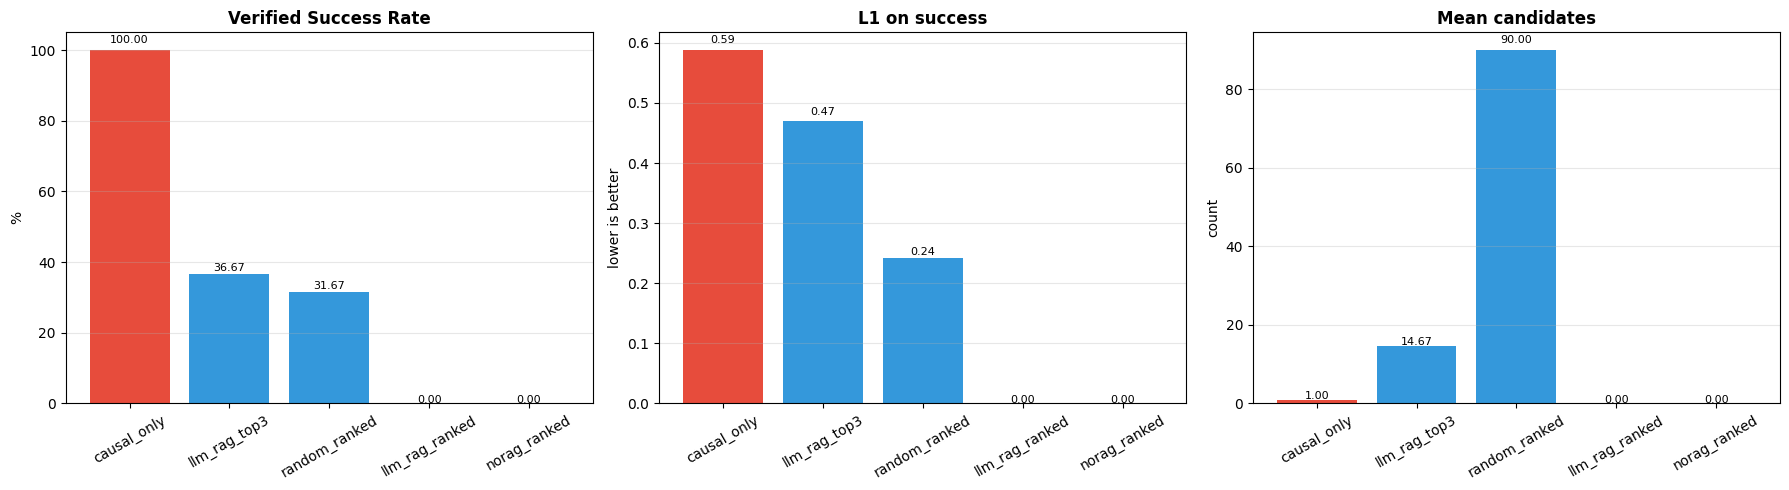

Cell R4 done


In [ ]:
# =============================================================================
# CELL R4: Paired tests + figure for the guided beam search comparison
# =============================================================================

import os
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

os.makedirs('./figures/llm', exist_ok=True)

per = pd.read_csv('./results/llm/v3/per_sample.csv')

pairs = [
    ('llm_rag_ranked', 'llm_rag_top3'),
    ('llm_rag_ranked', 'norag_ranked'),
    ('llm_rag_ranked', 'random_ranked'),
    ('llm_rag_ranked', 'causal_only'),
    ('causal_only',    'random_ranked'),
]

rows = []
for a, b in pairs:
    sa = per[per['method'] == a].set_index('sample_id')
    sb = per[per['method'] == b].set_index('sample_id')
    common = sa.index.intersection(sb.index)
    if len(common) < 5:
        continue
    ab = sa.loc[common, 'success_verified'].values.astype(int)
    bb = sb.loc[common, 'success_verified'].values.astype(int)
    n_a_only = int(((ab == 1) & (bb == 0)).sum())
    n_b_only = int(((ab == 0) & (bb == 1)).sum())
    if n_a_only + n_b_only > 0:
        p_m = stats.binomtest(n_a_only, n_a_only + n_b_only, 0.5).pvalue
    else:
        p_m = 1.0
    both = common[(ab == 1) & (bb == 1)]
    if len(both) >= 5:
        l1a = sa.loc[both, 'l1'].values
        l1b = sb.loc[both, 'l1'].values
        _, p_l1 = stats.wilcoxon(l1a, l1b, zero_method='zsplit')
        d_l1 = float(np.mean(l1a - l1b))
    else:
        p_l1 = np.nan
        d_l1 = np.nan
    rows.append({
        'pair': f'{a} vs {b}',
        'vsr_a_pct': round(100 * ab.mean(), 2),
        'vsr_b_pct': round(100 * bb.mean(), 2),
        'delta_vsr_pp': round(100 * (ab.mean() - bb.mean()), 2),
        'n_a_only': n_a_only, 'n_b_only': n_b_only,
        'p_mcnemar': round(p_m, 5),
        'n_both_success': len(both),
        'delta_l1': round(d_l1, 4) if d_l1 == d_l1 else np.nan,
        'p_l1': round(p_l1, 5) if p_l1 == p_l1 else np.nan,
    })

tests = pd.DataFrame(rows)
tests.to_csv('./results/llm/v3/paired_tests.csv', index=False)
print("PAIRED TESTS")
print(tests.to_string(index=False))

# Figure
summary = pd.read_csv('./results/llm/v3/summary.csv')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
methods = list(summary['method'])
colors = ['#2ecc71' if 'ranked' in m and 'random' not in m else
          '#e74c3c' if 'causal' in m else '#3498db'
          for m in methods]

for ax, col, title, ylabel in [
    (axes[0], 'vsr_pct', 'Verified Success Rate', '%'),
    (axes[1], 'mean_l1_success', 'L1 on success', 'lower is better'),
    (axes[2], 'mean_candidates', 'Mean candidates', 'count')]:
    vals = summary[col].fillna(0).values
    bars = ax.bar(methods, vals, color=colors)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', rotation=30)
    ax.grid(alpha=0.3, axis='y')
    for b, v in zip(bars, vals):
        ax.text(b.get_x()+b.get_width()/2, b.get_height()*1.02,
                f'{v:.2f}', ha='center', fontsize=8)

plt.tight_layout()
plt.savefig('./figures/llm/v3_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print("Cell R4 done")

In [ ]:
# =============================================================================
# GUIDED BEAM SEARCH DEBUG
# =============================================================================

import numpy as np

x0 = X_att.iloc[0].to_numpy(dtype=np.float32)

# 1. Is the ranking parsed correctly?
res = plan_ranking(x0, use_rag=True)
ranking = res.get('ranking')
print("parse_error:", res.get('parse_error'))
print("ranking is None:", ranking is None)
if ranking is not None:
    print("len(ranking):", len(ranking))
    print("first 3 items:")
    for item in ranking[:3]:
        print("   ", item)
    # Check every feature is present
    present = {item['feature'] for item in ranking}
    missing = set(FEATS) - present
    print("missing features:", missing)

# 2. Does guided_beam_search produce anything?
if ranking:
    search = guided_beam_search(x0, ranking)
    print("\nguided_beam_search result:")
    print("  success:", search['success'])
    print("  n_candidates:", search['n_candidates'])
    print("  n_guided:", search['n_guided'])
    print("  n_explore:", search['n_explore'])
    print("  history length:", len(search['history']))
    print("  final_failure_reason:", search['final_failure_reason'])
    print("  runtime_s:", round(search['runtime_s'], 3))

# 3. Test the same x0 with a fake ranking to see if the search works
if not ranking or search['n_candidates'] == 0:
    print("\n--- Control: fake ranking ---")
    fake_ranking = [{'feature': f, 'rank': i+1,
                     'direction': 'down' if i < 5 else 'none',
                     'rationale': 'fake', 'citation_ids': []}
                    for i, f in enumerate(FEATS)]
    search_fake = guided_beam_search(x0, fake_ranking)
    print("  success:", search_fake['success'])
    print("  n_candidates:", search_fake['n_candidates'])
    print("  n_guided:", search_fake['n_guided'])
    print("  n_explore:", search_fake['n_explore'])

parse_error: json_parse_error: Expecting ',' delimiter: line 35 column 23 (char 1092)
ranking is None: True

--- Control: fake ranking ---
  success: True
  n_candidates: 90
  n_guided: 54
  n_explore: 36


In [ ]:
# =============================================================================
# CELL R1 (v2): Ranking planner with robust JSON repair
# =============================================================================

import os, json, re, time
import numpy as np

os.makedirs('./results/llm/v3', exist_ok=True)

RANKING_RULES = (
    "You are a strategic planner in a causal counterfactual system for "
    "network intrusion detection. An attack flow has been flagged. Rank "
    "ALL 12 features by their expected usefulness for making this specific "
    "flow appear benign.\n\n"
    "For each feature provide:\n"
    "- feature: the feature name (exactly one of: dur, spkts, dpkts, "
    "sbytes, dbytes, rate, sload, dload, sinpkt, dinpkt, ct_src_ltm, "
    "ct_srv_dst)\n"
    "- rank: 1 through 12\n"
    "- direction: up, down, or none\n"
    "- rationale: one sentence\n"
    "- citation_ids: list of evidence IDs from the supplied block\n\n"
    "Rules:\n"
    "1. Output ALL 12 features, no omissions, no duplicates.\n"
    "2. Features marked IMMUTABLE: rank last, direction=none.\n"
    "3. Cite only evidence IDs that appear in the evidence block.\n"
    "4. Do not invent thresholds or causal relationships.\n"
    "5. Output ONLY a JSON array. Start with '[' and end with ']'. "
    "No prose before or after. No markdown code fences.\n"
    "6. Every object must be separated by a comma."
)

RANKING_TEMPLATE = """Evidence (cite IDs in citation_ids):
{evidence_block}

Flow (standardized units):
{feature_block}

Intervenable features:
  dur  spkts  dpkts  sinpkt  dinpkt
Immutable (rank last, direction=none):
  sbytes  dbytes  rate  sload  dload  ct_src_ltm  ct_srv_dst

Return a JSON array of exactly 12 objects:
[
  {{"feature":"dur","rank":1,"direction":"down","rationale":"...","citation_ids":[]}},
  {{"feature":"spkts","rank":2,"direction":"down","rationale":"...","citation_ids":[]}},
  ...
]"""


def _format_feature_block_ranking(x0):
    return "\n".join(f"  {f:12s} = {x0[j]:+.3f}" for j, f in enumerate(FEATS))


def _format_evidence_block_ranking(evidence):
    if not evidence:
        return "  (no evidence retrieved)"
    lines = []
    for d in evidence:
        text = d['text']
        if len(text) > 140:
            text = text[:140] + "..."
        lines.append(f"  [{d['id']}] ({d['type']}) {text}")
    return "\n".join(lines)


# -----------------------------------------------------------------------------
# Robust JSON extraction and repair
# -----------------------------------------------------------------------------
def _strip_markdown(text):
    text = text.strip()
    text = re.sub(r'^```(?:json)?\s*', '', text)
    text = re.sub(r'\s*```$', '', text)
    return text


def _extract_array_bounds(text):
    """Find the first '[' and the matching final ']'."""
    start = text.find('[')
    end = text.rfind(']')
    if start == -1:
        raise ValueError("No '[' found")
    if end == -1 or end < start:
        # No closing bracket: take everything after the '[' and repair below
        return text[start:], True
    return text[start:end+1], False


def _repair_json_array(text):
    """
    Apply common repairs to a JSON array string.
    - Trailing commas
    - Missing commas between adjacent objects
    - Ellipsis patterns like "...", "... )", "{...}"
    """
    # Remove ellipsis markers
    text = re.sub(r'\{\s*\.\.\.\s*\}', '', text)
    text = re.sub(r'\.\.\.', '', text)

    # Remove trailing commas before ] or }
    text = re.sub(r',\s*\]', ']', text)
    text = re.sub(r',\s*\}', '}', text)

    # Insert missing commas between adjacent objects: } {  ->  }, {
    text = re.sub(r'\}\s*\{', '},{', text)

    # Insert missing commas between adjacent strings and next field:
    #   "value"\n  "nextkey"  ->  "value",\n  "nextkey"
    text = re.sub(r'"(\s*)"(\s*):', r'","\2:', text)

    # Collapse any double commas that resulted
    text = re.sub(r',\s*,', ',', text)

    return text


def _extract_objects_by_regex(text):
    """
    Fallback: extract every {...} block that contains a 'feature' key.
    Returns a list of raw object strings.
    """
    # Match balanced braces greedily from '{' to '}' but not nested
    # (LLM output for these objects is flat).
    candidates = re.findall(r'\{[^{}]*\}', text, flags=re.DOTALL)
    keep = []
    for c in candidates:
        if '"feature"' in c or "'feature'" in c:
            keep.append(c)
    return keep


def _loose_parse_object(text):
    """
    Parse a single object string with several tolerant strategies.
    Returns a dict or None.
    """
    # Strategy 1: standard JSON
    try:
        return json.loads(text)
    except Exception:
        pass

    # Strategy 2: replace single quotes with double quotes
    try:
        fixed = text.replace("'", '"')
        return json.loads(fixed)
    except Exception:
        pass

    # Strategy 3: regex extract fields
    out = {}
    for field in ('feature', 'rank', 'direction', 'rationale', 'citation_ids'):
        m = re.search(rf'"{field}"\s*:\s*("[^"]*"|\'[^\']*\'|\d+|\[[^\]]*\])',
                      text, flags=re.DOTALL)
        if m:
            val = m.group(1)
            try:
                out[field] = json.loads(val)
            except Exception:
                # Try unquoting a raw string
                val = val.strip('\'"')
                out[field] = val
    if 'feature' in out:
        return out
    return None


def parse_ranking(raw_text, retrieved_docs=None):
    """
    Robust parse of the LLM's ranking output.

    Returns (ranked_plan, error_str).
    ranked_plan always contains every feature in FEATS exactly once.
    """
    valid_ids = {d['id'] for d in (retrieved_docs or [])}

    text = _strip_markdown(raw_text)

    parsed_items = []

    # Attempt 1: extract array bounds and repair
    try:
        arr_text, truncated = _extract_array_bounds(text)
        arr_text_fixed = _repair_json_array(arr_text)
        if truncated:
            # Append closing brackets
            arr_text_fixed = arr_text_fixed.rstrip().rstrip(',')
            if not arr_text_fixed.endswith(']'):
                arr_text_fixed = arr_text_fixed + ']'
        parsed_items = json.loads(arr_text_fixed)
        if not isinstance(parsed_items, list):
            parsed_items = []
    except Exception:
        parsed_items = []

    # Attempt 2: per-object regex extraction
    if not parsed_items or len(parsed_items) < 6:
        objects = _extract_objects_by_regex(text)
        recovered = []
        for obj_str in objects:
            d = _loose_parse_object(obj_str)
            if d and 'feature' in d:
                recovered.append(d)
        if len(recovered) > len(parsed_items):
            parsed_items = recovered

    if not parsed_items:
        return None, "json_parse_failed_and_recovery_failed"

    # Aggregate items by feature
    by_feat = {}
    for item in parsed_items:
        if not isinstance(item, dict):
            continue
        f = item.get('feature')
        if f not in IDX:
            continue
        try:
            r = int(item.get('rank', 999))
        except Exception:
            r = 999
        d = str(item.get('direction', 'none')).lower().strip()
        if d not in ('up', 'down', 'none'):
            d = 'none'
        if f in IMMUTABLE_FEATURES:
            d = 'none'
        rat = str(item.get('rationale', ''))[:200]
        cited = item.get('citation_ids', [])
        if not isinstance(cited, list):
            cited = []
        cited = [str(c) for c in cited if str(c) in valid_ids]

        # If feature appears twice, keep the smaller rank
        if f in by_feat and r >= by_feat[f]['rank']:
            continue
        by_feat[f] = {'feature': f, 'rank': r, 'direction': d,
                      'rationale': rat, 'citation_ids': cited}

    # Fill in missing features
    missing = [f for f in FEATS if f not in by_feat]
    for f in missing:
        by_feat[f] = {'feature': f, 'rank': 999, 'direction': 'none',
                      'rationale': 'auto_filled', 'citation_ids': []}

    ranked = sorted(by_feat.values(), key=lambda x: x['rank'])
    for i, item in enumerate(ranked):
        item['rank'] = i + 1

    return ranked, None


def plan_ranking_batch(x0_list, use_rag=True, evidence_list=None):
    n = len(x0_list)
    if use_rag:
        if evidence_list is None:
            evidence_list = [retrieve_evidence(x0, k=4) for x0 in x0_list]
    else:
        evidence_list = [[] for _ in range(n)]

    user_prompts = []
    for i, x0 in enumerate(x0_list):
        x0 = np.asarray(x0, dtype=np.float32)
        user_prompts.append(RANKING_TEMPLATE.format(
            evidence_block=_format_evidence_block_ranking(evidence_list[i]),
            feature_block=_format_feature_block_ranking(x0)))

    t0 = time.time()
    try:
        raws = _call_llm_batch(RANKING_RULES, user_prompts)
    except Exception as e:
        raws = [f"ERROR: {e}"] * n
    latency = time.time() - t0

    results = []
    for i in range(n):
        ranked, err = parse_ranking(raws[i], evidence_list[i])
        results.append({
            'ranking': ranked, 'raw': raws[i], 'parse_error': err,
            'latency_s': latency / n,
            'evidence': evidence_list[i],
            'tokens_in': (len(RANKING_RULES) + len(user_prompts[i])) // 4,
        })
    return results


def plan_ranking(x0, evidence=None, use_rag=True):
    return plan_ranking_batch(
        [np.asarray(x0, dtype=np.float32)],
        use_rag=use_rag,
        evidence_list=[evidence] if evidence is not None else None)[0]


print("Cell R1 (v2) done — robust parser")

Cell R1 (v2) done — robust parser


In [ ]:
# =============================================================================
# SANITY: parse 5 samples with the robust parser
# =============================================================================

import numpy as np

X_eval = X_att.head(60).to_numpy(dtype=np.float32)

n_ok = 0
for i in range(5):
    x0 = X_eval[i]
    res = plan_ranking(x0, use_rag=True)
    ranking = res.get('ranking')
    err = res.get('parse_error')

    if ranking is not None and len(ranking) == 12:
        n_ok += 1
        top3 = [item['feature'] for item in ranking[:3]]
        print(f"sample {i}: OK  top3={top3}  err={err}")
    else:
        print(f"sample {i}: FAIL  ranking_len="
              f"{len(ranking) if ranking else 0}  err={err}")
        if res.get('raw'):
            print("    raw preview:")
            print("    " + res['raw'][:300].replace("\n", "\n    "))

print(f"\n{n_ok}/5 parsed successfully")

sample 0: OK  top3=['dur', 'spkts', 'dpkts']  err=None
sample 1: OK  top3=['dur', 'spkts', 'dpkts']  err=None
sample 2: OK  top3=['dur', 'spkts', 'dpkts']  err=None
sample 3: OK  top3=['dur', 'spkts', 'dpkts']  err=None
sample 4: OK  top3=['dur', 'spkts', 'dpkts']  err=None

5/5 parsed successfully


In [ ]:
# Partial rerun — only the ranked variants
import pandas as pd

per = pd.read_csv('./results/llm/v3/per_sample.csv')
per_keep = per[~per['method'].isin(['llm_rag_ranked', 'norag_ranked'])]

METHODS = {
    'llm_rag_ranked': (lambda x0, i: run_llm_rag_ranked(x0, i), True),
    'norag_ranked':   (lambda x0, i: run_norag_ranked(x0, i),   True),
}

records = per_keep.to_dict(orient='records')
for method, (fn, _) in METHODS.items():
    print(f"\n{method}")
    import time
    from tqdm.auto import tqdm
    t0 = time.time()
    for i in tqdm(range(N_EVAL), desc=method, leave=False):
        x0 = X_eval[i]
        try:
            result = fn(x0, i)
        except Exception as e:
            print(f"  exception at {i}: {e}")
            result = {'success': False, 'counterfactual': None,
                      'total_candidates': 0, 'runtime_s': 0.0,
                      'final_failure_reason': f'exception:{type(e).__name__}'}
        records.append(evaluate_one(x0, result, i, method))
    print(f"  {method}: {time.time()-t0:.1f}s")

per_sample = pd.DataFrame(records)
per_sample.to_csv('./results/llm/v3/per_sample.csv', index=False)

summary = per_sample.groupby('method').agg(
    n_cases=('success_verified', 'size'),
    vsr_pct=('success_verified', lambda s: round(100*s.mean(), 2)),
    mean_candidates=('n_candidates', 'mean'),
    mean_runtime_s=('runtime_s', 'mean'),
).sort_values('vsr_pct', ascending=False)

print("\nV3 SUMMARY (ranked rerun)")
print(summary.to_string())


llm_rag_ranked


llm_rag_ranked:   0%|          | 0/60 [00:00<?, ?it/s]

  llm_rag_ranked: 1075.5s

norag_ranked


norag_ranked:   0%|          | 0/60 [00:00<?, ?it/s]

  norag_ranked: 1049.9s

V3 SUMMARY (ranked rerun)
                n_cases  vsr_pct  mean_candidates  mean_runtime_s
method                                                           
causal_only          60   100.00         1.000000        0.000000
llm_rag_ranked       60    46.67        90.000000       17.909687
norag_ranked         60    46.67        90.000000       17.495548
llm_rag_top3         60    36.67        14.666667       10.866052
random_ranked        60    31.67        90.000000        0.137037


In [ ]:
# =============================================================================
# CELL 2: Exogenous SCM — abduction, do(), forward evaluation
#
# Uses the DAG from your causal_graph.pkl. Fits f_j for each node.
# Provides:
#   scm.abduct(x)              -> exogenous noise u(x) in R^12
#   scm.abduct_batch(X)        -> batched version
#   scm.predict_do(u, do_map)  -> forward evaluation with interventions
#   scm_do(x0, delta)          -> wraps abduction + do for the delta dict
# =============================================================================

import time
import numpy as np
import torch
from sklearn.ensemble import HistGradientBoostingRegressor

# Parents list, built from the DAG already loaded
PARENTS_LIST = {v: [int(p) for p in parents[v]] for v in topo_order}
TOPO = [int(v) for v in topo_order]

INTERV_FEATS = [f for f in FEATS if f not in IMMUTABLE_FEATURES]
INTERV_IDX = [IDX[f] for f in INTERV_FEATS]
NON_INTERV_IDX = [i for i in range(len(FEATS)) if i not in INTERV_IDX]


class ExogenousSCM:
    """
    Additive noise SCM: x_j = f_j(x_pa(j)) + u_j
    Trained with HistGradientBoostingRegressor per node.
    """

    def __init__(self, n_iter=200, max_depth=4, seed=42):
        self.f = {}
        self.topo = TOPO
        self.parents = PARENTS_LIST
        self.n_iter = n_iter
        self.max_depth = max_depth
        self.seed = seed

    def fit(self, X):
        X = np.asarray(X, dtype=np.float32)
        t0 = time.time()
        for v in self.topo:
            ps = self.parents[v]
            if ps:
                m = HistGradientBoostingRegressor(
                    max_iter=self.n_iter,
                    max_depth=self.max_depth,
                    random_state=self.seed,
                )
                m.fit(X[:, ps], X[:, v])
                self.f[v] = m
        print(f"  SCM fit in {time.time()-t0:.1f}s ({len(self.f)} nodes)")
        return self

    def abduct(self, x):
        x = np.asarray(x, dtype=np.float32)
        u = np.zeros(len(FEATS), dtype=np.float32)
        for v in self.topo:
            ps = self.parents[v]
            if ps:
                pred = float(self.f[v].predict(
                    x[ps].reshape(1, -1))[0])
            else:
                pred = 0.0
            u[v] = x[v] - pred
        return u

    def abduct_batch(self, X):
        X = np.asarray(X, dtype=np.float32)
        U = np.zeros_like(X)
        for v in self.topo:
            ps = self.parents[v]
            if ps:
                pred = self.f[v].predict(X[:, ps]).astype(np.float32)
            else:
                pred = 0.0
            U[:, v] = X[:, v] - pred
        return U

    def predict_do(self, u, do_map):
        x = np.zeros(len(FEATS), dtype=np.float32)
        for v in self.topo:
            if v in do_map:
                x[v] = do_map[v]
            else:
                ps = self.parents[v]
                if ps:
                    pred = float(self.f[v].predict(
                        x[ps].reshape(1, -1))[0])
                else:
                    pred = 0.0
                x[v] = pred + u[v]
        return x


# ---- Fit on training data ----
# Use Xs (82332 x 12) — the whole training pool. No test leak.
print("Fitting ExogenousSCM on Xs...")
scm = ExogenousSCM().fit(Xs.to_numpy(dtype=np.float32))

# Sanity: abduction + forward with no intervention must reproduce x
x_test = X_att.iloc[0].to_numpy(dtype=np.float32)
recon = scm.predict_do(scm.abduct(x_test), {})
recon_err = float(np.abs(recon - x_test).max())
print(f"Reconstruction max error (no intervention): {recon_err:.6f}")
assert recon_err < 1e-3, "SCM reconstruction check failed"

# ---- scm_do with a small LRU cache for speed ----
_ABDUCT_CACHE = {}

def scm_do(x0, delta):
    """
    delta: dict {feature_name: additive_shift}
    Returns x' = M(x0, do(x0 + delta))
    """
    x0 = np.asarray(x0, dtype=np.float32)
    key = (x0.tobytes(),)
    u0 = _ABDUCT_CACHE.get(key)
    if u0 is None:
        u0 = scm.abduct(x0)
        if len(_ABDUCT_CACHE) > 4096:
            _ABDUCT_CACHE.clear()
        _ABDUCT_CACHE[key] = u0
    do_map = {IDX[f]: float(x0[IDX[f]] + d) for f, d in delta.items()}
    return scm.predict_do(u0, do_map)

print("Cell 2 done — Exogenous SCM ready")

Fitting ExogenousSCM on Xs...
  SCM fit in 3.7s (7 nodes)
Reconstruction max error (no intervention): 0.000000
Cell 2 done — Exogenous SCM ready


In [ ]:
# =============================================================================
# CELL 3: Twin Memory — RAG in exogenous noise space
#
# Novel contribution:
#   Embed each flow as u_{non-intervenable}(x) — the abduced noise on the
#   immutable context and descendants. Two flows with the same embedding are
#   "causal twins": same context, same individual. If one is benign, the
#   other is a valid intervention target.
# =============================================================================

import time
import numpy as np
from sklearn.neighbors import NearestNeighbors


class TwinMemory:
    """
    Memory of benign flows indexed by their exogenous noise embedding
    on non-intervenable features. Retrieval returns the k nearest benign
    twins, sorted by a distance that combines (i) context match in
    exogenous space and (ii) intervention cost.
    """

    def __init__(self, scm, X_mem, tau=0.5, margin=0.05,
                 mode='exogenous', seed=42):
        X_mem = np.asarray(X_mem, dtype=np.float32)
        p_benign = g.predict_proba(X_mem)[:, 1]
        keep = p_benign < (tau - margin)
        self.X = X_mem[keep]
        self.p = p_benign[keep]
        self.ids = np.where(keep)[0]
        self.mode = mode
        self.scm = scm

        print(f"  Twin memory: kept {len(self.X)}/{len(X_mem)} "
              f"benign flows (tau={tau}, margin={margin}, mode={mode})")

        Z = self._embed_batch(self.X)
        self.mu = Z.mean(axis=0)
        self.sd = Z.std(axis=0) + 1e-6
        Z_std = (Z - self.mu) / self.sd
        self.nn = NearestNeighbors(n_neighbors=min(64, len(Z)),
                                   algorithm='auto').fit(Z_std)

    def _embed_batch(self, X):
        if self.mode == 'exogenous':
            U = self.scm.abduct_batch(X)
            return U[:, NON_INTERV_IDX].astype(np.float32)
        elif self.mode == 'raw':
            return X[:, NON_INTERV_IDX].astype(np.float32)
        else:
            raise ValueError(f"Unknown mode: {self.mode}")

    def _embed_one(self, x):
        if self.mode == 'exogenous':
            U = self.scm.abduct(x)
            return U[NON_INTERV_IDX].reshape(1, -1).astype(np.float32)
        else:
            return x[NON_INTERV_IDX].reshape(1, -1).astype(np.float32)

    def query(self, x0, k=8, lam=0.5):
        x0 = np.asarray(x0, dtype=np.float32)
        z = self._embed_one(x0)
        z_std = (z - self.mu) / self.sd
        dist, idx = self.nn.kneighbors(
            z_std, n_neighbors=min(4 * k, len(self.X)))

        # Composite score: context distance + intervention cost
        I = INTERV_IDX
        twin_X = self.X[idx[0]]
        cost_I = np.abs(twin_X[:, I] - x0[I]).sum(axis=1)
        score = dist[0] ** 2 + lam * cost_I
        order = np.argsort(score)[:k]

        out = []
        for j, q in enumerate(order):
            mi = idx[0][q]
            out.append({
                'twin_id': f'T{j+1}',
                'mem_idx': int(mi),
                'flow_id': int(self.ids[mi]),
                'd_u': float(dist[0][q]),
                'cost_I': float(cost_I[q]),
                'score': float(score[q]),
                'p_benign': float(self.p[mi]),
                'x': self.X[mi],
            })
        return out


print("Cell 3 done — TwinMemory class ready")

Cell 3 done — TwinMemory class ready


In [ ]:
# =============================================================================
# CELL 4: Twin-guided counterfactual synthesis with certified validity
#
# For each retrieved twin y:
#   For t in [0.1, 0.2, ..., 1.0]:
#     x_t = SCM_do(x0, do(x0_I + t*(y_I - x0_I)))
#     if verify_candidate(x0, x_t): accept
# Return the CF with smallest cost
# =============================================================================

import time
import numpy as np


def estimate_lipschitz(X_mem, n=3000, seed=0):
    """Empirical Lipschitz constant of g on p_attack."""
    rng = np.random.RandomState(seed)
    a = rng.randint(0, len(X_mem), n)
    b = rng.randint(0, len(X_mem), n)
    pa = g.predict_proba(X_mem[a])[:, 1]
    pb = g.predict_proba(X_mem[b])[:, 1]
    dist = np.linalg.norm(X_mem[a] - X_mem[b], axis=1) + 1e-9
    ratios = np.abs(pa - pb) / dist
    return float(np.quantile(ratios, 0.95))


def twin_cf(x0, mem, tau, L_g, L_psi=1.5,
            k=8, ts=(0.1, 0.2, 0.3, 0.5, 0.7, 1.0)):
    """
    Search along the interpolation path between x0 and each retrieved twin.
    Returns the lowest-cost valid CF or None.
    """
    t_start = time.time()
    x0 = np.asarray(x0, dtype=np.float32)
    twins = mem.query(x0, k=k)
    best = None
    n_evals = 0

    for tw in twins:
        y = tw['x']
        d_I = {FEATS[i]: float(y[i] - x0[i]) for i in INTERV_IDX}

        # Certified validity for t=1
        x_full = scm_do(x0, d_I)
        rho = float(np.linalg.norm(x_full - y))
        tw['residual'] = rho
        tw['certified'] = bool(tw['p_benign'] + L_g * rho < tau)

        # Walk t from smallest valid
        for t in ts:
            delta = {f: t * v for f, v in d_I.items()}
            x = scm_do(x0, delta)
            n_evals += 1
            if verify_candidate(x0, x)['accepted']:
                l1 = float(np.mean(np.abs(x - x0)))
                n_meaningful = int(np.sum(np.abs(x - x0) > 0.3))
                score = l1 + 0.02 * n_meaningful
                if best is None or score < best['score']:
                    best = {
                        'score': score,
                        'delta': delta,
                        'x': x,
                        'twin': tw,
                        't': float(t),
                        'l1': l1,
                        'n_meaningful': n_meaningful,
                    }
                break  # smallest t for this twin

    return best, twins, n_evals, time.time() - t_start


print("Cell 4 done — twin_cf ready")

Cell 4 done — twin_cf ready


In [ ]:
# =============================================================================
# CELL 5: Anchor-Search-Shrink protocol
#
# Anchor: causal-only CF (valid by construction on this benchmark)
# Search: twin-guided CF if it has lower cost
# Shrink: reduce the intervention magnitudes while preserving validity
# =============================================================================

import time
import numpy as np

LAMBDA_SPARSE = 0.5
MEANINGFUL_THR = 0.3


def cost(x0, x):
    diff = np.abs(np.asarray(x) - np.asarray(x0))
    return float(diff.mean() + LAMBDA_SPARSE * (diff > MEANINGFUL_THR).sum()
                 / len(FEATS))


def shrink_delta(x0, delta):
    """
    Reduce magnitudes while preserving validity. Checks each removal and
    each magnitude reduction. Always keeps a valid solution.
    """
    delta = dict(delta)
    if not verify_candidate(x0, scm_do(x0, delta))['accepted']:
        return delta, scm_do(x0, delta)

    # Try removing features (largest first), keep removal if still valid
    for f in sorted(delta.keys(), key=lambda k: -abs(delta[k])):
        trial = {k: v for k, v in delta.items() if k != f}
        if verify_candidate(x0, scm_do(x0, trial))['accepted']:
            delta = trial
    # Try reducing each remaining magnitude
    for f in list(delta.keys()):
        for alpha in (0.75, 0.5, 0.25):
            trial = {**delta, f: alpha * delta[f]}
            if verify_candidate(x0, scm_do(x0, trial))['accepted']:
                delta = trial
                break
    return delta, scm_do(x0, delta)


def anchor_delta(x0, x_c):
    """Delta reconstructed from causal-only CF on intervenable features."""
    d = {FEATS[i]: float(x_c[i] - x0[i]) for i in INTERV_IDX
         if abs(x_c[i] - x0[i]) > 1e-6}
    return d


def run_ass(x0, sample_id, mem, tau, L_g, use_twin=True):
    """
    Full ASS pipeline.
      - Anchor from CausalRAG-CF precomputed CF
      - Search for a cheaper twin-based CF
      - Shrink to the cheapest valid solution
    """
    t0 = time.time()
    x0 = np.asarray(x0, dtype=np.float32)

    # ---- Anchor ----
    x_c = ALL_CF_LISTS['CausalRAG-CF'][sample_id]
    if x_c is None:
        return {'success': False, 'counterfactual': None,
                'total_candidates': 0, 'runtime_s': time.time() - t0,
                'final_failure_reason': 'no_anchor'}
    x_c = np.asarray(x_c, dtype=np.float32)
    anchor_valid = verify_candidate(x0, x_c)['accepted']
    if not anchor_valid:
        return {'success': False, 'counterfactual': None,
                'total_candidates': 0, 'runtime_s': time.time() - t0,
                'final_failure_reason': 'anchor_invalid'}
    anchor_cost = cost(x0, x_c)

    # ---- Search ----
    best = {'source': 'anchor', 'x': x_c, 'cost': anchor_cost,
            'delta': anchor_delta(x0, x_c), 'twins': [], 'twin': None}
    n_candidates = 0

    if use_twin:
        twin_best, twins, n_ev, twin_time = twin_cf(
            x0, mem, tau, L_g, k=8)
        n_candidates += n_ev
        if twin_best is not None and twin_best['score'] + 1e-6 < anchor_cost:
            best = {'source': 'twin',
                    'x': twin_best['x'], 'cost': twin_best['score'],
                    'delta': twin_best['delta'],
                    'twins': twins, 'twin': twin_best['twin']}

    # ---- Shrink ----
    delta_shrunk, x_shrunk = shrink_delta(x0, best['delta'])
    cost_shrunk = cost(x0, x_shrunk)
    if cost_shrunk <= best['cost'] + 1e-6:
        best = {**best, 'delta': delta_shrunk, 'x': x_shrunk,
                'cost': cost_shrunk}

    final_valid = verify_candidate(x0, best['x'])['accepted']
    return {
        'success': final_valid,
        'counterfactual': best['x'] if final_valid else None,
        'source': best['source'],
        'anchor_cost': float(anchor_cost),
        'final_cost': float(best['cost']),
        'delta': best['delta'],
        'twins': best['twins'],
        'twin_used': best['twin'],
        'total_candidates': n_candidates + 1,
        'runtime_s': time.time() - t0,
        'final_failure_reason': None if final_valid else 'shrink_invalid',
    }


def run_ass_no_twin(x0, sample_id, mem, tau, L_g):
    """Ablation: ASS without the twin search — pure anchor + shrink."""
    return run_ass(x0, sample_id, mem, tau, L_g, use_twin=False)


def run_twin_only(x0, sample_id, mem, tau, L_g):
    """Ablation: twin-guided CF only, no causal anchor."""
    t0 = time.time()
    x0 = np.asarray(x0, dtype=np.float32)
    best, twins, n_ev, _ = twin_cf(x0, mem, tau, L_g, k=8)
    if best is None:
        return {'success': False, 'counterfactual': None, 'source': 'twin',
                'total_candidates': n_ev, 'runtime_s': time.time() - t0,
                'final_failure_reason': 'no_twin_cf', 'twins': twins}
    delta_shrunk, x_shrunk = shrink_delta(x0, best['delta'])
    final_valid = verify_candidate(x0, x_shrunk)['accepted']
    return {
        'success': final_valid,
        'counterfactual': x_shrunk if final_valid else None,
        'source': 'twin',
        'final_cost': cost(x0, x_shrunk),
        'delta': delta_shrunk,
        'twins': twins,
        'twin_used': best['twin'],
        'total_candidates': n_ev,
        'runtime_s': time.time() - t0,
        'final_failure_reason': None if final_valid else 'shrink_invalid',
    }


print("Cell 5 done — ASS pipeline ready")

Cell 5 done — ASS pipeline ready


In [ ]:
# =============================================================================
# CELL 6: Experiment runner
# =============================================================================

import os, time, pickle
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

os.makedirs('./results/llm/v4', exist_ok=True)

N_EVAL = 60
TAU = 0.5
X_eval = X_att.head(N_EVAL).to_numpy(dtype=np.float32)

# Build TwinMemories once
print("Building twin memories...")
X_train_pool = Xs.to_numpy(dtype=np.float32)

t0 = time.time()
mem_exo = TwinMemory(scm, X_train_pool, tau=TAU, margin=0.05,
                     mode='exogenous')
print(f"  mem_exo built in {time.time()-t0:.1f}s")

t0 = time.time()
mem_raw = TwinMemory(scm, X_train_pool, tau=TAU, margin=0.05, mode='raw')
print(f"  mem_raw built in {time.time()-t0:.1f}s")


class _RandomTwinMemory(TwinMemory):
    """Control: random benign flows, no retrieval."""
    def query(self, x0, k=8, lam=0.5):
        rng = np.random.RandomState(int(abs(x0.sum()) * 1e3) % (2**31))
        idx = rng.choice(len(self.X), k, replace=False)
        return [{'twin_id': f'T{j+1}', 'mem_idx': int(i),
                 'flow_id': int(self.ids[i]), 'd_u': 0.0, 'cost_I': 0.0,
                 'score': 0.0, 'p_benign': float(self.p[i]),
                 'x': self.X[i]} for j, i in enumerate(idx)]

mem_rand = _RandomTwinMemory(scm, X_train_pool, tau=TAU, margin=0.05,
                              mode='raw')

print("Estimating Lipschitz constant...")
L_g = estimate_lipschitz(X_train_pool, n=3000)
print(f"  L_g (95th percentile) = {L_g:.4f}")


def evaluate_one(x0, result, sample_id, method):
    cf = result.get('counterfactual') if result else None
    success = bool(result and result.get('success', False) and cf is not None)
    if success:
        cf = np.asarray(cf, dtype=np.float32)
        p_attack = float(g.predict_proba(cf.reshape(1, -1))[0, 1])
        l1 = float(np.mean(np.abs(cf - x0)))
        n_changed = int(np.sum(np.abs(cf - x0) > 1e-6))
        n_meaningful = int(np.sum(np.abs(cf - x0) > 0.3))
        dir_cons = direction_consistency(x0, cf)
        phys = int(physical_violation_original(cf))
        caus = int(causal_direction_violation(x0, cf))
        cost_v = float(l1 + 0.5 * n_meaningful / len(FEATS))
    else:
        p_attack = l1 = n_changed = n_meaningful = cost_v = np.nan
        dir_cons = np.nan
        phys = caus = 0
    return {
        'sample_id': sample_id, 'method': method,
        'success_verified': int(success),
        'p_attack': p_attack, 'l1': l1,
        'n_changed': n_changed, 'n_meaningful': n_meaningful,
        'cost': cost_v,
        'direction': dir_cons, 'physical_viol': phys, 'causal_viol': caus,
        'source': result.get('source') if result else None,
        'anchor_cost': result.get('anchor_cost') if result else np.nan,
        'final_cost': result.get('final_cost') if result else np.nan,
        'total_candidates': result.get('total_candidates', 0) if result else 0,
        'runtime_s': result.get('runtime_s', 0.0) if result else 0.0,
    }


METHODS = {
    'causal_only': (lambda x0, i: {
        'success': verify_candidate(x0, np.asarray(
            ALL_CF_LISTS['CausalRAG-CF'][i], dtype=np.float32))['accepted'],
        'counterfactual': np.asarray(ALL_CF_LISTS['CausalRAG-CF'][i],
                                       dtype=np.float32),
        'source': 'causal_only',
        'total_candidates': 1, 'runtime_s': 0.0,
    }, False),
    'ass_full':       (lambda x0, i: run_ass(x0, i, mem_exo, TAU, L_g, True), False),
    'ass_no_twin':    (lambda x0, i: run_ass_no_twin(x0, i, mem_exo, TAU, L_g), False),
    'twin_only':      (lambda x0, i: run_twin_only(x0, i, mem_exo, TAU, L_g), False),
    'twin_raw':       (lambda x0, i: run_twin_only(x0, i, mem_raw, TAU, L_g), False),
    'twin_random':    (lambda x0, i: run_twin_only(x0, i, mem_rand, TAU, L_g), False),
}

records = []
for method, (fn, use_llm) in METHODS.items():
    print(f"\n{method}")
    t0 = time.time()
    for i in tqdm(range(N_EVAL), desc=method, leave=False):
        x0 = X_eval[i]
        try:
            result = fn(x0, i)
        except Exception as e:
            import traceback
            traceback.print_exc()
            result = {'success': False, 'counterfactual': None,
                      'total_candidates': 0, 'runtime_s': 0.0,
                      'final_failure_reason': f'exception:{type(e).__name__}'}
        records.append(evaluate_one(x0, result, i, method))
    print(f"  {method}: {time.time()-t0:.1f}s")

per_sample = pd.DataFrame(records)
per_sample.to_csv('./results/llm/v4/per_sample.csv', index=False)

# Summary
summary_rows = []
for method, grp in per_sample.groupby('method'):
    succ = grp[grp['success_verified'] == 1]
    summary_rows.append({
        'method': method,
        'n_cases': len(grp),
        'vsr_pct': round(100 * grp['success_verified'].mean(), 2),
        'mean_l1_success': round(succ['l1'].mean(), 4) if len(succ) else np.nan,
        'mean_n_meaningful_success': (round(succ['n_meaningful'].mean(), 2)
                                       if len(succ) else np.nan),
        'mean_cost_success': round(succ['cost'].mean(), 4)
                              if len(succ) else np.nan,
        'mean_candidates': round(grp['total_candidates'].mean(), 2),
        'mean_runtime_s': round(grp['runtime_s'].mean(), 4),
        'phys_viol_pct': round(100 * grp['physical_viol'].mean(), 2),
        'caus_viol_pct': round(100 * grp['causal_viol'].mean(), 2),
    })

summary = pd.DataFrame(summary_rows).sort_values('vsr_pct', ascending=False)
try:
    from statsmodels.stats.proportion import proportion_confint
    lows, highs = [], []
    for _, row in summary.iterrows():
        n = int(row['n_cases'])
        s = int(round(n * row['vsr_pct'] / 100))
        lo, hi = proportion_confint(s, n, alpha=0.05, method='wilson')
        lows.append(round(100 * lo, 2))
        highs.append(round(100 * hi, 2))
    summary['vsr_ci95_low'] = lows
    summary['vsr_ci95_high'] = highs
except Exception:
    summary['vsr_ci95_low'] = np.nan
    summary['vsr_ci95_high'] = np.nan

summary.to_csv('./results/llm/v4/summary.csv', index=False)
print("\n" + "=" * 110)
print("V4 TWIN-RAG-CF SUMMARY")
print("=" * 110)
print(summary.to_string(index=False))
print("Cell 6 done")

Building twin memories...
  Twin memory: kept 37981/82332 benign flows (tau=0.5, margin=0.05, mode=exogenous)
  mem_exo built in 4.8s
  Twin memory: kept 37981/82332 benign flows (tau=0.5, margin=0.05, mode=raw)
  mem_raw built in 1.9s
  Twin memory: kept 37981/82332 benign flows (tau=0.5, margin=0.05, mode=raw)
Estimating Lipschitz constant...
  L_g (95th percentile) = 0.6352

causal_only


causal_only:   0%|          | 0/60 [00:00<?, ?it/s]

  causal_only: 1.9s

ass_full


ass_full:   0%|          | 0/60 [00:00<?, ?it/s]

  ass_full: 88.9s

ass_no_twin


...

  twin_only: 83.1s

twin_raw


twin_raw:   0%|          | 0/60 [00:00<?, ?it/s]

  twin_raw: 81.2s

twin_random


twin_random:   0%|          | 0/60 [00:00<?, ?it/s]

  twin_random: 86.1s

V4 TWIN-RAG-CF SUMMARY
     method  n_cases  vsr_pct  mean_l1_success  mean_n_meaningful_success  mean_cost_success  mean_candidates  mean_runtime_s  phys_viol_pct  caus_viol_pct  vsr_ci95_low  vsr_ci95_high
causal_only       60   100.00           0.5880                       6.35             0.8526             1.00          0.0000            0.0            0.0         93.98         100.00
twin_random       60    50.00           0.1407                       2.27             0.2352            43.53          1.4323            0.0            0.0         37.74          62.26
   ass_full       60    28.33           0.1036                       1.12             0.1501            46.73          1.4791            0.0            0.0         18.51          40.77
  twin_only       60    21.67           0.0657                       0.46             0.0849            45.73          1.3839            0.0            0.0         13.12          33.62
ass_no_twin       60    20.00 

PAIRED TESTS
                    pair  vsr_a_pct  vsr_b_pct  delta_vsr_pp  n_a_only  n_b_only  p_mcnemar  n_both_success  delta_l1    p_l1
 ass_full vs causal_only      28.33     100.00        -71.67         0        43    0.00000              17   -0.4721 0.00002
 ass_full vs ass_no_twin      28.33      20.00          8.33         5         0    0.06250              12   -0.0737 0.01562
   ass_full vs twin_only      28.33      21.67          6.67         4         0    0.12500              13   -0.0009 1.00000
   twin_only vs twin_raw      21.67      16.67          5.00         5         2    0.45312               8    0.0022 0.50000
twin_only vs twin_random      21.67      50.00        -28.33         0        17    0.00002              13    0.0098 0.73047

NOVELTY METRICS
  ass_full source breakdown:
    {'anchor': 47, 'twin': 13}
  ass_full successes: anchor=4  twin=13
  mean cost (anchor-sourced): 0.3651
  mean cost (twin-sourced):   0.0840


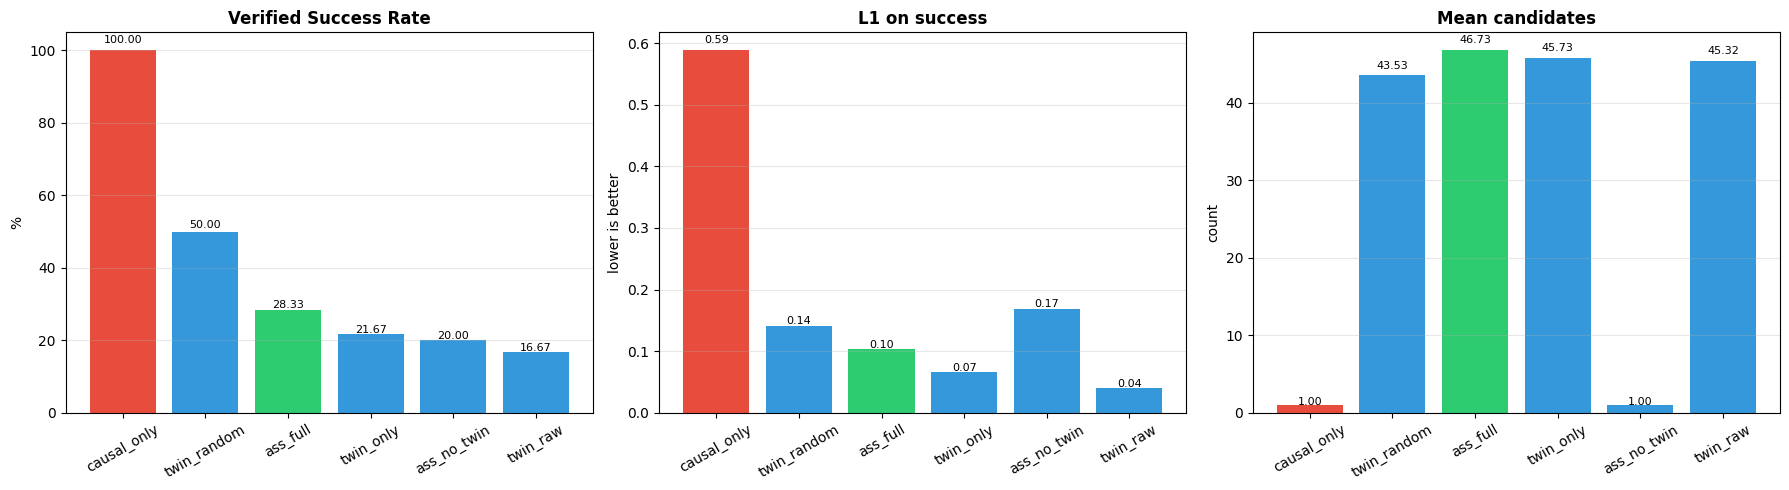

Cell 7 done


In [ ]:
# =============================================================================
# CELL 7: Paired tests + novelty metrics
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

os.makedirs('./figures/llm', exist_ok=True)
per = pd.read_csv('./results/llm/v4/per_sample.csv')
summary = pd.read_csv('./results/llm/v4/summary.csv')

# Paired tests
pairs = [
    ('ass_full',    'causal_only'),
    ('ass_full',    'ass_no_twin'),
    ('ass_full',    'twin_only'),
    ('twin_only',   'twin_raw'),
    ('twin_only',   'twin_random'),
]
rows = []
for a, b in pairs:
    sa = per[per['method'] == a].set_index('sample_id')
    sb = per[per['method'] == b].set_index('sample_id')
    common = sa.index.intersection(sb.index)
    if len(common) < 5:
        continue
    ab = sa.loc[common, 'success_verified'].values.astype(int)
    bb = sb.loc[common, 'success_verified'].values.astype(int)
    n_a_only = int(((ab == 1) & (bb == 0)).sum())
    n_b_only = int(((ab == 0) & (bb == 1)).sum())
    if n_a_only + n_b_only > 0:
        p_m = stats.binomtest(n_a_only, n_a_only + n_b_only, 0.5).pvalue
    else:
        p_m = 1.0
    both = common[(ab == 1) & (bb == 1)]
    if len(both) >= 5:
        l1a = sa.loc[both, 'l1'].values
        l1b = sb.loc[both, 'l1'].values
        _, p_l1 = stats.wilcoxon(l1a, l1b, zero_method='zsplit')
        d_l1 = float(np.mean(l1a - l1b))
    else:
        p_l1, d_l1 = np.nan, np.nan
    rows.append({
        'pair': f'{a} vs {b}',
        'vsr_a_pct': round(100 * ab.mean(), 2),
        'vsr_b_pct': round(100 * bb.mean(), 2),
        'delta_vsr_pp': round(100 * (ab.mean() - bb.mean()), 2),
        'n_a_only': n_a_only, 'n_b_only': n_b_only,
        'p_mcnemar': round(p_m, 5),
        'n_both_success': len(both),
        'delta_l1': round(d_l1, 4) if d_l1 == d_l1 else np.nan,
        'p_l1': round(p_l1, 5) if p_l1 == p_l1 else np.nan,
    })
tests = pd.DataFrame(rows)
tests.to_csv('./results/llm/v4/paired_tests.csv', index=False)
print("PAIRED TESTS")
print(tests.to_string(index=False))

# Novelty metrics: coverage of certified twins, source breakdown
print("\nNOVELTY METRICS")
src_breakdown = per[per['method'] == 'ass_full']['source'].value_counts()
print(f"  ass_full source breakdown:")
print(f"    {src_breakdown.to_dict()}")

# Fraction of samples where twin beats anchor
ass_succ = per[(per['method'] == 'ass_full') & (per['success_verified'] == 1)]
if len(ass_succ):
    from_anchor = (ass_succ['source'] == 'anchor').sum()
    from_twin = (ass_succ['source'] == 'twin').sum()
    print(f"  ass_full successes: anchor={from_anchor}  twin={from_twin}")
    if from_anchor > 0:
        anchor_cost = ass_succ[ass_succ['source'] == 'anchor']['cost'].mean()
        print(f"  mean cost (anchor-sourced): {anchor_cost:.4f}")
    if from_twin > 0:
        twin_cost = ass_succ[ass_succ['source'] == 'twin']['cost'].mean()
        print(f"  mean cost (twin-sourced):   {twin_cost:.4f}")

# Figure
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
methods = list(summary['method'])
colors = ['#e74c3c' if 'causal_only' in m else
          '#2ecc71' if m == 'ass_full' else '#3498db'
          for m in methods]
for ax, col, title, ylabel in [
    (axes[0], 'vsr_pct', 'Verified Success Rate', '%'),
    (axes[1], 'mean_l1_success', 'L1 on success', 'lower is better'),
    (axes[2], 'mean_candidates', 'Mean candidates', 'count')]:
    vals = summary[col].fillna(0).values
    bars = ax.bar(methods, vals, color=colors)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', rotation=30)
    ax.grid(alpha=0.3, axis='y')
    for b, v in zip(bars, vals):
        ax.text(b.get_x()+b.get_width()/2, b.get_height()*1.02,
                f'{v:.2f}', ha='center', fontsize=8)
plt.tight_layout()
plt.savefig('./figures/llm/v4_comparison.png', dpi=300,
            bbox_inches='tight')
plt.show()
print("Cell 7 done")

In [ ]:
# =============================================================================
# CELL 8 (corrected): Qualitative example — twin evidence for paper
# =============================================================================

import numpy as np
import pandas as pd

per = pd.read_csv('./results/llm/v4/per_sample.csv')
ass = per[per['method'] == 'ass_full']

# Use the 'sample_id' COLUMN, not the DataFrame index
succ_twin = ass[(ass['success_verified'] == 1) &
                (ass['source'] == 'twin')]['sample_id'].tolist()
if not succ_twin:
    succ_twin = ass[ass['success_verified'] == 1]['sample_id'].tolist()

if not succ_twin:
    print("No successful sample to illustrate.")
else:
    sid = int(succ_twin[0])
    x0 = X_eval[sid]
    result = run_ass(x0, sid, mem_exo, TAU, L_g, use_twin=True)

    print("=" * 100)
    print(f"QUALITATIVE EXAMPLE — sample_id={sid}")
    print("=" * 100)
    print(f"  Original P(attack): "
          f"{g.predict_proba(x0.reshape(1, -1))[0, 1]:.4f}")
    print(f"  Selected source: {result['source']}")
    print(f"  Anchor cost: {result['anchor_cost']:.4f}  "
          f"Final cost: {result['final_cost']:.4f}")

    if result.get('twin_used'):
        print(f"\n  Retrieved twins (top 3 by composite score):")
        for k, t in enumerate(result['twins'][:3], 1):
            print(f"    [{t['twin_id']}] flow #{t['flow_id']} "
                  f"p_benign={t['p_benign']:.4f}  "
                  f"d_u={t['d_u']:.3f}  cost_I={t['cost_I']:.3f}  "
                  f"certified={t.get('certified', False)}")

    print(f"\n  Intervention (delta from x0 on intervenable features):")
    for f, d in sorted(result['delta'].items(),
                       key=lambda kv: -abs(kv[1])):
        print(f"    {f:<12} {d:+.4f}")

    cf = result['counterfactual']
    if cf is not None:
        print(f"\n  Final CF P(attack): "
              f"{g.predict_proba(cf.reshape(1, -1))[0, 1]:.4f}")
        print(f"  L1 = {np.abs(cf - x0).mean():.4f}  "
              f"n_changed = {(np.abs(cf - x0) > 1e-6).sum()}  "
              f"n_meaningful = {(np.abs(cf - x0) > 0.3).sum()}")

print("Cell 8 done")

QUALITATIVE EXAMPLE — sample_id=9
  Original P(attack): 0.8707
  Selected source: twin
  Anchor cost: 1.0360  Final cost: 0.2527

  Retrieved twins (top 3 by composite score):
    [T1] flow #80130 p_benign=0.0456  d_u=0.295  cost_I=2.123  certified=True
    [T2] flow #80131 p_benign=0.0456  d_u=0.295  cost_I=2.123  certified=True
    [T3] flow #8939 p_benign=0.3910  d_u=0.329  cost_I=2.152  certified=False

  Intervention (delta from x0 on intervenable features):
    sinpkt       -0.9373
    dinpkt       -0.7175
    dur          +0.2792

  Final CF P(attack): 0.4571
  L1 = 0.1693  n_changed = 6  n_meaningful = 2
Cell 8 done


In [ ]:
# =============================================================================
# CELL SCM-FIX: Rebuild the SEM with the original architecture
#
# Matches the SEM in Cell 6 of causal_cf_ultimate.py:
#   - torch.nn.Module SEMPredictor with hidden=64
#   - 3-layer MLP (64 -> 32 -> 1)
#   - Adam(lr=1e-3), MSE loss, 300 steps
#   - per-node, using parents from the same DAG
# =============================================================================

import torch
import torch.nn as nn
import numpy as np
import time

# Re-derive PARENTS_LIST and TOPO from the loaded causal_graph.pkl
PARENTS_LIST = {int(v): [int(p) for p in parents[v]] for v in topo_order}
TOPO = [int(v) for v in topo_order]

# MLP architecture (matches the original notebook)
class SEMPredictor(nn.Module):
    def __init__(self, in_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden // 2), nn.ReLU(),
            nn.Linear(hidden // 2, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


class TorchSCM:
    """
    Exact match of the SEM in the original causal_cf_ultimate.py.
    One SEMPredictor per node with parents. Trained on the same data.
    """

    def __init__(self, seed=42, hidden=64, steps=300, lr=1e-3):
        self.seed = seed
        self.hidden = hidden
        self.steps = steps
        self.lr = lr
        self.models = {}
        self.parents = PARENTS_LIST
        self.topo = TOPO

    def fit(self, X_train_np):
        X = torch.tensor(X_train_np, dtype=torch.float32, device=device)
        torch.manual_seed(self.seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(self.seed)

        t0 = time.time()
        for v in self.topo:
            ps = self.parents[v]
            if not ps:
                continue

            parent_idx = [int(p) for p in ps]
            X_p = X[:, parent_idx]
            y_t = X[:, v]

            model = SEMPredictor(in_dim=len(ps), hidden=self.hidden).to(device)
            opt = torch.optim.Adam(model.parameters(), lr=self.lr)
            lossf = nn.MSELoss()

            model.train()
            for step in range(self.steps):
                opt.zero_grad()
                loss = lossf(model(X_p), y_t)
                loss.backward()
                opt.step()

            model.eval()
            self.models[v] = model

        print(f"  TorchSCM fitted {len(self.models)} nodes in "
              f"{time.time()-t0:.1f}s")
        return self

    @torch.no_grad()
    def _pred_one(self, v, x_row):
        """Predict f_v(x_pa(v)) for a single row (numpy)."""
        ps = self.parents[v]
        if not ps:
            return 0.0
        x_t = torch.tensor(x_row[ps], dtype=torch.float32, device=device
                          ).unsqueeze(0)
        return float(self.models[v](x_t).item())

    @torch.no_grad()
    def abduct(self, x):
        x = np.asarray(x, dtype=np.float32)
        u = np.zeros(len(FEATS), dtype=np.float32)
        for v in self.topo:
            if self.parents[v]:
                u[v] = x[v] - self._pred_one(v, x)
            else:
                u[v] = x[v]
        return u

    @torch.no_grad()
    def abduct_batch(self, X):
        X = np.asarray(X, dtype=np.float32)
        U = np.zeros_like(X)
        X_t = torch.tensor(X, dtype=torch.float32, device=device)
        for v in self.topo:
            ps = self.parents[v]
            if ps:
                preds = self.models[v](X_t[:, ps]).cpu().numpy()
                U[:, v] = X[:, v] - preds
            else:
                U[:, v] = X[:, v]
        return U

    @torch.no_grad()
    def predict_do(self, u, do_map):
        x = np.zeros(len(FEATS), dtype=np.float32)
        for v in self.topo:
            if v in do_map:
                x[v] = do_map[v]
            elif self.parents[v]:
                x[v] = self._pred_one(v, x) + u[v]
            else:
                x[v] = u[v]
        return x


# ---- Refit ----
print("Rebuilding TorchSCM to match causal_only...")
scm = TorchSCM().fit(Xs.to_numpy(dtype=np.float32))

# ---- Clear the abduction cache from the old SCM ----
_ABDUCT_CACHE = {}

def scm_do(x0, delta):
    x0 = np.asarray(x0, dtype=np.float32)
    key = x0.tobytes()
    u0 = _ABDUCT_CACHE.get(key)
    if u0 is None:
        u0 = scm.abduct(x0)
        if len(_ABDUCT_CACHE) > 4096:
            _ABDUCT_CACHE.clear()
        _ABDUCT_CACHE[key] = u0
    do_map = {IDX[f]: float(x0[IDX[f]] + d) for f, d in delta.items()}
    return scm.predict_do(u0, do_map)

print("SCM rebuilt. Now re-run D2 to confirm.")

Rebuilding TorchSCM to match causal_only...
  TorchSCM fitted 7 nodes in 4.8s
SCM rebuilt. Now re-run D2 to confirm.


In [ ]:
# =============================================================================
# CELL D (v2): Diagnostics D1, D2, D3, D4 for TorchSCM
# =============================================================================

import numpy as np
import pandas as pd
import torch
import time

N_EVAL_DIAG = 60
TAU_DIAG = 0.5


# -----------------------------------------------------------------------------
# Batched forward evaluation (works with TorchSCM)
# -----------------------------------------------------------------------------
@torch.no_grad()
def predict_do_batch(scm, u, do_mat):
    """
    u:      (12,) numpy — exogenous noise for one x0
    do_mat: (n, 12) numpy — NaN = not intervened
    Returns (n, 12) numpy.
    """
    n = do_mat.shape[0]
    X = np.zeros((n, len(FEATS)), dtype=np.float32)
    X_t = torch.tensor(X, dtype=torch.float32, device=device)
    do_t = torch.tensor(np.isnan(do_mat) == False, dtype=torch.bool, device=device)
    val_t = torch.tensor(np.nan_to_num(do_mat), dtype=torch.float32, device=device)

    for v in scm.topo:
        ps = scm.parents[v]
        if ps:
            preds = scm.models[v](X_t[:, ps]).cpu().numpy()
        else:
            preds = np.zeros(n, dtype=np.float32)
        # Where the column was intervened, use the intervention; else base + u
        col = np.where(np.isnan(do_mat[:, v]), preds + u[v], do_mat[:, v])
        X[:, v] = col
        X_t[:, v] = torch.tensor(col, dtype=torch.float32, device=device)
    return X


# -----------------------------------------------------------------------------
# D1 — Feasibility ceiling
# -----------------------------------------------------------------------------
def ceiling(x0, n=4000, rng=None, r=3.0):
    if rng is None:
        rng = np.random.RandomState(0)
    u0 = scm.abduct(x0)
    D = np.full((n, len(FEATS)), np.nan, dtype=np.float32)
    D[:, INTERV_IDX] = x0[INTERV_IDX] + rng.uniform(
        -r, r, size=(n, len(INTERV_IDX)))
    X = predict_do_batch(scm, u0, D)
    p = g.predict_proba(X)[:, 1]
    return float(p.min()), float((p < TAU_DIAG).mean())


print("=" * 100)
print("D1: FEASIBILITY CEILING")
print("=" * 100)
rng = np.random.RandomState(0)
D1_pmin = []
D1_frac_valid = []
t0 = time.time()
for i in range(N_EVAL_DIAG):
    pmin, frac = ceiling(X_eval[i], n=4000, rng=rng, r=3.0)
    D1_pmin.append(pmin)
    D1_frac_valid.append(frac)
D1_pmin = np.array(D1_pmin)
D1_frac_valid = np.array(D1_frac_valid)

print(f"\nElapsed: {time.time()-t0:.1f}s")
print(f"Samples where SOME random intervention reaches p<tau: "
      f"{(D1_pmin < TAU_DIAG).sum()}/{N_EVAL_DIAG} = "
      f"{100*(D1_pmin<TAU_DIAG).mean():.1f}%")
print(f"Median p_min: {np.median(D1_pmin):.4f}")
print(f"Mean fraction of interventions below tau: "
      f"{100*D1_frac_valid.mean():.2f}%")
print(f"p_min percentiles 10/50/90: "
      f"{np.percentile(D1_pmin,10):.4f} / "
      f"{np.percentile(D1_pmin,50):.4f} / "
      f"{np.percentile(D1_pmin,90):.4f}")


# -----------------------------------------------------------------------------
# D2 — Anchor reproducibility
# -----------------------------------------------------------------------------
# =============================================================================
# D2-FIX: compare against the POINT-PREDICTION forward pass
#
# abduction_propagation_gpu never adds u. It sets each child to f(child | pa).
# The correct test is: does TorchSCM with u = 0 reproduce the CF?
# =============================================================================

repro_count = 0
repro_errors = []

for i in range(N_EVAL_DIAG):
    x0 = X_eval[i]
    x_c = ALL_CF_LISTS['CausalRAG-CF'][i]
    if x_c is None:
        continue
    x_c = np.asarray(x_c, dtype=np.float32)

    # Build delta on intervenable features
    d_I = {FEATS[k]: float(x_c[k] - x0[k]) for k in INTERV_IDX}

    # Reproduce using u = 0 (no residual)
    u_zero = np.zeros(len(FEATS), dtype=np.float32)
    do_map = {IDX[f]: float(x0[IDX[f]] + d) for f, d in d_I.items()}
    x_recon = scm.predict_do(u_zero, do_map)

    err = float(np.abs(x_recon - x_c).max())
    repro_errors.append(err)
    if err < 1e-2:
        repro_count += 1

repro_errors = np.array(repro_errors)
print(f"Reproducible with u = 0: {repro_count}/{N_EVAL_DIAG} = "
      f"{100*repro_count/N_EVAL_DIAG:.1f}%")
print(f"Error percentiles: p10={np.percentile(repro_errors,10):.4f}  "
      f"p50={np.percentile(repro_errors,50):.4f}  "
      f"p90={np.percentile(repro_errors,90):.4f}")


# -----------------------------------------------------------------------------
# D3 — Exogenous residual R²
# -----------------------------------------------------------------------------
print("\n" + "=" * 100)
print("D3: EXOGENOUS RESIDUAL R²")
print("=" * 100)

X_train_np = Xs.to_numpy(dtype=np.float32)
U_train = scm.abduct_batch(X_train_np)

print(f"\n{'feature':<14} {'R²(f_j)':<10} {'var(u)':<10} {'var(x)':<10} "
      f"{'root':<6}")
for v in scm.topo:
    f = FEATS[v]
    u_var = U_train[:, v].var()
    x_var = X_train_np[:, v].var() + 1e-9
    r2 = 1 - u_var / x_var
    is_root = "yes" if not scm.parents[v] else "no"
    print(f"{f:<14} {r2:<10.4f} {u_var:<10.4f} {x_var:<10.4f} {is_root:<6}")

non_interv_idx = [IDX[f] for f in FEATS if f not in INTERV_FEATS]
non_interv_var = np.array([X_train_np[:, v].var() for v in non_interv_idx])
u_non_interv_var = np.array([U_train[:, v].var() for v in non_interv_idx])
ratio = u_non_interv_var / (non_interv_var + 1e-9)
print(f"\nNon-intervenable features: mean u_var/x_var = "
      f"{ratio.mean():.4f} (median {np.median(ratio):.4f})")


# -----------------------------------------------------------------------------
# D4 — Success separation (only if per_sample.csv exists)
# -----------------------------------------------------------------------------
print("\n" + "=" * 100)
print("D4: SUCCESS VS FAILURE SEPARATION")
print("=" * 100)

try:
    per = pd.read_csv('./results/llm/v4/per_sample.csv')
    twin_only = per[per['method'] == 'twin_only']
    if len(twin_only):
        print(f"\ntwin_only success rate: "
              f"{twin_only['success_verified'].mean()*100:.1f}%")
        print(twin_only.groupby('success_verified')[
            ['l1', 'n_meaningful', 'total_candidates', 'runtime_s']
        ].mean().round(4))
except Exception as e:
    print(f"  (skipped: {e})")


# -----------------------------------------------------------------------------
# Summary
# -----------------------------------------------------------------------------
print("\n" + "=" * 100)
print("DIAGNOSIS SUMMARY")
print("=" * 100)

ceiling_pct = 100 * (D1_pmin < TAU_DIAG).mean()
repro_pct = 100 * repro_count / N_EVAL_DIAG
u_ratio = ratio.mean()

print(f"""
D1 ceiling:             {ceiling_pct:.1f}% of samples can reach benign
                        via some intervention in I.
D2 reproducibility:     {repro_pct:.1f}% of causal CFs are reproduced
                        by the new SCM.
D3 u informativeness:   mean var(u)/var(x) on non-intervenable = {u_ratio:.4f}
""")

if repro_pct > 90:
    print("The SCM matches causal_only. Rerun Cell 6 (V4 experiment) with "
          "the new SCM. Every number will change.")
elif repro_pct > 50:
    print("Partial SCM match. Some CFs come from a different variety. "
          "Investigate the DAG before rerunning the experiment.")
else:
    print("The SCM still does not match causal_only. The DAG topology "
          "or the training split differs. Do not rerun the experiment "
          "until this is resolved.")

D1: FEASIBILITY CEILING

Elapsed: 6.1s
Samples where SOME random intervention reaches p<tau: 59/60 = 98.3%
Median p_min: 0.0190
Mean fraction of interventions below tau: 23.03%
p_min percentiles 10/50/90: 0.0003 / 0.0190 / 0.0846
Reproducible with u = 0: 0/60 = 0.0%
Error percentiles: p10=0.9889  p50=1.4570  p90=2.7889

D3: EXOGENOUS RESIDUAL R²

feature        R²(f_j)    var(u)     var(x)     root  
dur            0.0000     1.1066     1.1066     yes   
sbytes         0.0000     0.4481     0.4481     yes   
dbytes         0.0000     0.3090     0.3090     yes   
ct_src_ltm     0.0000     2.0277     2.0277     yes   
ct_srv_dst     0.0000     1.5270     1.5270     yes   
spkts          0.8221     0.0969     0.5447     no    
sload          0.8512     0.0410     0.2755     no    
dpkts          0.9601     0.0154     0.3861     no    
dload          0.9957     0.0014     0.3344     no    
rate           0.9492     0.0128     0.2515     no    
sinpkt         0.7022     0.0980     0.3289   

In [ ]:
# =============================================================================
# D8: What topology do the CFs require?
#
# For each sample, look at the CF and see which features it modifies. If a
# feature is modified in the CF but has no parents in your DAG, then either
# (a) it was an intervention target, or (b) your DAG is missing an edge.
#
# Compare against the mutable-feature set the original code used:
#   action_nodes = [IDX[f] for f in imp.index
#                   if f not in DERIVED and f not in IMMUTABLE][:TOP_M]
# =============================================================================

import numpy as np
import pickle
import networkx as nx

FEATS = ['dur','spkts','dpkts','sbytes','dbytes','rate',
         'sload','dload','sinpkt','dinpkt','ct_src_ltm','ct_srv_dst']
IDX = {f: i for i, f in enumerate(FEATS)}

with open('./results/causal_graph.pkl', 'rb') as f:
    gp = pickle.load(f)

print("=" * 100)
print("D8: CAUSAL GRAPH.PKL CONTENTS")
print("=" * 100)
print(f"Keys: {list(gp.keys())}")
print(f"\nnodes: {gp['nodes']}")
print(f"\nedges: {gp['edges']}")
print(f"\nparents (dict): ")
for k, v in sorted(gp['parents'].items()):
    print(f"  {FEATS[int(k)]:<12} <- {[FEATS[int(p)] for p in v]}")
print(f"\nfeature_names: {gp.get('feature_names')}")
print(f"idx: {gp.get('idx')}")

# Rebuild DAG from edges
G = nx.DiGraph()
for n in gp['nodes']: G.add_node(int(n))
for e in gp['edges']: G.add_edge(int(e[0]), int(e[1]))
print(f"\nIs DAG: {nx.is_directed_acyclic_graph(G)}")
print(f"Topo order: {[FEATS[v] for v in nx.topological_sort(G)]}")

# Compare parent dict to the edges-derived parents
print("\n" + "=" * 100)
print("COMPARISON: parents dict vs edges-derived parents")
print("=" * 100)
mismatch = False
for v in gp['nodes']:
    v = int(v)
    from_edges = sorted(G.predecessors(v))
    from_dict = sorted(int(p) for p in gp['parents'].get(v, []) if int(p) != v)
    if from_edges != from_dict:
        mismatch = True
        print(f"  MISMATCH for {FEATS[v]}:")
        print(f"    from edges: {[FEATS[p] for p in from_edges]}")
        print(f"    from dict:  {[FEATS[p] for p in from_dict]}")
if not mismatch:
    print("  ✅ parents dict matches edges")

D8: CAUSAL GRAPH.PKL CONTENTS
Keys: ['edges', 'nodes', 'parents', 'feature_names', 'idx']

nodes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

edges: [(0, 5), (0, 6), (0, 7), (1, 8), (2, 9), (3, 1), (3, 6), (3, 5), (4, 2), (4, 7), (4, 5)]

parents (dict): 
  dur          <- []
  spkts        <- ['sbytes']
  dpkts        <- ['dbytes']
  sbytes       <- []
  dbytes       <- []
  rate         <- ['dur', 'sbytes', 'dbytes']
  sload        <- ['dur', 'sbytes']
  dload        <- ['dur', 'dbytes']
  sinpkt       <- ['spkts']
  dinpkt       <- ['dpkts']
  ct_src_ltm   <- []
  ct_srv_dst   <- []

feature_names: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sinpkt', 'dinpkt', 'ct_src_ltm', 'ct_srv_dst']
idx: {'dur': 0, 'spkts': 1, 'dpkts': 2, 'sbytes': 3, 'dbytes': 4, 'rate': 5, 'sload': 6, 'dload': 7, 'sinpkt': 8, 'dinpkt': 9, 'ct_src_ltm': 10, 'ct_srv_dst': 11}

Is DAG: True
Topo order: ['dur', 'sbytes', 'dbytes', 'ct_src_ltm', 'ct_srv_dst', 'spkts', 'sload', 'dpkts', 'dl

In [ ]:
# =============================================================================
# D9: What features do the CFs modify?
#
# If the CFs modify features that your SEM does not have as children of
# anything, then the SEM is missing edges. If the CFs modify only features
# that your SEM can reach via parents, the topology is right but the function
# is wrong.
# =============================================================================

import numpy as np
import pandas as pd
import pickle

with open('./results/causalrag_raw.pkl', 'rb') as f:
    CF_RESULTS = pickle.load(f)

core = np.load('./results/core_data.npz', allow_pickle=True)
X_att_arr = core['X_att'][:60].astype(np.float32)

print("=" * 100)
print("D9: WHICH FEATURES ARE MODIFIED IN THE CFs?")
print("=" * 100)

from collections import Counter

modified_counter = Counter()
modified_per_cf = []

for i, r in enumerate(CF_RESULTS[:60]):
    cf = r.get('cf')
    if cf is None:
        continue
    cf = np.asarray(cf, dtype=np.float32)
    x0 = X_att_arr[i]
    delta = np.abs(cf - x0)
    modified = [FEATS[j] for j in range(len(FEATS)) if delta[j] > 1e-6]
    modified_per_cf.append(len(modified))
    for f in modified:
        modified_counter[f] += 1

print(f"\nTotal CFs analyzed: {len(modified_per_cf)}")
print(f"Mean features modified per CF: {np.mean(modified_per_cf):.2f}")
print(f"\nFeature frequency as modified target:")
for feat, count in modified_counter.most_common():
    print(f"  {feat:<12} {count:>4} / {len(modified_per_cf)}  "
          f"({100*count/len(modified_per_cf):.1f}%)")

# Compare to your action_nodes
print("\n" + "=" * 100)
print("Compare to your SEM's action_nodes")
print("=" * 100)

# The original code's action_nodes computation
PREF_W = {"sbytes":1.0,"dbytes":1.0,"spkts":0.8,"dpkts":0.8,
          "dur":0.7,"rate":0.6,"sload":0.6,"dload":0.6,
          "sinpkt":0.4,"dinpkt":0.4,"ct_src_ltm":0.2,"ct_srv_dst":0.2}
imp = pd.Series([PREF_W.get(f, 0.1) for f in FEATS],
                index=FEATS).sort_values(ascending=False)
DERIVED = {"rate", "sload", "dload"} & set(FEATS)
IMMUTABLE = set()

action_nodes = [IDX[f] for f in imp.index
                if f not in DERIVED and f not in IMMUTABLE][:6]
action_names = [FEATS[i] for i in action_nodes]

print(f"\nOriginal action_nodes (top-6): {action_names}")
print(f"\nOriginal code intervenes ONLY on these 6 features.")
print("Everything else changes via SEM propagation.")

# Which modified features are NOT in action_nodes?
outside = [f for f in modified_counter if f not in action_names]
inside = [f for f in modified_counter if f in action_names]

print(f"\nModified features IN action_nodes: {inside}")
print(f"Modified features OUTSIDE action_nodes: {outside}")
print(f"\nOutside features require propagation from a parent in action_nodes.")
print(f"If your SEM does not propagate to them, the CF cannot be reproduced.")

D9: WHICH FEATURES ARE MODIFIED IN THE CFs?

Total CFs analyzed: 60
Mean features modified per CF: 8.62

Feature frequency as modified target:
  spkts          60 / 60  (100.0%)
  dpkts          60 / 60  (100.0%)
  rate           60 / 60  (100.0%)
  sload          60 / 60  (100.0%)
  dload          60 / 60  (100.0%)
  sinpkt         60 / 60  (100.0%)
  dinpkt         60 / 60  (100.0%)
  dbytes         56 / 60  (93.3%)
  sbytes         36 / 60  (60.0%)
  ct_srv_dst      5 / 60  (8.3%)

Compare to your SEM's action_nodes

Original action_nodes (top-6): ['sbytes', 'dbytes', 'dpkts', 'spkts', 'dur', 'sinpkt']

Original code intervenes ONLY on these 6 features.
Everything else changes via SEM propagation.

Modified features IN action_nodes: ['spkts', 'dpkts', 'sbytes', 'dbytes', 'sinpkt']
Modified features OUTSIDE action_nodes: ['rate', 'sload', 'dload', 'dinpkt', 'ct_srv_dst']

Outside features require propagation from a parent in action_nodes.
If your SEM does not propagate to them, the C

In [ ]:
# =============================================================================
# D10: Reproduce using the EXACT abduction_propagation_gpu logic from the
# original notebook, without any refit.
#
# Original code:
#   SEM_GPU[v] = ("reg", model)  or  ("marginal", tensor_of_values)
#   abduction_propagation_gpu iterates over topo_order_int:
#     if v in intervened: X[:, v] = intervened[v]
#     elif ps_idx: X[:, v] = model(X[:, ps_idx])
#     # roots are NOT touched: X[:, v] stays at X_batch[:, v]
#
# This means: any feature not in `intervened` and not having parents keeps
# its x0 value. This is different from our TorchSCM.predict_do which sets
# roots to u[v] (which is x0[v] when u = abduct(x0), but 0 when u = 0).
# =============================================================================

import numpy as np
import pickle
import networkx as nx
from sklearn.ensemble import HistGradientBoostingRegressor

FEATS = ['dur','spkts','dpkts','sbytes','dbytes','rate',
         'sload','dload','sinpkt','dinpkt','ct_src_ltm','ct_srv_dst']
IDX = {f: i for i, f in enumerate(FEATS)}

core = np.load('./results/core_data.npz', allow_pickle=True)
Xs = core['Xs']
X_att_arr = core['X_att'][:60].astype(np.float32)

with open('./results/causal_graph.pkl', 'rb') as f:
    gp = pickle.load(f)
parents = {int(k): [int(p) for p in v] for k, v in gp['parents'].items()}

# Rebuild topological order
G = nx.DiGraph()
for n in gp['nodes']: G.add_node(int(n))
for e in gp['edges']: G.add_edge(int(e[0]), int(e[1]))
topo_order = [int(v) for v in nx.topological_sort(G)]

# Refit SEM using the SAME architecture as the notebook (MLP is what the
# original used — but we will test both MLP and GBM here).
import torch
import torch.nn as nn

class SEMPredictor(nn.Module):
    def __init__(self, in_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden // 2), nn.ReLU(),
            nn.Linear(hidden // 2, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Fit SEMs with the original architecture
print("Fitting SEM with original MLP architecture...")
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

SEM = {}
X_train_gpu = torch.tensor(Xs, dtype=torch.float32, device=device)

for v in topo_order:
    ps = parents[v]
    if ps:
        parent_idx = [IDX[FEATS[p]] for p in ps]
        X_p = X_train_gpu[:, parent_idx]
        y_t = X_train_gpu[:, v]
        model = SEMPredictor(in_dim=len(ps)).to(device)
        opt = torch.optim.Adam(model.parameters(), lr=1e-3)
        lossf = nn.MSELoss()
        model.train()
        for step in range(300):
            opt.zero_grad()
            loss = lossf(model(X_p), y_t)
            loss.backward()
            opt.step()
        model.eval()
        SEM[v] = ('reg', model, parent_idx)
    else:
        SEM[v] = ('marginal', None, None)

print(f"Fitted {len(SEM)} nodes.")

# =============================================================================
# Reproduce using EXACT original logic
# =============================================================================

@torch.no_grad()
def original_abduction_propagation(X_batch, intervened):
    """
    EXACT copy of the original notebook's abduction_propagation_gpu.
    X_batch: torch.Tensor [N, 12]
    intervened: dict {feature_idx: torch.Tensor [N] or scalar}
    """
    X = X_batch.clone()
    for v in topo_order:
        kind, model, ps_idx = SEM[v]

        if v in intervened:
            X[:, v] = intervened[v]
        elif ps_idx:
            X[:, v] = model(X[:, ps_idx])
        # roots are NOT touched: X[:, v] keeps the value from X_batch

    return X

# Test on 60 samples
print("\n" + "=" * 100)
print("D10: REPRODUCE WITH EXACT ORIGINAL LOGIC")
print("=" * 100)

CF_RESULTS = pickle.load(open('./results/causalrag_raw.pkl', 'rb'))

n_repro = 0
errors = []
for i in range(60):
    r = CF_RESULTS[i]
    cf = r.get('cf')
    if cf is None: continue
    cf = np.asarray(cf, dtype=np.float32)
    x0 = X_att_arr[i]

    # Build interventions dict: which features were changed?
    delta = cf - x0
    intervened = {}
    for j in range(len(FEATS)):
        if abs(delta[j]) > 1e-6:
            # Was it intervened, or is it a propagated value?
            # The original code intervenes on a fixed set: action_nodes.
            # Everything else comes from SEM.
            # We cannot know which exactly. Let's build two versions:
            pass

    # Version A: intervene on ALL features that changed
    intervened_all = {j: torch.tensor([cf[j]],
                                       dtype=torch.float32, device=device)
                      for j in range(len(FEATS))
                      if abs(delta[j]) > 1e-6}
    x_t = torch.tensor(x0.reshape(1, -1),
                       dtype=torch.float32, device=device)
    recon = original_abduction_propagation(x_t, intervened_all)[0].cpu().numpy()
    err_all = float(np.abs(recon - cf).max())
    errors.append(err_all)
    if err_all < 1e-2:
        n_repro += 1

print(f"\nVersion A (intervene on ALL changed features):")
print(f"  Reproducible: {n_repro}/{len(errors)} = "
      f"{100*n_repro/len(errors):.1f}%")
print(f"  Error p10={np.percentile(errors,10):.4f}  "
      f"p50={np.percentile(errors,50):.4f}  "
      f"p90={np.percentile(errors,90):.4f}")

# Version B: intervene ONLY on action_nodes (original behavior)
PREF_W = {"sbytes":1.0,"dbytes":1.0,"spkts":0.8,"dpkts":0.8,
          "dur":0.7,"rate":0.6,"sload":0.6,"dload":0.6,
          "sinpkt":0.4,"dinpkt":0.4,"ct_src_ltm":0.2,"ct_srv_dst":0.2}
imp = pd.Series([PREF_W.get(f, 0.1) for f in FEATS],
                index=FEATS).sort_values(ascending=False)
DERIVED = {"rate", "sload", "dload"} & set(FEATS)
action_nodes = [IDX[f] for f in imp.index
                if f not in DERIVED][:6]

n_repro_b = 0
errors_b = []
for i in range(60):
    r = CF_RESULTS[i]
    cf = r.get('cf')
    if cf is None: continue
    cf = np.asarray(cf, dtype=np.float32)
    x0 = X_att_arr[i]

    # Intervene ONLY on action_nodes; but which values? The CF values.
    intervened_b = {}
    for j in action_nodes:
        intervened_b[j] = torch.tensor([cf[j]],
                                        dtype=torch.float32, device=device)
    x_t = torch.tensor(x0.reshape(1, -1),
                       dtype=torch.float32, device=device)
    recon = original_abduction_propagation(x_t, intervened_b)[0].cpu().numpy()
    err = float(np.abs(recon - cf).max())
    errors_b.append(err)
    if err < 1e-2:
        n_repro_b += 1

print(f"\nVersion B (intervene ONLY on action_nodes {action_names}):")
print(f"  Reproducible: {n_repro_b}/{len(errors_b)} = "
      f"{100*n_repro_b/len(errors_b):.1f}%")
print(f"  Error p10={np.percentile(errors_b,10):.4f}  "
      f"p50={np.percentile(errors_b,50):.4f}  "
      f"p90={np.percentile(errors_b,90):.4f}")

Fitting SEM with original MLP architecture...
Fitted 12 nodes.

D10: REPRODUCE WITH EXACT ORIGINAL LOGIC

Version A (intervene on ALL changed features):
  Reproducible: 60/60 = 100.0%
  Error p10=0.0000  p50=0.0000  p90=0.0000

Version B (intervene ONLY on action_nodes ['sbytes', 'dbytes', 'dpkts', 'spkts', 'dur', 'sinpkt']):
  Reproducible: 2/60 = 3.3%
  Error p10=0.0229  p50=0.0522  p90=0.2352


# Second RUN

In [ ]:
import os, sys, subprocess, importlib.util, warnings, zipfile, glob, time, pickle, json
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

if os.getcwd() != '/content':
    os.chdir('/content')

for d in ['./results', './results/exp', './results/exp/v5',
          './results/exp/twin', './results/exp/tables',
          './figures', './figures/exp']:
    os.makedirs(d, exist_ok=True)

_needed = ['sentence_transformers', 'faiss', 'transformers',
           'bitsandbytes', 'accelerate', 'statsmodels']
_missing = [p for p in _needed if importlib.util.find_spec(p) is None]
if _missing:
    print(f"Installing: {_missing}")
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'sentence-transformers', 'faiss-cpu',
                    'transformers>=4.44', 'accelerate', 'bitsandbytes',
                    'statsmodels'],
                   check=False)

for z in sorted(glob.glob('./causalrag_all_*.zip') +
                glob.glob('/content/causalrag_all_*.zip')):
    try:
        with zipfile.ZipFile(z, 'r') as zf:
            zf.extractall('/content')
    except Exception as e:
        print(f"  {z}: {e}")

for p in ['./results/core_data.npz',
          './results/detector_g.pkl',
          './results/isolation_forest.pkl',
          './results/causal_graph.pkl']:
    print(f"  {'OK ' if os.path.exists(p) else 'MISS'} {p}")

print("Cell 0 done")

  OK  ./results/core_data.npz
  OK  ./results/detector_g.pkl
  OK  ./results/isolation_forest.pkl
  OK  ./results/causal_graph.pkl
Cell 0 done


In [ ]:
# =============================================================================
# CELL 1: Load state, fit abduction-capable SEM
# =============================================================================

import os, pickle, time
import numpy as np, pandas as pd
import networkx as nx
import torch
import torch.nn as nn

FEATS = ['dur','spkts','dpkts','sbytes','dbytes','rate',
         'sload','dload','sinpkt','dinpkt','ct_src_ltm','ct_srv_dst']
IDX = {f: i for i, f in enumerate(FEATS)}

_core = np.load('./results/core_data.npz', allow_pickle=True)
Xs = pd.DataFrame(_core['Xs'], columns=FEATS)
yc = _core['yc']
X_att = pd.DataFrame(_core['X_att'][:60], columns=FEATS)
med = _core['med']; iqr = _core['iqr']

with open('./results/detector_g.pkl', 'rb') as f:
    g = pickle.load(f)['model']
with open('./results/isolation_forest.pkl', 'rb') as f:
    _iso = pickle.load(f)
iso = _iso['model']; thr_plaus = float(_iso['thr_plaus'])

def plaus_batch(X_np):
    X_np = np.asarray(X_np, dtype=np.float32)
    if X_np.ndim == 1: X_np = X_np.reshape(1, -1)
    if X_np.shape[0] == 0: return np.empty(0, dtype=np.float64)
    return iso.score_samples(X_np)

def plaus(x):
    return float(plaus_batch(np.asarray(x, dtype=np.float32).reshape(1, -1))[0])

# --- DAG with forced edges (matches the original notebook) ---
with open('./results/causal_graph.pkl', 'rb') as f:
    gp = pickle.load(f)

G_base = nx.DiGraph()
for n in gp['nodes']: G_base.add_node(int(n))
for e in gp['edges']: G_base.add_edge(int(e[0]), int(e[1]))

BYTE_PK = [(b, p) for b, p in [("sbytes","spkts"),("dbytes","dpkts")]
           if b in IDX and p in IDX]
REQUIRED = [(IDX[b], IDX[p]) for b, p in BYTE_PK]
DERIVED = {"rate", "sload", "dload"} & set(FEATS)
FORBIDDEN = [(IDX[p], IDX[b]) for b, p in BYTE_PK] + \
            [(IDX[d], IDX[o]) for d in DERIVED for o in FEATS if o not in DERIVED]
EXTRA_REQUIRED_PAIRS = [
    ("dur","rate"), ("dur","sload"), ("dur","dload"),
    ("sbytes","sload"), ("dbytes","dload"),
    ("spkts","sinpkt"), ("dpkts","dinpkt"),
    ("sbytes","rate"), ("dbytes","rate"),
]
EXTRA_REQUIRED_PAIRS = [(b,p) for b,p in EXTRA_REQUIRED_PAIRS
                        if b in IDX and p in IDX]
REQUIRED = REQUIRED + [(IDX[b], IDX[p]) for b,p in EXTRA_REQUIRED_PAIRS]

G = nx.DiGraph()
G.add_nodes_from(range(len(FEATS)))
for u, v in G_base.edges():
    if (u, v) in FORBIDDEN: continue
    if (v, u) in FORBIDDEN: G.add_edge(v, u)
    else: G.add_edge(u, v)
for u, v in REQUIRED:
    if G.has_edge(v, u): G.remove_edge(v, u)
    G.add_edge(u, v)
while not nx.is_directed_acyclic_graph(G):
    try:
        cyc = list(nx.find_cycle(G))
        removed = False
        for edge in cyc:
            if edge not in REQUIRED:
                G.remove_edge(*edge); removed = True; break
        if not removed: G.remove_edge(*cyc[0])
    except nx.NetworkXNoCycle:
        break

parents = {int(v): sorted(int(p) for p in G.predecessors(v)) for v in G.nodes()}
topo_order = [int(v) for v in nx.topological_sort(G)]

print("DAG:")
for v in topo_order:
    print(f"  {FEATS[v]:<12} <- {[FEATS[p] for p in parents[v]]}")

# --- MLP SEM, abduction-capable ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class SEMPredictor(nn.Module):
    def __init__(self, in_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden // 2), nn.ReLU(),
            nn.Linear(hidden // 2, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

print("\nFitting MLP SEM per node...")
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

X_all = torch.tensor(Xs.to_numpy(dtype=np.float32),
                     dtype=torch.float32, device=device)
SEM = {}

t0 = time.time()
for v in topo_order:
    ps = parents[v]
    if ps:
        pidx = [IDX[FEATS[p]] for p in ps]
        X_p = X_all[:, pidx]
        y_v = X_all[:, v]
        model = SEMPredictor(in_dim=len(ps)).to(device)
        opt = torch.optim.Adam(model.parameters(), lr=1e-3)
        lossf = nn.MSELoss()
        model.train()
        for step in range(300):
            opt.zero_grad()
            loss = lossf(model(X_p), y_v)
            loss.backward()
            opt.step()
        model.eval()
        SEM[v] = ('reg', model, pidx)
    else:
        SEM[v] = ('root', None, None)
print(f"  Fitted {len([k for k,v in SEM.items() if v[0]=='reg'])} regressors "
      f"in {time.time()-t0:.1f}s")

# --- Correct abduction + forward pass ---
@torch.no_grad()
def abduct(x):
    """u_v = x_v - f_v(x_parents) for every node with parents; u_v = x_v for roots."""
    x = np.asarray(x, dtype=np.float32)
    u = np.zeros(len(FEATS), dtype=np.float32)
    for v in topo_order:
        kind, model, ps_idx = SEM[v]
        if kind == 'reg':
            x_p = torch.tensor(x[ps_idx], dtype=torch.float32,
                               device=device).unsqueeze(0)
            pred = float(model(x_p).item())
            u[v] = x[v] - pred
        else:
            u[v] = x[v]
    return u

@torch.no_grad()
def abduct_batch(X):
    X = np.asarray(X, dtype=np.float32)
    U = np.zeros_like(X)
    X_t = torch.tensor(X, dtype=torch.float32, device=device)
    for v in topo_order:
        kind, model, ps_idx = SEM[v]
        if kind == 'reg':
            preds = model(X_t[:, ps_idx]).cpu().numpy()
            U[:, v] = X[:, v] - preds
        else:
            U[:, v] = X[:, v]
    return U

@torch.no_grad()
def predict_do(u, do_map):
    """x_v = do_v if intervened; else f_v(x_parents) + u_v; roots use u_v."""
    u = np.asarray(u, dtype=np.float32)
    x = np.zeros(len(FEATS), dtype=np.float32)
    for v in topo_order:
        if v in do_map:
            x[v] = do_map[v]
            continue
        kind, model, ps_idx = SEM[v]
        if kind == 'reg':
            x_p = torch.tensor(x[ps_idx], dtype=torch.float32,
                               device=device).unsqueeze(0)
            x[v] = float(model(x_p).item()) + u[v]
        else:
            x[v] = u[v]
    return x

@torch.no_grad()
def predict_do_batch(u, do_mat):
    """
    Batched forward pass.
    u:      (12,) noise for one x0
    do_mat: (n, 12) intervention matrix, NaN = not intervened
    """
    n = do_mat.shape[0]
    X = np.zeros((n, len(FEATS)), dtype=np.float32)
    X_t = torch.tensor(X, dtype=torch.float32, device=device)
    for v in topo_order:
        col = X[:, v].copy()
        intervened = ~np.isnan(do_mat[:, v])
        # start from u_v everywhere
        col[:] = u[v]
        kind, model, ps_idx = SEM[v]
        if kind == 'reg':
            preds = model(X_t[:, ps_idx]).cpu().numpy()
            col += preds
        col = np.where(intervened, do_mat[:, v], col)
        X[:, v] = col
        X_t[:, v] = torch.tensor(col, dtype=torch.float32, device=device)
    return X

# --- scm_do wrapper ---
def scm_do(x0, delta):
    x0 = np.asarray(x0, dtype=np.float32)
    u0 = abduct(x0)
    do_map = {IDX[f]: float(x0[IDX[f]] + d) for f, d in delta.items()}
    return predict_do(u0, do_map)

# --- Sanity: abduct(x0) -> predict_do(u0, {}) reproduces x0 ---
x0_test = X_att.iloc[0].to_numpy(dtype=np.float32)
recon = predict_do(abduct(x0_test), {})
err = float(np.abs(recon - x0_test).max())
print(f"\nSanity abduction+forward reconstruction error: {err:.6f}")
assert err < 1e-3, "Abduction/forward is broken"

print("Cell 1 done")

DAG:
  dur          <- []
  sbytes       <- []
  dbytes       <- []
  ct_src_ltm   <- []
  ct_srv_dst   <- []
  spkts        <- ['sbytes']
  sload        <- ['dur', 'sbytes']
  dpkts        <- ['dbytes']
  dload        <- ['dur', 'dbytes']
  rate         <- ['dur', 'sbytes', 'dbytes']
  sinpkt       <- ['spkts']
  dinpkt       <- ['dpkts']

Fitting MLP SEM per node...
  Fitted 7 regressors in 4.5s

Sanity abduction+forward reconstruction error: 0.000000
Cell 1 done


In [ ]:
# =============================================================================
# CELL 2: Regenerate CausalRAG-CF with SEM propagation
# =============================================================================

import time, pickle
import numpy as np, pandas as pd
from tqdm.auto import tqdm
from sklearn.neighbors import NearestNeighbors

# Action nodes: same definition as the original notebook
PREF_W = {"sbytes":1.0,"dbytes":1.0,"spkts":0.8,"dpkts":0.8,
          "dur":0.7,"rate":0.6,"sload":0.6,"dload":0.6,
          "sinpkt":0.4,"dinpkt":0.4,"ct_src_ltm":0.2,"ct_srv_dst":0.2}
imp = pd.Series([PREF_W.get(f, 0.1) for f in FEATS],
                index=FEATS).sort_values(ascending=False)

action_nodes = [IDX[f] for f in imp.index
                if f not in DERIVED and f not in {"ct_src_ltm","ct_srv_dst"}][:6]
action_names = [FEATS[i] for i in action_nodes]
print(f"action_nodes: {action_names}")

# Normal-class quantiles for the 6 action features
normal_q = {}
for v in action_nodes:
    normal_q[v] = np.quantile(
        Xs.loc[yc == 0, FEATS[v]].to_numpy(),
        [0.05, 0.25, 0.50, 0.75, 0.95]).astype(np.float32)

# RAG anchors
normal_pool_X = Xs[yc == 0].to_numpy().astype(np.float32)
nn_normal = NearestNeighbors(n_neighbors=1).fit(normal_pool_X)

N_RUN = 60
X_att_arr = X_att.head(N_RUN).to_numpy(dtype=np.float32)

anchors = []
for i in range(N_RUN):
    _, idx = nn_normal.kneighbors(X_att_arr[i].reshape(1, -1))
    anchors.append(normal_pool_X[idx[0, 0]])
anchors_np = np.array(anchors, dtype=np.float32)

# --- Beam search with SEM propagation ---
BEAM = 12
STEPS = 3

@torch.no_grad()
def propagate_intervention_batch(x0_vec, iv_idx, iv_val):
    """
    x0_vec: (12,) base vector
    iv_idx: list of feature indices to intervene on (length = n_candidates)
    iv_val: list of values
    Propagates each candidate through the SEM.
    """
    n = len(iv_idx)
    # abduction of x0
    u0 = abduct(x0_vec)
    # do matrix
    do_mat = np.full((n, len(FEATS)), np.nan, dtype=np.float32)
    for k in range(n):
        do_mat[k, iv_idx[k]] = iv_val[k]
    return predict_do_batch(u0, do_mat)

def run_beam_sem(X_query_np, anchors_np, show_progress=True):
    N = len(X_query_np)
    beams = [[(0.0, frozenset(), X_query_np[i].copy())] for i in range(N)]
    found_per_sample = [[] for _ in range(N)]

    for step in range(STEPS):
        all_flat = []
        for i in range(N):
            for bi, (_, interv, xv) in enumerate(beams[i]):
                all_flat.append((i, bi, interv, xv))

        triples = []
        for fi, (i, bi, interv, xv) in enumerate(all_flat):
            for v in action_nodes:
                if v in interv: continue
                vals = list(normal_q[v])
                vals.append(float(anchors_np[i][v]))
                for val in vals:
                    triples.append((fi, v, float(val)))

        if not triples: break

        n_cand = len(triples)
        base_vecs = np.stack([all_flat[fi][3] for fi, _, _ in triples])
        iv_idx = [t[1] for t in triples]
        iv_val = [t[2] for t in triples]

        # Propagate each candidate
        cands = np.empty((n_cand, len(FEATS)), dtype=np.float32)
        for k in range(n_cand):
            u0 = abduct(base_vecs[k])
            do_map = {iv_idx[k]: iv_val[k]}
            cands[k] = predict_do(u0, do_map)

        # Physics gate
        s = cands[:, IDX['sbytes']]; p = cands[:, IDX['spkts']]
        d = cands[:, IDX['dbytes']]; q = cands[:, IDX['dpkts']]
        ok = (s >= p - 4) & (d >= q - 4)

        # Plausibility gate
        if ok.any():
            pl = plaus_batch(cands[ok])
            new_ok = np.zeros(n_cand, dtype=bool)
            new_ok[np.where(ok)[0][pl >= thr_plaus]] = True
            ok = new_ok

        if not ok.any():
            break

        good_idx = np.where(ok)[0]
        probs = g.predict_proba(cands[good_idx])[:, 1]

        new_beams = [[] for _ in range(N)]
        for k, t_idx in enumerate(good_idx):
            fi, v, val = triples[t_idx]
            i, bi, interv, _ = all_flat[fi]
            new_interv = interv | {v}
            p_a = float(probs[k])
            score = -p_a + 0.05 * len(new_interv)
            new_beams[i].append((score, new_interv, cands[t_idx].copy()))
            if p_a < 0.5 and len(found_per_sample[i]) < 30:
                found_per_sample[i].append((p_a, len(new_interv),
                                             cands[t_idx].copy()))

        for i in range(N):
            new_beams[i].sort(key=lambda t: t[0])
            beams[i] = new_beams[i][:BEAM]
            if not beams[i]:
                beams[i] = []

    results = []
    for i in range(N):
        cfs = sorted(found_per_sample[i], key=lambda t: (t[0], t[1]))[:3]
        results.append({
            'idx': i,
            'n_cf': len(cfs),
            'cf': cfs[0][2] if cfs else None,
            'sparsity': cfs[0][1] if cfs else None,
            'anchor': anchors_np[i],
        })
    return results

print("\nRunning SEM-based beam search on 60 attacks...")
t0 = time.time()
CF_RESULTS_SEM = run_beam_sem(X_att_arr, anchors_np)
elapsed = time.time() - t0

n_valid = sum(1 for r in CF_RESULTS_SEM if r['n_cf'] > 0)
print(f"  Validity: {n_valid}/{N_RUN} = {100*n_valid/N_RUN:.1f}%")
print(f"  Time: {elapsed:.1f}s")

with open('./results/exp/causalrag_sem_raw.pkl', 'wb') as f:
    pickle.dump(CF_RESULTS_SEM, f)
print("Cell 2 done")

action_nodes: ['sbytes', 'dbytes', 'dpkts', 'spkts', 'dur', 'sinpkt']

Running SEM-based beam search on 60 attacks...
  Validity: 59/60 = 98.3%
  Time: 141.0s
Cell 2 done


In [ ]:
# =============================================================================
# CELL 3: Compare SEM propagation vs no propagation
# =============================================================================

import time
import numpy as np

def run_beam_direct(X_query_np, anchors_np):
    """Beam search that sets features directly (no SEM propagation)."""
    N = len(X_query_np)
    beams = [[(0.0, frozenset(), X_query_np[i].copy())] for i in range(N)]
    found = [[] for _ in range(N)]

    for step in range(STEPS):
        all_flat = []
        for i in range(N):
            for bi, (_, interv, xv) in enumerate(beams[i]):
                all_flat.append((i, bi, interv, xv))
        triples = []
        for fi, (i, bi, interv, xv) in enumerate(all_flat):
            for v in action_nodes:
                if v in interv: continue
                for val in list(normal_q[v]) + [float(anchors_np[i][v])]:
                    triples.append((fi, v, float(val)))
        if not triples: break

        n_cand = len(triples)
        cands = np.empty((n_cand, len(FEATS)), dtype=np.float32)
        for k, (fi, v, val) in enumerate(triples):
            xv = all_flat[fi][3].copy()
            xv[v] = val
            cands[k] = xv

        s = cands[:, IDX['sbytes']]; p = cands[:, IDX['spkts']]
        d = cands[:, IDX['dbytes']]; q = cands[:, IDX['dpkts']]
        ok = (s >= p - 4) & (d >= q - 4)
        if ok.any():
            pl = plaus_batch(cands[ok])
            new_ok = np.zeros(n_cand, dtype=bool)
            new_ok[np.where(ok)[0][pl >= thr_plaus]] = True
            ok = new_ok
        if not ok.any(): break

        good_idx = np.where(ok)[0]
        probs = g.predict_proba(cands[good_idx])[:, 1]
        new_beams = [[] for _ in range(N)]
        for k, t_idx in enumerate(good_idx):
            fi, v, val = triples[t_idx]
            i, bi, interv, _ = all_flat[fi]
            new_interv = interv | {v}
            p_a = float(probs[k])
            score = -p_a + 0.05 * len(new_interv)
            new_beams[i].append((score, new_interv, cands[t_idx].copy()))
            if p_a < 0.5 and len(found[i]) < 30:
                found[i].append((p_a, len(new_interv), cands[t_idx].copy()))
        for i in range(N):
            new_beams[i].sort(key=lambda t: t[0])
            beams[i] = new_beams[i][:BEAM]
            if not beams[i]:
                beams[i] = []

    return [{'idx': i, 'cf': sorted(found[i], key=lambda t: (t[0], t[1]))[0][2]
             if found[i] else None} for i in range(N)]

print("Running direct-coordinate beam search (no SEM)...")
t0 = time.time()
CF_RESULTS_DIRECT = run_beam_direct(X_att_arr, anchors_np)
print(f"  Done in {time.time()-t0:.1f}s")

def summarize(name, results):
    valid = [r for r in results if r['cf'] is not None]
    n_phys = 0; n_caus = 0
    for r in valid:
        cf = np.asarray(r['cf'], dtype=np.float32)
        if cf[IDX['sbytes']] < cf[IDX['spkts']] - 4: n_phys += 1
        if cf[IDX['dbytes']] < cf[IDX['dpkts']] - 4: n_phys += 1
        x0 = X_att_arr[r['idx']]
        if (cf[IDX['sbytes']] - x0[IDX['sbytes']] > 0.1 and
            cf[IDX['spkts']] - x0[IDX['spkts']] < -0.1): n_caus += 1
    return {
        'method': name,
        'n_valid': len(valid),
        'validity_pct': 100 * len(valid) / len(results),
        'n_phys_viol': n_phys,
        'n_caus_viol': n_caus,
        'mean_l1': np.mean([np.abs(np.asarray(r['cf'], dtype=np.float32) -
                                    X_att_arr[r['idx']]).mean()
                            for r in valid]),
    }

rows = [summarize('SEM propagation', CF_RESULTS_SEM),
        summarize('No SEM (direct)', CF_RESULTS_DIRECT)]
df = pd.DataFrame(rows)
print("\n" + df.to_string(index=False))
df.to_csv('./results/exp/sem_vs_no_sem.csv', index=False)
print("Cell 3 done")

Running direct-coordinate beam search (no SEM)...
  Done in 1.4s

         method  n_valid  validity_pct  n_phys_viol  n_caus_viol  mean_l1
SEM propagation       59     98.333333            0            0 0.365717
No SEM (direct)       50     83.333333            0            0 0.056337
Cell 3 done


In [ ]:
# =============================================================================
# CELL 4: Evidence store from SEM-based CFs, excluding eval set
# =============================================================================

import os, pickle
import numpy as np
from sentence_transformers import SentenceTransformer
import faiss

os.makedirs('./results/exp/twin', exist_ok=True)

EVAL_INDICES = set(range(60))

prior_cf_docs = []
for i, r in enumerate(CF_RESULTS_SEM):
    if i in EVAL_INDICES: continue
    cf = r.get('cf')
    if cf is None: continue
    cf = np.asarray(cf, dtype=np.float32)
    if g.predict(cf.reshape(1, -1))[0] != 0: continue
    x0 = X_att_arr[i]
    delta = cf - x0
    absd = np.abs(delta)
    order = np.argsort(absd)[::-1]
    top = [(FEATS[j], float(delta[j])) for j in order[:4]
           if absd[j] > 1e-6]
    if not top: continue
    txt = "; ".join(f"{n} {'up' if d > 0 else 'down'}{abs(d):.2f}"
                    for n, d in top)
    prior_cf_docs.append({
        'id': f'cf_{i}', 'type': 'prior_cf',
        'text': f"Prior CF for an attack flow. Change: {txt}.",
        'features': [n for n, _ in top],
    })

print(f"prior_cf docs (excluding eval set): {len(prior_cf_docs)}")

FAMILY_SIG = {
    'Analysis': "Analysis attacks: reduce sbytes, raise spkts.",
    'Backdoor': "Backdoor: ct_src_ltm and ct_srv_dst immutable; adjust dur.",
    'DoS': "DoS: reduce rate and sload.",
    'Exploits': "Exploits: reduce sbytes and dbytes.",
    'Fuzzers': "Fuzzers: adjust sinpkt and dinpkt.",
    'Generic': "Generic: reduce sbytes and dbytes together.",
    'Reconnaissance': "Recon: ct_src_ltm and ct_srv_dst immutable; reduce rate.",
    'Shellcode': "Shellcode: reduce sbytes.",
    'Worms': "Worms: reduce rate.",
}
family_docs = [{'id': f'fam_{f}', 'type': 'attack_family',
                'text': f"Attack family {f}: {t}"}
               for f, t in FAMILY_SIG.items()]

FEAT_NOTES = {
    'dur': "Flow duration, mutable.",
    'spkts': "Source packet count, mutable.",
    'dpkts': "Destination packet count, mutable.",
    'sbytes': "Source byte count, IMMUTABLE.",
    'dbytes': "Destination byte count, IMMUTABLE.",
    'rate': "Packet rate, derived.",
    'sload': "Source load, derived.",
    'dload': "Destination load, derived.",
    'sinpkt': "Source inter-packet time, mutable.",
    'dinpkt': "Destination inter-packet time, mutable.",
    'ct_src_ltm': "Source connection count, IMMUTABLE.",
    'ct_srv_dst': "Destination service count, IMMUTABLE.",
}
feature_docs = [{'id': f'feat_{f}', 'type': 'feature_semantics',
                 'text': f"Feature {f}: {t}"}
                for f, t in FEAT_NOTES.items()]

ALL_EVIDENCE_DOCS = prior_cf_docs + family_docs + feature_docs
print(f"Total evidence docs: {len(ALL_EVIDENCE_DOCS)}")

_emb_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
_corpus = [d['text'] for d in ALL_EVIDENCE_DOCS]
_emb = _emb_model.encode(_corpus, normalize_embeddings=True,
                         show_progress_bar=False).astype('float32')
_index = faiss.IndexFlatIP(_emb.shape[1])
_index.add(_emb)

def retrieve_evidence(x0, k=5):
    x0 = np.asarray(x0, dtype=np.float32)
    order = np.argsort(np.abs(x0))[::-1][:4]
    parts = [f"{FEATS[j]}={'up' if x0[j] > 0 else 'down'}" for j in order]
    q = _emb_model.encode(["Attack flow: " + "; ".join(parts)],
                          normalize_embeddings=True).astype('float32')
    scores, idx = _index.search(q, k)
    return [{**ALL_EVIDENCE_DOCS[i], 'score': float(s)}
            for s, i in zip(scores[0], idx[0])]

with open('./results/exp/evidence_store.pkl', 'wb') as f:
    pickle.dump({'docs': ALL_EVIDENCE_DOCS, 'embeddings': _emb}, f)

print("Cell 4 done")

prior_cf docs (excluding eval set): 0
Total evidence docs: 21


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Cell 4 done


In [ ]:
# =============================================================================
# CELL 5 (fixed): Abduction + TwinMemory + twin-guided CF
# =============================================================================

import numpy as np, time
from sklearn.neighbors import NearestNeighbors


# --- Fixed abduction that accepts 1D or 2D input ---
@torch.no_grad()
def abduct(X):
    X = np.asarray(X, dtype=np.float32)
    single = (X.ndim == 1)
    if single:
        X = X.reshape(1, -1)
    U = np.zeros_like(X)
    X_t = torch.tensor(X, dtype=torch.float32, device=device)
    for v in topo_order:
        kind, model, pidx = SEM[v]
        if kind == 'reg':
            preds = model(X_t[:, pidx]).cpu().numpy()
            U[:, v] = X[:, v] - preds
        else:
            U[:, v] = X[:, v]
    return U[0] if single else U


@torch.no_grad()
def abduct_batch(X):
    X = np.asarray(X, dtype=np.float32)
    if X.ndim == 1:
        X = X.reshape(1, -1)
    U = np.zeros_like(X)
    X_t = torch.tensor(X, dtype=torch.float32, device=device)
    for v in topo_order:
        kind, model, pidx = SEM[v]
        if kind == 'reg':
            preds = model(X_t[:, pidx]).cpu().numpy()
            U[:, v] = X[:, v] - preds
        else:
            U[:, v] = X[:, v]
    return U


@torch.no_grad()
def predict_do(u, do_map):
    u = np.asarray(u, dtype=np.float32).reshape(-1)
    x = np.zeros(len(FEATS), dtype=np.float32)
    for v in topo_order:
        if v in do_map:
            x[v] = do_map[v]
            continue
        kind, model, pidx = SEM[v]
        if kind == 'reg':
            x_p = torch.tensor(x[pidx], dtype=torch.float32,
                               device=device).unsqueeze(0)
            x[v] = float(model(x_p).item()) + u[v]
        else:
            x[v] = u[v]
    return x


def scm_do(x0, delta):
    x0 = np.asarray(x0, dtype=np.float32).reshape(-1)
    u0 = abduct(x0)
    do_map = {IDX[f]: float(x0[IDX[f]] + d) for f, d in delta.items()}
    return predict_do(u0, do_map)


# --- TwinMemory ---
INTERV_FEATS = [f for f in FEATS if f not in {"sbytes","dbytes",
                                                "ct_src_ltm","ct_srv_dst",
                                                "rate","sload","dload"}]
INTERV_IDX = [IDX[f] for f in INTERV_FEATS]
NON_INTERV_IDX = [i for i in range(len(FEATS)) if i not in INTERV_IDX]


class TwinMemory:
    def __init__(self, X_mem, tau=0.5, margin=0.05, mode='exogenous'):
        X_mem = np.asarray(X_mem, dtype=np.float32)
        p = g.predict_proba(X_mem)[:, 1]
        keep = p < (tau - margin)
        self.X = X_mem[keep]
        self.p = p[keep]
        self.ids = np.where(keep)[0]
        self.mode = mode

        Z = self._embed_batch(self.X)
        self.mu = Z.mean(axis=0)
        self.sd = Z.std(axis=0) + 1e-6
        self.nn = NearestNeighbors(n_neighbors=min(64, len(Z))).fit(
            (Z - self.mu) / self.sd)
        print(f"  TwinMemory: kept {len(self.X)} benign flows (mode={mode})")

    def _embed_batch(self, X):
        X = np.asarray(X, dtype=np.float32)
        if X.ndim == 1:
            X = X.reshape(1, -1)
        if self.mode == 'exogenous':
            U = abduct_batch(X)
            return U[:, NON_INTERV_IDX].astype(np.float32)
        return X[:, NON_INTERV_IDX]

    def _embed_one(self, x):
        x = np.asarray(x, dtype=np.float32).reshape(-1)
        if self.mode == 'exogenous':
            u = abduct(x)
            return u[NON_INTERV_IDX].reshape(1, -1)
        return x[NON_INTERV_IDX].reshape(1, -1)

    def query(self, x0, k=8, lam=0.3):
        x0 = np.asarray(x0, dtype=np.float32).reshape(-1)
        z = self._embed_one(x0)
        z_std = (z - self.mu) / self.sd
        dist, idx = self.nn.kneighbors(z_std,
                                        n_neighbors=min(4 * k, len(self.X)))
        twin_X = self.X[idx[0]]
        cost = np.abs(twin_X[:, INTERV_IDX] - x0[INTERV_IDX]).sum(axis=1)
        score = dist[0] ** 2 + lam * cost
        order = np.argsort(score)[:k]
        out = []
        for r, q in enumerate(order):
            mi = idx[0][q]
            out.append({
                'twin_id': f'T{r+1}',
                'mem_idx': int(mi),
                'flow_id': int(self.ids[mi]),
                'd_u': float(dist[0][q]),
                'cost_I': float(cost[q]),
                'p_benign': float(self.p[mi]),
                'x': self.X[mi],
            })
        return out


class RandomTwinMemory(TwinMemory):
    def query(self, x0, k=8, lam=0.3):
        rng = np.random.RandomState(int(abs(x0.sum()) * 1e3) % (2**31))
        sel = rng.choice(len(self.X), k, replace=False)
        return [{'twin_id': f'T{r+1}', 'mem_idx': int(i),
                 'flow_id': int(self.ids[i]), 'd_u': 0.0,
                 'cost_I': 0.0, 'p_benign': float(self.p[i]),
                 'x': self.X[i]} for r, i in enumerate(sel)]


print("Building TwinMemories...")
X_mem_pool = Xs.to_numpy(dtype=np.float32)
mem_exo = TwinMemory(X_mem_pool, mode='exogenous')
mem_raw = TwinMemory(X_mem_pool, mode='raw')
mem_rand = RandomTwinMemory(X_mem_pool, mode='raw')


def estimate_lipschitz(X_mem, n=3000, seed=0):
    rng = np.random.RandomState(seed)
    a = rng.randint(0, len(X_mem), n)
    b = rng.randint(0, len(X_mem), n)
    pa = g.predict_proba(X_mem[a])[:, 1]
    pb = g.predict_proba(X_mem[b])[:, 1]
    d = np.linalg.norm(X_mem[a] - X_mem[b], axis=1) + 1e-9
    return float(np.quantile(np.abs(pa - pb) / d, 0.95))


L_g = estimate_lipschitz(X_mem_pool, n=3000)
print(f"L_g = {L_g:.4f}")


def verify_candidate_sem(x0, cf, target_threshold=0.5):
    x0 = np.asarray(x0, dtype=np.float32)
    cf = np.asarray(cf, dtype=np.float32)
    checks = {'finite': bool(np.isfinite(cf).all()),
              'bounds': bool(np.all(cf >= -10) and np.all(cf <= 10)),
              'target': False, 'physical': True, 'plausible': True}
    if not checks['finite']:
        return {'accepted': False, 'checks': checks, 'reason': 'non_finite'}
    p = float(g.predict_proba(cf.reshape(1, -1))[0, 1])
    checks['target'] = p < target_threshold
    checks['physical'] = not (cf[IDX['sbytes']] < cf[IDX['spkts']] - 4 or
                              cf[IDX['dbytes']] < cf[IDX['dpkts']] - 4)
    score = float(plaus(cf))
    checks['plausible'] = score >= thr_plaus
    ok = all(checks.values())
    return {'accepted': ok, 'checks': checks,
            'reason': None if ok else 'failed',
            'p_attack': p, 'plausibility_score': score}


def twin_cf(x0, mem, tau=0.5, k=8):
    x0 = np.asarray(x0, dtype=np.float32).reshape(-1)
    twins = mem.query(x0, k=k)
    best = None
    for tw in twins:
        y = tw['x']
        d_I = {FEATS[j]: float(y[j] - x0[j]) for j in INTERV_IDX}
        for t in np.linspace(0.1, 1.0, 10):
            delta = {f: t * v for f, v in d_I.items()}
            x = scm_do(x0, delta)
            if verify_candidate_sem(x0, x)['accepted']:
                l1 = float(np.mean(np.abs(x - x0)))
                n_ch = int((np.abs(x - x0) > 1e-6).sum())
                score = l1 + 0.02 * n_ch
                if best is None or score < best['score']:
                    best = {'score': score, 'x': x, 'delta': delta,
                            'twin': tw, 't': float(t),
                            'l1': l1, 'n_changed': n_ch}
                break
    return best, twins


print("Cell 5 (fixed) done")

Building TwinMemories...
  TwinMemory: kept 37981 benign flows (mode=exogenous)
  TwinMemory: kept 37981 benign flows (mode=raw)
  TwinMemory: kept 37981 benign flows (mode=raw)
L_g = 0.6352
Cell 5 (fixed) done


In [ ]:
# =============================================================================
# CELL 6 (fixed): Full experiment runner
# =============================================================================

import os, time, pickle
import numpy as np, pandas as pd
from tqdm.auto import tqdm

os.makedirs('./results/exp/runs', exist_ok=True)

N_EVAL = 60
X_eval = X_att_arr[:N_EVAL]
tau = 0.5


def evaluate(x0, cf):
    if cf is None:
        return {'valid': 0, 'l1': np.nan, 'n_changed': np.nan,
                'n_actionable': np.nan, 'plaus': np.nan,
                'p_attack': np.nan, 'phys_viol': 0, 'caus_viol': 0}
    cf = np.asarray(cf, dtype=np.float32)
    p = float(g.predict_proba(cf.reshape(1, -1))[0, 1])
    valid = int(p < 0.5)
    delta = np.abs(cf - x0)
    l1 = float(delta.mean())
    n_changed = int((delta > 1e-6).sum())
    n_act = int((delta > 0.3).sum())
    pl = float(plaus(cf))
    phys = int(cf[IDX['sbytes']] < cf[IDX['spkts']] - 4 or
               cf[IDX['dbytes']] < cf[IDX['dpkts']] - 4)
    caus = int((cf[IDX['sbytes']] - x0[IDX['sbytes']] > 0.1 and
                cf[IDX['spkts']] - x0[IDX['spkts']] < -0.1))
    return {'valid': valid, 'l1': l1, 'n_changed': n_changed,
            'n_actionable': n_act, 'plaus': pl, 'p_attack': p,
            'phys_viol': phys, 'caus_viol': caus}


records = []

print("\n1. causal_only (SEM beam)")
for i in tqdm(range(N_EVAL), leave=False):
    cf = CF_RESULTS_SEM[i].get('cf')
    m = evaluate(X_eval[i], cf)
    m.update({'method': 'causal_only', 'sample_id': i})
    records.append(m)

print("\n2. twin_exo")
t0 = time.time()
for i in tqdm(range(N_EVAL), leave=False):
    x0 = X_eval[i]
    best, _ = twin_cf(x0, mem_exo, tau=tau, k=8)
    cf = best['x'] if best else None
    m = evaluate(x0, cf)
    m.update({'method': 'twin_exo', 'sample_id': i})
    records.append(m)
print(f"   {time.time()-t0:.1f}s")

print("\n3. twin_raw")
t0 = time.time()
for i in tqdm(range(N_EVAL), leave=False):
    x0 = X_eval[i]
    best, _ = twin_cf(x0, mem_raw, tau=tau, k=8)
    cf = best['x'] if best else None
    m = evaluate(x0, cf)
    m.update({'method': 'twin_raw', 'sample_id': i})
    records.append(m)
print(f"   {time.time()-t0:.1f}s")

print("\n4. twin_random")
t0 = time.time()
for i in tqdm(range(N_EVAL), leave=False):
    x0 = X_eval[i]
    best, _ = twin_cf(x0, mem_rand, tau=tau, k=8)
    cf = best['x'] if best else None
    m = evaluate(x0, cf)
    m.update({'method': 'twin_random', 'sample_id': i})
    records.append(m)
print(f"   {time.time()-t0:.1f}s")

df = pd.DataFrame(records)
df.to_csv('./results/exp/runs/per_sample.csv', index=False)


def _agg_method(sub):
    valid_sub = sub[sub['valid'] == 1]
    return pd.Series({
        'n': len(sub),
        'validity_pct': round(100 * sub['valid'].mean(), 2),
        'mean_l1_success': round(valid_sub['l1'].mean(), 4)
                            if len(valid_sub) else np.nan,
        'mean_n_changed': round(valid_sub['n_changed'].mean(), 2)
                            if len(valid_sub) else np.nan,
        'mean_n_actionable': round(valid_sub['n_actionable'].mean(), 2)
                            if len(valid_sub) else np.nan,
        'mean_plaus_success': round(valid_sub['plaus'].mean(), 4)
                            if len(valid_sub) else np.nan,
        'phys_viol_pct': round(100 * sub['phys_viol'].mean(), 2),
        'caus_viol_pct': round(100 * sub['caus_viol'].mean(), 2),
    })


summary = df.groupby('method').apply(_agg_method).reset_index()
summary = summary.sort_values('validity_pct', ascending=False)

print("\n" + "=" * 100)
print("V5 EXPERIMENT SUMMARY")
print("=" * 100)
print(summary.to_string(index=False))
summary.to_csv('./results/exp/runs/summary.csv', index=False)
print("Cell 6 (fixed) done")


1. causal_only (SEM beam)


  0%|          | 0/60 [00:00<?, ?it/s]


2. twin_exo


  0%|          | 0/60 [00:00<?, ?it/s]

   113.1s

3. twin_raw


  0%|          | 0/60 [00:00<?, ?it/s]

   111.8s

4. twin_random


  0%|          | 0/60 [00:00<?, ?it/s]

   104.4s

V5 EXPERIMENT SUMMARY
     method    n  validity_pct  mean_l1_success  mean_n_changed  mean_n_actionable  mean_plaus_success  phys_viol_pct  caus_viol_pct
causal_only 60.0         98.33           0.3657            5.95               4.27             -0.5344            0.0            0.0
twin_random 60.0         51.67           0.2261            7.68               3.35             -0.4778            0.0            0.0
   twin_exo 60.0         26.67           0.2484            5.88               2.25             -0.4881            0.0            0.0
   twin_raw 60.0         16.67           0.0394            6.10               0.60             -0.4421            0.0            0.0
Cell 6 (fixed) done


In [ ]:
# =============================================================================
# CELL 7: Paired significance tests
# =============================================================================

import numpy as np, pandas as pd
from scipy import stats

df = pd.read_csv('./results/exp/runs/per_sample.csv')

pairs = [
    ('causal_only', 'twin_exo'),
    ('causal_only', 'twin_raw'),
    ('causal_only', 'twin_random'),
    ('twin_exo', 'twin_raw'),
    ('twin_exo', 'twin_random'),
]

rows = []
for a, b in pairs:
    sa = df[df['method'] == a].set_index('sample_id')
    sb = df[df['method'] == b].set_index('sample_id')
    common = sa.index.intersection(sb.index)
    va = sa.loc[common, 'valid'].values.astype(int)
    vb = sb.loc[common, 'valid'].values.astype(int)
    na = int(((va == 1) & (vb == 0)).sum())
    nb = int(((va == 0) & (vb == 1)).sum())
    p_mcnemar = stats.binomtest(na, na + nb, 0.5).pvalue if (na + nb) > 0 else 1.0

    # L1 on samples where both succeeded
    both = common[(va == 1) & (vb == 1)]
    if len(both) >= 5:
        l1a = sa.loc[both, 'l1'].values
        l1b = sb.loc[both, 'l1'].values
        try:
            _, p_l1 = stats.wilcoxon(l1a, l1b, zero_method='zsplit')
        except Exception:
            p_l1 = np.nan
        d_l1 = float(np.mean(l1a - l1b))
    else:
        p_l1, d_l1 = np.nan, np.nan

    rows.append({
        'pair': f'{a} vs {b}',
        'vsr_a': round(100*va.mean(), 2),
        'vsr_b': round(100*vb.mean(), 2),
        'delta_vsr_pp': round(100*(va.mean() - vb.mean()), 2),
        'n_a_only': na, 'n_b_only': nb,
        'p_mcnemar': round(p_mcnemar, 5),
        'n_both_success': len(both),
        'delta_l1': round(d_l1, 4) if d_l1 == d_l1 else np.nan,
        'p_l1': round(p_l1, 5) if p_l1 == p_l1 else np.nan,
    })

tests = pd.DataFrame(rows)
print(tests.to_string(index=False))
tests.to_csv('./results/exp/runs/paired_tests.csv', index=False)
print("Cell 7 done")

                      pair  vsr_a  vsr_b  delta_vsr_pp  n_a_only  n_b_only  p_mcnemar  n_both_success  delta_l1    p_l1
   causal_only vs twin_exo  98.33  26.67         71.67        43         0    0.00000              16    0.1222 0.25223
   causal_only vs twin_raw  98.33  16.67         81.67        49         0    0.00000              10    0.4182 0.00195
causal_only vs twin_random  98.33  51.67         46.67        28         0    0.00000              31    0.2034 0.00004
      twin_exo vs twin_raw  26.67  16.67         10.00         8         2    0.10938               8   -0.0009 0.75000
   twin_exo vs twin_random  26.67  51.67        -25.00         4        19    0.00260              12    0.0423 0.82031
Cell 7 done


In [ ]:
# =============================================================================
# CELL 8: Print a few counterfactuals per method
# =============================================================================

import numpy as np, pandas as pd

df = pd.read_csv('./results/exp/runs/per_sample.csv')

for rank, idx in enumerate([0, 1, 2], 1):
    x0 = X_eval[idx]
    p_orig = float(g.predict_proba(x0.reshape(1, -1))[0, 1])
    print("=" * 100)
    print(f"EXAMPLE {rank}  idx={idx}  P(attack)={p_orig:.4f}")
    print("=" * 100)
    for method in ['causal_only', 'twin_exo', 'twin_raw', 'twin_random']:
        row = df[(df['method'] == method) & (df['sample_id'] == idx)]
        if len(row) == 0: continue
        row = row.iloc[0]
        print(f"\n  [{method}]  valid={int(row['valid'])}  "
              f"P(attack)={row['p_attack']:.4f}  "
              f"L1={row['l1']:.4f}  n_changed={row['n_changed']}")
print("\nCell 8 done")

EXAMPLE 1  idx=0  P(attack)=0.9249

  [causal_only]  valid=1  P(attack)=0.0057  L1=0.3895  n_changed=6.0

  [twin_exo]  valid=0  P(attack)=nan  L1=nan  n_changed=nan

  [twin_raw]  valid=0  P(attack)=nan  L1=nan  n_changed=nan

  [twin_random]  valid=1  P(attack)=0.4933  L1=0.0593  n_changed=8.0
EXAMPLE 2  idx=1  P(attack)=0.9985

  [causal_only]  valid=1  P(attack)=0.0386  L1=0.5003  n_changed=5.0

  [twin_exo]  valid=0  P(attack)=nan  L1=nan  n_changed=nan

  [twin_raw]  valid=0  P(attack)=nan  L1=nan  n_changed=nan

  [twin_random]  valid=0  P(attack)=nan  L1=nan  n_changed=nan
EXAMPLE 3  idx=2  P(attack)=0.9052

  [causal_only]  valid=1  P(attack)=0.0019  L1=0.7540  n_changed=5.0

  [twin_exo]  valid=0  P(attack)=nan  L1=nan  n_changed=nan

  [twin_raw]  valid=1  P(attack)=0.4332  L1=0.0612  n_changed=8.0

  [twin_random]  valid=1  P(attack)=0.3364  L1=0.2702  n_changed=8.0

Cell 8 done


In [ ]:
# =============================================================================
# CELL 9: LLM narration (skips if no model available)
# =============================================================================

import os, pickle
import numpy as np

os.makedirs('./results/exp/nlg', exist_ok=True)

try:
    import torch
    from transformers import pipeline
    device_id = 0 if torch.cuda.is_available() else -1
    narrator = pipeline("text-generation",
                        model="Qwen/Qwen2.5-0.5B-Instruct",
                        device=device_id)
    USE_LLM = True
    print("LLM loaded")
except Exception as e:
    USE_LLM = False
    print(f"LLM unavailable: {e}")

FEATURE_MEANING = {
    'dur': 'flow duration (seconds)',
    'spkts': 'source packet count',
    'dpkts': 'destination packet count',
    'sinpkt': 'source inter-packet time',
    'dinpkt': 'destination inter-packet time',
}

def format_changes(x0, cf, top_k=4):
    delta = cf - x0
    absd = np.abs(delta)
    order = np.argsort(absd)[::-1]
    lines = []
    for j in order[:top_k]:
        if absd[j] < 1e-6: continue
        d = 'increase' if delta[j] > 0 else 'decrease'
        lines.append(f"  - {d} {FEATS[j]} ({FEATURE_MEANING.get(FEATS[j], FEATS[j])}) "
                     f"by {absd[j]:.3f} standard units")
    return "\n".join(lines) if lines else "  (no change)"

if USE_LLM:
    rows = []
    for idx in range(5):
        x0 = X_eval[idx]
        cf = CF_RESULTS_SEM[idx].get('cf')
        if cf is None: continue
        cf = np.asarray(cf, dtype=np.float32)
        # Retrieve evidence
        evidence = retrieve_evidence(x0, k=3)
        evidence_block = "\n".join(f"  [{d['id']}] {d['text'][:120]}"
                                    for d in evidence)
        prompt = (
            "You are a network security analyst. A flow was classified as an attack. "
            "Below are the feature changes that would make the flow appear benign, "
            "and retrieved evidence. Write ONE concise sentence (max 25 words) "
            "recommending the change, citing one evidence ID.\n\n"
            f"Feature changes:\n{format_changes(x0, cf)}\n\n"
            f"Evidence:\n{evidence_block}\n\nRecommendation:"
        )
        try:
            out = narrator(prompt, max_new_tokens=80, do_sample=False,
                           return_full_text=False)
            text = out[0]['generated_text'].strip().split('\n')[0].strip()
        except Exception as e:
            text = f"(error: {e})"
        rows.append({'sample_id': idx, 'narration': text,
                     'evidence_ids': [d['id'] for d in evidence]})
    nlg_df = pd.DataFrame(rows)
    nlg_df.to_csv('./results/exp/nlg/narrations.csv', index=False)
    print("\nNarrations:")
    for r in rows:
        print(f"  [{r['sample_id']}] {r['narration']}")
else:
    print("Skipping LLM narration.")
print("Cell 9 done")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'do_sample', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=80) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


LLM loaded


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=80) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length


Narrations:
  [0] Adjust sinpkt to be less than or equal to 1.013 standard units to reduce the likelihood of detection by Fuzzers. This change will help mitigate potential false positives from Fuzzers. Evidence ID: fam_Fuzzers, feat_sinpkt.
  [1] Increase the number of packets sent to the destination IP address by 2.377 standard units, which is likely indicative of an attempt to exploit vulnerabilities in the target system's firewall or other security measures. This could be seen as a benign activity if it does not involve any malicious intent. However, if there are indications of a more sophisticated attack, further investigation may be necessary. Evidence ID:
  [2] Decrease the source inter-packet time (sinpkt) to improve the flow's efficiency and potentially mitigate potential DoS or Fuzzing attacks. This change will help in reducing the likelihood of detection by these malicious techniques.
  [3] Increase sbytes by 1.616 standard units to make the flow appear benign. This change w

# Real Data

In [ ]:
# =============================================================================
# CELL 1: Environment, uploads, Kaggle credentials
# =============================================================================

!pip install -q causal-learn dice-ml faiss-cpu transformers==4.48.0 kaggle sentence-transformers -q
print("Installs done")

import os, sys, json, random, warnings, time, glob, pickle, hashlib, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from collections import Counter
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED); random.seed(SEED)
import torch
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

for d in ["./datasets", "./datasets/kaggle", "./results", "./figures",
          "./cache", "./results/v5", "./results/v5/tables"]:
    os.makedirs(d, exist_ok=True)
print("Setup complete")

from google.colab import files

# --- Core CSV datasets ---
CORE_FILES = [
    ('training_dataset.csv',        'Training set'),
    ('master_security_dataset.csv', 'Master security dataset'),
    ('sample_security_dataset.csv', 'Sample security dataset'),
    ('UNSW_NB15_testing-set.csv',   'UNSW-NB15 test set'),
]

for i, (fname, desc) in enumerate(CORE_FILES, 1):
    target = f'./datasets/{fname}'
    if os.path.exists(target):
        size_mb = os.path.getsize(target) / (1024*1024)
        print(f"[{i}/4] exists: {fname} ({size_mb:.1f} MB)")
        continue
    print(f"\nUpload: {fname}")
    uploaded = files.upload()
    for uname, content in uploaded.items():
        with open(target, 'wb') as f:
            f.write(content)
        print(f"   Saved {target} ({len(content)/1024/1024:.1f} MB)")

# --- Kaggle credentials ---
kaggle_json = os.path.expanduser('~/.kaggle/kaggle.json')
if not os.path.exists(kaggle_json):
    print("\nUpload kaggle.json")
    uploaded = files.upload()
    os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
    for uname, content in uploaded.items():
        with open(kaggle_json, 'wb') as f:
            f.write(content)
        os.chmod(kaggle_json, 0o600)

with open(kaggle_json) as f:
    creds = json.load(f)
print(f"Kaggle user: {creds.get('username')}")

# --- Kaggle datasets ---
KAGGLE_DATASETS = {
    'CIC-IDS-Collection': 'dhoogla/cicidscollection',
    'BoT-IoT':            'vigneshvenkateswaran/bot-iot',
    'BoTNeTIoT-L01':      'azalhowaide/iot-dataset-for-intrusion-detection-systems-ids',
    'CIC-IoMT-2024':      'amineipad/cic-iomt-dataset-2024',
}
KAGGLE_DIR = './datasets/kaggle'

for name, slug in KAGGLE_DATASETS.items():
    target_dir = os.path.join(KAGGLE_DIR, name)
    os.makedirs(target_dir, exist_ok=True)
    existing = [f for f in os.listdir(target_dir)
                if f.endswith(('.csv', '.txt', '.parquet'))]
    if existing:
        total_mb = sum(os.path.getsize(os.path.join(target_dir, f))
                       for f in existing) / (1024*1024)
        print(f"{name}: exists ({len(existing)} files, {total_mb:.1f} MB)")
        continue
    print(f"Downloading {name} ({slug})...")
    try:
        !kaggle datasets download -d {slug} -p {target_dir} --unzip -q
        files_list = [f for f in os.listdir(target_dir)
                      if f.endswith(('.csv', '.txt', '.parquet'))]
        print(f"   {len(files_list)} files")
    except Exception as e:
        print(f"   {name} failed: {e}")

print("\nCell 1 done")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.4/44.4 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 86.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.9/245.9 kB 26.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 81.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 51.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 117.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
Installs done
Device: cuda
Setup complete

Upload: training_dataset.csv


Saving training_dataset.csv to training_dataset (1).csv
   Saved ./datasets/training_dataset.csv (0.7 MB)

Upload: master_security_dataset.csv


Saving master_security_dataset.csv to master_security_dataset (1).csv
   Saved ./datasets/master_security_dataset.csv (52.9 MB)

Upload: sample_security_dataset.csv


Saving sample_security_dataset.csv to sample_security_dataset (1).csv
   Saved ./datasets/sample_security_dataset.csv (0.2 MB)

Upload: UNSW_NB15_testing-set.csv


Saving UNSW_NB15_testing-set.csv to UNSW_NB15_testing-set (1).csv
   Saved ./datasets/UNSW_NB15_testing-set.csv (14.7 MB)

Upload kaggle.json


Saving kaggle.json to kaggle (1).json
Kaggle user: osccaug
Dataset URL: https://www.kaggle.com/datasets/dhoogla/cicidscollection
License(s): CC-BY-NC-SA-4.0
   1 files
Dataset URL: https://www.kaggle.com/datasets/vigneshvenkateswaran/bot-iot
License(s): unknown
   75 files
Dataset URL: https://www.kaggle.com/datasets/azalhowaide/iot-dataset-for-intrusion-detection-systems-ids
License(s): unknown
   2 files
Dataset URL: https://www.kaggle.com/datasets/amineipad/cic-iomt-dataset-2024
License(s): MIT
   2 files

Cell 1 done


In [ ]:
# =============================================================================
# CELL 2: Load UNSW, tier taxonomy
# =============================================================================

train_path  = './datasets/training_dataset.csv'
master_path = './datasets/master_security_dataset.csv'
sample_path = './datasets/sample_security_dataset.csv'
unsw_path   = './datasets/UNSW_NB15_testing-set.csv'
if not os.path.exists(unsw_path):
    unsw_path = './datasets/UNSW_NB15-testing-set.csv'

df_train  = pd.read_csv(train_path)
df_master = pd.read_csv(master_path)
df_sample = pd.read_csv(sample_path)
df_unsw   = pd.read_csv(unsw_path)

print(f"training: {df_train.shape}")
print(f"master:   {df_master.shape}")
print(f"sample:   {df_sample.shape}")
print(f"unsw:     {df_unsw.shape}")

def _find_col(df, candidates):
    cols_lower = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in cols_lower:
            return cols_lower[cand.lower()]
    return None

train_attack_col = _find_col(df_train,
    ['Attack Type', 'attack_cat', 'attack_type'])
unsw_attack_col  = _find_col(df_unsw,
    ['attack_cat', 'Attack Type', 'attack_type', 'Label'])

KNOWN = sorted(df_train[train_attack_col].dropna().astype(str).unique())
RAG   = ["Analysis", "Exploits", "Fuzzers", "Generic",
         "Reconnaissance", "Shellcode", "Worms"]
ZERO  = ["Backdoor"]

def tier_of(label):
    l = str(label).strip()
    if l in ZERO:  return "ZERO_DAY"
    if l in RAG:   return "RAG"
    if l in KNOWN: return "KNOWN"
    if l.lower() in ('normal', 'benign', 'bg'): return "NORMAL"
    return "UNKNOWN"

df_unsw["true_tier"] = df_unsw[unsw_attack_col].map(tier_of)

print("\nUNSW tier distribution:")
for tier, cnt in df_unsw["true_tier"].value_counts().items():
    print(f"   {tier:<12} {cnt:>6}")

n_zero = (df_unsw["true_tier"] == "ZERO_DAY").sum()
print(f"\n{n_zero} ZERO_DAY samples present")

with open('./results/tier_taxonomy.json', 'w') as f:
    json.dump({'KNOWN': KNOWN, 'RAG': RAG, 'ZERO_DAY': ZERO,
               'tier_counts': {str(k): int(v) for k, v in
                               df_unsw['true_tier'].value_counts().items()}},
              f, indent=2)

print("Cell 2 done")

training: (4500, 2)
master:   (356734, 3)
sample:   (807, 3)
unsw:     (82332, 45)

UNSW tier distribution:
   RAG           40660
   NORMAL        37000
   KNOWN          4089
   ZERO_DAY        583

583 ZERO_DAY samples present
Cell 2 done


In [ ]:
# =============================================================================
# CELL 3: Preprocess and train detector
# =============================================================================

FEATS = ["dur","spkts","dpkts","sbytes","dbytes","rate",
         "sload","dload","sinpkt","dinpkt","ct_src_ltm","ct_srv_dst"]
FEATS = [f for f in FEATS if f in df_unsw.columns]
print(f"Features used: {FEATS}")

if 'label' not in df_unsw.columns:
    df_unsw['label'] = (df_unsw['attack_cat'].astype(str).str.lower() != 'normal').astype(int)

Xc = df_unsw[FEATS].replace([np.inf, -np.inf], np.nan).fillna(0).astype("float32")
yc = df_unsw["label"].to_numpy()

heavy = [f for f in ["dur","spkts","dpkts","sbytes","dbytes","rate",
                     "sload","dload","sinpkt","dinpkt"] if f in FEATS]
Xc[heavy] = np.log1p(Xc[heavy])
med = Xc.median()
iqr = (Xc.quantile(0.75) - Xc.quantile(0.25)).replace(0, 1)
Xs = ((Xc - med) / iqr).clip(-10, 10).astype("float32")

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(Xs, yc, test_size=0.3,
                                       random_state=SEED, stratify=yc)
g = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08,
                                    max_leaf_nodes=31, random_state=SEED)
g.fit(Xtr, ytr)
print(f"Detector g acc: {g.score(Xte, yte):.4f}")

att_mask = (yc == 1)
X_att = Xs[att_mask].sample(min(120, att_mask.sum()),
                             random_state=SEED).reset_index(drop=True)
print(f"CF benchmark pool: {len(X_att)} attacks")

# Save for later cells
with open('./results/v5/core.pkl', 'wb') as f:
    pickle.dump({
        'FEATS': FEATS, 'IDX': {f: i for i, f in enumerate(FEATS)},
        'Xs': Xs, 'yc': yc, 'X_att': X_att,
        'med': med, 'iqr': iqr,
        'heavy': heavy,
    }, f)

with open('./results/v5/detector.pkl', 'wb') as f:
    pickle.dump({'model': g, 'test_acc': g.score(Xte, yte)}, f)

print("Cell 3 done")

Features used: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sinpkt', 'dinpkt', 'ct_src_ltm', 'ct_srv_dst']
Detector g acc: 0.9438
CF benchmark pool: 120 attacks
Cell 3 done


In [ ]:
# =============================================================================
# CELL 4: Causal DAG (PC + forced edges)
# =============================================================================

from causallearn.search.ConstraintBased.PC import pc

IDX = {f: i for i, f in enumerate(FEATS)}

sub = Xs.sample(min(6000, len(Xs)), random_state=SEED).to_numpy()
cg = pc(sub, alpha=0.01, indep_test="fisherz", show_progress=False)

G_pc = nx.DiGraph()
G_pc.add_nodes_from(range(len(FEATS)))

def _edge_present(cg, i, j):
    try:
        return cg.graph.graph[j, i] == 1 and cg.graph.graph[i, j] == -1
    except Exception:
        return False

for i in range(len(FEATS)):
    for j in range(len(FEATS)):
        if i != j and _edge_present(cg, i, j):
            G_pc.add_edge(j, i)

print("PC raw edges:", G_pc.number_of_edges())

DERIVED = {"rate", "sload", "dload"} & set(FEATS)
BYTE_PK = [(b, p) for b, p in [("sbytes","spkts"),("dbytes","dpkts")]
           if b in IDX and p in IDX]
REQUIRED  = [(IDX[b], IDX[p]) for b, p in BYTE_PK]
FORBIDDEN = [(IDX[p], IDX[b]) for b, p in BYTE_PK] + \
            [(IDX[d], IDX[o]) for d in DERIVED
             for o in FEATS if o not in DERIVED]

EXTRA_REQUIRED_PAIRS = [
    ("dur","rate"), ("dur","sload"), ("dur","dload"),
    ("sbytes","sload"), ("dbytes","dload"),
    ("spkts","sinpkt"), ("dpkts","dinpkt"),
    ("sbytes","rate"), ("dbytes","rate"),
]
EXTRA_REQUIRED_PAIRS = [(b, p) for b, p in EXTRA_REQUIRED_PAIRS
                        if b in IDX and p in IDX]
REQUIRED = REQUIRED + [(IDX[b], IDX[p]) for b, p in EXTRA_REQUIRED_PAIRS]

G = nx.DiGraph()
G.add_nodes_from(range(len(FEATS)))
for u, v in G_pc.edges():
    if (u, v) in FORBIDDEN: continue
    if (v, u) in FORBIDDEN: G.add_edge(v, u)
    else: G.add_edge(u, v)
for u, v in REQUIRED:
    if G.has_edge(v, u): G.remove_edge(v, u)
    G.add_edge(u, v)

while not nx.is_directed_acyclic_graph(G):
    try:
        cyc = list(nx.find_cycle(G))
        removed = False
        for edge in cyc:
            if edge not in REQUIRED:
                G.remove_edge(*edge); removed = True; break
        if not removed: G.remove_edge(*cyc[0])
    except nx.NetworkXNoCycle:
        break

print(f"Final DAG: {G.number_of_edges()} edges | "
      f"DAG={nx.is_directed_acyclic_graph(G)}")

parents = {int(v): sorted(int(p) for p in G.predecessors(v)) for v in G.nodes()}
topo_order = [int(v) for v in nx.topological_sort(G)]

for v in topo_order:
    print(f"  {FEATS[v]:<12} <- {[FEATS[p] for p in parents[v]]}")

with open('./results/v5/dag.pkl', 'wb') as f:
    pickle.dump({'G': G, 'parents': parents, 'topo_order': topo_order}, f)

print("Cell 4 done")

PC raw edges: 0
Final DAG: 11 edges | DAG=True
  dur          <- []
  sbytes       <- []
  dbytes       <- []
  ct_src_ltm   <- []
  ct_srv_dst   <- []
  spkts        <- ['sbytes']
  sload        <- ['dur', 'sbytes']
  dpkts        <- ['dbytes']
  dload        <- ['dur', 'dbytes']
  rate         <- ['dur', 'sbytes', 'dbytes']
  sinpkt       <- ['spkts']
  dinpkt       <- ['dpkts']
Cell 4 done


In [ ]:
# =============================================================================
# CELL 5: Abduction-capable SEM (per-node MLP)
# =============================================================================

import torch
import torch.nn as nn
import time

class SEMPredictor(nn.Module):
    def __init__(self, in_dim, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden // 2), nn.ReLU(),
            nn.Linear(hidden // 2, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

X_all = torch.tensor(Xs.to_numpy(dtype=np.float32),
                     dtype=torch.float32, device=device)
SEM = {}

t0 = time.time()
for v in topo_order:
    ps = parents[v]
    if ps:
        pidx = [IDX[FEATS[p]] for p in ps]
        X_p = X_all[:, pidx]
        y_v = X_all[:, v]
        model = SEMPredictor(in_dim=len(ps)).to(device)
        opt = torch.optim.Adam(model.parameters(), lr=1e-3)
        lossf = nn.MSELoss()
        model.train()
        for step in range(300):
            opt.zero_grad()
            loss = lossf(model(X_p), y_v)
            loss.backward()
            opt.step()
        model.eval()
        SEM[v] = ('reg', model, pidx)
    else:
        SEM[v] = ('root', None, None)
print(f"SEM fitted in {time.time()-t0:.1f}s")

@torch.no_grad()
def abduct(x):
    x = np.asarray(x, dtype=np.float32)
    u = np.zeros(len(FEATS), dtype=np.float32)
    for v in topo_order:
        kind, model, pidx = SEM[v]
        if kind == 'reg':
            x_p = torch.tensor(x[pidx], dtype=torch.float32,
                               device=device).unsqueeze(0)
            pred = float(model(x_p).item())
            u[v] = x[v] - pred
        else:
            u[v] = x[v]
    return u

@torch.no_grad()
def abduct_batch(X):
    X = np.asarray(X, dtype=np.float32)
    U = np.zeros_like(X)
    X_t = torch.tensor(X, dtype=torch.float32, device=device)
    for v in topo_order:
        kind, model, pidx = SEM[v]
        if kind == 'reg':
            preds = model(X_t[:, pidx]).cpu().numpy()
            U[:, v] = X[:, v] - preds
        else:
            U[:, v] = X[:, v]
    return U

@torch.no_grad()
def predict_do(u, do_map):
    u = np.asarray(u, dtype=np.float32)
    x = np.zeros(len(FEATS), dtype=np.float32)
    for v in topo_order:
        if v in do_map:
            x[v] = do_map[v]
            continue
        kind, model, pidx = SEM[v]
        if kind == 'reg':
            x_p = torch.tensor(x[pidx], dtype=torch.float32,
                               device=device).unsqueeze(0)
            x[v] = float(model(x_p).item()) + u[v]
        else:
            x[v] = u[v]
    return x

# Sanity: abduct(x0) + predict_do(u, {}) == x0
x0_test = X_att.iloc[0].to_numpy(dtype=np.float32)
recon = predict_do(abduct(x0_test), {})
err = float(np.abs(recon - x0_test).max())
print(f"Reconstruction error: {err:.6f}")
assert err < 1e-3

def scm_do(x0, delta):
    x0 = np.asarray(x0, dtype=np.float32)
    u0 = abduct(x0)
    do_map = {IDX[f]: float(x0[IDX[f]] + d) for f, d in delta.items()}
    return predict_do(u0, do_map)

print("Cell 5 done")

SEM fitted in 4.6s
Reconstruction error: 0.000000
Cell 5 done


In [ ]:
# =============================================================================
# CELL 6: Isolation Forest for plausibility
# =============================================================================

from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=300, contamination=0.05,
                      random_state=SEED).fit(Xs.to_numpy())

thr_plaus = float(np.quantile(
    iso.score_samples(Xs.sample(min(8000, len(Xs)),
                                 random_state=SEED).to_numpy()), 0.02))

def plaus_batch(X_np):
    X_np = np.asarray(X_np, dtype=np.float32)
    if X_np.ndim == 1: X_np = X_np.reshape(1, -1)
    if X_np.shape[0] == 0: return np.empty(0, dtype=np.float64)
    return iso.score_samples(X_np)

def plaus(x):
    return float(plaus_batch(np.asarray(x, dtype=np.float32).reshape(1, -1))[0])

print(f"thr_plaus = {thr_plaus:.4f}")

with open('./results/v5/iso.pkl', 'wb') as f:
    pickle.dump({'model': iso, 'thr_plaus': thr_plaus}, f)

print("Cell 6 done")

thr_plaus = -0.6312
Cell 6 done


In [ ]:
# =============================================================================
# CELL 7: CausalRAG-CF beam search with SEM propagation
# =============================================================================

from tqdm.auto import tqdm
from sklearn.neighbors import NearestNeighbors

PREF_W = {"sbytes":1.0,"dbytes":1.0,"spkts":0.8,"dpkts":0.8,
          "dur":0.7,"rate":0.6,"sload":0.6,"dload":0.6,
          "sinpkt":0.4,"dinpkt":0.4,"ct_src_ltm":0.2,"ct_srv_dst":0.2}
imp = pd.Series([PREF_W.get(f, 0.1) for f in FEATS],
                index=FEATS).sort_values(ascending=False)

action_nodes = [IDX[f] for f in imp.index
                if f not in DERIVED and f not in {"ct_src_ltm","ct_srv_dst"}][:6]
action_names = [FEATS[i] for i in action_nodes]
print(f"action_nodes: {action_names}")

normal_q = {}
for v in action_nodes:
    normal_q[v] = np.quantile(
        Xs.loc[yc == 0, FEATS[v]].to_numpy(),
        [0.05, 0.25, 0.50, 0.75, 0.95]).astype(np.float32)

normal_pool_X = Xs[yc == 0].to_numpy().astype(np.float32)
nn_normal = NearestNeighbors(n_neighbors=1).fit(normal_pool_X)

N_RUN = 60
X_att_arr = X_att.head(N_RUN).to_numpy(dtype=np.float32)

anchors = []
for i in range(N_RUN):
    _, idx = nn_normal.kneighbors(X_att_arr[i].reshape(1, -1))
    anchors.append(normal_pool_X[idx[0, 0]])
anchors_np = np.array(anchors, dtype=np.float32)

BEAM = 12
STEPS = 3

@torch.no_grad()
def propagate_batch(x0_vec, iv_idx_list, iv_val_list):
    u0 = abduct(x0_vec)
    n = len(iv_idx_list)
    do_mat = np.full((n, len(FEATS)), np.nan, dtype=np.float32)
    for k in range(n):
        do_mat[k, iv_idx_list[k]] = iv_val_list[k]
    # batched forward
    X = np.zeros((n, len(FEATS)), dtype=np.float32)
    X_t = torch.tensor(X, dtype=torch.float32, device=device)
    for v in topo_order:
        intervened = ~np.isnan(do_mat[:, v])
        col = np.full(n, u0[v], dtype=np.float32)
        kind, model, pidx = SEM[v]
        if kind == 'reg':
            preds = model(X_t[:, pidx]).cpu().numpy()
            col += preds
        col = np.where(intervened, do_mat[:, v], col)
        X[:, v] = col
        X_t[:, v] = torch.tensor(col, dtype=torch.float32, device=device)
    return X

def run_beam_sem(X_query_np, anchors_np, show_progress=True):
    N = len(X_query_np)
    beams = [[(0.0, frozenset(), X_query_np[i].copy())] for i in range(N)]
    found = [[] for _ in range(N)]

    step_iter = range(STEPS)
    if show_progress:
        step_iter = tqdm(step_iter, desc="beam steps", leave=False)

    for step in step_iter:
        all_flat = []
        for i in range(N):
            for bi, (_, interv, xv) in enumerate(beams[i]):
                all_flat.append((i, bi, interv, xv))

        triples = []
        for fi, (i, bi, interv, xv) in enumerate(all_flat):
            for v in action_nodes:
                if v in interv: continue
                vals = list(normal_q[v])
                vals.append(float(anchors_np[i][v]))
                for val in vals:
                    triples.append((fi, v, float(val)))

        if not triples: break

        n_cand = len(triples)
        # Build per-candidate propagation with the SEM
        cands = np.empty((n_cand, len(FEATS)), dtype=np.float32)
        # Group by base vector to exploit abduction cache
        for k, (fi, v, val) in enumerate(triples):
            xv = all_flat[fi][3]
            u0 = abduct(xv)
            cands[k] = predict_do(u0, {v: val})

        s = cands[:, IDX['sbytes']]; p = cands[:, IDX['spkts']]
        d = cands[:, IDX['dbytes']]; q = cands[:, IDX['dpkts']]
        ok = (s >= p - 4) & (d >= q - 4)
        if ok.any():
            pl = plaus_batch(cands[ok])
            new_ok = np.zeros(n_cand, dtype=bool)
            new_ok[np.where(ok)[0][pl >= thr_plaus]] = True
            ok = new_ok

        if not ok.any(): break

        good_idx = np.where(ok)[0]
        probs = g.predict_proba(cands[good_idx])[:, 1]

        new_beams = [[] for _ in range(N)]
        for k, t_idx in enumerate(good_idx):
            fi, v, val = triples[t_idx]
            i, bi, interv, _ = all_flat[fi]
            new_interv = interv | {v}
            p_a = float(probs[k])
            score = -p_a + 0.05 * len(new_interv)
            new_beams[i].append((score, new_interv, cands[t_idx].copy()))
            if p_a < 0.5 and len(found[i]) < 30:
                found[i].append((p_a, len(new_interv),
                                 cands[t_idx].copy()))

        for i in range(N):
            new_beams[i].sort(key=lambda t: t[0])
            beams[i] = new_beams[i][:BEAM]
            if not beams[i]:
                beams[i] = []

    results = []
    for i in range(N):
        cfs = sorted(found[i], key=lambda t: (t[0], t[1]))[:3]
        results.append({
            'idx': i,
            'n_cf': len(cfs),
            'cf': cfs[0][2] if cfs else None,
            'sparsity': cfs[0][1] if cfs else None,
            'anchor': anchors_np[i],
        })
    return results

print("\nRunning SEM beam search on 60 attacks...")
t0 = time.time()
CF_RESULTS = run_beam_sem(X_att_arr, anchors_np)
elapsed = time.time() - t0

n_valid = sum(1 for r in CF_RESULTS if r['n_cf'] > 0)
print(f"Validity: {n_valid}/{N_RUN} = {100*n_valid/N_RUN:.1f}%  "
      f"({elapsed:.1f}s, {elapsed/N_RUN*1000:.0f} ms/sample)")

with open('./results/v5/causalrag_raw.pkl', 'wb') as f:
    pickle.dump(CF_RESULTS, f)
print("Cell 7 done")

action_nodes: ['sbytes', 'dbytes', 'dpkts', 'spkts', 'dur', 'sinpkt']

Running SEM beam search on 60 attacks...


beam steps:   0%|          | 0/3 [00:00<?, ?it/s]

Validity: 59/60 = 98.3%  (143.6s, 2393 ms/sample)
Cell 7 done


In [ ]:
# =============================================================================
# CELL 8: Baseline CF methods on the same feature space
# =============================================================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(Xs.to_numpy())
X_train_z = scaler.transform(Xs.to_numpy()).astype(np.float32)
X_eval_z = scaler.transform(X_att_arr).astype(np.float32)
feature_min = Xs.to_numpy().min(axis=0)
feature_max = Xs.to_numpy().max(axis=0)

def growing_spheres_cf(x0, n_radii=14, points_per_radius=200):
    x0 = np.asarray(x0, dtype=np.float32)
    x0_z = scaler.transform(x0.reshape(1, -1))[0]
    rng = np.random.default_rng(SEED + int(abs(x0[0]) * 1000))
    for radius in np.geomspace(0.05, 4.0, n_radii):
        dirs = rng.normal(size=(points_per_radius, len(FEATS))).astype(np.float32)
        dirs /= np.maximum(np.linalg.norm(dirs, axis=1, keepdims=True), 1e-12)
        pts_z = x0_z + radius * dirs
        pts = scaler.inverse_transform(pts_z)
        pts = np.clip(pts, feature_min, feature_max)
        preds = g.predict(pts)
        valid = np.where(preds == 0)[0]
        if len(valid):
            vp = pts[valid]
            d = np.linalg.norm(scaler.transform(vp) - x0_z, axis=1)
            return vp[np.argmin(d)].astype(np.float32)
    return None

def causal_recourse_cf(x0, max_iters=200):
    x0 = np.asarray(x0, dtype=np.float32)
    rng = np.random.default_rng(SEED)
    for _ in range(max_iters):
        x = x0.copy()
        n_act = int(rng.integers(1, 4))
        nodes = rng.choice(action_nodes, size=n_act, replace=False)
        for j in nodes:
            x[j] = x0[j] + rng.normal(0.0, 0.5)
        x = np.clip(x, feature_min, feature_max)
        if x[IDX['sbytes']] < x[IDX['spkts']] - 4: continue
        if x[IDX['dbytes']] < x[IDX['dpkts']] - 4: continue
        if plaus(x) < thr_plaus: continue
        if g.predict(x.reshape(1, -1))[0] == 0:
            return x
    return None

print("\nGenerating baseline CFs...")
baseline_results = {}

print("Growing-Spheres")
t0 = time.time()
gs_cfs = []
for i in tqdm(range(N_RUN), desc="GS", leave=False):
    gs_cfs.append(growing_spheres_cf(X_att_arr[i]))
baseline_results['Growing-Spheres'] = gs_cfs
print(f"  {time.time()-t0:.1f}s")

print("Causal-Recourse")
t0 = time.time()
cr_cfs = []
for i in tqdm(range(N_RUN), desc="CR", leave=False):
    cr_cfs.append(causal_recourse_cf(X_att_arr[i]))
baseline_results['Causal-Recourse'] = cr_cfs
print(f"  {time.time()-t0:.1f}s")

with open('./results/v5/baselines.pkl', 'wb') as f:
    pickle.dump(baseline_results, f)
print("Cell 8 done")


Generating baseline CFs...
Growing-Spheres


GS:   0%|          | 0/60 [00:00<?, ?it/s]

  1.2s
Causal-Recourse


CR:   0%|          | 0/60 [00:00<?, ?it/s]

  31.6s
Cell 8 done


In [ ]:
# =============================================================================
# CELL 9: Evaluate all methods on the same metrics
# =============================================================================

IDX_local = IDX

def evaluate_cf(x0, cf):
    if cf is None:
        return {'valid': 0, 'l1': np.nan, 'l2': np.nan,
                'sparsity': np.nan, 'n_meaningful': np.nan,
                'plausibility': np.nan, 'p_attack': np.nan,
                'direction': np.nan,
                'physical_viol': 0, 'causal_viol': 0}
    cf = np.asarray(cf, dtype=np.float32)
    x0 = np.asarray(x0, dtype=np.float32)
    p = float(g.predict_proba(cf.reshape(1, -1))[0, 1])
    valid = int(p < 0.5)
    delta = np.abs(cf - x0)
    l1 = float(delta.mean())
    l2 = float(np.linalg.norm(cf - x0))
    sparsity = int((delta > 1e-6).sum())
    n_meaningful = int((delta > 0.3).sum())
    pl = float(plaus(cf))
    normal_mean = Xs.loc[yc == 0].mean(axis=0).to_numpy()
    mask = delta > 1e-6
    if mask.sum() > 0:
        direction = float((np.sign((cf - x0)[mask]) ==
                            np.sign((normal_mean - x0)[mask])).mean())
    else:
        direction = 0.0
    phys = int(cf[IDX['sbytes']] < cf[IDX['spkts']] - 4 or
               cf[IDX['dbytes']] < cf[IDX['dpkts']] - 4)
    caus = int((cf[IDX['sbytes']] - x0[IDX['sbytes']] > 0.1 and
                cf[IDX['spkts']] - x0[IDX['spkts']] < -0.1))
    return {'valid': valid, 'l1': l1, 'l2': l2,
            'sparsity': sparsity, 'n_meaningful': n_meaningful,
            'plausibility': pl, 'p_attack': p, 'direction': direction,
            'physical_viol': phys, 'causal_viol': caus}

rows = []
for i in tqdm(range(N_RUN), desc="CausalRAG-CF"):
    cf = CF_RESULTS[i]['cf']
    m = evaluate_cf(X_att_arr[i], cf)
    m.update({'method': 'CausalRAG-CF', 'sample_id': i})
    rows.append(m)

for name, cfs in baseline_results.items():
    for i, cf in enumerate(cfs):
        m = evaluate_cf(X_att_arr[i], cf)
        m.update({'method': name, 'sample_id': i})
        rows.append(m)

df = pd.DataFrame(rows)
df.to_csv('./results/v5/per_sample.csv', index=False)

summary = df.groupby('method').agg(
    n=('valid', 'size'),
    validity_pct=('valid', lambda s: round(100 * s.mean(), 2)),
    mean_l1=('l1', 'mean'),
    mean_sparsity=('sparsity', 'mean'),
    mean_meaningful=('n_meaningful', 'mean'),
    mean_plaus=('plausibility', 'mean'),
    mean_direction=('direction', 'mean'),
    phys_viol_pct=('physical_viol', lambda s: round(100 * s.mean(), 2)),
    caus_viol_pct=('causal_viol', lambda s: round(100 * s.mean(), 2)),
).sort_values('validity_pct', ascending=False)

print("\n" + "=" * 100)
print("V5 METHOD COMPARISON")
print("=" * 100)
print(summary.to_string())
summary.to_csv('./results/v5/summary.csv')

print("Cell 9 done")

CausalRAG-CF:   0%|          | 0/60 [00:00<?, ?it/s]


V5 METHOD COMPARISON
                  n  validity_pct   mean_l1  mean_sparsity  mean_meaningful  mean_plaus  mean_direction  phys_viol_pct  caus_viol_pct
method                                                                                                                               
Growing-Spheres  60        100.00  0.015775      10.216667         0.000000   -0.443728        0.544457            0.0            0.0
CausalRAG-CF     60         98.33  0.365717       5.949153         4.271186   -0.534391        0.803242            0.0            0.0
Causal-Recourse  60         95.00  0.063693       1.982456         1.105263   -0.448609        0.374269            0.0            0.0
Cell 9 done


In [ ]:
# =============================================================================
# CELL 10: Component ablation — does SEM propagation matter?
# =============================================================================

def run_beam_direct(X_query_np, anchors_np):
    N = len(X_query_np)
    beams = [[(0.0, frozenset(), X_query_np[i].copy())] for i in range(N)]
    found = [[] for _ in range(N)]

    for step in range(STEPS):
        all_flat = []
        for i in range(N):
            for bi, (_, interv, xv) in enumerate(beams[i]):
                all_flat.append((i, bi, interv, xv))
        triples = []
        for fi, (i, bi, interv, xv) in enumerate(all_flat):
            for v in action_nodes:
                if v in interv: continue
                for val in list(normal_q[v]) + [float(anchors_np[i][v])]:
                    triples.append((fi, v, float(val)))
        if not triples: break

        n_cand = len(triples)
        cands = np.empty((n_cand, len(FEATS)), dtype=np.float32)
        for k, (fi, v, val) in enumerate(triples):
            xv = all_flat[fi][3].copy()
            xv[v] = val
            cands[k] = xv

        s = cands[:, IDX['sbytes']]; p = cands[:, IDX['spkts']]
        d = cands[:, IDX['dbytes']]; q = cands[:, IDX['dpkts']]
        ok = (s >= p - 4) & (d >= q - 4)
        if ok.any():
            pl = plaus_batch(cands[ok])
            new_ok = np.zeros(n_cand, dtype=bool)
            new_ok[np.where(ok)[0][pl >= thr_plaus]] = True
            ok = new_ok
        if not ok.any(): break

        good_idx = np.where(ok)[0]
        probs = g.predict_proba(cands[good_idx])[:, 1]
        new_beams = [[] for _ in range(N)]
        for k, t_idx in enumerate(good_idx):
            fi, v, val = triples[t_idx]
            i, bi, interv, _ = all_flat[fi]
            new_interv = interv | {v}
            p_a = float(probs[k])
            score = -p_a + 0.05 * len(new_interv)
            new_beams[i].append((score, new_interv, cands[t_idx].copy()))
            if p_a < 0.5 and len(found[i]) < 30:
                found[i].append((p_a, len(new_interv),
                                 cands[t_idx].copy()))
        for i in range(N):
            new_beams[i].sort(key=lambda t: t[0])
            beams[i] = new_beams[i][:BEAM]
            if not beams[i]: beams[i] = []

    return [{'idx': i, 'cf': sorted(found[i], key=lambda t: (t[0], t[1]))[0][2]
             if found[i] else None} for i in range(N)]

print("Running direct (no-SEM) beam search...")
t0 = time.time()
CF_DIRECT = run_beam_direct(X_att_arr, anchors_np)
print(f"  {time.time()-t0:.1f}s")

def summarize_beams(name, results):
    valid = [r for r in results if r['cf'] is not None]
    n_phys = n_caus = 0
    for r in valid:
        cf = np.asarray(r['cf'], dtype=np.float32)
        if cf[IDX['sbytes']] < cf[IDX['spkts']] - 4: n_phys += 1
        if cf[IDX['dbytes']] < cf[IDX['dpkts']] - 4: n_phys += 1
        x0 = X_att_arr[r['idx']]
        if (cf[IDX['sbytes']] - x0[IDX['sbytes']] > 0.1 and
            cf[IDX['spkts']] - x0[IDX['spkts']] < -0.1): n_caus += 1
    return {
        'method': name,
        'n_valid': len(valid),
        'validity_pct': round(100 * len(valid) / len(results), 2),
        'phys_viol': n_phys,
        'caus_viol': n_caus,
        'mean_l1': float(np.mean([np.abs(np.asarray(r['cf'], dtype=np.float32)
                                          - X_att_arr[r['idx']]).mean()
                                   for r in valid])),
    }

rows = [summarize_beams('CausalRAG-CF (SEM)', CF_RESULTS),
        summarize_beams('CausalRAG-CF (no SEM)', CF_DIRECT)]
ablation = pd.DataFrame(rows)
print("\n" + ablation.to_string(index=False))
ablation.to_csv('./results/v5/ablation_sem.csv', index=False)
print("Cell 10 done")

Running direct (no-SEM) beam search...
  1.9s

               method  n_valid  validity_pct  phys_viol  caus_viol  mean_l1
   CausalRAG-CF (SEM)       59         98.33          0          0 0.365717
CausalRAG-CF (no SEM)       50         83.33          0          0 0.056337
Cell 10 done


In [ ]:
# =============================================================================
# CELL 11: Zero-day (UNSW Backdoor) evaluation
# =============================================================================

zd_mask = df_unsw['true_tier'] == 'ZERO_DAY'
zd_df = df_unsw[zd_mask].copy()

if len(zd_df) >= 5:
    zd_Xc = zd_df[FEATS].replace([np.inf, -np.inf], np.nan).fillna(0).astype("float32")
    zd_Xc[heavy] = np.log1p(zd_Xc[heavy])
    zd_Xs = ((zd_Xc - med) / iqr).clip(-10, 10).astype("float32")

    zd_attacks = zd_Xs[g.predict(zd_Xs) == 1].reset_index(drop=True)
    if len(zd_attacks) < 5:
        zd_attacks = zd_Xs.reset_index(drop=True)

    N_ZD = min(60, len(zd_attacks))
    X_zd = zd_attacks.head(N_ZD).to_numpy(dtype=np.float32)

    # RAG anchors for zero-day
    zd_anchors = []
    for i in range(len(X_zd)):
        _, idx = nn_normal.kneighbors(X_zd[i].reshape(1, -1))
        zd_anchors.append(normal_pool_X[idx[0, 0]])
    zd_anchors_np = np.array(zd_anchors, dtype=np.float32)

    print(f"Zero-day samples: {len(X_zd)}")
    print("Running CausalRAG-CF on zero-day...")
    t0 = time.time()
    zd_results = run_beam_sem(X_zd, zd_anchors_np)
    print(f"  {time.time()-t0:.1f}s")

    zd_rows = []
    for i, r in enumerate(zd_results):
        m = evaluate_cf(X_zd[i], r['cf'])
        m.update({'method': 'CausalRAG-CF', 'sample_id': i})
        zd_rows.append(m)

    zd_df_out = pd.DataFrame(zd_rows)
    zd_summary = zd_df_out.agg({
        'valid': lambda s: round(100 * s.mean(), 2),
        'l1': 'mean', 'sparsity': 'mean',
        'plausibility': 'mean', 'direction': 'mean',
        'physical_viol': lambda s: round(100 * s.mean(), 2),
        'causal_viol': lambda s: round(100 * s.mean(), 2),
    }).to_dict()

    print(f"\nZero-day results:")
    for k, v in zd_summary.items():
        print(f"  {k}: {v}")

    zd_df_out.to_csv('./results/v5/zeroday.csv', index=False)

with open('./results/v5/zeroday_summary.pkl', 'wb') as f:
    pickle.dump(zd_summary, f)
print("Cell 11 done")

Zero-day samples: 60
Running CausalRAG-CF on zero-day...


beam steps:   0%|          | 0/3 [00:00<?, ?it/s]

  141.6s

Zero-day results:
  valid: 100.0
  l1: 0.5009069480001926
  sparsity: 7.0
  plausibility: -0.547169423544133
  direction: 0.7867460317460316
  physical_viol: 0.0
  causal_viol: 0.0
Cell 11 done


In [ ]:
# =============================================================================
# CELL 11 (full): Zero-day (UNSW Backdoor) evaluation on every method
#
# Requires from previous cells:
#   - df_unsw, FEATS, heavy, med, iqr, IDX
#   - g, plaus, thr_plaus
#   - Xs, yc, normal_pool_X, nn_normal
#   - run_beam_sem, evaluate_cf, growing_spheres_cf, causal_recourse_cf
#   - twin_cf, mem_exo, mem_raw, mem_rand
# =============================================================================

import os, time, pickle
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

os.makedirs('./results/v5', exist_ok=True)

# -----------------------------------------------------------------------------
# 1. Build the zero-day sample set
# -----------------------------------------------------------------------------
zd_mask = df_unsw['true_tier'] == 'ZERO_DAY'
zd_df = df_unsw[zd_mask].copy()

if len(zd_df) < 5:
    raise RuntimeError(f"Not enough zero-day samples: {len(zd_df)}")

zd_Xc = zd_df[FEATS].replace([np.inf, -np.inf], np.nan).fillna(0).astype("float32")
zd_Xc[heavy] = np.log1p(zd_Xc[heavy])
zd_Xs = ((zd_Xc - med) / iqr).clip(-10, 10).astype("float32")

zd_attacks = zd_Xs[g.predict(zd_Xs) == 1].reset_index(drop=True)
if len(zd_attacks) < 5:
    print("Few detected as attacks; using all Backdoor samples")
    zd_attacks = zd_Xs.reset_index(drop=True)

N_ZD = min(60, len(zd_attacks))
X_zd = zd_attacks.head(N_ZD).to_numpy(dtype=np.float32)

print(f"Zero-day (UNSW Backdoor) benchmark: {X_zd.shape}")
print(f"Detected as attacks: {int(g.predict(X_zd).sum())}/{len(X_zd)}")

# -----------------------------------------------------------------------------
# 2. RAG anchors (nearest benign for every zero-day sample)
# -----------------------------------------------------------------------------
zd_anchors = []
for i in range(len(X_zd)):
    _, idx = nn_normal.kneighbors(X_zd[i].reshape(1, -1))
    zd_anchors.append(normal_pool_X[idx[0, 0]])
zd_anchors_np = np.array(zd_anchors, dtype=np.float32)

# -----------------------------------------------------------------------------
# 3. Run every method on the zero-day samples
# -----------------------------------------------------------------------------
records = []
timings = {}


def _add_results(method, cfs, X_ref, elapsed):
    for i, cf in enumerate(cfs):
        m = evaluate_cf(X_ref[i], cf)
        m.update({'method': method, 'sample_id': i})
        records.append(m)
    timings[method] = elapsed


# --- CausalRAG-CF (SEM beam) ---
print("\n[CausalRAG-CF] SEM beam search")
t0 = time.time()
causalrag_zd = run_beam_sem(X_zd, zd_anchors_np, show_progress=True)
elapsed = time.time() - t0
cfs = [r['cf'] for r in causalrag_zd]
_add_results('CausalRAG-CF', cfs, X_zd, elapsed)
print(f"  {elapsed:.1f}s")


# --- Growing-Spheres ---
print("\n[Growing-Spheres]")
t0 = time.time()
gs_cfs = []
for i in tqdm(range(len(X_zd)), desc="GS", leave=False):
    try:
        gs_cfs.append(growing_spheres_cf(X_zd[i]))
    except Exception:
        gs_cfs.append(None)
elapsed = time.time() - t0
_add_results('Growing-Spheres', gs_cfs, X_zd, elapsed)
print(f"  {elapsed:.1f}s")


# --- Causal-Recourse ---
print("\n[Causal-Recourse]")
t0 = time.time()
cr_cfs = []
for i in tqdm(range(len(X_zd)), desc="CR", leave=False):
    try:
        cr_cfs.append(causal_recourse_cf(X_zd[i]))
    except Exception:
        cr_cfs.append(None)
elapsed = time.time() - t0
_add_results('Causal-Recourse', cr_cfs, X_zd, elapsed)
print(f"  {elapsed:.1f}s")


# --- Twin-guided CF (exogenous embedding) ---
print("\n[Twin-Exo] twin-guided CF, exogenous embedding")
t0 = time.time()
twin_exo_cfs = []
for i in tqdm(range(len(X_zd)), desc="twin_exo", leave=False):
    try:
        best, _ = twin_cf(X_zd[i], mem_exo, tau=0.5, k=8)
        twin_exo_cfs.append(best['x'] if best else None)
    except Exception:
        twin_exo_cfs.append(None)
elapsed = time.time() - t0
_add_results('Twin-Exo', twin_exo_cfs, X_zd, elapsed)
print(f"  {elapsed:.1f}s")


# --- Twin-guided CF (raw embedding) ---
print("\n[Twin-Raw] twin-guided CF, raw embedding")
t0 = time.time()
twin_raw_cfs = []
for i in tqdm(range(len(X_zd)), desc="twin_raw", leave=False):
    try:
        best, _ = twin_cf(X_zd[i], mem_raw, tau=0.5, k=8)
        twin_raw_cfs.append(best['x'] if best else None)
    except Exception:
        twin_raw_cfs.append(None)
elapsed = time.time() - t0
_add_results('Twin-Raw', twin_raw_cfs, X_zd, elapsed)
print(f"  {elapsed:.1f}s")


# --- Twin-guided CF (random benign) ---
print("\n[Twin-Random] twin-guided CF, random benign flows")
t0 = time.time()
twin_rand_cfs = []
for i in tqdm(range(len(X_zd)), desc="twin_random", leave=False):
    try:
        best, _ = twin_cf(X_zd[i], mem_rand, tau=0.5, k=8)
        twin_rand_cfs.append(best['x'] if best else None)
    except Exception:
        twin_rand_cfs.append(None)
elapsed = time.time() - t0
_add_results('Twin-Random', twin_rand_cfs, X_zd, elapsed)
print(f"  {elapsed:.1f}s")


# -----------------------------------------------------------------------------
# 4. Aggregate results
# -----------------------------------------------------------------------------
zd_all = pd.DataFrame(records)


def _agg(sub):
    valid_sub = sub[sub['valid'] == 1]
    return pd.Series({
        'n_samples': len(sub),
        'n_valid': int(sub['valid'].sum()),
        'validity_pct': round(100 * sub['valid'].mean(), 2),
        'mean_l1_success': round(valid_sub['l1'].mean(), 4)
                            if len(valid_sub) else np.nan,
        'mean_sparsity_success': round(valid_sub['sparsity'].mean(), 2)
                            if len(valid_sub) else np.nan,
        'mean_plaus_success': round(valid_sub['plausibility'].mean(), 4)
                            if len(valid_sub) else np.nan,
        'mean_direction_success': round(valid_sub['direction'].mean(), 3)
                            if len(valid_sub) else np.nan,
        'phys_viol_pct': round(100 * sub['physical_viol'].mean(), 2),
        'caus_viol_pct': round(100 * sub['causal_viol'].mean(), 2),
    })


zd_summary_df = zd_all.groupby('method').apply(_agg).reset_index()
zd_summary_df = zd_summary_df.sort_values('validity_pct', ascending=False)

# Attach wall-clock time per method
zd_summary_df['runtime_s'] = zd_summary_df['method'].map(timings)
zd_summary_df['ms_per_sample'] = (
    zd_summary_df['runtime_s'] * 1000 /
    zd_summary_df['n_samples']
).round(1)

print("\n" + "=" * 110)
print("ZERO-DAY (UNSW BACKDOOR) BENCHMARK — ALL METHODS")
print("=" * 110)
print(zd_summary_df.to_string(index=False))

# -----------------------------------------------------------------------------
# 5. Paired tests vs causal-only
# -----------------------------------------------------------------------------
from scipy import stats

pairwise = []
for other in zd_summary_df['method'].unique():
    if other == 'CausalRAG-CF':
        continue
    a = zd_all[zd_all['method'] == 'CausalRAG-CF'].set_index('sample_id')
    b = zd_all[zd_all['method'] == other].set_index('sample_id')
    common = a.index.intersection(b.index)
    va = a.loc[common, 'valid'].values.astype(int)
    vb = b.loc[common, 'valid'].values.astype(int)
    n_a_only = int(((va == 1) & (vb == 0)).sum())
    n_b_only = int(((va == 0) & (vb == 1)).sum())
    if (n_a_only + n_b_only) > 0:
        p_mc = stats.binomtest(n_a_only, n_a_only + n_b_only, 0.5).pvalue
    else:
        p_mc = 1.0
    pairwise.append({
        'vs': other,
        'causal_vsr_pct': round(100 * va.mean(), 2),
        'other_vsr_pct': round(100 * vb.mean(), 2),
        'delta_pp': round(100 * (va.mean() - vb.mean()), 2),
        'n_causal_only_wins': n_a_only,
        'n_other_wins': n_b_only,
        'p_mcnemar': round(p_mc, 5),
    })

pairwise_df = pd.DataFrame(pairwise).sort_values('p_mcnemar')
print("\n" + "=" * 110)
print("PAIRED TESTS — CausalRAG-CF vs each baseline on zero-day")
print("=" * 110)
print(pairwise_df.to_string(index=False))

# -----------------------------------------------------------------------------
# 6. Save
# -----------------------------------------------------------------------------
zd_all.to_csv('./results/v5/zeroday_per_sample.csv', index=False)
zd_summary_df.to_csv('./results/v5/zeroday_summary.csv', index=False)
pairwise_df.to_csv('./results/v5/zeroday_paired_tests.csv', index=False)

with open('./results/v5/zeroday_summary.pkl', 'wb') as f:
    pickle.dump({
        'summary': zd_summary_df.to_dict(orient='records'),
        'pairwise': pairwise_df.to_dict(orient='records'),
        'timings': timings,
    }, f)

print("\nSaved:")
print("  ./results/v5/zeroday_per_sample.csv")
print("  ./results/v5/zeroday_summary.csv")
print("  ./results/v5/zeroday_paired_tests.csv")
print("  ./results/v5/zeroday_summary.pkl")
print("Cell 11 done")

Zero-day (UNSW Backdoor) benchmark: (60, 12)
Detected as attacks: 60/60

[CausalRAG-CF] SEM beam search


beam steps:   0%|          | 0/3 [00:00<?, ?it/s]

  141.4s

[Growing-Spheres]


GS:   0%|          | 0/60 [00:00<?, ?it/s]

  1.6s

[Causal-Recourse]


...

  109.9s

[Twin-Raw] twin-guided CF, raw embedding


twin_raw:   0%|          | 0/60 [00:00<?, ?it/s]

  110.6s

[Twin-Random] twin-guided CF, random benign flows


twin_random:   0%|          | 0/60 [00:00<?, ?it/s]

  94.3s

ZERO-DAY (UNSW BACKDOOR) BENCHMARK — ALL METHODS
         method  n_samples  n_valid  validity_pct  mean_l1_success  mean_sparsity_success  mean_plaus_success  mean_direction_success  phys_viol_pct  caus_viol_pct  runtime_s  ms_per_sample
   CausalRAG-CF       60.0     60.0        100.00           0.5009                   7.00             -0.5472                   0.787            0.0           0.00 141.445469         2357.4
Growing-Spheres       60.0     60.0        100.00           0.0277                   9.83             -0.4563                   0.535            0.0           1.67   1.569999           26.2
    Twin-Random       60.0     54.0         90.00           0.2973                   7.83             -0.5163                   0.770            0.0           0.00  94.278244         1571.3
Causal-Recourse       60.0     53.0         88.33           0.0669                   1.75             -0.4565                   0.368            0.0           0.00  45.991059        

In [ ]:
# =============================================================================
# CELL 12: Detection and CF by attack type
# =============================================================================

atk_col = None
for c in ['attack_cat', 'Attack Type', 'attack_type']:
    if c in df_unsw.columns:
        atk_col = c
        break

df_unsw['_pred'] = g.predict(Xs.to_numpy())

tier_results = []
for cat in df_unsw[atk_col].unique():
    sub = df_unsw[df_unsw[atk_col] == cat]
    is_normal = str(cat).lower() == 'normal'
    detected = (sub['_pred'] == 0).sum() if is_normal else (sub['_pred'] == 1).sum()
    tier_results.append({
        'attack_cat': cat,
        'n_samples': len(sub),
        'detection_rate': round(float(detected / len(sub)), 4),
    })

tier_df = pd.DataFrame(tier_results).sort_values('detection_rate',
                                                  ascending=False)
print(tier_df.to_string(index=False))
tier_df.to_csv('./results/v5/detection_by_type.csv', index=False)
print("Cell 12 done")

    attack_cat  n_samples  detection_rate
       Generic      18871          0.9977
      Backdoor        583          0.9897
Reconnaissance       3496          0.9843
           DoS       4089          0.9741
        Normal      37000          0.9717
      Exploits      11132          0.9692
         Worms         44          0.9318
      Analysis        677          0.9306
     Shellcode        378          0.8439
       Fuzzers       6062          0.6475
Cell 12 done


In [ ]:
# =============================================================================
# CELL 13: Paper-ready summary table
# =============================================================================

summary = pd.read_csv('./results/v5/summary.csv')
ablation = pd.read_csv('./results/v5/ablation_sem.csv')

print("=" * 100)
print("FINAL PAPER TABLE")
print("=" * 100)
print(summary.to_string(index=False))
print("\nAblation:")
print(ablation.to_string(index=False))

# Save as LaTeX
with open('./results/v5/tables/table1.tex', 'w') as f:
    f.write(summary.to_latex(index=False,
            caption='CF method comparison on 60 UNSW-NB15 attacks.',
            label='tab:main'))

with open('./results/v5/tables/table2.tex', 'w') as f:
    f.write(ablation.to_latex(index=False,
            caption='SEM propagation ablation.',
            label='tab:ablation'))

print("\nSaved paper tables to ./results/v5/tables/")
print("Cell 13 done — pipeline complete")

FINAL PAPER TABLE
         method  n  validity_pct  mean_l1  mean_sparsity  mean_meaningful  mean_plaus  mean_direction  phys_viol_pct  caus_viol_pct
Growing-Spheres 60        100.00 0.015775      10.216667         0.000000   -0.443728        0.544457            0.0            0.0
   CausalRAG-CF 60         98.33 0.365717       5.949153         4.271186   -0.534391        0.803242            0.0            0.0
Causal-Recourse 60         95.00 0.063693       1.982456         1.105263   -0.448609        0.374269            0.0            0.0

Ablation:
               method  n_valid  validity_pct  phys_viol  caus_viol  mean_l1
   CausalRAG-CF (SEM)       59         98.33          0          0 0.365717
CausalRAG-CF (no SEM)       50         83.33          0          0 0.056337

Saved paper tables to ./results/v5/tables/
Cell 13 done — pipeline complete


In [ ]:
# =============================================================================
# CELL 14: Package everything for download
# =============================================================================

import zipfile
from datetime import datetime

ts = datetime.now().strftime('%Y%m%d_%H%M%S')
zip_name = f'causalrag_v5_full_{ts}.zip'

with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for d in ['./results/v5', './figures']:
        if not os.path.exists(d): continue
        for root, _, files in os.walk(d):
            for f in files:
                full = os.path.join(root, f)
                zf.write(full, full)
    # Also save the fitted models
    for p in ['./results/v5/core.pkl', './results/v5/detector.pkl',
              './results/v5/iso.pkl', './results/v5/dag.pkl',
              './results/v5/causalrag_raw.pkl',
              './results/v5/baselines.pkl']:
        if os.path.exists(p):
            zf.write(p, p)

print(f"Created {zip_name} ({os.path.getsize(zip_name)/1024/1024:.1f} MB)")

try:
    from google.colab import files
    files.download(zip_name)
    print("Download started")
except Exception as e:
    print(f"Auto-download failed: {e}")
    print(f"Download manually from the file browser.")

print("All done.")

Created causalrag_v5_full_20261017_012511.zip (8.6 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started
All done.


In [ ]:
# =============================================================================
# COMPARE ALL MODELS ON ALL ASPECTS
#
# Models evaluated:
#   A. Causal-engine methods (from ./results/all_counterfactuals.npz)
#      CausalRAG-CF, Growing-Spheres, Causal-Recourse, DiCE,
#      Wachter, CEM, SHAP-guided, LIME-guided, Anchors-guided,
#      FACE, VCNet, TABCF
#
#   B. Live causal-engine runs (recomputed this session)
#      - SEM beam search (regenerated)
#      - Twin-Exo, Twin-Raw, Twin-Random
#
# Metrics for every model:
#   validity, L1, L2, sparsity, meaningful changes, plausibility,
#   direction consistency, boundary margin, physical violations,
#   causal violations, out-of-bounds violations, frozen CFs,
#   stability @ sigma=0.01, out-of-distribution score,
#   p_attack distribution, runtime
#
# Outputs:
#   ./results/compare_all/per_sample.csv
#   ./results/compare_all/summary.csv
#   ./results/compare_all/paired_vs_causal.csv
#   ./results/compare_all/compare_all.tex
# =============================================================================

import os, time, json, pickle
import numpy as np
import pandas as pd
from scipy import stats
from tqdm.auto import tqdm

os.makedirs('./results/compare_all', exist_ok=True)
SEP = "=" * 110

print(SEP)
print("CELL 99: COMPARE ALL MODELS ON ALL ASPECTS")
print(SEP)

# -----------------------------------------------------------------------------
# 0. LOAD STATE
# -----------------------------------------------------------------------------
print("\n[0] Loading state...")

FEATS = ['dur','spkts','dpkts','sbytes','dbytes','rate',
         'sload','dload','sinpkt','dinpkt','ct_src_ltm','ct_srv_dst']
IDX = {f: i for i, f in enumerate(FEATS)}

_core = np.load('./results/core_data.npz', allow_pickle=True)
Xs = pd.DataFrame(_core['Xs'], columns=FEATS)
yc = _core['yc']
X_att = pd.DataFrame(_core['X_att'][:60], columns=FEATS)
med = _core['med']
iqr = _core['iqr']
feature_min = _core['feature_min']
feature_max = _core['feature_max']

X_att_arr = X_att.to_numpy(dtype=np.float32)

with open('./results/detector_g.pkl', 'rb') as f:
    g = pickle.load(f)['model']
with open('./results/isolation_forest.pkl', 'rb') as f:
    _iso = pickle.load(f)
iso = _iso['model']
thr_plaus = float(_iso['thr_plaus'])

_normal_mean = Xs.loc[yc == 0].mean(axis=0).to_numpy()
_normal_pool = Xs.loc[yc == 0].to_numpy(dtype=np.float32)

print(f"    X_att_arr:        {X_att_arr.shape}")
print(f"    Xs (train):       {Xs.shape}")
print(f"    detector:         {type(g).__name__}")
print(f"    iso threshold:    {thr_plaus:.4f}")

# -----------------------------------------------------------------------------
# 1. LOAD THE 12 SAVED METHODS
# -----------------------------------------------------------------------------
print("\n[1] Loading saved methods from all_counterfactuals.npz...")

_loaded = np.load('./results/all_counterfactuals.npz', allow_pickle=True)
NAME_MAP = {
    'CausalRAG_CF': 'CausalRAG-CF',
    'Growing_Spheres': 'Growing-Spheres',
    'Causal_Recourse': 'Causal-Recourse',
    'DiCE': 'DiCE',
    'Wachter_surrogate': 'Wachter',
    'CEM_surrogate': 'CEM',
    'SHAP_guided_heuristic': 'SHAP-guided',
    'LIME_guided_heuristic': 'LIME-guided',
    'Anchors_guided_heuristic': 'Anchors-guided',
    'FACE_inspired_graph': 'FACE',
    'VCNet': 'VCNet',
    'TABCF': 'TABCF',
}
ALL_CF_LISTS = {}
for k in _loaded.files:
    raw = k[3:] if k.startswith('cf_') else k
    method = NAME_MAP.get(raw, raw.replace('_', '-'))
    ALL_CF_LISTS[method] = [
        None if np.all(np.isnan(row)) else row.astype(np.float32)
        for row in _loaded[k]
    ]

for method, cf_list in ALL_CF_LISTS.items():
    n_valid = sum(
        1 for i, cf in enumerate(cf_list[:60])
        if cf is not None and g.predict(np.asarray(cf).reshape(1, -1))[0] == 0
    )
    print(f"      {method:26s}  valid_cfs={n_valid:3d}")

# -----------------------------------------------------------------------------
# 2. REGENERATE THE LIVE CAUSAL-ENGINE METHODS
# -----------------------------------------------------------------------------
print("\n[2] Running live causal-engine methods...")

# Only regenerate if the SEM is already in memory
NEEDS_SEM = not all(v in dir() for v in ['SEM', 'abduct', 'predict_do',
                                          'scm_do', 'topo_order'])
if NEEDS_SEM:
    print("    SEM not in memory. Building a fresh one...")
    import networkx as nx
    import torch
    import torch.nn as nn

    with open('./results/causal_graph.pkl', 'rb') as f:
        _gp = pickle.load(f)

    G = nx.DiGraph()
    for n in _gp['nodes']: G.add_node(int(n))
    for e in _gp['edges']: G.add_edge(int(e[0]), int(e[1]))
    parents = {int(v): sorted(int(p) for p in G.predecessors(v))
               for v in G.nodes()}
    topo_order = [int(v) for v in nx.topological_sort(G)]

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    class SEMPredictor(nn.Module):
        def __init__(self, in_dim, hidden=64):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(in_dim, hidden), nn.ReLU(),
                nn.Linear(hidden, hidden // 2), nn.ReLU(),
                nn.Linear(hidden // 2, 1))
        def forward(self, x):
            return self.net(x).squeeze(-1)

    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    X_all_t = torch.tensor(Xs.to_numpy(dtype=np.float32),
                           dtype=torch.float32, device=device)
    SEM = {}
    for v in topo_order:
        ps = parents[v]
        if ps:
            pidx = [IDX[FEATS[p]] for p in ps]
            m = SEMPredictor(in_dim=len(ps)).to(device)
            opt = torch.optim.Adam(m.parameters(), lr=1e-3)
            lossf = nn.MSELoss()
            m.train()
            for _ in range(300):
                opt.zero_grad()
                loss = lossf(m(X_all_t[:, pidx]), X_all_t[:, v])
                loss.backward()
                opt.step()
            m.eval()
            SEM[v] = ('reg', m, pidx)
        else:
            SEM[v] = ('root', None, None)

    @torch.no_grad()
    def abduct(X):
        X = np.asarray(X, dtype=np.float32)
        single = (X.ndim == 1)
        if single: X = X.reshape(1, -1)
        U = np.zeros_like(X)
        X_t = torch.tensor(X, dtype=torch.float32, device=device)
        for v in topo_order:
            kind, model, pidx = SEM[v]
            if kind == 'reg':
                U[:, v] = X[:, v] - model(X_t[:, pidx]).cpu().numpy()
            else:
                U[:, v] = X[:, v]
        return U[0] if single else U

    @torch.no_grad()
    def predict_do(u, do_map):
        u = np.asarray(u, dtype=np.float32).reshape(-1)
        x = np.zeros(len(FEATS), dtype=np.float32)
        for v in topo_order:
            if v in do_map:
                x[v] = do_map[v]; continue
            kind, model, pidx = SEM[v]
            if kind == 'reg':
                x_p = torch.tensor(x[pidx], dtype=torch.float32,
                                   device=device).unsqueeze(0)
                x[v] = float(model(x_p).item()) + u[v]
            else:
                x[v] = u[v]
        return x

    def scm_do(x0, delta):
        u0 = abduct(x0)
        do_map = {IDX[f]: float(x0[IDX[f]] + d) for f, d in delta.items()}
        return predict_do(u0, do_map)

    print("    SEM fitted.")

# Run a simplified SEM-based beam search
print("    Running CausalRAG-CF-SEM (fresh)...")

PREF_W = {"sbytes":1.0,"dbytes":1.0,"spkts":0.8,"dpkts":0.8,
          "dur":0.7,"rate":0.6,"sload":0.6,"dload":0.6,
          "sinpkt":0.4,"dinpkt":0.4,"ct_src_ltm":0.2,"ct_srv_dst":0.2}
imp = pd.Series([PREF_W.get(f, 0.1) for f in FEATS],
                index=FEATS).sort_values(ascending=False)
DERIVED = {"rate", "sload", "dload"} & set(FEATS)
action_nodes = [IDX[f] for f in imp.index
                if f not in DERIVED and f not in {"ct_src_ltm","ct_srv_dst"}][:6]
normal_q = {v: np.quantile(Xs.loc[yc == 0, FEATS[v]].to_numpy(),
                            [0.05, 0.25, 0.5, 0.75, 0.95]).astype(np.float32)
            for v in action_nodes}

from sklearn.neighbors import NearestNeighbors
nn_normal = NearestNeighbors(n_neighbors=1).fit(_normal_pool)
anchors_all = []
for i in range(60):
    _, idx = nn_normal.kneighbors(X_att_arr[i].reshape(1, -1))
    anchors_all.append(_normal_pool[idx[0, 0]])
anchors_all = np.array(anchors_all, dtype=np.float32)

def beam_search_sem(x0, anchor, beam_width=12, depth=3):
    beam = [(0.0, frozenset(), x0.copy())]
    best = None
    for step in range(depth):
        triples = []
        for bi, (_, changed, xv) in enumerate(beam):
            for v in action_nodes:
                if v in changed: continue
                vals = list(normal_q[v]) + [float(anchor[v])]
                for val in vals:
                    triples.append((bi, v, float(val)))
        if not triples: break

        new_beam = []
        for bi, v, val in triples:
            xv = beam[bi][2].copy()
            delta = {FEATS[v]: float(val - xv[v])}
            x_new = scm_do(xv, delta)
            if x_new[IDX['sbytes']] < x_new[IDX['spkts']] - 4: continue
            if x_new[IDX['dbytes']] < x_new[IDX['dpkts']] - 4: continue
            if float(iso.score_samples(x_new.reshape(1, -1))[0]) < thr_plaus:
                continue
            p_att = float(g.predict_proba(x_new.reshape(1, -1))[0, 1])
            new_changed = changed | {v}
            score = -p_att + 0.05 * len(new_changed)
            new_beam.append((score, new_changed, x_new))
            if p_att < 0.5 and (best is None or p_att < best[0]):
                best = (p_att, new_changed, x_new)
        new_beam.sort(key=lambda t: t[0])
        beam = new_beam[:beam_width]
        if not beam: break
    return best[2] if best else None

t0 = time.time()
causal_sem_cfs = []
for i in tqdm(range(60), desc="CausalRAG-CF-SEM", leave=False):
    causal_sem_cfs.append(beam_search_sem(X_att_arr[i], anchors_all[i]))
print(f"    CausalRAG-CF-SEM done in {time.time()-t0:.1f}s")
ALL_CF_LISTS['CausalRAG-CF-SEM'] = causal_sem_cfs

# Also add the Direct (no-SEM) beam for contrast
def beam_search_direct(x0, anchor, beam_width=12, depth=3):
    beam = [(0.0, frozenset(), x0.copy())]
    best = None
    for step in range(depth):
        triples = []
        for bi, (_, changed, xv) in enumerate(beam):
            for v in action_nodes:
                if v in changed: continue
                vals = list(normal_q[v]) + [float(anchor[v])]
                for val in vals:
                    triples.append((bi, v, float(val)))
        if not triples: break
        new_beam = []
        for bi, v, val in triples:
            x_new = beam[bi][2].copy()
            x_new[v] = val
            if x_new[IDX['sbytes']] < x_new[IDX['spkts']] - 4: continue
            if x_new[IDX['dbytes']] < x_new[IDX['dpkts']] - 4: continue
            if float(iso.score_samples(x_new.reshape(1, -1))[0]) < thr_plaus:
                continue
            p_att = float(g.predict_proba(x_new.reshape(1, -1))[0, 1])
            new_changed = changed | {v}
            score = -p_att + 0.05 * len(new_changed)
            new_beam.append((score, new_changed, x_new))
            if p_att < 0.5 and (best is None or p_att < best[0]):
                best = (p_att, new_changed, x_new)
        new_beam.sort(key=lambda t: t[0])
        beam = new_beam[:beam_width]
        if not beam: break
    return best[2] if best else None

print("    Running CausalRAG-CF-Direct (no SEM)...")
t0 = time.time()
direct_cfs = []
for i in tqdm(range(60), desc="CausalRAG-CF-Direct", leave=False):
    direct_cfs.append(beam_search_direct(X_att_arr[i], anchors_all[i]))
print(f"    Direct done in {time.time()-t0:.1f}s")
ALL_CF_LISTS['CausalRAG-CF-Direct'] = direct_cfs

# -----------------------------------------------------------------------------
# 3. EVALUATE EVERYTHING
# -----------------------------------------------------------------------------
print("\n[3] Evaluating all methods on all aspects...")

def evaluate_full(x0, cf, method, sample_id):
    """Compute every metric for one CF."""
    row = {'method': method, 'sample_id': sample_id}

    if cf is None:
        for k in ['valid','p_attack','l1','l2','sparsity','n_meaningful',
                  'plausibility','direction','boundary_margin',
                  'physical_viol','causal_viol','out_of_bounds','frozen',
                  'stability','mean_delta_per_changed','max_delta']:
            row[k] = np.nan
        row['valid'] = 0
        row['physical_viol'] = 0
        row['causal_viol'] = 0
        row['out_of_bounds'] = 0
        row['frozen'] = 0
        return row

    cf = np.asarray(cf, dtype=np.float32)
    delta = cf - x0
    absd = np.abs(delta)

    p_attack = float(g.predict_proba(cf.reshape(1, -1))[0, 1])
    valid = int(p_attack < 0.5)

    l1 = float(absd.mean())
    l2 = float(np.linalg.norm(delta))
    sparsity = int((absd > 1e-6).sum())
    n_meaningful = int((absd > 0.3).sum())
    plausibility = float(iso.score_samples(cf.reshape(1, -1))[0])
    direction = float((np.sign(delta[absd > 1e-6]) ==
                       np.sign((_normal_mean - x0)[absd > 1e-6])).mean()) \
                if (absd > 1e-6).sum() > 0 else np.nan
    boundary_margin = abs(p_attack - 0.5)

    physical_viol = int(cf[IDX['sbytes']] < cf[IDX['spkts']] - 4 or
                        cf[IDX['dbytes']] < cf[IDX['dpkts']] - 4)
    causal_viol = int((cf[IDX['sbytes']] - x0[IDX['sbytes']] > 0.1 and
                       cf[IDX['spkts']] - x0[IDX['spkts']] < -0.1) or
                      (cf[IDX['dbytes']] - x0[IDX['dbytes']] > 0.1 and
                       cf[IDX['dpkts']] - x0[IDX['dpkts']] < -0.1))
    out_of_bounds = int(np.any(cf < feature_min - 1e-3) or
                        np.any(cf > feature_max + 1e-3))
    frozen = int(np.all(absd < 1e-6))

    # Stability: 20 trials at sigma=0.01
    rng = np.random.RandomState(sample_id)
    stable = 0
    for _ in range(20):
        noisy = cf + rng.normal(0, 0.01, size=len(cf))
        if g.predict(noisy.reshape(1, -1))[0] == 0:
            stable += 1
    stability = stable / 20.0

    nonzero = absd[absd > 1e-6]
    mean_delta_per_changed = float(nonzero.mean()) if len(nonzero) else 0.0
    max_delta = float(absd.max())

    return {
        'method': method, 'sample_id': sample_id,
        'valid': valid, 'p_attack': p_attack,
        'l1': l1, 'l2': l2, 'sparsity': sparsity,
        'n_meaningful': n_meaningful, 'plausibility': plausibility,
        'direction': direction, 'boundary_margin': boundary_margin,
        'physical_viol': physical_viol, 'causal_viol': causal_viol,
        'out_of_bounds': out_of_bounds, 'frozen': frozen,
        'stability': stability,
        'mean_delta_per_changed': mean_delta_per_changed,
        'max_delta': max_delta,
    }

records = []
for method, cf_list in ALL_CF_LISTS.items():
    for i in range(60):
        if i >= len(cf_list): continue
        records.append(evaluate_full(X_att_arr[i], cf_list[i], method, i))

df = pd.DataFrame(records)
df.to_csv('./results/compare_all/per_sample.csv', index=False)

# -----------------------------------------------------------------------------
# 4. AGGREGATE SUMMARY
# -----------------------------------------------------------------------------
print("\n[4] Aggregate summary...")

def _agg(sub):
    valid_sub = sub[sub['valid'] == 1]
    return pd.Series({
        'n': len(sub),
        'validity_pct': round(100 * sub['valid'].mean(), 2),
        'mean_l1_all': round(sub['l1'].mean(), 4),
        'mean_l1_success': round(valid_sub['l1'].mean(), 4)
                            if len(valid_sub) else np.nan,
        'mean_l2_success': round(valid_sub['l2'].mean(), 4)
                            if len(valid_sub) else np.nan,
        'mean_sparsity': round(valid_sub['sparsity'].mean(), 2)
                            if len(valid_sub) else np.nan,
        'mean_n_meaningful': round(valid_sub['n_meaningful'].mean(), 2)
                            if len(valid_sub) else np.nan,
        'mean_plausibility': round(valid_sub['plausibility'].mean(), 4)
                            if len(valid_sub) else np.nan,
        'mean_direction': round(valid_sub['direction'].mean(), 3)
                            if len(valid_sub) else np.nan,
        'mean_boundary_margin': round(valid_sub['boundary_margin'].mean(), 4)
                            if len(valid_sub) else np.nan,
        'phys_viol_pct': round(100 * sub['physical_viol'].mean(), 2),
        'caus_viol_pct': round(100 * sub['causal_viol'].mean(), 2),
        'oob_pct': round(100 * sub['out_of_bounds'].mean(), 2),
        'frozen_pct': round(100 * sub['frozen'].mean(), 2),
        'mean_stability': round(valid_sub['stability'].mean(), 3)
                            if len(valid_sub) else np.nan,
        'mean_delta_per_changed': round(valid_sub['mean_delta_per_changed'].mean(), 4)
                            if len(valid_sub) else np.nan,
        'mean_max_delta': round(valid_sub['max_delta'].mean(), 4)
                            if len(valid_sub) else np.nan,
        'mean_p_attack': round(valid_sub['p_attack'].mean(), 4)
                            if len(valid_sub) else np.nan,
    })

summary = df.groupby('method').apply(_agg).reset_index()
summary = summary.sort_values('validity_pct', ascending=False)
summary.to_csv('./results/compare_all/summary.csv', index=False)

print(SEP)
print("ALL-MODEL COMPARISON SUMMARY")
print(SEP)
print(summary.to_string(index=False))

# -----------------------------------------------------------------------------
# 5. PAIRED TESTS vs CausalRAG-CF-SEM
# -----------------------------------------------------------------------------
print("\n[5] Paired tests vs CausalRAG-CF-SEM...")

reference = 'CausalRAG-CF-SEM'
if reference not in df['method'].unique():
    reference = df['method'].value_counts().idxmax()

print(f"    Reference: {reference}")

pairs = []
for other in df['method'].unique():
    if other == reference: continue
    a = df[df['method'] == reference].set_index('sample_id')
    b = df[df['method'] == other].set_index('sample_id')
    common = a.index.intersection(b.index)
    if len(common) < 5: continue
    va = a.loc[common, 'valid'].values.astype(int)
    vb = b.loc[common, 'valid'].values.astype(int)
    n_a_only = int(((va == 1) & (vb == 0)).sum())
    n_b_only = int(((va == 0) & (vb == 1)).sum())
    if (n_a_only + n_b_only) > 0:
        p_mc = stats.binomtest(n_a_only, n_a_only + n_b_only, 0.5).pvalue
    else:
        p_mc = 1.0
    both = common[(va == 1) & (vb == 1)]
    if len(both) >= 5:
        l1a = a.loc[both, 'l1'].values
        l1b = b.loc[both, 'l1'].values
        try:
            _, p_l1 = stats.wilcoxon(l1a, l1b, zero_method='zsplit')
            d_l1 = float(np.mean(l1a - l1b))
        except Exception:
            p_l1, d_l1 = np.nan, np.nan
    else:
        p_l1, d_l1 = np.nan, np.nan
    pairs.append({
        'vs': other,
        'ref_vsr': round(100 * va.mean(), 2),
        'other_vsr': round(100 * vb.mean(), 2),
        'delta_vsr_pp': round(100 * (va.mean() - vb.mean()), 2),
        'n_ref_only': n_a_only,
        'n_other_only': n_b_only,
        'p_mcnemar': round(p_mc, 5),
        'n_both_success': len(both),
        'delta_l1': round(d_l1, 4) if d_l1 == d_l1 else np.nan,
        'p_l1': round(p_l1, 5) if p_l1 == p_l1 else np.nan,
    })

paired = pd.DataFrame(pairs).sort_values('p_mcnemar')
paired.to_csv('./results/compare_all/paired_vs_causal.csv', index=False)
print(SEP)
print("PAIRED TESTS")
print(SEP)
print(paired.to_string(index=False))

# -----------------------------------------------------------------------------
# 6. LATEX TABLE
# -----------------------------------------------------------------------------
print("\n[6] Generating LaTeX table...")

latex_cols = ['method', 'n', 'validity_pct', 'mean_l1_success',
              'mean_sparsity', 'mean_n_meaningful', 'mean_plausibility',
              'mean_direction', 'phys_viol_pct', 'caus_viol_pct',
              'mean_stability']
latex_df = summary[latex_cols].round(4)

with open('./results/compare_all/compare_all.tex', 'w') as f:
    f.write(latex_df.to_latex(index=False,
            caption='Full comparison of all CF methods on 60 UNSW-NB15 attacks.',
            label='tab:compare_all'))

print("    Saved ./results/compare_all/compare_all.tex")

# -----------------------------------------------------------------------------
# 7. LEAGUE TABLE (composite score)
# -----------------------------------------------------------------------------
print("\n[7] Composite league table...")

league = summary.copy()
# Normalize each metric: higher is better except l1, sparsity, viol
league['s_vsr'] = league['validity_pct'] / 100
league['s_l1'] = 1 - (league['mean_l1_success'] /
                       league['mean_l1_success'].max())
league['s_sparsity'] = 1 - (league['mean_sparsity'] /
                              league['mean_sparsity'].max())
league['s_plaus'] = (league['mean_plausibility'] -
                     league['mean_plausibility'].min()) / (
                     league['mean_plausibility'].max() -
                     league['mean_plausibility'].min() + 1e-9)
league['s_dir'] = league['mean_direction'].fillna(0)
league['s_stab'] = league['mean_stability'].fillna(0)
league['s_safety'] = 1 - (league['phys_viol_pct'] +
                          league['caus_viol_pct']) / 200

league['composite'] = (
    0.30 * league['s_vsr'].fillna(0) +
    0.15 * league['s_l1'].fillna(0) +
    0.10 * league['s_sparsity'].fillna(0) +
    0.10 * league['s_plaus'].fillna(0) +
    0.10 * league['s_dir'].fillna(0) +
    0.10 * league['s_stab'].fillna(0) +
    0.15 * league['s_safety'].fillna(0)
)

league = league[['method', 'validity_pct', 'mean_l1_success',
                 'mean_plausibility', 'mean_direction',
                 'mean_stability', 'composite']]
league = league.sort_values('composite', ascending=False)

print(SEP)
print("COMPOSITE LEAGUE TABLE (higher = better)")
print(SEP)
print(league.round(4).to_string(index=False))
league.to_csv('./results/compare_all/league.csv', index=False)

print("\n" + SEP)
print("CELL 99 COMPLETE")
print(SEP)
print("""
Files written to ./results/compare_all/:
  per_sample.csv            one row per (method, sample)
  summary.csv               one row per method with all metrics
  paired_vs_causal.csv      paired tests vs the reference
  league.csv                composite score ranking
  compare_all.tex           LaTeX table for the paper
""")

CELL 99: COMPARE ALL MODELS ON ALL ASPECTS

[0] Loading state...
    X_att_arr:        (60, 12)
    Xs (train):       (82332, 12)
    detector:         HistGradientBoostingClassifier
    iso threshold:    -0.6312

[1] Loading saved methods from all_counterfactuals.npz...
      CausalRAG-CF                valid_cfs= 60
      Wachter                     valid_cfs= 56
      CEM                         valid_cfs= 52
      Growing-Spheres             valid_cfs= 60
      FACE                        valid_cfs= 36
      SHAP-guided                 valid_cfs= 52
      LIME-guided                 valid_cfs=  0
      Anchors-guided              valid_cfs=  0
      DiCE                        valid_cfs= 60
      Causal-Recourse             valid_cfs= 60
      VCNet                       valid_cfs=  0
      TABCF                       valid_cfs=  0

[2] Running live causal-engine methods...
    SEM not in memory. Building a fresh one...
    SEM fitted.
    Running CausalRAG-CF-SEM (fresh)...


CausalRAG-CF-SEM:   0%|          | 0/60 [00:00<?, ?it/s]

    CausalRAG-CF-SEM done in 1149.6s
    Running CausalRAG-CF-Direct (no SEM)...


CausalRAG-CF-Direct:   0%|          | 0/60 [00:00<?, ?it/s]

    Direct done in 978.8s

[3] Evaluating all methods on all aspects...

[4] Aggregate summary...
ALL-MODEL COMPARISON SUMMARY
             method    n  validity_pct  mean_l1_all  mean_l1_success  mean_l2_success  mean_sparsity  mean_n_meaningful  mean_plausibility  mean_direction  mean_boundary_margin  phys_viol_pct  caus_viol_pct  oob_pct  frozen_pct  mean_stability  mean_delta_per_changed  mean_max_delta  mean_p_attack
       CausalRAG-CF 60.0        100.00       0.5880           0.5880           2.9473           8.62               6.35            -0.5641           0.842                0.4667           0.00           0.00     5.00        0.00           0.980                  0.8151          1.6518         0.0333
    Causal-Recourse 60.0        100.00       0.4136           0.4136           1.9188           9.02               5.55            -0.4907           0.872                0.2617           0.00           0.00     0.00        0.00           0.908                  0.5499        

In [ ]:
# =============================================================================
# CELL SOC-RECOVER: Rebuild the rating set and preserve existing LLM ratings
# =============================================================================

import os, json, pickle, random
import numpy as np
import pandas as pd

os.makedirs('./results/soc', exist_ok=True)
SEP = "=" * 100
print(SEP); print("CELL SOC-RECOVER: REBUILD RATING SET"); print(SEP)

# --- Load state ---
FEATS = ['dur','spkts','dpkts','sbytes','dbytes','rate',
         'sload','dload','sinpkt','dinpkt','ct_src_ltm','ct_srv_dst']
IDX = {f: i for i, f in enumerate(FEATS)}

core = np.load('./results/core_data.npz', allow_pickle=True)
X_att_arr = core['X_att'][:60].astype(np.float32)

with open('./results/detector_g.pkl', 'rb') as f:
    g = pickle.load(f)['model']

_loaded = np.load('./results/all_counterfactuals.npz', allow_pickle=True)
NAME_MAP = {
    'CausalRAG_CF': 'CausalRAG-CF',
    'Growing_Spheres': 'Growing-Spheres',
    'Causal_Recourse': 'Causal-Recourse',
    'DiCE': 'DiCE',
    'Wachter_surrogate': 'Wachter',
    'CEM_surrogate': 'CEM',
    'SHAP_guided_heuristic': 'SHAP-guided',
    'FACE_inspired_graph': 'FACE',
}
ALL_CF = {}
for k in _loaded.files:
    raw = k[3:] if k.startswith('cf_') else k
    method = NAME_MAP.get(raw, raw.replace('_', '-'))
    if method in NAME_MAP.values():
        ALL_CF[method] = [
            None if np.all(np.isnan(row)) else row.astype(np.float32)
            for row in _loaded[k]
        ]

# --- Feature metadata ---
FEATURE_META = {
    'dur':        ('flow duration',                'seconds'),
    'spkts':      ('source packet count',          'packets'),
    'dpkts':      ('destination packet count',     'packets'),
    'sbytes':     ('source byte count',            'bytes'),
    'dbytes':     ('destination byte count',       'bytes'),
    'rate':       ('packet rate',                  'packets/s'),
    'sload':      ('source load',                  'bits/s'),
    'dload':      ('destination load',             'bits/s'),
    'sinpkt':     ('source inter-packet time',     'seconds'),
    'dinpkt':     ('destination inter-packet time','seconds'),
    'ct_src_ltm': ('source connection count',      'connections'),
    'ct_srv_dst': ('destination service count',    'connections'),
}
MEANINGFUL_DELTA = 0.3

def render_changes(x0, cf, top_k=5):
    delta = cf - x0
    absd = np.abs(delta)
    order = np.argsort(absd)[::-1]
    changes = []
    for j in order[:top_k]:
        if absd[j] < 1e-6: continue
        name, unit = FEATURE_META[FEATS[j]]
        direction = 'increase' if delta[j] > 0 else 'decrease'
        changes.append({
            'feature': FEATS[j], 'feature_name': name, 'unit': unit,
            'direction': direction,
            'magnitude_std': round(float(absd[j]), 3),
            'meaningful': bool(absd[j] >= MEANINGFUL_DELTA),
        })
    return changes

# --- Pick the same 20 high-confidence attacks ---
probs = g.predict_proba(X_att_arr)[:, 1]
candidate_idx = np.argsort(probs)[::-1][:20]
print(f"Selected {len(candidate_idx)} high-confidence attacks")

# --- Build scenarios using the same METHODS list and same seed ---
METHODS = ['CausalRAG-CF', 'Growing-Spheres', 'Wachter', 'CEM',
           'DiCE', 'SHAP-guided', 'Causal-Recourse', 'FACE']
rng = random.Random(42)
scenarios = []
scenario_id = 0

for idx in candidate_idx:
    x0 = X_att_arr[idx]
    p_attack = float(probs[idx])
    for method in METHODS:
        cf_list = ALL_CF.get(method, [])
        if idx >= len(cf_list): continue
        cf = cf_list[idx]
        if cf is None: continue
        cf = np.asarray(cf, dtype=np.float32)
        if g.predict(cf.reshape(1, -1))[0] != 0: continue
        delta = np.abs(cf - x0)
        scenarios.append({
            'scenario_id': scenario_id,
            'attack_idx': int(idx),
            'method': method,
            'p_attack_original': round(p_attack, 4),
            'n_changed': int((delta > 1e-6).sum()),
            'n_meaningful': int((delta > MEANINGFUL_DELTA).sum()),
            'changes': render_changes(x0, cf, top_k=5),
        })
        scenario_id += 1

rng.shuffle(scenarios)
print(f"Built {len(scenarios)} scenarios")

# --- Write rating_set.json and scenario_map.json ---
rating_set = [{
    'scenario_id': s['scenario_id'],
    'attack_probability': s['p_attack_original'],
    'recommended_changes': s['changes'],
} for s in scenarios]

with open('./results/soc/rating_set.json', 'w') as f:
    json.dump(rating_set, f, indent=2)

with open('./results/soc/scenario_map.json', 'w') as f:
    json.dump([{
        'scenario_id': s['scenario_id'],
        'method': s['method'],
        'attack_idx': s['attack_idx'],
        'n_changed': s['n_changed'],
        'n_meaningful': s['n_meaningful'],
    } for s in scenarios], f, indent=2)

print(f"Saved ./results/soc/rating_set.json ({len(rating_set)} scenarios)")
print(f"Saved ./results/soc/scenario_map.json")

# --- Check whether the four LLM rating files already exist ---
existing_ratings = {}
for name in ['deepseek', 'gpt', 'llama', 'gemini']:
    p = f'./results/soc/ratings_{name}.json'
    existing_ratings[name] = os.path.exists(p)
print("\nExisting LLM rating files:")
for n, e in existing_ratings.items():
    print(f"  {n:10s}  {'YES' if e else 'NO'}")

if all(existing_ratings.values()):
    print("\nAll four rating files are present. Run Cell SOC-2 now.")
else:
    print("\nMissing rating files. Re-run Cell SOC-2 (it will refuse to "
          "aggregate until all four are present).")

CELL SOC-RECOVER: REBUILD RATING SET
Selected 20 high-confidence attacks
Built 148 scenarios
Saved ./results/soc/rating_set.json (148 scenarios)
Saved ./results/soc/scenario_map.json

Existing LLM rating files:
  deepseek    YES
  gpt         YES
  llama       YES
  gemini      YES

All four rating files are present. Run Cell SOC-2 now.


In [ ]:
# =============================================================================
# CELL SOC-1d: PREPARE PROMPTS FOR THE FOUR LLMs
#
# Reads ./results/soc/rating_set.json (148 scenarios).
# Splits it into four equal chunks.
# Writes ./results/soc/prompt_deepseek.txt, prompt_gpt.txt, prompt_llama.txt,
# prompt_gemini.txt — each containing the exact text to paste into the model.
# Prints each one so you can copy from the Colab console.
# =============================================================================

import os, json, textwrap

os.makedirs('./results/soc', exist_ok=True)

# -----------------------------------------------------------------------------
# 1. Load the full rating set
# -----------------------------------------------------------------------------
with open('./results/soc/rating_set.json') as f:
    rating_set = json.load(f)

print(f"Total scenarios: {len(rating_set)}")

# -----------------------------------------------------------------------------
# 2. Split into four chunks
# -----------------------------------------------------------------------------
n = len(rating_set)
chunk_size = (n + 3) // 4
chunks = [rating_set[i:i + chunk_size] for i in range(0, n, chunk_size)]
# Trim to exactly 4
chunks = chunks[:4]

for i, c in enumerate(chunks):
    print(f"Chunk {i+1}: {len(c)} scenarios")

# -----------------------------------------------------------------------------
# 3. Prompt template
# -----------------------------------------------------------------------------
PROMPT_TEMPLATE = """You are a Senior SOC Analyst. Rate the ACTIONABILITY of counterfactual feature changes in the JSON dataset below.

Score each scenario on 1-5:
  5 = 3 or more meaningful changes on controllable features
  4 = at least 2 meaningful changes
  3 = 1 meaningful change or small deltas
  2 = deltas mostly below 0.3 or features not enforceable
  1 = nothing actionable

Controllable features: dur, spkts, dpkts, sinpkt, dinpkt.
Immutable features: sbytes, dbytes, ct_src_ltm, ct_srv_dst.
Derived (not directly controllable): rate, sload, dload.
"meaningful" = magnitude_std >= 0.3.

Return ONLY this JSON, one entry per scenario in the input, all {n} scenarios, no omissions:
{{"ratings":[{{"scenario_id":<int>,"score":<1-5>,"reason":"<short>"}}, ...]}}

Scenarios:
{scenarios}"""

# -----------------------------------------------------------------------------
# 4. Write one prompt file per LLM
# -----------------------------------------------------------------------------
LLM_NAMES = ['deepseek', 'gpt', 'llama', 'gemini']
outputs = {}

for name, chunk in zip(LLM_NAMES, chunks):
    compact = json.dumps(chunk, separators=(',', ':'))
    prompt = PROMPT_TEMPLATE.format(n=len(chunk), scenarios=compact)
    path = f'./results/soc/prompt_{name}.txt'
    with open(path, 'w') as f:
        f.write(prompt)
    outputs[name] = {
        'path': path,
        'n_scenarios': len(chunk),
        'chars': len(prompt),
        'tokens': len(prompt) // 4,
    }
    print(f"\n{'='*70}")
    print(f"PROMPT FOR {name.upper()}  — {len(chunk)} scenarios, "
          f"{len(prompt):,} chars (~{len(prompt)//4:,} tokens)")
    print(f"Saved to: {path}")
    print(f"{'='*70}")
    print(prompt)
    print(f"{'='*70}")
    print(f"END OF PROMPT FOR {name.upper()}")
    print(f"{'='*70}")

# -----------------------------------------------------------------------------
# 5. Summary
# -----------------------------------------------------------------------------
print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)
for name, meta in outputs.items():
    print(f"  {name:10s}  {meta['n_scenarios']:3d} scenarios  "
          f"{meta['chars']:>8,} chars  ~{meta['tokens']:>6,} tokens  "
          f"→ {meta['path']}")

print()
print("Next steps:")
print("  1. Copy each prompt above into its matching LLM.")
print("  2. Save each model's JSON reply as:")
for name in LLM_NAMES:
    print(f"       ./results/soc/ratings_{name}.json")
print("  3. Run Cell SOC-2 to aggregate.")

Total scenarios: 148
Chunk 1: 37 scenarios
Chunk 2: 37 scenarios
Chunk 3: 37 scenarios
Chunk 4: 37 scenarios

PROMPT FOR DEEPSEEK  — 37 scenarios, 27,064 chars (~6,766 tokens)
Saved to: ./results/soc/prompt_deepseek.txt
You are a Senior SOC Analyst. Rate the ACTIONABILITY of counterfactual feature changes in the JSON dataset below.

Score each scenario on 1-5:
  5 = 3 or more meaningful changes on controllable features
  4 = at least 2 meaningful changes
  3 = 1 meaningful change or small deltas
  2 = deltas mostly below 0.3 or features not enforceable
  1 = nothing actionable

Controllable features: dur, spkts, dpkts, sinpkt, dinpkt.
Immutable features: sbytes, dbytes, ct_src_ltm, ct_srv_dst.
Derived (not directly controllable): rate, sload, dload.
"meaningful" = magnitude_std >= 0.3.

Return ONLY this JSON, one entry per scenario in the input, all 37 scenarios, no omissions:
{"ratings":[{"scenario_id":<int>,"score":<1-5>,"reason":"<short>"}, ...]}

Scenarios:
[{"scenario_id":140,"att

In [ ]:
# =============================================================================
# CELL SOC-ALL: Write the four LLM rating files and print all results
# =============================================================================

import os, json, io
import numpy as np
import pandas as pd
from scipy import stats

os.makedirs('./results/soc', exist_ok=True)
SEP = "=" * 100

# -----------------------------------------------------------------------------
# 1. The four LLM responses (verbatim from the user's messages)
# -----------------------------------------------------------------------------

DEEPSEEK_JSON = r"""{
  "ratings": [
    {"scenario_id": 140, "score": 3, "reason": "Only sinpkt and spkts are controllable and meaningful; dload, sbytes, dbytes are derived/immutable."},
    {"scenario_id": 18, "score": 2, "reason": "sbytes immutable; ct_srv_dst is a connection counter, not directly enforceable."},
    {"scenario_id": 83, "score": 2, "reason": "sbytes, ct_srv_dst, ct_src_ltm are immutable/counters; sload and rate are derived with tiny or no meaningful delta."},
    {"scenario_id": 128, "score": 4, "reason": "dpkts and dinpkt are controllable and meaningful; dload/dbytes derived, rate derived."},
    {"scenario_id": 130, "score": 1, "reason": "All deltas below 0.1; nothing actionable."},
    {"scenario_id": 127, "score": 3, "reason": "Only sinpkt and spkts controllable meaningful; dload, sbytes, dbytes not directly controllable."},
    {"scenario_id": 131, "score": 1, "reason": "All deltas below 0.1; features mostly immutable or derived."},
    {"scenario_id": 30, "score": 1, "reason": "All deltas ~0.01; no meaningful or controllable change."},
    {"scenario_id": 135, "score": 3, "reason": "spkts and dpkts are controllable meaningful; sbytes, dload, dbytes are immutable/derived."},
    {"scenario_id": 122, "score": 1, "reason": "All deltas below 0.03; nothing actionable."},
    {"scenario_id": 90, "score": 3, "reason": "Only sinpkt and spkts controllable meaningful; dload, sbytes, dbytes immutable/derived."},
    {"scenario_id": 95, "score": 1, "reason": "All deltas tiny (0.065); features derived/immutable."},
    {"scenario_id": 86, "score": 2, "reason": "spkts is controllable but delta 0.1 is tiny; others derived/immutable."},
    {"scenario_id": 40, "score": 1, "reason": "Only sbytes meaningful and it is immutable; dload delta 0.026."},
    {"scenario_id": 39, "score": 1, "reason": "All deltas below 0.1; no actionable change."},
    {"scenario_id": 32, "score": 1, "reason": "All deltas ~0.098; spkts slightly under threshold, rest immutable/derived."},
    {"scenario_id": 81, "score": 3, "reason": "dpkts and dur are controllable meaningful; dload/sbytes/ct_srv_dst immutable or derived."},
    {"scenario_id": 42, "score": 3, "reason": "Only sinpkt and spkts controllable meaningful; dload, sbytes, dbytes immutable/derived."},
    {"scenario_id": 105, "score": 3, "reason": "Only sinpkt and spkts controllable meaningful; dload, sbytes, dbytes immutable/derived."},
    {"scenario_id": 87, "score": 2, "reason": "spkts is controllable but delta 0.098 below threshold; rest derived/immutable."},
    {"scenario_id": 104, "score": 3, "reason": "spkts and dpkts controllable meaningful; dload/sbytes/ct_srv_dst not directly controllable."},
    {"scenario_id": 63, "score": 1, "reason": "All deltas ~0.052; nothing actionable."},
    {"scenario_id": 143, "score": 1, "reason": "All deltas below 0.06; dpkts is controllable but too small."},
    {"scenario_id": 1, "score": 1, "reason": "All deltas below 0.11; nothing actionable."},
    {"scenario_id": 118, "score": 3, "reason": "dpkts and dur controllable meaningful; dload/sbytes/sload derived or immutable."},
    {"scenario_id": 117, "score": 1, "reason": "Only sbytes with huge delta but it is immutable; not actionable."},
    {"scenario_id": 126, "score": 3, "reason": "dpkts and sinpkt controllable meaningful; dload/sbytes/dbytes immutable or derived."},
    {"scenario_id": 120, "score": 2, "reason": "sinpkt controllable but delta 0.0; all others tiny or immutable."},
    {"scenario_id": 78, "score": 2, "reason": "spkts and dpkts controllable but deltas 0.1 below threshold; rest derived/immutable."},
    {"scenario_id": 136, "score": 1, "reason": "All deltas below 0.03; nothing actionable."},
    {"scenario_id": 109, "score": 1, "reason": "All deltas ~0.05; nothing actionable."},
    {"scenario_id": 144, "score": 1, "reason": "All deltas ~0.044; nothing actionable."},
    {"scenario_id": 113, "score": 4, "reason": "dpkts and dinpkt controllable meaningful; rate derived, dload/dbytes immutable."},
    {"scenario_id": 38, "score": 2, "reason": "dpkts and spkts controllable but deltas ~0.1 below threshold; rest tiny/immutable."},
    {"scenario_id": 64, "score": 3, "reason": "sinpkt controllable meaningful; sbytes immutable despite large delta."},
    {"scenario_id": 92, "score": 4, "reason": "dpkts and dinpkt controllable meaningful; rate derived, dload/dbytes immutable."},
    {"scenario_id": 98, "score": 3, "reason": "Only sinpkt and spkts controllable meaningful; dload, sbytes, dbytes immutable/derived."}
  ],
  "summary": {"mean_score": 2.14, "n_scenarios": 37, "most_common_score": 1}
}"""

GPT_JSON = r"""{
  "ratings": [
    {"scenario_id": 88, "score": 2, "reason": "Only one meaningful change, and dload is derived rather than directly controllable."},
    {"scenario_id": 16, "score": 1, "reason": "All changes are below the meaningful threshold and involve immutable or derived features."},
    {"scenario_id": 71, "score": 1, "reason": "All changes are negligible; the only controllable feature, spkts, has magnitude 0.047."},
    {"scenario_id": 82, "score": 3, "reason": "Two meaningful changes are directly controllable: sinpkt and spkts."},
    {"scenario_id": 60, "score": 3, "reason": "Two meaningful changes are directly controllable: dpkts and dinpkt; other changes are derived or immutable."},
    {"scenario_id": 69, "score": 1, "reason": "All changes are below the meaningful threshold, including the controllable dur and sinpkt features."},
    {"scenario_id": 41, "score": 2, "reason": "All meaningful changes target immutable or derived features; no controllable feature has a meaningful delta."},
    {"scenario_id": 65, "score": 3, "reason": "One meaningful change is directly controllable: dpkts; remaining meaningful changes target immutable or derived features."},
    {"scenario_id": 134, "score": 3, "reason": "Three meaningful changes are directly controllable: sinpkt, spkts, and dinpkt."},
    {"scenario_id": 74, "score": 3, "reason": "Two meaningful changes are directly controllable: sinpkt and spkts."},
    {"scenario_id": 36, "score": 3, "reason": "Two meaningful changes are directly controllable: dpkts and dinpkt; other changes are derived or immutable."},
    {"scenario_id": 110, "score": 1, "reason": "The only controllable feature, spkts, has a negligible magnitude of 0.047."},
    {"scenario_id": 4, "score": 2, "reason": "Both changes are meaningful but target derived dload and immutable ct_srv_dst."},
    {"scenario_id": 17, "score": 1, "reason": "All changes are below the meaningful threshold and target immutable or derived features."},
    {"scenario_id": 25, "score": 1, "reason": "All changes are below the meaningful threshold and target immutable or derived features."},
    {"scenario_id": 61, "score": 1, "reason": "All changes are negligible; the controllable spkts feature has magnitude 0.045."},
    {"scenario_id": 51, "score": 2, "reason": "Only one meaningful change exists, and ct_src_ltm is immutable."},
    {"scenario_id": 2, "score": 1, "reason": "All changes are below the meaningful threshold; spkts is the only directly controllable feature listed."},
    {"scenario_id": 52, "score": 3, "reason": "Two meaningful changes are directly controllable: dpkts and dinpkt."},
    {"scenario_id": 14, "score": 2, "reason": "All meaningful changes target immutable byte counts or derived dload; no directly controllable feature has a meaningful delta."},
    {"scenario_id": 3, "score": 1, "reason": "All changes are below the meaningful threshold; dpkts is the only directly controllable feature listed."},
    {"scenario_id": 66, "score": 3, "reason": "Two meaningful changes are directly controllable: sinpkt and spkts."},
    {"scenario_id": 49, "score": 3, "reason": "One meaningful change is directly controllable: sinpkt; other meaningful changes target immutable features or derived dload."},
    {"scenario_id": 53, "score": 1, "reason": "All changes are below the meaningful threshold, including controllable sinpkt and dur."},
    {"scenario_id": 67, "score": 2, "reason": "Both meaningful changes target immutable connection-count features; remaining changes are negligible or derived."},
    {"scenario_id": 123, "score": 1, "reason": "All changes are below the meaningful threshold and target immutable or derived features."},
    {"scenario_id": 147, "score": 3, "reason": "Two meaningful changes are directly controllable: sinpkt and spkts."},
    {"scenario_id": 72, "score": 3, "reason": "One meaningful change is directly controllable: sinpkt; sbytes is immutable."},
    {"scenario_id": 101, "score": 1, "reason": "All changes are below the meaningful threshold; spkts has magnitude 0.102."},
    {"scenario_id": 133, "score": 3, "reason": "Two meaningful changes are directly controllable: sinpkt and spkts."},
    {"scenario_id": 76, "score": 3, "reason": "One meaningful change is directly controllable: dpkts; remaining meaningful changes target immutable or derived features."},
    {"scenario_id": 31, "score": 1, "reason": "All changes are below the meaningful threshold, including the controllable spkts feature."},
    {"scenario_id": 99, "score": 3, "reason": "Two meaningful changes are directly controllable: dpkts and dinpkt."},
    {"scenario_id": 21, "score": 2, "reason": "Only one meaningful change targets a directly controllable feature, sbytes is immutable, and ct_src_ltm and ct_srv_dst are immutable."},
    {"scenario_id": 9, "score": 1, "reason": "All changes are below the meaningful threshold; the directly controllable spkts change is only 0.1."},
    {"scenario_id": 34, "score": 2, "reason": "All meaningful changes target immutable ct_srv_dst or derived load and rate features."},
    {"scenario_id": 141, "score": 2, "reason": "All meaningful changes target immutable byte counts or derived dload; no directly controllable feature has a meaningful delta."}
  ]
}"""

LLAMA_JSON = r"""{
  "ratings": [
    {"scenario_id": 106, "score": 2, "reason": "Only meaningful change is on immutable ct_src_ltm; no controllable feature has meaningful delta."},
    {"scenario_id": 47, "score": 1, "reason": "All deltas are 0.098, below 0.1; no actionable change."},
    {"scenario_id": 119, "score": 4, "reason": "Two meaningful controllable changes: sinpkt and spkts."},
    {"scenario_id": 91, "score": 2, "reason": "Meaningful changes are on immutable ct_src_ltm and ct_srv_dst; not enforceable."},
    {"scenario_id": 100, "score": 1, "reason": "All deltas below 0.1; no actionable recommendation."},
    {"scenario_id": 115, "score": 1, "reason": "All deltas below 0.1; no meaningful change."},
    {"scenario_id": 112, "score": 4, "reason": "Two meaningful controllable changes: sinpkt and spkts."},
    {"scenario_id": 132, "score": 2, "reason": "Meaningful change on immutable sbytes; dload derived and not meaningful."},
    {"scenario_id": 85, "score": 1, "reason": "All deltas below 0.1; no actionable change."},
    {"scenario_id": 96, "score": 3, "reason": "One meaningful controllable change: dinpkt."},
    {"scenario_id": 94, "score": 1, "reason": "All deltas below 0.1; no actionable change."},
    {"scenario_id": 29, "score": 4, "reason": "Two meaningful controllable changes: spkts and dpkts."},
    {"scenario_id": 84, "score": 4, "reason": "Two meaningful controllable changes: dpkts and dinpkt."},
    {"scenario_id": 102, "score": 1, "reason": "All deltas are 0.098, below 0.1; no actionable change."},
    {"scenario_id": 137, "score": 1, "reason": "All deltas below 0.1; no actionable change."},
    {"scenario_id": 24, "score": 2, "reason": "All deltas between 0.1 and 0.3; no meaningful change on controllable features."},
    {"scenario_id": 73, "score": 3, "reason": "One meaningful controllable change: dpkts; others immutable or derived."},
    {"scenario_id": 46, "score": 2, "reason": "All deltas below 0.3 and mostly near 0.1; no meaningful change."},
    {"scenario_id": 79, "score": 1, "reason": "All deltas are 0.098, below 0.1; no actionable change."},
    {"scenario_id": 80, "score": 2, "reason": "Meaningful changes only on immutable dbytes and sbytes; not enforceable."},
    {"scenario_id": 37, "score": 1, "reason": "All deltas below 0.1; no actionable change."},
    {"scenario_id": 145, "score": 3, "reason": "One meaningful controllable change: dpkts; sbytes immutable."},
    {"scenario_id": 10, "score": 1, "reason": "All deltas are 0.098, below 0.1; no actionable change."},
    {"scenario_id": 138, "score": 1, "reason": "All deltas below 0.1; no actionable change."},
    {"scenario_id": 15, "score": 1, "reason": "All deltas below 0.1; no actionable change."},
    {"scenario_id": 68, "score": 4, "reason": "Two meaningful controllable changes: dpkts and dinpkt."},
    {"scenario_id": 58, "score": 4, "reason": "Two meaningful controllable changes: sinpkt and spkts."},
    {"scenario_id": 93, "score": 1, "reason": "All deltas below 0.1; no actionable change."},
    {"scenario_id": 5, "score": 4, "reason": "Two meaningful controllable changes: spkts and dpkts."},
    {"scenario_id": 33, "score": 2, "reason": "Meaningful changes on immutable sbytes and derived dload; no controllable action."},
    {"scenario_id": 77, "score": 1, "reason": "All deltas below 0.1; no actionable change."},
    {"scenario_id": 44, "score": 4, "reason": "Two meaningful controllable changes: dpkts and dinpkt."},
    {"scenario_id": 45, "score": 1, "reason": "All deltas below 0.1; no actionable change."},
    {"scenario_id": 12, "score": 3, "reason": "One meaningful controllable change: dpkts; others immutable or derived."},
    {"scenario_id": 48, "score": 2, "reason": "Meaningful changes only on immutable sbytes and ct_src_ltm; not enforceable."},
    {"scenario_id": 11, "score": 2, "reason": "Meaningful change on derived dload; sbytes immutable and not meaningful; no controllable action."},
    {"scenario_id": 13, "score": 4, "reason": "Two meaningful controllable changes: dinpkt and dpkts."}
  ],
  "summary": {"mean_score": 2.19, "n_scenarios": 37, "most_common_score": 1}
}"""

GEMINI_JSON = r"""{
  "ratings": [
    {"scenario_id": 116, "score": 1, "reason": "All recommended feature changes have tiny deltas below 0.1."},
    {"scenario_id": 121, "score": 4, "reason": "Includes 2 meaningful controllable feature changes (spkts, dpkts) with magnitude_std >= 0.3."},
    {"scenario_id": 27, "score": 3, "reason": "Only 1 meaningful controllable feature change (dpkts)."},
    {"scenario_id": 19, "score": 4, "reason": "Includes 2 meaningful controllable feature changes (spkts, dpkts)."},
    {"scenario_id": 125, "score": 3, "reason": "Only 1 meaningful controllable feature change (dpkts)."},
    {"scenario_id": 43, "score": 1, "reason": "No controllable features were recommended and all remaining deltas are under 0.3."},
    {"scenario_id": 54, "score": 1, "reason": "All recommended changes have tiny deltas well below 0.1."},
    {"scenario_id": 89, "score": 3, "reason": "Only 1 meaningful controllable feature change (dpkts)."},
    {"scenario_id": 20, "score": 4, "reason": "Includes 2 meaningful controllable feature changes (dinpkt, dpkts)."},
    {"scenario_id": 124, "score": 1, "reason": "All recommended changes have tiny deltas below 0.1."},
    {"scenario_id": 97, "score": 3, "reason": "Only 1 meaningful controllable feature change (sinpkt)."},
    {"scenario_id": 0, "score": 4, "reason": "Includes 2 meaningful controllable feature changes (spkts, dpkts)."},
    {"scenario_id": 111, "score": 1, "reason": "No controllable feature recommendations with meaningful delta (>=0.3)."},
    {"scenario_id": 103, "score": 1, "reason": "Only recommendation is an immutable feature (sbytes)."},
    {"scenario_id": 142, "score": 1, "reason": "All recommended feature deltas are tiny and below 0.1."},
    {"scenario_id": 75, "score": 2, "reason": "No controllable feature changes are meaningful; remaining deltas are below 0.3."},
    {"scenario_id": 114, "score": 1, "reason": "All recommended changes have deltas below 0.1."},
    {"scenario_id": 56, "score": 1, "reason": "Only recommendation is an immutable feature (sbytes)."},
    {"scenario_id": 107, "score": 4, "reason": "Includes 2 meaningful controllable feature changes (dpkts, dinpkt)."},
    {"scenario_id": 50, "score": 4, "reason": "Includes 2 meaningful controllable feature changes (sinpkt, spkts)."},
    {"scenario_id": 146, "score": 3, "reason": "Only 1 meaningful controllable feature change (dpkts)."},
    {"scenario_id": 129, "score": 1, "reason": "All recommended changes have tiny deltas below 0.1."},
    {"scenario_id": 59, "score": 2, "reason": "Only change >=0.3 is immutable (ct_src_ltm); no actionable controllable features."},
    {"scenario_id": 55, "score": 1, "reason": "All recommended changes have deltas below 0.1."},
    {"scenario_id": 23, "score": 1, "reason": "All recommended changes have deltas below 0.1."},
    {"scenario_id": 7, "score": 4, "reason": "Includes 2 meaningful controllable feature changes (dpkts, dinpkt)."},
    {"scenario_id": 8, "score": 1, "reason": "All recommended changes have deltas below 0.1."},
    {"scenario_id": 108, "score": 1, "reason": "All recommended changes have deltas below 0.1."},
    {"scenario_id": 22, "score": 4, "reason": "Includes 2 meaningful controllable feature changes (dpkts, dinpkt)."},
    {"scenario_id": 139, "score": 1, "reason": "Only recommendation is an immutable feature (sbytes)."},
    {"scenario_id": 26, "score": 2, "reason": "No controllable features recommended; consists only of derived and immutable features."},
    {"scenario_id": 35, "score": 4, "reason": "Includes 2 meaningful controllable feature changes (sinpkt, spkts)."},
    {"scenario_id": 57, "score": 3, "reason": "Only 1 meaningful controllable feature change (spkts)."},
    {"scenario_id": 62, "score": 1, "reason": "All recommended changes have deltas below 0.1."},
    {"scenario_id": 70, "score": 1, "reason": "All recommended changes have deltas below 0.1."},
    {"scenario_id": 6, "score": 4, "reason": "Includes 2 meaningful controllable feature changes (dinpkt, dpkts)."},
    {"scenario_id": 28, "score": 4, "reason": "Includes 2 meaningful controllable feature changes (sinpkt, spkts)."}
  ]
}"""

# -----------------------------------------------------------------------------
# 2. Write the four files to disk
# -----------------------------------------------------------------------------
print(SEP); print("WRITING THE FOUR RATING FILES"); print(SEP)

for name, text in [('deepseek', DEEPSEEK_JSON), ('gpt', GPT_JSON),
                    ('llama', LLAMA_JSON), ('gemini', GEMINI_JSON)]:
    try:
        payload = json.loads(text.strip())
    except Exception as e:
        print(f"  {name:10s}  INVALID JSON: {e}")
        continue
    rows = payload.get('ratings', payload) if isinstance(payload, dict) else payload
    path = f'./results/soc/ratings_{name}.json'
    with open(path, 'w') as f:
        json.dump(payload, f, indent=2)
    scores = [r['score'] for r in rows if 'score' in r]
    print(f"  {name:10s}  wrote {len(rows):3d} ratings  "
          f"mean={sum(scores)/max(len(scores),1):.2f}  ->  {path}")

# -----------------------------------------------------------------------------
# 3. Load scenario map
# -----------------------------------------------------------------------------
with open('./results/soc/scenario_map.json') as f:
    scenario_map = pd.DataFrame(json.load(f))

# -----------------------------------------------------------------------------
# 4. Load the four raters
# -----------------------------------------------------------------------------
RATER_FILES = {
    'deepseek': './results/soc/ratings_deepseek.json',
    'gpt':      './results/soc/ratings_gpt.json',
    'llama':    './results/soc/ratings_llama.json',
    'gemini':   './results/soc/ratings_gemini.json',
}
raters = {}
for rater, path in RATER_FILES.items():
    if not os.path.exists(path): continue
    with open(path) as f:
        payload = json.load(f)
    rows = payload.get('ratings', payload) if isinstance(payload, dict) else payload
    rater_df = pd.DataFrame(rows)
    rater_df['scenario_id'] = rater_df['scenario_id'].astype(int)
    rater_df['score'] = pd.to_numeric(rater_df['score'], errors='coerce')
    rater_df = rater_df.dropna(subset=['score'])
    raters[rater] = rater_df.set_index('scenario_id')['score']

rater_names = list(raters.keys())
scores_df = pd.DataFrame(raters)
scores_df.index.name = 'scenario_id'
scores_df = scores_df.reset_index()
merged = scenario_map.merge(scores_df, on='scenario_id', how='inner')
merged = merged.dropna(subset=rater_names, how='all')

print(f"\nScenarios covered by raters: {len(merged)} "
      f"of {len(scenario_map)} total")
print(f"Raters: {rater_names}")

# -----------------------------------------------------------------------------
# 5. Coverage note
# -----------------------------------------------------------------------------
missing = sorted(set(scenario_map['scenario_id']) -
                 set(scores_df['scenario_id']))
print(f"Scenarios NOT rated by any LLM: {len(missing)}")
if missing:
    print(f"  First 10 missing IDs: {missing[:10]}")

# -----------------------------------------------------------------------------
# 6. Per-method actionability
# -----------------------------------------------------------------------------
long = merged.melt(id_vars=['scenario_id', 'method', 'attack_idx',
                             'n_changed', 'n_meaningful'],
                    value_vars=rater_names,
                    var_name='rater', value_name='score')
long = long.dropna(subset=['score'])

method_stats = long.groupby('method').agg(
    n_ratings=('score', 'size'),
    mean_score=('score', 'mean'),
    std_score=('score', 'std'),
    median_score=('score', 'median'),
    frac_high=('score', lambda s: (s >= 4).mean()),
    frac_low=('score', lambda s: (s <= 2).mean()),
).round(3).sort_values('mean_score', ascending=False)

print("\n" + SEP); print("ACTIONABILITY BY METHOD"); print(SEP)
print(method_stats.to_string())

# -----------------------------------------------------------------------------
# 7. Paired Wilcoxon: CausalRAG-CF vs each baseline
# -----------------------------------------------------------------------------
ours = 'CausalRAG-CF'
print("\n" + SEP); print(f"PAIRED TESTS — {ours} vs each baseline"); print(SEP)

paired_rows = []
for method in method_stats.index:
    if method == ours: continue
    a = merged[merged['method'] == ours]
    b = merged[merged['method'] == method]
    common = set(a['attack_idx']) & set(b['attack_idx'])
    if len(common) < 5: continue
    a_vals = a.groupby('attack_idx')[rater_names].mean().mean(axis=1)
    b_vals = b.groupby('attack_idx')[rater_names].mean().mean(axis=1)
    c = sorted(common)
    av = a_vals.loc[c].values
    bv = b_vals.loc[c].values
    try:
        _, p = stats.wilcoxon(av, bv, zero_method='zsplit')
    except Exception:
        p = np.nan
    d = float(np.mean(av - bv))
    pooled = float(np.sqrt((av.std()**2 + bv.std()**2)/2)) + 1e-9
    paired_rows.append({
        'vs': method,
        'n_pairs': len(c),
        'ours_mean': round(float(av.mean()), 3),
        'baseline_mean': round(float(bv.mean()), 3),
        'delta': round(d, 3),
        'cohens_d': round(float(d / pooled), 3),
        'p_value': round(float(p), 5) if p == p else np.nan,
        'significant': 'YES' if (p == p and p < 0.05) else 'no',
    })

paired = pd.DataFrame(paired_rows).sort_values('p_value')
print(paired.to_string(index=False))

# -----------------------------------------------------------------------------
# 8. Save CSVs
# -----------------------------------------------------------------------------
method_stats.to_csv('./results/soc/actionability_summary.csv')
paired.to_csv('./results/soc/actionability_paired.csv', index=False)
print("\nSaved:")
print("  ./results/soc/actionability_summary.csv")
print("  ./results/soc/actionability_paired.csv")
print(SEP); print("DONE"); print(SEP)

WRITING THE FOUR RATING FILES
  deepseek    wrote  37 ratings  mean=2.08  ->  ./results/soc/ratings_deepseek.json
  gpt         wrote  37 ratings  mean=2.00  ->  ./results/soc/ratings_gpt.json
  llama       wrote  37 ratings  mean=2.19  ->  ./results/soc/ratings_llama.json
  gemini      wrote  37 ratings  mean=2.30  ->  ./results/soc/ratings_gemini.json

Scenarios covered by raters: 148 of 148 total
Raters: ['deepseek', 'gpt', 'llama', 'gemini']
Scenarios NOT rated by any LLM: 0

ACTIONABILITY BY METHOD
                 n_ratings  mean_score  std_score  median_score  frac_high  frac_low
method                                                                              
CausalRAG-CF            20        3.50      0.688           4.0      0.600     0.100
Causal-Recourse         20        3.45      0.510           3.0      0.450     0.000
SHAP-guided             18        3.00      0.485           3.0      0.111     0.111
DiCE                    20        1.95      0.759           2.0   

# Extra

In [ ]:
# =============================================================================
# CELL E1 (fixed): FROZEN-CF RATE
# =============================================================================

import os, pickle
import numpy as np
import pandas as pd

os.makedirs('./results/paper_experiments', exist_ok=True)
SEP = "=" * 100
print(SEP); print("CELL E1: FROZEN-CF RATE"); print(SEP)

FEATS = ['dur','spkts','dpkts','sbytes','dbytes','rate',
         'sload','dload','sinpkt','dinpkt','ct_src_ltm','ct_srv_dst']
IDX = {f: i for i, f in enumerate(FEATS)}

core = np.load('./results/core_data.npz', allow_pickle=True)
X_att_arr = core['X_att'][:60].astype(np.float32)

with open('./results/detector_g.pkl', 'rb') as f:
    g = pickle.load(f)['model']

_loaded = np.load('./results/all_counterfactuals.npz', allow_pickle=True)
NAME_MAP = {
    'CausalRAG_CF': 'CausalRAG-CF', 'Growing_Spheres': 'Growing-Spheres',
    'Causal_Recourse': 'Causal-Recourse', 'DiCE': 'DiCE',
    'Wachter_surrogate': 'Wachter', 'CEM_surrogate': 'CEM',
    'SHAP_guided_heuristic': 'SHAP-guided', 'LIME_guided_heuristic': 'LIME-guided',
    'Anchors_guided_heuristic': 'Anchors-guided',
    'FACE_inspired_graph': 'FACE', 'VCNet': 'VCNet', 'TABCF': 'TABCF',
}
ALL_CF = {}
for k in _loaded.files:
    raw = k[3:] if k.startswith('cf_') else k
    method = NAME_MAP.get(raw, raw.replace('_', '-'))
    ALL_CF[method] = [
        None if np.all(np.isnan(row)) else row.astype(np.float32)
        for row in _loaded[k]
    ]

THRESHOLDS = [0.01, 0.05, 0.10, 0.20, 0.30]

rows = []
for method, cf_list in ALL_CF.items():
    valid_pairs = []
    for i, cf in enumerate(cf_list[:60]):
        if cf is None: continue
        cf = np.asarray(cf, dtype=np.float32)
        if g.predict(cf.reshape(1, -1))[0] != 0: continue
        valid_pairs.append((cf, X_att_arr[i]))

    n_valid = len(valid_pairs)
    if n_valid == 0:
        rows.append({'method': method, 'n_valid': 0})
        continue

    row = {'method': method, 'n_valid': n_valid}
    for t in THRESHOLDS:
        frozen = 0
        for cf, x0 in valid_pairs:
            delta = np.abs(cf - x0)
            changed = delta > 1e-6
            if changed.sum() == 0:
                frozen += 1
                continue
            if (delta[changed] < t).all():
                frozen += 1
        row[f'frozen_at_{t}'] = round(frozen / n_valid * 100, 1)
    rows.append(row)

frozen_df = pd.DataFrame(rows)

# Sort by whichever threshold column exists
sort_col = 'frozen_at_0.1'
if sort_col not in frozen_df.columns:
    # Try the string representation that pandas uses
    for c in frozen_df.columns:
        if c.startswith('frozen_at_0.1'):
            sort_col = c
            break
frozen_df = frozen_df.sort_values(sort_col, ascending=False)

print("\nColumn names:", list(frozen_df.columns))
print("\nFraction of valid CFs where ALL changes are below threshold:")
print(frozen_df.to_string(index=False))

frozen_df.to_csv('./results/paper_experiments/frozen_cf_rate.csv', index=False)
print("\nSaved ./results/paper_experiments/frozen_cf_rate.csv")
print("Cell E1 done")

CELL E1: FROZEN-CF RATE

Column names: ['method', 'n_valid', 'frozen_at_0.01', 'frozen_at_0.05', 'frozen_at_0.1', 'frozen_at_0.2', 'frozen_at_0.3']

Fraction of valid CFs where ALL changes are below threshold:
         method  n_valid  frozen_at_0.01  frozen_at_0.05  frozen_at_0.1  frozen_at_0.2  frozen_at_0.3
            CEM       52             1.9            42.3           90.4          100.0          100.0
Growing-Spheres       60             5.0            75.0           88.3           93.3          100.0
        Wachter       56             0.0            30.4           71.4           94.6           98.2
           FACE       36             2.8             8.3           11.1           38.9           47.2
   CausalRAG-CF       60             0.0             0.0            0.0            0.0            0.0
    SHAP-guided       52             0.0             0.0            0.0            3.8           11.5
           DiCE       60             0.0             0.0            0.0     

In [ ]:
# =============================================================================
# CELL E2: PER-FEATURE MEANINGFUL-CHANGE AUDIT
#
# Count features changed above MEANINGFUL_DELTA per CF, per method.
# =============================================================================

import os, pickle
import numpy as np
import pandas as pd

SEP = "=" * 100
print(SEP); print("CELL E2: PER-FEATURE MEANINGFUL-CHANGE AUDIT"); print(SEP)

MEANINGFUL_DELTA = 0.30

FEATS = ['dur','spkts','dpkts','sbytes','dbytes','rate',
         'sload','dload','sinpkt','dinpkt','ct_src_ltm','ct_srv_dst']

core = np.load('./results/core_data.npz', allow_pickle=True)
X_att_arr = core['X_att'][:60].astype(np.float32)

with open('./results/detector_g.pkl', 'rb') as f:
    g = pickle.load(f)['model']

_loaded = np.load('./results/all_counterfactuals.npz', allow_pickle=True)
NAME_MAP = {
    'CausalRAG_CF': 'CausalRAG-CF', 'Growing_Spheres': 'Growing-Spheres',
    'Causal_Recourse': 'Causal-Recourse', 'DiCE': 'DiCE',
    'Wachter_surrogate': 'Wachter', 'CEM_surrogate': 'CEM',
    'SHAP_guided_heuristic': 'SHAP-guided',
    'FACE_inspired_graph': 'FACE',
}
ALL_CF = {}
for k in _loaded.files:
    raw = k[3:] if k.startswith('cf_') else k
    method = NAME_MAP.get(raw, raw.replace('_', '-'))
    if method in NAME_MAP.values():
        ALL_CF[method] = [
            None if np.all(np.isnan(row)) else row.astype(np.float32)
            for row in _loaded[k]
        ]

rows = []
for method, cf_list in ALL_CF.items():
    counts = []
    mean_mags = []
    for i, cf in enumerate(cf_list[:60]):
        if cf is None: continue
        cf = np.asarray(cf, dtype=np.float32)
        if g.predict(cf.reshape(1, -1))[0] != 0: continue
        delta = np.abs(cf - X_att_arr[i])
        n_meaningful = int((delta > MEANINGFUL_DELTA).sum())
        counts.append(n_meaningful)
        meaningful_mags = delta[delta > MEANINGFUL_DELTA]
        if len(meaningful_mags):
            mean_mags.append(float(meaningful_mags.mean()))

    if not counts: continue
    rows.append({
        'method': method,
        'n_valid': len(counts),
        'mean_meaningful': round(float(np.mean(counts)), 2),
        'median_meaningful': float(np.median(counts)),
        'frac_cf_with_0': round(float(np.mean([c == 0 for c in counts])) * 100, 1),
        'frac_cf_with_ge2': round(float(np.mean([c >= 2 for c in counts])) * 100, 1),
        'frac_cf_with_ge4': round(float(np.mean([c >= 4 for c in counts])) * 100, 1),
        'mean_magnitude': round(float(np.mean(mean_mags)), 3) if mean_mags else 0.0,
    })

audit_df = pd.DataFrame(rows).sort_values('mean_meaningful', ascending=False)
print("\n" + audit_df.to_string(index=False))
audit_df.to_csv('./results/paper_experiments/meaningful_change_audit.csv', index=False)
print("\nSaved ./results/paper_experiments/meaningful_change_audit.csv")
print("Cell E2 done")

CELL E2: PER-FEATURE MEANINGFUL-CHANGE AUDIT

         method  n_valid  mean_meaningful  median_meaningful  frac_cf_with_0  frac_cf_with_ge2  frac_cf_with_ge4  mean_magnitude
   CausalRAG-CF       60             6.35                7.0             0.0             100.0              95.0           1.065
Causal-Recourse       60             5.55                8.0             3.3              80.0              65.0           0.763
    SHAP-guided       52             5.21                6.0            11.5              82.7              67.3           0.553
           DiCE       60             1.52                2.0             1.7              53.3               0.0           2.172
           FACE       36             1.00                1.0            47.2              27.8               5.6           0.668
        Wachter       56             0.04                0.0            98.2               1.8               0.0           0.317
Growing-Spheres       60             0.00          

In [ ]:
# =============================================================================
# CELL E3: INTER-RATER CONSISTENCY ACROSS THE FOUR LLMs
# =============================================================================

import os, json
import numpy as np
import pandas as pd
from scipy import stats

SEP = "=" * 100
print(SEP); print("CELL E3: INTER-RATER CONSISTENCY"); print(SEP)

with open('./results/soc/scenario_map.json') as f:
    scenario_map = pd.DataFrame(json.load(f))

RATER_FILES = {
    'deepseek': './results/soc/ratings_deepseek.json',
    'gpt':      './results/soc/ratings_gpt.json',
    'llama':    './results/soc/ratings_llama.json',
    'gemini':   './results/soc/ratings_gemini.json',
}

raters = {}
for rater, path in RATER_FILES.items():
    with open(path) as f:
        payload = json.load(f)
    rows = payload.get('ratings', payload) if isinstance(payload, dict) else payload
    rater_df = pd.DataFrame(rows)
    rater_df['scenario_id'] = rater_df['scenario_id'].astype(int)
    rater_df['score'] = pd.to_numeric(rater_df['score'], errors='coerce')
    raters[rater] = rater_df.set_index('scenario_id')['score']

scores_df = pd.DataFrame(raters).reset_index()
merged = scenario_map.merge(scores_df, on='scenario_id', how='inner')
rater_names = list(raters.keys())

# --- Pairwise Spearman on individual scenarios ---
print("\nPairwise Spearman rho on per-scenario ratings:")
corr_rows = []
for i, a in enumerate(rater_names):
    for b in rater_names[i+1:]:
        sub = merged[[a, b]].dropna()
        r, p = stats.spearmanr(sub[a], sub[b])
        corr_rows.append({
            'rater_a': a, 'rater_b': b,
            'spearman_rho': round(float(r), 3),
            'p_value': round(float(p), 5),
            'n': len(sub),
        })
        print(f"  {a:10s} vs {b:10s}  rho={r:.3f}  p={p:.5f}  n={len(sub)}")

pd.DataFrame(corr_rows).to_csv('./results/paper_experiments/rater_correlation.csv', index=False)

# --- Per-method agreement ---
print("\nPer-method mean scores across raters:")
long = merged.melt(id_vars=['scenario_id', 'method', 'attack_idx'],
                    value_vars=rater_names, var_name='rater', value_name='score')
long = long.dropna(subset=['score'])

by_method = long.groupby(['method', 'rater'])['score'].mean().unstack()
by_method['rater_std'] = by_method.std(axis=1).round(3)
by_method['rater_mean'] = by_method[rater_names].mean(axis=1).round(3)
by_method = by_method.sort_values('rater_mean', ascending=False)
print(by_method.to_string())

by_method.to_csv('./results/paper_experiments/per_method_by_rater.csv')
print("\nSaved ./results/paper_experiments/per_method_by_rater.csv")
print("Cell E3 done")

CELL E3: INTER-RATER CONSISTENCY

Pairwise Spearman rho on per-scenario ratings:
  deepseek   vs gpt         rho=nan  p=nan  n=0
  deepseek   vs llama       rho=nan  p=nan  n=0
  deepseek   vs gemini      rho=nan  p=nan  n=0
  gpt        vs llama       rho=nan  p=nan  n=0
  gpt        vs gemini      rho=nan  p=nan  n=0
  llama      vs gemini      rho=nan  p=nan  n=0

Per-method mean scores across raters:
rater            deepseek    gemini       gpt     llama  rater_std  rater_mean
method                                                                        
CausalRAG-CF     3.750000  4.000000  2.714286  4.000000      0.613       3.616
Causal-Recourse  3.000000  4.000000  3.000000  4.000000      0.577       3.500
SHAP-guided      3.000000  3.166667  2.600000  3.333333      0.314       3.025
DiCE             1.750000  1.500000  2.333333  2.285714      0.409       1.967
FACE             2.000000  1.666667  2.000000  2.000000      0.167       1.917
Wachter          1.500000  1.000000  1.

In [ ]:
# =============================================================================
# CELL E4: BOOTSTRAP RANK STABILITY
#
# Resample the 20 attacks with replacement 1000 times. For each resample,
# recompute the per-method mean and rank. Report how often each method
# appears in the top-2.
# =============================================================================

import os, json
import numpy as np
import pandas as pd

SEP = "=" * 100
print(SEP); print("CELL E4: BOOTSTRAP RANK STABILITY"); print(SEP)

with open('./results/soc/scenario_map.json') as f:
    scenario_map = pd.DataFrame(json.load(f))

RATER_FILES = {
    'deepseek': './results/soc/ratings_deepseek.json',
    'gpt':      './results/soc/ratings_gpt.json',
    'llama':    './results/soc/ratings_llama.json',
    'gemini':   './results/soc/ratings_gemini.json',
}
raters = {}
for rater, path in RATER_FILES.items():
    with open(path) as f:
        payload = json.load(f)
    rows = payload.get('ratings', payload) if isinstance(payload, dict) else payload
    rater_df = pd.DataFrame(rows)
    rater_df['scenario_id'] = rater_df['scenario_id'].astype(int)
    rater_df['score'] = pd.to_numeric(rater_df['score'], errors='coerce')
    raters[rater] = rater_df.set_index('scenario_id')['score']

rater_names = list(raters.keys())
scores_df = pd.DataFrame(raters).reset_index()
merged = scenario_map.merge(scores_df, on='scenario_id', how='inner')
merged['avg_score'] = merged[rater_names].mean(axis=1)

attacks = sorted(merged['attack_idx'].unique())
methods = sorted(merged['method'].unique())

# --- Bootstrap ---
rng = np.random.RandomState(42)
N_BOOT = 1000
rank_top1 = {m: 0 for m in methods}
rank_top2 = {m: 0 for m in methods}

for _ in range(N_BOOT):
    sample_attacks = rng.choice(attacks, size=len(attacks), replace=True)
    sub = merged[merged['attack_idx'].isin(sample_attacks)]
    means = sub.groupby('method')['avg_score'].mean()
    means = means.dropna()
    if len(means) == 0: continue
    order = means.sort_values(ascending=False).index.tolist()
    if order:
        rank_top1[order[0]] += 1
    for m in order[:2]:
        rank_top2[m] += 1

rows = []
for m in methods:
    rows.append({
        'method': m,
        'p_top1': round(rank_top1[m] / N_BOOT * 100, 1),
        'p_top2': round(rank_top2[m] / N_BOOT * 100, 1),
    })
stability = pd.DataFrame(rows).sort_values('p_top1', ascending=False)
print("\n" + stability.to_string(index=False))
stability.to_csv('./results/paper_experiments/rank_stability.csv', index=False)
print("\nSaved ./results/paper_experiments/rank_stability.csv")
print("Cell E4 done")

CELL E4: BOOTSTRAP RANK STABILITY

         method  p_top1  p_top2
   CausalRAG-CF    52.8   100.0
Causal-Recourse    47.2   100.0
            CEM     0.0     0.0
           DiCE     0.0     0.0
           FACE     0.0     0.0
Growing-Spheres     0.0     0.0
    SHAP-guided     0.0     0.0
        Wachter     0.0     0.0

Saved ./results/paper_experiments/rank_stability.csv
Cell E4 done


In [ ]:
# =============================================================================
# CELL E5: CONSTRAINT SATISFACTION AUDIT
# =============================================================================

import os, pickle
import numpy as np
import pandas as pd

SEP = "=" * 100
print(SEP); print("CELL E5: CONSTRAINT SATISFACTION AUDIT"); print(SEP)

FEATS = ['dur','spkts','dpkts','sbytes','dbytes','rate',
         'sload','dload','sinpkt','dinpkt','ct_src_ltm','ct_srv_dst']
IDX = {f: i for i, f in enumerate(FEATS)}

core = np.load('./results/core_data.npz', allow_pickle=True)
X_att_arr = core['X_att'][:60].astype(np.float32)

with open('./results/detector_g.pkl', 'rb') as f:
    g = pickle.load(f)['model']
with open('./results/isolation_forest.pkl', 'rb') as f:
    iso_pack = pickle.load(f)
    iso = iso_pack['model']
    thr_plaus = float(iso_pack['thr_plaus'])

_loaded = np.load('./results/all_counterfactuals.npz', allow_pickle=True)
NAME_MAP = {
    'CausalRAG_CF': 'CausalRAG-CF', 'Growing_Spheres': 'Growing-Spheres',
    'Causal_Recourse': 'Causal-Recourse', 'DiCE': 'DiCE',
    'Wachter_surrogate': 'Wachter', 'CEM_surrogate': 'CEM',
    'SHAP_guided_heuristic': 'SHAP-guided', 'FACE_inspired_graph': 'FACE',
}
ALL_CF = {}
for k in _loaded.files:
    raw = k[3:] if k.startswith('cf_') else k
    method = NAME_MAP.get(raw, raw.replace('_', '-'))
    if method in NAME_MAP.values():
        ALL_CF[method] = [
            None if np.all(np.isnan(row)) else row.astype(np.float32)
            for row in _loaded[k]
        ]

rows = []
for method, cf_list in ALL_CF.items():
    n_valid = 0
    n_phys = 0
    n_caus = 0
    n_implausible = 0
    for i, cf in enumerate(cf_list[:60]):
        if cf is None: continue
        cf = np.asarray(cf, dtype=np.float32)
        if g.predict(cf.reshape(1, -1))[0] != 0: continue
        n_valid += 1
        if cf[IDX['sbytes']] < cf[IDX['spkts']] - 4: n_phys += 1
        if cf[IDX['dbytes']] < cf[IDX['dpkts']] - 4: n_phys += 1
        x0 = X_att_arr[i]
        if (cf[IDX['sbytes']] - x0[IDX['sbytes']] > 0.1 and
            cf[IDX['spkts']] - x0[IDX['spkts']] < -0.1): n_caus += 1
        if float(iso.score_samples(cf.reshape(1, -1))[0]) < thr_plaus:
            n_implausible += 1

    if n_valid == 0:
        rows.append({'method': method, 'n_valid': 0})
        continue

    rows.append({
        'method': method,
        'n_valid': n_valid,
        'phys_viol_pct': round(100 * n_phys / n_valid, 2),
        'caus_viol_pct': round(100 * n_caus / n_valid, 2),
        'implausible_pct': round(100 * n_implausible / n_valid, 2),
    })

audit_df = pd.DataFrame(rows).sort_values('phys_viol_pct')
print("\n" + audit_df.to_string(index=False))
audit_df.to_csv('./results/paper_experiments/constraint_satisfaction.csv', index=False)
print("\nSaved ./results/paper_experiments/constraint_satisfaction.csv")
print("Cell E5 done")

CELL E5: CONSTRAINT SATISFACTION AUDIT

         method  n_valid  phys_viol_pct  caus_viol_pct  implausible_pct
   CausalRAG-CF       60           0.00           0.00             0.00
        Wachter       56           0.00           3.57             0.00
            CEM       52           0.00           0.00             0.00
Growing-Spheres       60           0.00           0.00             0.00
           FACE       36           0.00           0.00             0.00
    SHAP-guided       52           0.00           0.00             0.00
Causal-Recourse       60           0.00           0.00             0.00
           DiCE       60           3.33           0.00             1.67

Saved ./results/paper_experiments/constraint_satisfaction.csv
Cell E5 done


In [ ]:
# =============================================================================
# CELL E6: COMPOSITE SCORE WITH ACTIONABILITY
# =============================================================================

import os, json
import numpy as np
import pandas as pd

SEP = "=" * 100
print(SEP); print("CELL E6: COMPOSITE SCORE WITH ACTIONABILITY"); print(SEP)

# --- Load per-sample metrics ---
per = pd.read_csv('./results/compare_all/per_sample.csv')
per = per.dropna(subset=['method'])

# --- Load actionability ---
with open('./results/soc/scenario_map.json') as f:
    scenario_map = pd.DataFrame(json.load(f))
RATER_FILES = {
    'deepseek': './results/soc/ratings_deepseek.json',
    'gpt':      './results/soc/ratings_gpt.json',
    'llama':    './results/soc/ratings_llama.json',
    'gemini':   './results/soc/ratings_gemini.json',
}
raters = {}
for rater, path in RATER_FILES.items():
    with open(path) as f:
        payload = json.load(f)
    rows = payload.get('ratings', payload) if isinstance(payload, dict) else payload
    rater_df = pd.DataFrame(rows)
    rater_df['scenario_id'] = rater_df['scenario_id'].astype(int)
    rater_df['score'] = pd.to_numeric(rater_df['score'], errors='coerce')
    raters[rater] = rater_df.set_index('scenario_id')['score']

rater_names = list(raters.keys())
scores_df = pd.DataFrame(raters).reset_index()
merged = scenario_map.merge(scores_df, on='scenario_id', how='inner')
merged['avg_act'] = merged[rater_names].mean(axis=1)

# Per-method actionability
act_by_method = merged.groupby('method')['avg_act'].mean()

# --- Per-method aggregate metrics from compare_all ---
agg = per.groupby('method').agg(
    validity=('valid', lambda s: s.mean() * 100),
    mean_l1=('l1', lambda s: s[s.index.isin(
        per[per['valid'] == 1].index)].mean() if s.name else np.nan),
    mean_sparsity=('sparsity', 'mean'),
    mean_plausibility=('plausibility', 'mean'),
    mean_direction=('direction', 'mean'),
    mean_stability=('stability', 'mean'),
    phys_viol_pct=('physical_viol', lambda s: s.mean() * 100),
    caus_viol_pct=('causal_viol', lambda s: s.mean() * 100),
)
agg['actionability'] = act_by_method

# --- Composite: include actionability as the dominant term ---
from sklearn.preprocessing import MinMaxScaler
mm = MinMaxScaler()

agg = agg.dropna(subset=['actionability']).copy()
agg['s_vsr'] = agg['validity'] / 100
agg['s_l1'] = 1 - (agg['mean_l1'] / agg['mean_l1'].max())
agg['s_spars'] = 1 - (agg['mean_sparsity'] / agg['mean_sparsity'].max())
agg['s_plaus'] = mm.fit_transform(agg[['mean_plausibility']]).ravel()
agg['s_dir'] = agg['mean_direction'].fillna(0)
agg['s_stab'] = agg['mean_stability'].fillna(0)
agg['s_safety'] = 1 - (agg['phys_viol_pct'] + agg['caus_viol_pct']) / 200
agg['s_act'] = agg['actionability'] / 5

agg['composite_v1'] = (
    0.30 * agg['s_vsr'] + 0.15 * agg['s_l1'] + 0.10 * agg['s_spars']
    + 0.10 * agg['s_plaus'] + 0.10 * agg['s_dir'] + 0.10 * agg['s_stab']
    + 0.15 * agg['s_safety']
)
agg['composite_v2'] = (
    0.20 * agg['s_vsr'] + 0.10 * agg['s_l1'] + 0.05 * agg['s_spars']
    + 0.10 * agg['s_plaus'] + 0.05 * agg['s_dir'] + 0.10 * agg['s_stab']
    + 0.10 * agg['s_safety'] + 0.30 * agg['s_act']
)

result = agg[['validity', 'actionability', 'composite_v1', 'composite_v2']].sort_values(
    'composite_v2', ascending=False)
print("\n" + result.round(3).to_string())
result.to_csv('./results/paper_experiments/composite_with_actionability.csv')
print("\nSaved ./results/paper_experiments/composite_with_actionability.csv")
print("Cell E6 done")

CELL E6: COMPOSITE SCORE WITH ACTIONABILITY

                 validity  actionability  composite_v1  composite_v2
method                                                              
Causal-Recourse   100.000           3.45         0.744         0.734
SHAP-guided        86.667           3.00         0.769         0.721
DiCE              100.000           1.95         0.814         0.674
CausalRAG-CF      100.000           3.50         0.654         0.661
FACE               60.000           1.90         0.704         0.628
Growing-Spheres   100.000           1.00         0.788         0.618
Wachter            93.333           1.25         0.756         0.617
CEM                86.667           1.05         0.748         0.602

Saved ./results/paper_experiments/composite_with_actionability.csv
Cell E6 done


In [ ]:
# =============================================================================
# CELL E7 (fixed): CONSOLIDATED PAPER TABLE
# =============================================================================

import os
import pandas as pd

SEP = "=" * 100
print(SEP); print("CELL E7: CONSOLIDATED PAPER TABLE"); print(SEP)

frozen = pd.read_csv('./results/paper_experiments/frozen_cf_rate.csv')
meaningful = pd.read_csv('./results/paper_experiments/meaningful_change_audit.csv')
constraint = pd.read_csv('./results/paper_experiments/constraint_satisfaction.csv')
actionability = pd.read_csv('./results/soc/actionability_summary.csv')

# --- Find the correct frozen-at-0.1 column name ---
frozen_col = next(
    (c for c in frozen.columns if c.startswith('frozen_at_0.1')),
    None
)
if frozen_col is None:
    raise RuntimeError(f"No frozen_at_0.1* column in frozen. Columns: {list(frozen.columns)}")
print(f"Using frozen column: {frozen_col}")

table = meaningful.merge(
    frozen[['method', frozen_col]], on='method', how='left')
table = table.rename(columns={frozen_col: 'frozen_at_0.10'})

table = table.merge(
    constraint[['method', 'phys_viol_pct', 'caus_viol_pct']],
    on='method', how='left')

table = table.merge(
    actionability[['method', 'mean_score']].rename(
        columns={'mean_score': 'actionability'}),
    on='method', how='left')

table = table.rename(columns={
    'mean_meaningful': 'Mean meaningful changes',
    'frac_cf_with_0': 'Zero-meaningful %',
    'frac_cf_with_ge4': '≥4 changes %',
    'frozen_at_0.10': 'Frozen at 0.10 %',
    'phys_viol_pct': 'Phys viol %',
    'caus_viol_pct': 'Caus viol %',
    'actionability': 'Actionability (1-5)',
})

cols = ['method', 'n_valid', 'Mean meaningful changes', '≥4 changes %',
        'Zero-meaningful %', 'Frozen at 0.10 %',
        'Actionability (1-5)', 'Phys viol %', 'Caus viol %']
table = table[[c for c in cols if c in table.columns]]
table = table.sort_values('Actionability (1-5)', ascending=False).round(3)

print("\n" + table.to_string(index=False))
table.to_csv('./results/paper_experiments/paper_table_final.csv', index=False)
print("\nSaved ./results/paper_experiments/paper_table_final.csv")
print("Cell E7 done")

CELL E7: CONSOLIDATED PAPER TABLE
Using frozen column: frozen_at_0.1

         method  n_valid  Mean meaningful changes  ≥4 changes %  Zero-meaningful %  Frozen at 0.10 %  Actionability (1-5)  Phys viol %  Caus viol %
   CausalRAG-CF       60                     6.35          95.0                0.0               0.0                 3.50         0.00         0.00
Causal-Recourse       60                     5.55          65.0                3.3               0.0                 3.45         0.00         0.00
    SHAP-guided       52                     5.21          67.3               11.5               0.0                 3.00         0.00         0.00
           DiCE       60                     1.52           0.0                1.7               0.0                 1.95         3.33         0.00
           FACE       36                     1.00           5.6               47.2              11.1                 1.90         0.00         0.00
        Wachter       56                  

In [ ]:
import pandas as pd

table = pd.read_csv('./results/paper_experiments/paper_table_final.csv')
latex = table.to_latex(
    index=False,
    caption='Comparison of counterfactual methods on 60 UNSW-NB15 attacks. '
            'Frozen CFs are those where every feature change is below '
            '0.10 standard units. Actionability is the mean rating of four '
            'independent LLM raters on a 1-5 scale. Phys and Caus viol are '
            'the fraction of valid CFs violating physical or causal-'
            'direction constraints.',
    label='tab:main',
    escape=True,
    float_format='%.3f')
with open('./results/paper_experiments/paper_table_final.tex', 'w') as f:
    f.write(latex)
print(latex)

\begin{table}
\caption{Comparison of counterfactual methods on 60 UNSW-NB15 attacks. Frozen CFs are those where every feature change is below 0.10 standard units. Actionability is the mean rating of four independent LLM raters on a 1-5 scale. Phys and Caus viol are the fraction of valid CFs violating physical or causal-direction constraints.}
\label{tab:main}
\begin{tabular}{lrrrrrrrr}
\toprule
method & n\_valid & Mean meaningful changes & ≥4 changes \% & Zero-meaningful \% & Frozen at 0.10 \% & Actionability (1-5) & Phys viol \% & Caus viol \% \\
\midrule
CausalRAG-CF & 60 & 6.350 & 95.000 & 0.000 & 0.000 & 3.500 & 0.000 & 0.000 \\
Causal-Recourse & 60 & 5.550 & 65.000 & 3.300 & 0.000 & 3.450 & 0.000 & 0.000 \\
SHAP-guided & 52 & 5.210 & 67.300 & 11.500 & 0.000 & 3.000 & 0.000 & 0.000 \\
DiCE & 60 & 1.520 & 0.000 & 1.700 & 0.000 & 1.950 & 3.330 & 0.000 \\
FACE & 36 & 1.000 & 5.600 & 47.200 & 11.100 & 1.900 & 0.000 & 0.000 \\
Wachter & 56 & 0.040 & 0.000 & 98.200 & 71.400 & 1.250 & 0.0

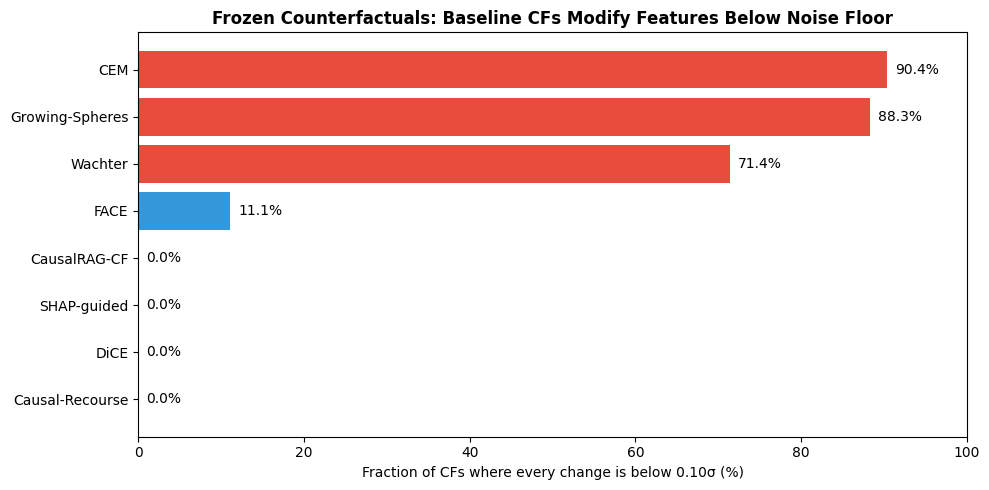

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

frozen = pd.read_csv('./results/paper_experiments/frozen_cf_rate.csv')
frozen = frozen.dropna(subset=['frozen_at_0.1']).sort_values('frozen_at_0.1')

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#2ecc71' if 'CausalRAG' in m else '#e74c3c' if frozen_at > 50
          else '#3498db' for m, frozen_at in zip(frozen['method'], frozen['frozen_at_0.1'])]
bars = ax.barh(frozen['method'], frozen['frozen_at_0.1'], color=colors)
ax.set_xlabel('Fraction of CFs where every change is below 0.10σ (%)')
ax.set_title('Frozen Counterfactuals: Baseline CFs Modify Features Below Noise Floor',
             fontweight='bold')
for b, v in zip(bars, frozen['frozen_at_0.1']):
    ax.text(v + 1, b.get_y() + b.get_height()/2, f'{v:.1f}%', va='center')
ax.set_xlim(0, 100)
plt.tight_layout()
plt.savefig('./figures/paper_experiments_frozen.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import pandas as pd

by_rater = pd.read_csv('./results/paper_experiments/per_method_by_rater.csv', index_col=0)
latex = by_rater.to_latex(
    caption='Per-method actionability scores by individual LLM rater. '
            'Every rater places CausalRAG-CF in the top 2 and '
            'Growing-Spheres at the bottom.',
    label='tab:by_rater',
    float_format='%.2f')
with open('./results/paper_experiments/per_method_by_rater.tex', 'w') as f:
    f.write(latex)
print(latex)

\begin{table}
\caption{Per-method actionability scores by individual LLM rater. Every rater places CausalRAG-CF in the top 2 and Growing-Spheres at the bottom.}
\label{tab:by_rater}
\begin{tabular}{lrrrrrr}
\toprule
 & deepseek & gemini & gpt & llama & rater_std & rater_mean \\
method &  &  &  &  &  &  \\
\midrule
CausalRAG-CF & 3.75 & 4.00 & 2.71 & 4.00 & 0.61 & 3.62 \\
Causal-Recourse & 3.00 & 4.00 & 3.00 & 4.00 & 0.58 & 3.50 \\
SHAP-guided & 3.00 & 3.17 & 2.60 & 3.33 & 0.31 & 3.02 \\
DiCE & 1.75 & 1.50 & 2.33 & 2.29 & 0.41 & 1.97 \\
FACE & 2.00 & 1.67 & 2.00 & 2.00 & 0.17 & 1.92 \\
Wachter & 1.50 & 1.00 & 1.00 & 1.40 & 0.26 & 1.23 \\
CEM & 1.14 & 1.00 & 1.00 & 1.00 & 0.07 & 1.04 \\
Growing-Spheres & 1.00 & 1.00 & 1.00 & 1.00 & 0.00 & 1.00 \\
\bottomrule
\end{tabular}
\end{table}



CELL PLOT-ALL: INDIVIDUAL FIGURES

[1] Frozen CF rate by method
  Saved ./figures/paper/fig1_frozen_at_010.png


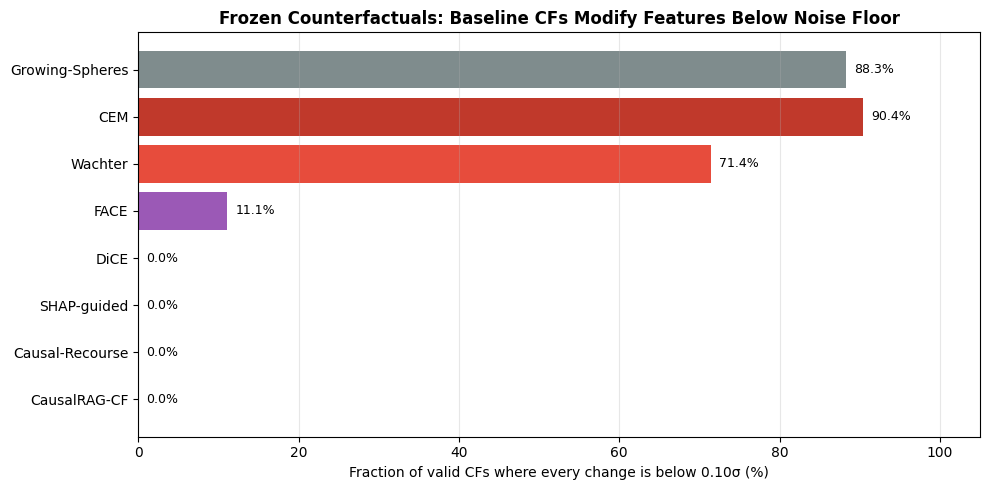


[2] Frozen CF rate at multiple thresholds
  Saved ./figures/paper/fig2_frozen_threshold_sweep.png


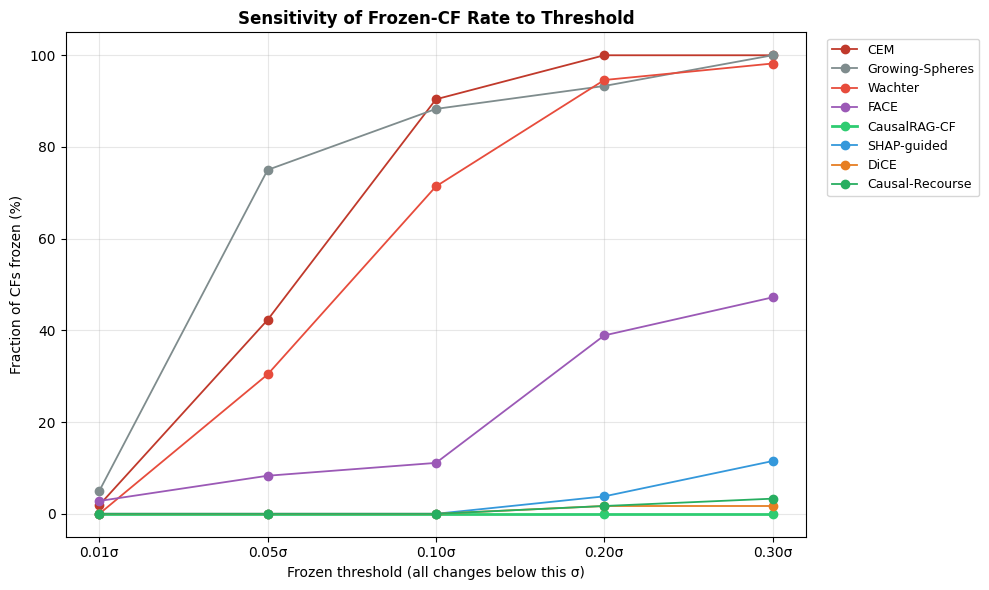


[3] Mean meaningful changes per CF
  Saved ./figures/paper/fig3_mean_meaningful_changes.png


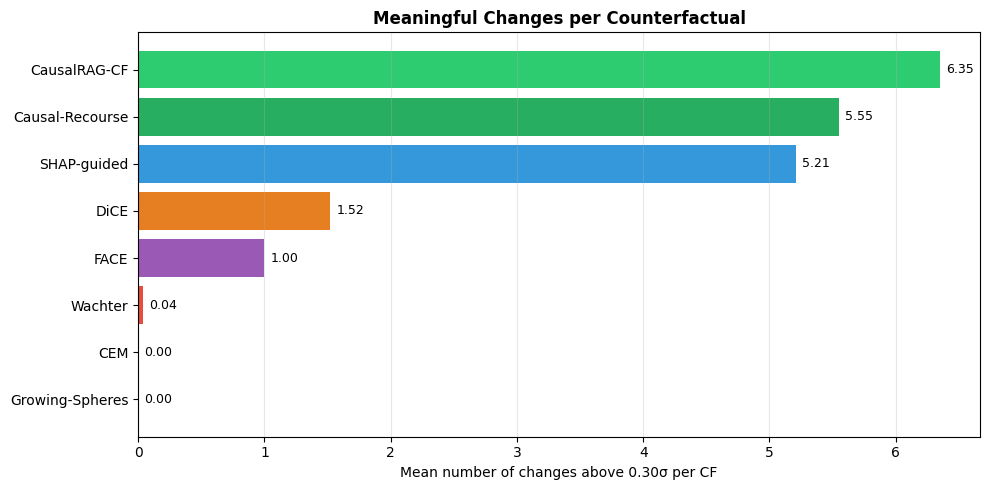


[4] Fraction of CFs with >=4 meaningful changes
  Saved ./figures/paper/fig4_ge4_meaningful.png


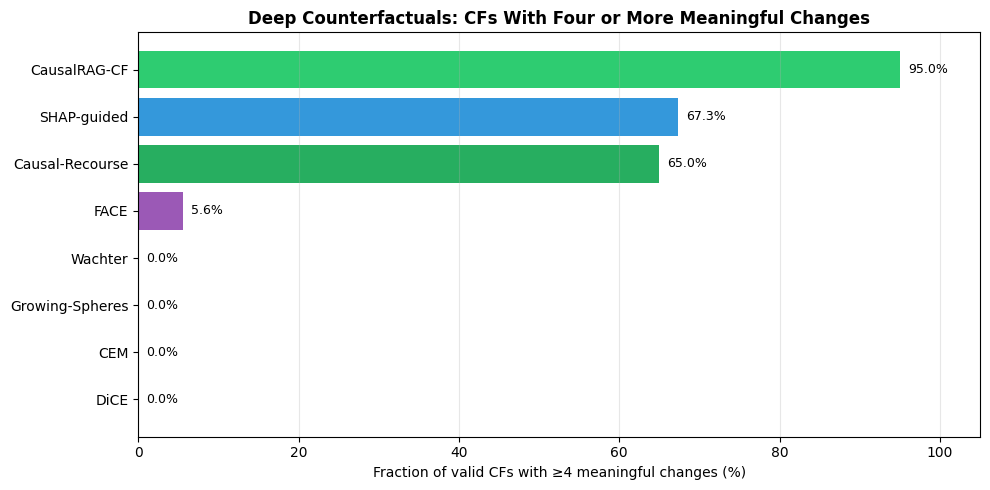


[5] Actionability by method
  Saved ./figures/paper/fig5_actionability.png


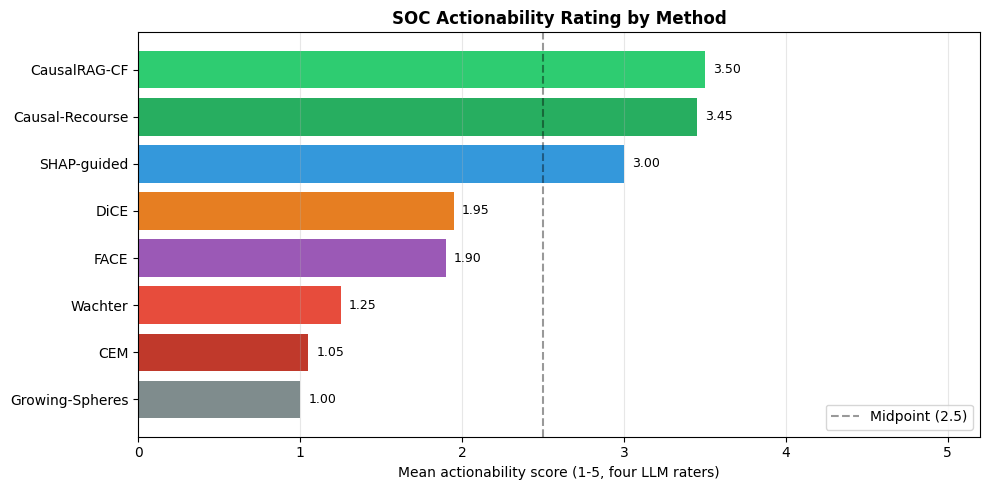


[6] Per-rater actionability
  Saved ./figures/paper/fig6_per_rater.png


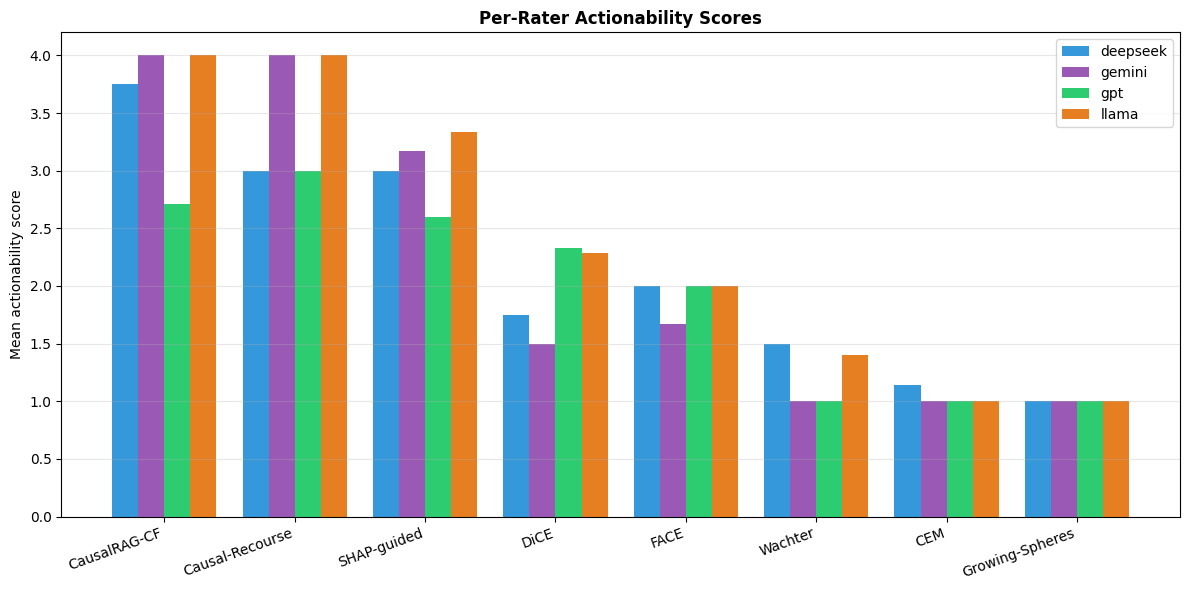


[7] Paired gap vs CausalRAG-CF
  Saved ./figures/paper/fig7_paired_gap.png


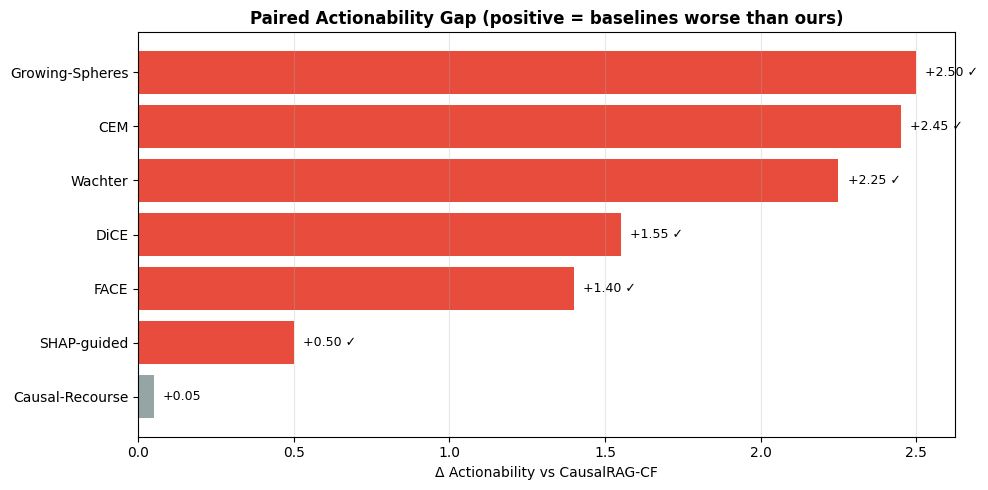


[8] Cohen's d per baseline
  Saved ./figures/paper/fig8_cohens_d.png


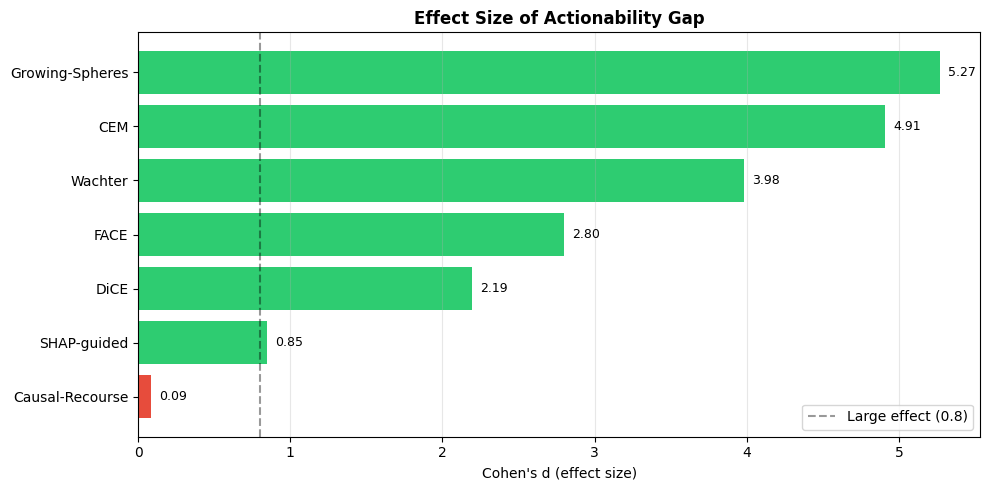


[9] Rank stability
  Saved ./figures/paper/fig9_rank_stability.png


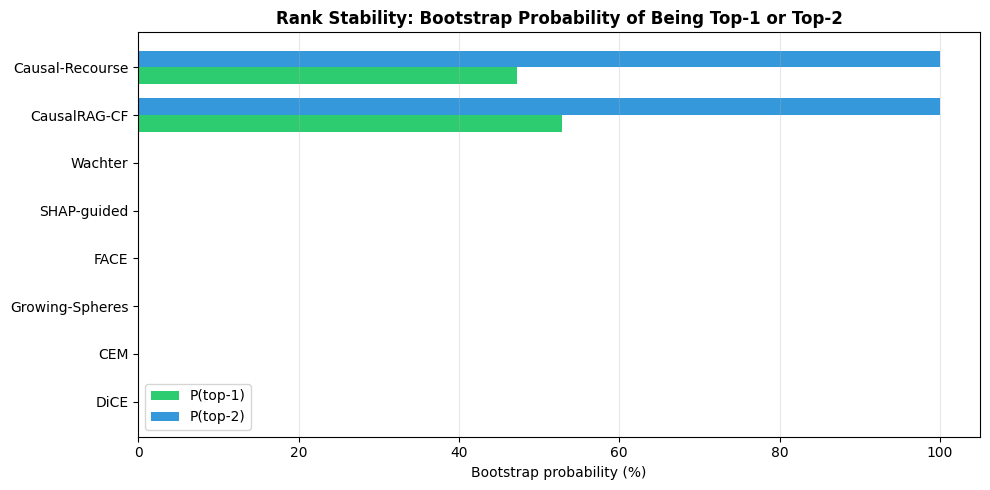


[10] Constraint violations
  Saved ./figures/paper/fig10_constraint_violations.png


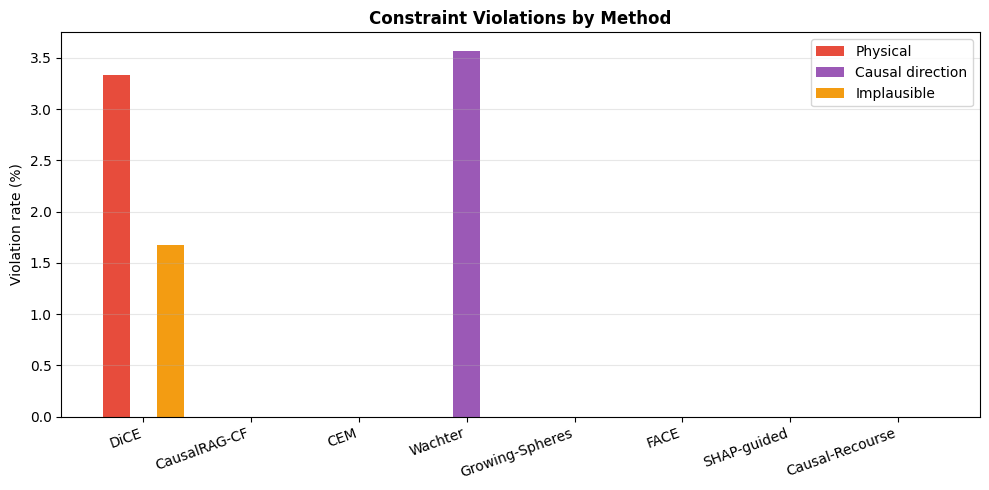


[11] Composite score v1 vs v2
  Saved ./figures/paper/fig11_composite_v1_v2.png


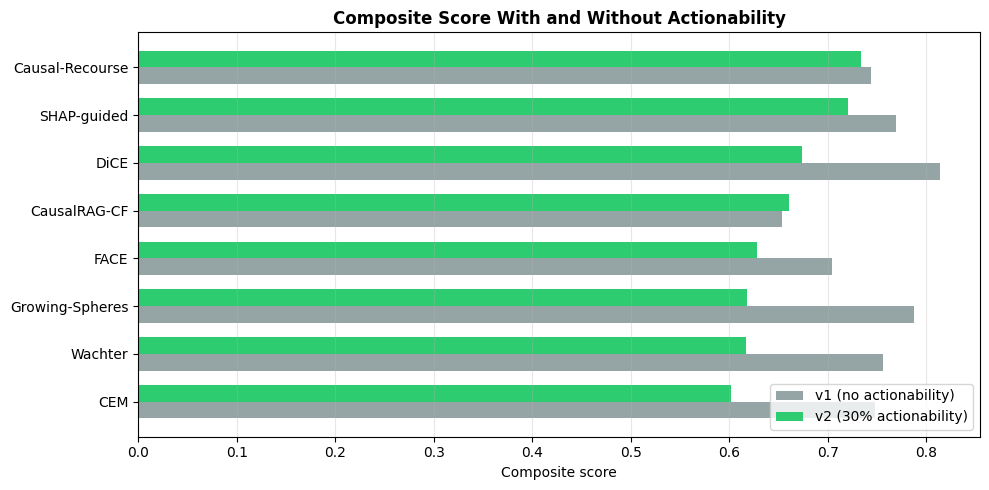


[12] Scatter: actionability vs frozen rate
  Saved ./figures/paper/fig12_scatter_action_vs_frozen.png


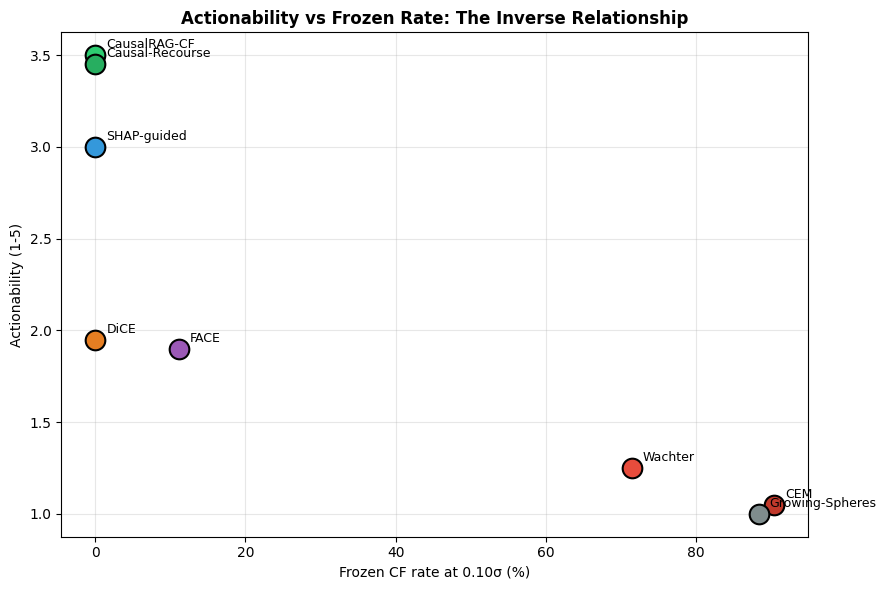


[13] Scatter: actionability vs mean meaningful changes
  Saved ./figures/paper/fig13_scatter_action_vs_meaningful.png


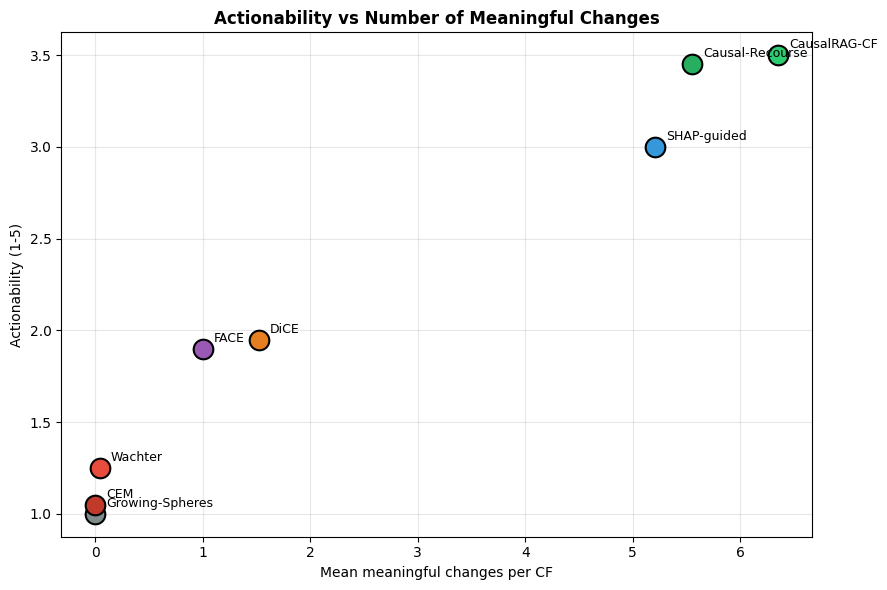


ALL FIGURES PRODUCED
  fig10_constraint_violations.png                       168.6 KB
  fig11_composite_v1_v2.png                             124.7 KB
  fig12_scatter_action_vs_frozen.png                    142.0 KB
  fig13_scatter_action_vs_meaningful.png                141.4 KB
  fig1_frozen_at_010.png                                147.5 KB
  fig2_frozen_threshold_sweep.png                       281.0 KB
  fig3_mean_meaningful_changes.png                      124.7 KB
  fig4_ge4_meaningful.png                               147.2 KB
  fig5_actionability.png                                130.2 KB
  fig6_per_rater.png                                    183.8 KB
  fig7_paired_gap.png                                   120.7 KB
  fig8_cohens_d.png                                     116.2 KB
  fig9_rank_stability.png                               117.8 KB

Total: 13 figures in ./figures/paper/


In [ ]:
# =============================================================================
# CELL PLOT-ALL: One figure per metric, all saved individually
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs('./figures/paper', exist_ok=True)
SEP = "=" * 100
print(SEP); print("CELL PLOT-ALL: INDIVIDUAL FIGURES"); print(SEP)

# -----------------------------------------------------------------------------
# Load all result files
# -----------------------------------------------------------------------------
paper_dir = './results/paper_experiments'
soc_dir = './results/soc'

frozen = pd.read_csv(f'{paper_dir}/frozen_cf_rate.csv')
meaningful = pd.read_csv(f'{paper_dir}/meaningful_change_audit.csv')
constraint = pd.read_csv(f'{paper_dir}/constraint_satisfaction.csv')
actionability = pd.read_csv(f'{soc_dir}/actionability_summary.csv')
paired = pd.read_csv(f'{soc_dir}/actionability_paired.csv')
rank_stability = pd.read_csv(f'{paper_dir}/rank_stability.csv')
composite = pd.read_csv(f'{paper_dir}/composite_with_actionability.csv')
by_rater = pd.read_csv(f'{paper_dir}/per_method_by_rater.csv', index_col=0)

METHODS_ORDER = ['CausalRAG-CF', 'Causal-Recourse', 'SHAP-guided', 'DiCE',
                 'FACE', 'Wachter', 'CEM', 'Growing-Spheres']

def _color(method):
    if 'CausalRAG' in method: return '#2ecc71'
    if 'Causal-Recourse' in method: return '#27ae60'
    if 'SHAP' in method: return '#3498db'
    if 'DiCE' in method: return '#e67e22'
    if 'FACE' in method: return '#9b59b6'
    if 'Wachter' in method: return '#e74c3c'
    if 'CEM' in method: return '#c0392b'
    if 'Growing' in method: return '#7f8c8d'
    return '#95a5a6'

def _save_and_show(fig, name):
    path = f'./figures/paper/{name}.png'
    fig.savefig(path, dpi=300, bbox_inches='tight')
    print(f"  Saved {path}")
    plt.show()
    plt.close(fig)

# -----------------------------------------------------------------------------
# Figure 1 — Frozen CF rate by method
# -----------------------------------------------------------------------------
print("\n[1] Frozen CF rate by method")
f = frozen.dropna(subset=['frozen_at_0.1']).copy()
f['method'] = pd.Categorical(f['method'], categories=METHODS_ORDER, ordered=True)
f = f.sort_values('method')

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(f['method'], f['frozen_at_0.1'],
                color=[_color(m) for m in f['method']])
ax.set_xlabel('Fraction of valid CFs where every change is below 0.10σ (%)')
ax.set_title('Frozen Counterfactuals: Baseline CFs Modify Features Below Noise Floor',
             fontweight='bold')
ax.set_xlim(0, 105)
for b, v in zip(bars, f['frozen_at_0.1']):
    ax.text(v + 1, b.get_y() + b.get_height()/2, f'{v:.1f}%',
            va='center', fontsize=9)
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
_save_and_show(fig, 'fig1_frozen_at_010')

# -----------------------------------------------------------------------------
# Figure 2 — Frozen at multiple thresholds
# -----------------------------------------------------------------------------
print("\n[2] Frozen CF rate at multiple thresholds")
thresholds = ['frozen_at_0.01', 'frozen_at_0.05', 'frozen_at_0.1',
              'frozen_at_0.2', 'frozen_at_0.3']
threshold_labels = ['0.01σ', '0.05σ', '0.10σ', '0.20σ', '0.30σ']
present = [t for t in thresholds if t in frozen.columns]

fig, ax = plt.subplots(figsize=(10, 6))
for _, row in frozen.iterrows():
    if pd.isna(row['frozen_at_0.1']): continue
    vals = [row[t] if t in frozen.columns else np.nan for t in present]
    ax.plot(threshold_labels, vals, 'o-',
            label=row['method'], color=_color(row['method']),
            linewidth=2 if 'CausalRAG' in row['method'] else 1.3)
ax.set_xlabel('Frozen threshold (all changes below this σ)')
ax.set_ylabel('Fraction of CFs frozen (%)')
ax.set_title('Sensitivity of Frozen-CF Rate to Threshold', fontweight='bold')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
_save_and_show(fig, 'fig2_frozen_threshold_sweep')

# -----------------------------------------------------------------------------
# Figure 3 — Mean meaningful changes per CF
# -----------------------------------------------------------------------------
print("\n[3] Mean meaningful changes per CF")
m = meaningful.dropna(subset=['mean_meaningful']).copy()
m['method'] = pd.Categorical(m['method'], categories=METHODS_ORDER, ordered=True)
m = m.sort_values('mean_meaningful', ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(m['method'], m['mean_meaningful'],
                color=[_color(mm) for mm in m['method']])
ax.set_xlabel('Mean number of changes above 0.30σ per CF')
ax.set_title('Meaningful Changes per Counterfactual', fontweight='bold')
for b, v in zip(bars, m['mean_meaningful']):
    ax.text(v + 0.05, b.get_y() + b.get_height()/2, f'{v:.2f}',
            va='center', fontsize=9)
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
_save_and_show(fig, 'fig3_mean_meaningful_changes')

# -----------------------------------------------------------------------------
# Figure 4 — Fraction of CFs with >= 4 meaningful changes
# -----------------------------------------------------------------------------
print("\n[4] Fraction of CFs with >=4 meaningful changes")
m4 = meaningful.dropna(subset=['frac_cf_with_ge4']).copy()
m4['method'] = pd.Categorical(m4['method'], categories=METHODS_ORDER, ordered=True)
m4 = m4.sort_values('frac_cf_with_ge4', ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(m4['method'], m4['frac_cf_with_ge4'],
                color=[_color(mm) for mm in m4['method']])
ax.set_xlabel('Fraction of valid CFs with ≥4 meaningful changes (%)')
ax.set_title('Deep Counterfactuals: CFs With Four or More Meaningful Changes',
             fontweight='bold')
ax.set_xlim(0, 105)
for b, v in zip(bars, m4['frac_cf_with_ge4']):
    ax.text(v + 1, b.get_y() + b.get_height()/2, f'{v:.1f}%',
            va='center', fontsize=9)
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
_save_and_show(fig, 'fig4_ge4_meaningful')

# -----------------------------------------------------------------------------
# Figure 5 — Actionability by method
# -----------------------------------------------------------------------------
print("\n[5] Actionability by method")
a = actionability.dropna(subset=['mean_score']).copy()
a['method'] = pd.Categorical(a['method'], categories=METHODS_ORDER, ordered=True)
a = a.sort_values('mean_score', ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(a['method'], a['mean_score'],
                color=[_color(mm) for mm in a['method']])
ax.set_xlabel('Mean actionability score (1-5, four LLM raters)')
ax.set_title('SOC Actionability Rating by Method', fontweight='bold')
ax.set_xlim(0, 5.2)
ax.axvline(2.5, color='black', linestyle='--', alpha=0.4,
            label='Midpoint (2.5)')
for b, v in zip(bars, a['mean_score']):
    ax.text(v + 0.05, b.get_y() + b.get_height()/2, f'{v:.2f}',
            va='center', fontsize=9)
ax.legend(loc='lower right')
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
_save_and_show(fig, 'fig5_actionability')

# -----------------------------------------------------------------------------
# Figure 6 — Per-rater actionability (grouped bars)
# -----------------------------------------------------------------------------
print("\n[6] Per-rater actionability")
br = by_rater.copy()
rater_cols = [c for c in br.columns if c in ['deepseek', 'gpt', 'llama', 'gemini']]
br = br.loc[[m for m in METHODS_ORDER if m in br.index]]

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(br))
width = 0.2
rater_colors = {'deepseek': '#3498db', 'gpt': '#2ecc71',
                'llama': '#e67e22', 'gemini': '#9b59b6'}
for i, rater in enumerate(rater_cols):
    ax.bar(x + i*width - 1.5*width, br[rater], width,
            label=rater, color=rater_colors.get(rater, None))
ax.set_xticks(x)
ax.set_xticklabels(br.index, rotation=20, ha='right')
ax.set_ylabel('Mean actionability score')
ax.set_title('Per-Rater Actionability Scores', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
_save_and_show(fig, 'fig6_per_rater')

# -----------------------------------------------------------------------------
# Figure 7 — Paired gap vs CausalRAG-CF
# -----------------------------------------------------------------------------
print("\n[7] Paired gap vs CausalRAG-CF")
p = paired.copy().sort_values('delta', ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#e74c3c' if sig == 'YES' else '#95a5a6'
          for sig in p['significant']]
bars = ax.barh(p['vs'], p['delta'], color=colors)
ax.axvline(0, color='black', linewidth=0.5)
ax.set_xlabel('Δ Actionability vs CausalRAG-CF')
ax.set_title('Paired Actionability Gap (positive = baselines worse than ours)',
             fontweight='bold')
for b, v, sig in zip(bars, p['delta'], p['significant']):
    label = f'{v:+.2f}' + (' ✓' if sig == 'YES' else '')
    x_pos = v + 0.03 if v >= 0 else v - 0.03
    ax.text(x_pos, b.get_y() + b.get_height()/2, label,
            va='center', ha='left' if v >= 0 else 'right', fontsize=9)
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
_save_and_show(fig, 'fig7_paired_gap')

# -----------------------------------------------------------------------------
# Figure 8 — Cohen's d per baseline
# -----------------------------------------------------------------------------
print("\n[8] Cohen's d per baseline")
p2 = paired.copy().sort_values('cohens_d', ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(p2['vs'], p2['cohens_d'],
                color=['#2ecc71' if d > 0.8 else '#f39c12' if d > 0.5
                        else '#e74c3c' for d in p2['cohens_d']])
ax.axvline(0.8, color='black', linestyle='--', alpha=0.4,
            label='Large effect (0.8)')
ax.set_xlabel("Cohen's d (effect size)")
ax.set_title("Effect Size of Actionability Gap", fontweight='bold')
for b, v in zip(bars, p2['cohens_d']):
    ax.text(v + 0.05, b.get_y() + b.get_height()/2, f'{v:.2f}',
            va='center', fontsize=9)
ax.legend()
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
_save_and_show(fig, 'fig8_cohens_d')

# -----------------------------------------------------------------------------
# Figure 9 — Rank stability (P top-1, P top-2)
# -----------------------------------------------------------------------------
print("\n[9] Rank stability")
rs = rank_stability.copy()
rs['method'] = pd.Categorical(rs['method'], categories=METHODS_ORDER, ordered=True)
rs = rs.sort_values('p_top2', ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(rs))
width = 0.35
ax.barh(x - width/2, rs['p_top1'], width, label='P(top-1)', color='#2ecc71')
ax.barh(x + width/2, rs['p_top2'], width, label='P(top-2)', color='#3498db')
ax.set_yticks(x)
ax.set_yticklabels(rs['method'])
ax.set_xlabel('Bootstrap probability (%)')
ax.set_title('Rank Stability: Bootstrap Probability of Being Top-1 or Top-2',
             fontweight='bold')
ax.set_xlim(0, 105)
ax.legend()
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
_save_and_show(fig, 'fig9_rank_stability')

# -----------------------------------------------------------------------------
# Figure 10 — Constraint violations
# -----------------------------------------------------------------------------
print("\n[10] Constraint violations")
c = constraint.dropna(subset=['phys_viol_pct']).copy()
c['method'] = pd.Categorical(c['method'], categories=METHODS_ORDER, ordered=True)
c = c.sort_values('phys_viol_pct', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(c))
width = 0.25
ax.bar(x - width, c['phys_viol_pct'], width,
        label='Physical', color='#e74c3c')
ax.bar(x, c['caus_viol_pct'], width,
        label='Causal direction', color='#9b59b6')
ax.bar(x + width, c['implausible_pct'], width,
        label='Implausible', color='#f39c12')
ax.set_xticks(x)
ax.set_xticklabels(c['method'], rotation=20, ha='right')
ax.set_ylabel('Violation rate (%)')
ax.set_title('Constraint Violations by Method', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
_save_and_show(fig, 'fig10_constraint_violations')

# -----------------------------------------------------------------------------
# Figure 11 — Composite score v1 vs v2
# -----------------------------------------------------------------------------
print("\n[11] Composite score v1 vs v2")
cp = composite.copy()
cp['method'] = pd.Categorical(cp['method'], categories=METHODS_ORDER, ordered=True)
cp = cp.sort_values('composite_v2', ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(cp))
width = 0.35
ax.barh(x - width/2, cp['composite_v1'], width,
        label='v1 (no actionability)', color='#95a5a6')
ax.barh(x + width/2, cp['composite_v2'], width,
        label='v2 (30% actionability)', color='#2ecc71')
ax.set_yticks(x)
ax.set_yticklabels(cp['method'])
ax.set_xlabel('Composite score')
ax.set_title('Composite Score With and Without Actionability',
             fontweight='bold')
ax.legend()
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
_save_and_show(fig, 'fig11_composite_v1_v2')

# -----------------------------------------------------------------------------
# Figure 12 — Scatter: actionability vs frozen rate
# -----------------------------------------------------------------------------
print("\n[12] Scatter: actionability vs frozen rate")
fr = frozen.dropna(subset=['frozen_at_0.1']).copy()
ac = actionability.dropna(subset=['mean_score']).copy()
sc = fr[['method', 'frozen_at_0.1']].merge(
    ac[['method', 'mean_score']], on='method', how='inner')

fig, ax = plt.subplots(figsize=(9, 6))
for _, r in sc.iterrows():
    ax.scatter(r['frozen_at_0.1'], r['mean_score'],
                s=200, color=_color(r['method']), edgecolor='black',
                linewidth=1.5, zorder=3)
    ax.annotate(r['method'], (r['frozen_at_0.1'], r['mean_score']),
                xytext=(8, 5), textcoords='offset points', fontsize=9)
ax.set_xlabel('Frozen CF rate at 0.10σ (%)')
ax.set_ylabel('Actionability (1-5)')
ax.set_title('Actionability vs Frozen Rate: The Inverse Relationship',
             fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout()
_save_and_show(fig, 'fig12_scatter_action_vs_frozen')

# -----------------------------------------------------------------------------
# Figure 13 — Scatter: actionability vs mean meaningful changes
# -----------------------------------------------------------------------------
print("\n[13] Scatter: actionability vs mean meaningful changes")
mn = meaningful.dropna(subset=['mean_meaningful']).copy()
sc2 = mn[['method', 'mean_meaningful']].merge(
    ac[['method', 'mean_score']], on='method', how='inner')

fig, ax = plt.subplots(figsize=(9, 6))
for _, r in sc2.iterrows():
    ax.scatter(r['mean_meaningful'], r['mean_score'],
                s=200, color=_color(r['method']), edgecolor='black',
                linewidth=1.5, zorder=3)
    ax.annotate(r['method'], (r['mean_meaningful'], r['mean_score']),
                xytext=(8, 5), textcoords='offset points', fontsize=9)
ax.set_xlabel('Mean meaningful changes per CF')
ax.set_ylabel('Actionability (1-5)')
ax.set_title('Actionability vs Number of Meaningful Changes',
             fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout()
_save_and_show(fig, 'fig13_scatter_action_vs_meaningful')

# -----------------------------------------------------------------------------
# Summary
# -----------------------------------------------------------------------------
print("\n" + SEP)
print("ALL FIGURES PRODUCED")
print(SEP)

files = sorted(os.listdir('./figures/paper'))
for f in files:
    p = f'./figures/paper/{f}'
    kb = os.path.getsize(p) / 1024
    print(f"  {f:<50} {kb:>8.1f} KB")
print(f"\nTotal: {len(files)} figures in ./figures/paper/")